# Midterm figures: data, architecture, results

DSC 291, crop-yield project ("Same light, more insight?"). This notebook makes a large set of figures for the midterm report, so that the team can pick a few for each part:

1. **Part 1, data and visualisation** (figures `D01` to `D14`): maps, image chips, coverage, labels, the split.
2. **Part 2, architecture** (figures `A01` to `A08`): the inputs, each model arm, Presto, the controls, the evaluation.
3. **Part 3, results and outcomes** (figures `R01` to `R13` and `R20`): the ladder, the Presto controls, village against field, tables, maps.

The last section shows all figures of a part on one overview sheet.

**Output.** Each figure is written to `report/figures/midterm/` as PNG (300 dpi) and PDF, at the final print size (7.2 in = the text width, or 3.5 in = one column). The text cell above each figure says what it shows, how to read it, the take-away, the source and a caption draft.

**Run it.** Open it from the `notebooks/` folder with the project `.venv` kernel and run all cells in order (about 5 minutes). It opens the database read-only and writes only the figure files. It uses only the packages of `requirements.txt`. It needs:

- `data/v2/cropyield.duckdb` (the team database, data v2);
- the data v2 image chips in `data/imagery/sentinel2_v2/` for the six figures that show chips (D01, D07, D08, D13, A01, R20);
- the public map files of section 0.3 for outlines and relief (without them the maps are plain and D06 is not drawn).

The saved outputs show every figure, so the notebook can be read without a run.

**Rules that every figure follows.** Scores are for folds 1-4 of `s1_cc2km` (1,504 Lacuna fields); fold 0 never trains and is shown only as the one logged look. Each data set stands alone: t/ha is never compared between data sets. Arms X1, X2 and P3 are post hoc and are marked with a dagger (†). The result numbers come from the data layer or from committed result files, and many cells check them with `assert`. All models see the full season, so they estimate yield at the end of the season; they are not forecasts.

**One visual system.** In the model figures a colour has one meaning: blue = the village (skill between 2 km groups, the address), green = the field (skill inside a group), orange = the foundation model (Presto), grey = everything else. Yield uses one pale-to-deep-green scale; signed values use blue to red with a neutral middle. In the data figures the same three hues name the three countries.

## 0. Setup

### 0.1 Style: one visual system

Paths, fonts, sizes, colours and small drawing helpers. `save(fig, name)` writes the PNG and the PDF and shows the figure.

In [1]:
from __future__ import annotations

import importlib.util
import json
import math
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import shapefile  # pyshp
import shapely
from matplotlib import patheffects as pe
from matplotlib.collections import LineCollection
from matplotlib.colors import (
    LightSource,
    LinearSegmentedColormap,
    ListedColormap,
    Normalize,
    to_rgb,
)
from matplotlib.patches import (
    Circle,
    ConnectionPatch,
    FancyBboxPatch,
    PathPatch,
    Rectangle,
)
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath
from shapely.geometry import Point, box, shape
from shapely.ops import unary_union

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(REPO / "src"))
V1, V2 = REPO / "data", REPO / "data" / "v2"
BASEMAP = REPO / "data" / "imagery" / "basemap"   # public map files, git-ignored (section 0.3)
FIG = REPO / "report" / "figures" / "midterm"     # every figure is written here as PNG (300 dpi) and PDF
FIG.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)

# ---- one visual system for every figure ------------------------------------------------------------------------------
FULL, COL = 7.2, 3.5                 # figure widths in inches: the text width and one column of the report
INK, INK2, MUTED = "#1b1b1a", "#52514e", "#898781"          # text: primary, secondary, muted
GRID, AXIS, PAPER = "#e6e5df", "#bdbcb3", "#ffffff"         # hairlines and the page
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"        # the three hues that stay apart for every reader
NEUTRAL, NEUTRAL_LIGHT = "#55544f", "#c9c8c0"               # baselines, context, "not the story"
# In the model figures a colour has one meaning: the village (skill between 2 km groups), the field (skill inside a
# group), and the foundation model. In the data figures the same three hues name the three countries.
VILLAGE, FIELD, PRESTO = BLUE, AQUA, ORANGE

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 7.5, "axes.titlesize": 8.2, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 5, "axes.labelsize": 7.5, "axes.labelcolor": INK2, "axes.labelpad": 3,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.pad": 2.5, "ytick.major.pad": 2.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": PAPER, "figure.facecolor": PAPER, "savefig.facecolor": PAPER, "text.color": INK,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 7, "legend.handlelength": 1.4, "legend.handletextpad": 0.5,
    "legend.borderaxespad": 0.2, "legend.labelspacing": 0.35, "legend.columnspacing": 1.2,
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "mathtext.default": "regular", "hatch.linewidth": 0.5, "image.interpolation": "nearest",
})


def oklch(L, C, h):
    """OKLCH (lightness 0-1, chroma, hue in degrees) -> sRGB hex. Chroma is reduced until the colour is in gamut."""
    for scale in np.linspace(1, 0, 41):
        a, b = C * scale * math.cos(math.radians(h)), C * scale * math.sin(math.radians(h))
        l, m, s = (L + 0.3963377774 * a + 0.2158037573 * b) ** 3, (L - 0.1055613458 * a - 0.0638541728 * b) ** 3, \
                  (L - 0.0894841775 * a - 1.2914855480 * b) ** 3
        rgb = np.array([4.0767416621 * l - 3.3077115913 * m + 0.2309699292 * s,
                        -1.2684380046 * l + 2.6097574011 * m - 0.3413193965 * s,
                        -0.0041960863 * l - 0.7034186147 * m + 1.7076147010 * s])
        if rgb.min() >= -1e-4 and rgb.max() <= 1 + 1e-4:
            break
    rgb = np.clip(rgb, 0, 1)
    rgb = np.where(rgb <= 0.0031308, 12.92 * rgb, 1.055 * rgb ** (1 / 2.4) - 0.055)
    return mpl.colors.to_hex(np.clip(rgb, 0, 1))


def ramp(name, stops, n=256):
    """A colour ramp through OKLCH stops (position, L, C, h), so that lightness changes evenly."""
    pos, L, C, h = (np.array(v, dtype=float) for v in zip(*stops))
    t = np.linspace(0, 1, n)
    return ListedColormap([oklch(np.interp(x, pos, L), np.interp(x, pos, C), np.interp(x, pos, h)) for x in t], name=name)


# Sequential: yield (pale straw -> deep green, one family of neighbouring hues) and counts (one blue).
YIELD = ramp("yield", [(0, .955, .075, 104), (.25, .865, .135, 118), (.5, .715, .160, 136), (.75, .530, .130, 150), (1, .300, .075, 160)])
YIELD_DARK = ramp("yield_dark", [(0, .300, .060, 200), (.3, .470, .105, 165), (.6, .680, .150, 140), (.85, .860, .160, 118), (1, .955, .135, 104)])
COUNT = LinearSegmentedColormap.from_list("count", ["#eef4fc", "#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"])
# Diverging: blue <-> red with a neutral grey middle (the middle must read as "nothing"). Each arm keeps its own hue
# down to the middle; only the chroma goes to zero there, so the pale steps stay pale blue and pale red.
DIVERGE = ramp("diverge", [(0, .36, .125, 258), (.25, .60, .135, 255), (.497, .945, .012, 255), (.5, .950, .0, 255),
                           (.503, .945, .012, 28), (.75, .66, .150, 28), (1, .40, .145, 26)])
for cmap in (YIELD, YIELD_DARK, COUNT, DIVERGE):
    cmap.set_bad("#00000000")


def tint(color, amount):
    """Mix a colour with white: amount 0 = the colour, 1 = white."""
    return mpl.colors.to_hex((1 - amount) * np.array(to_rgb(color)) + amount * np.ones(3))


def shade(color, amount):
    """Mix a colour with black: amount 0 = the colour, 1 = black."""
    return mpl.colors.to_hex((1 - amount) * np.array(to_rgb(color)))


def save(fig, name, pdf=True):
    """Write report/figures/midterm/<name>.png (300 dpi) and .pdf, then show the figure."""
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
    if pdf:
        fig.savefig(FIG / f"{name}.pdf", dpi=300, bbox_inches="tight", pad_inches=0.03)
    plt.show()


def panel(ax, letter, x=0.0, y=1.0, dx=0, dy=5, **kw):
    """Bold panel letter "(a)" at the top-left corner of an axes, offset in points."""
    style = {"fontsize": 9, "fontweight": "bold", "color": INK, "ha": "left", "va": "bottom"}
    return ax.annotate(f"({letter})", xy=(x, y), xycoords="axes fraction", xytext=(dx, dy), textcoords="offset points",
                       **(style | kw))


def hgrid(ax, axis="y"):
    """Solid hairline grid behind the marks, on one axis."""
    ax.grid(True, axis=axis, color=GRID, linewidth=0.5)
    ax.set_axisbelow(True)


def halo(width=1.6, color=PAPER):
    return [pe.withStroke(linewidth=width, foreground=color)]


def rounded_bar(ax, x0, x1, y, height, color, horizontal=True, radius_pt=1.8, **kw):
    """One bar with a square end at the baseline (x0) and a rounded data end (x1). Coordinates are data units."""
    fig = ax.figure
    fig.canvas.draw_idle()
    inv = ax.transData.inverted()
    r_disp = radius_pt * fig.dpi / 72
    if horizontal:
        rx = abs(inv.transform((r_disp, 0))[0] - inv.transform((0, 0))[0])
        ry = abs(inv.transform((0, r_disp))[1] - inv.transform((0, 0))[1])
        sign = 1 if x1 >= x0 else -1
        rx, ry = min(rx, abs(x1 - x0)), min(ry, height / 2)
        lo, hi = y - height / 2, y + height / 2
        verts = [(x0, lo), (x1 - sign * rx, lo), (x1, lo), (x1, lo + ry), (x1, hi - ry), (x1, hi), (x1 - sign * rx, hi), (x0, hi), (x0, lo)]
    else:
        rx = abs(inv.transform((r_disp, 0))[0] - inv.transform((0, 0))[0])
        ry = abs(inv.transform((0, r_disp))[1] - inv.transform((0, 0))[1])
        sign = 1 if x1 >= x0 else -1
        rx, ry = min(rx, height / 2), min(ry, abs(x1 - x0))
        lo, hi = y - height / 2, y + height / 2
        verts = [(lo, x0), (lo, x1 - sign * ry), (lo, x1), (lo + rx, x1), (hi - rx, x1), (hi, x1), (hi, x1 - sign * ry), (hi, x0), (lo, x0)]
    codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.CURVE3, MplPath.CURVE3, MplPath.LINETO, MplPath.CURVE3, MplPath.CURVE3,
             MplPath.LINETO, MplPath.CLOSEPOLY]
    patch = PathPatch(MplPath(verts, codes), facecolor=color, edgecolor="none", **kw)
    ax.add_patch(patch)
    return patch


def colorbar(fig, mappable, cax=None, ax=None, label=None, ticks=None, orientation="vertical", **kw):
    """A thin colour bar without an outline."""
    bar = fig.colorbar(mappable, cax=cax, ax=ax, orientation=orientation, ticks=ticks, **kw)
    bar.outline.set_visible(False)
    bar.ax.tick_params(length=2, width=0.5, color=AXIS, labelsize=6.5, labelcolor=INK2)
    if label:
        bar.set_label(label, fontsize=7, color=INK2)
    return bar


print("repository:", REPO)
print("font in use:", mpl.font_manager.FontProperties(family=mpl.rcParams["font.sans-serif"]).get_name(),
      "| matplotlib", mpl.__version__)

repository: C:\Dev\DSC-291-Final-Project
font in use: Arial | matplotlib 3.11.1


### 0.2 Data layer

This cell loads the labels, the folds and the monthly series of every data set with the project's own functions (`experiments/time_features`, `scripts/baselines/baseline_table.py`). It then makes one out-of-fold prediction for each field of folds 1-4 for the arms R0, R1, A1 and M2, and reads the Presto arms from the saved runs. Two checks stop the notebook if a number differs from the committed results: A1 against the saved Presto run, and the R² of M2 against `experiments/stepup/results.csv`.

`D[cohort]` holds the inputs, `P[cohort]` the predictions, and `ladder`, `presto`, `importance` and `gcvi_months` the committed result tables.

In [2]:
def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


tf = load_module("time_features", REPO / "experiments" / "time_features" / "time_features.py")   # also loads step 8
step8 = tf.step8
from cropyield.eval.scores import (
    bias,
    centred,
    group_draws,
    in_large_clusters,
    mae,
    r2,
    rank_inside_clusters,
    rmse,
    spearman,
)

LACUNA, KENYA, MALAWI22, MALAWI23, ZIM24 = ("zimbabwe_lacuna_2022_2023", "kenya_oaf_2019_2020", "malawi_2022",
                                            "malawi_2023", "zimbabwe_2024")
COHORTS = {  # the label, the short label, the country and the colour of each data set
    LACUNA: {"name": "Zimbabwe Lacuna 2023", "short": "Zimbabwe\nLacuna 2023", "iso": "ZWE", "color": BLUE, "role": "main data set"},
    KENYA: {"name": "Kenya 2019 and 2020", "short": "Kenya\n2019-2020", "iso": "KEN", "color": ORANGE, "role": "season pair"},
    MALAWI22: {"name": "Malawi 2022", "short": "Malawi\n2022", "iso": "MWI", "color": AQUA, "role": "season pair"},
    MALAWI23: {"name": "Malawi 2023", "short": "Malawi\n2023", "iso": "MWI", "color": shade(AQUA, 0.35), "role": "season pair"},
    ZIM24: {"name": "Zimbabwe 2024", "short": "Zimbabwe\n2024", "iso": "ZWE", "color": NEUTRAL, "role": "auxiliary"},
}
BANDS = tf.BANDS                                         # b02 ... b12, in wavelength order
BAND_NM = {"b02": 490, "b03": 560, "b04": 665, "b05": 705, "b06": 740, "b07": 783, "b08": 842, "b8a": 865, "b11": 1610, "b12": 2190}
BAND_WIDTH_NM = {"b02": 65, "b03": 35, "b04": 30, "b05": 15, "b06": 15, "b07": 20, "b08": 115, "b8a": 20, "b11": 90, "b12": 180}
BAND_NAME = {"b02": "B2 blue", "b03": "B3 green", "b04": "B4 red", "b05": "B5 red edge", "b06": "B6 red edge", "b07": "B7 red edge",
                 "b08": "B8 NIR", "b8a": "B8A NIR", "b11": "B11 SWIR", "b12": "B12 SWIR"}
MONTH_NAME = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct",
              11: "Nov", 12: "Dec"}

ARMS = {  # code: (short name, what the model reads, number of inputs)
    "R0": ("Training mean", "nothing", 0),
    "R1": ("Coordinates only", "latitude and longitude: mean of the 10 nearest training fields", 2),
    "A1": ("Season indices", "max and mean of 5 vegetation indices over the season", 10),
    "M2": ("Monthly bands", "10 bands x 7 months, gaps filled inside the field's own series", 70),
    "X1": ("Raw Presto inputs", "10 bands + NDVI x 9 months, as Presto reads them", 99),
    "P0": ("Presto, frozen", "128-value embedding of the pretrained encoder + Ridge", 128),
    "P1": ("Presto, fine-tuned", "pretrained encoder + linear head, trained end to end", 128),
    "P2": ("Presto, random start", "the same network trained from random weights", 128),
    "X2": ("Presto, random frozen", "128-value embedding of a random encoder + Ridge", 128),
}
EXAMPLE = "zimbabwe:02455e59-78e3-4315-9c16-c2b635e2582d"   # one Lacuna field that every explanatory figure uses

labels = pd.read_parquet(V2 / "processed" / "labels_v2.parquet").set_index("obs_id")
con = duckdb.connect(str(V2 / "cropyield.duckdb"), read_only=True)

# Model rows of every data set: the 10 season indices (X_a1), yield in t/ha (y), fold and 2 km group of each field,
# and every clear field-month with its month of the season (k = 0 is the first month of the window).
def model_rows(cohort, expected, pre_months):
    X_a1, y, fields, monthly = tf.load(cohort, expected, labels)
    variants, _ = tf.build(cohort, X_a1, y, monthly, pre_months)
    start_month = 10 if pre_months is tf.SOUTH else 2
    return {"X_a1": X_a1, "y": y, "fields": fields, "monthly": monthly, "variants": variants, "cube": tf.cubes(monthly, y.index),
                "start_month": start_month, "dev": (fields["fold"] != "0").to_numpy(),
                "calendar": {k: (start_month - 1 + k) % 12 + 1 for k in sorted(monthly.k.unique())}}


D = {cohort: model_rows(cohort, expected, pre_months) for cohort, (expected, pre_months, _) in tf.COHORTS.items()}

# Coverage state of every field-month (clear, cloudy, no_scene) and the accepted scenes with their dates.
coverage = con.sql("SELECT obs_id, cohort, month, coverage_state FROM monthly").df()
scenes = con.sql("SELECT obs_id, month, acquired, tile, tile_cloud_cover FROM scenes").df()
downloads = con.sql("SELECT obs_id, record_dir, aoi_type, field_pixels, crs FROM downloads").df().set_index("obs_id")

# Committed result tables (the numbers that the report quotes).
ladder = pd.read_csv(REPO / "experiments" / "stepup" / "results.csv")
importance = pd.read_csv(REPO / "experiments" / "stepup" / "importance.csv")
gcvi_months = pd.read_csv(REPO / "experiments" / "stepup" / "gcvi_months.csv")
PRESTO_RUNS = REPO / "experiments" / "presto_finetune" / "runs"
presto = {c: pd.concat([pd.read_csv(PRESTO_RUNS / c / "scores.csv"), pd.read_csv(PRESTO_RUNS / c / "posthoc_controls.csv")],
                       ignore_index=True) for c in (LACUNA, MALAWI22, MALAWI23)}

# Out-of-fold predictions per field, folds 1-4 (fold 0 never trains): R0, R1, A1 and M2 are fitted here with the
# project's own functions; the Presto arms are read from the saved runs. Each one is checked against the committed score.
def out_of_fold_table(cohort):
    d = D[cohort]
    base = step8.out_of_fold(d["X_a1"], d["y"], d["fields"], ("0",))
    m2 = step8.out_of_fold(d["variants"]["M2 monthly band curve"], d["y"], d["fields"], ("0",))["A1"]
    table = d["fields"].assign(y=d["y"], R0=base["R0"], R1=base["R1"], A1=base["A1"], M2=m2)
    saved = PRESTO_RUNS / cohort / "predictions.csv"
    if saved.exists():
        run = pd.read_csv(saved).set_index("obs_id")
        assert np.allclose(run["A1"], table.loc[run.index, "A1"]), "A1 here differs from the saved Presto run"
        table = table.join(run[["P0", "P0_noloc", "P1", "P1_noloc", "P2"]])
    table = table[d["dev"]].copy()
    committed = ladder[(ladder.cohort == cohort) & ladder.step.str.startswith("S7") & (ladder["head"] == "Ridge")].iloc[0]
    assert abs(r2(table.y.to_numpy(), table.M2.to_numpy()) - committed.r2) < 1e-6, "M2 differs from experiments/stepup"
    return table


P = {cohort: out_of_fold_table(cohort) for cohort in D}


def cluster_year(table):
    return (table["group_id"] + "|" + table["season_year"].astype(str)).to_numpy()


def score(table, arm):
    y, p, cy = table["y"].to_numpy(), table[arm].to_numpy(), cluster_year(table)
    means = pd.DataFrame({"y": y, "p": p}).groupby(cy).transform("mean")
    return {"rmse": rmse(y, p), "mae": mae(y, p), "bias": bias(y, p), "r2": r2(y, p),
                "r2_between": 1 - ((means.y - means.p) ** 2).sum() / ((means.y - y.mean()) ** 2).sum(),
                "r2_within": 1 - (((y - means.y) - (p - means.p)) ** 2).sum() / ((y - means.y) ** 2).sum(),
                "rank": rank_inside_clusters(y, p, cy, step8.MIN_CLUSTER_FIELDS)}


overview = pd.DataFrame({c: {"fields": len(d["y"]), "scored": int(d["dev"].sum()),
                                 "groups": d["fields"]["group_id"].nunique(), "median_t_ha": round(d["y"].median(), 2),
                                 "months": " ".join(MONTH_NAME[m] for m in d["calendar"].values()),
                                 "r2_A1": round(score(P[c], "A1")["r2"], 3), "r2_M2": round(score(P[c], "M2")["r2"], 3)}
                         for c, d in D.items()}).T
overview

,fields,scored,groups,median_t_ha,months,r2_A1,r2_M2
zimbabwe_lacuna_2022_2023,1880,1504,289,3.02,Dec Jan Feb Mar Apr May Jun,0.185,0.299
malawi_2023,253,204,53,2.46,Dec Jan Feb Mar Apr May Jun,0.147,0.047
malawi_2022,529,423,97,2.42,Oct Nov Dec Jan Feb Mar Apr May Jun,0.368,0.477
kenya_oaf_2019_2020,3977,3181,849,2.89,Feb Mar Apr May Jun Jul Aug Sep,0.05,0.116
zimbabwe_2024,2458,1966,996,0.53,Oct Nov Dec Jan Feb Mar Apr May Jun,0.205,0.205


### 0.3 Map files (public, not in Git)

The maps need country, province and district outlines and a relief. These files are public but are not part of the repository; they live in `data/imagery/basemap/` (git-ignored, about 45 MB). To get them, run once from the repository root:

```bash
python notebooks/midterm_get_basemap.py ne gb dem
```

| Layer | Source | Licence |
|---|---|---|
| Countries, provinces, lakes, rivers, towns | Natural Earth 1:10m (naciscdn.org) | public domain |
| Districts of Zimbabwe, Malawi and Kenya | geoBoundaries gbOpen ADM2, from OCHA ROSEA with the national statistics offices | CC BY 3.0 IGO |
| Relief | Copernicus DEM GLO-90, overview level (AWS open data) | free with attribution: © DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018, provided under COPERNICUS by the European Union and ESA |

Name these sources in the report if a map is used. Without the files the notebook still runs: the maps are then drawn without outlines and relief.

In [3]:
HAVE_BASEMAP = (BASEMAP / "naturalearth" / "ne_10m_admin_0_countries").exists()


def read_shp(name):
    """One Natural Earth layer as a list of (shapely geometry, attributes)."""
    reader = shapefile.Reader(str(next((BASEMAP / "naturalearth" / name).glob("*.shp"))), encoding="utf-8",
                              encodingErrors="replace")
    names = [f[0] for f in reader.fields[1:]]
    return [(shape(sr.shape.__geo_interface__), dict(zip(names, sr.record))) for sr in reader.iterShapeRecords()
            if sr.shape.shapeType != 0]


def read_geojson(path):
    features = json.loads(Path(path).read_text(encoding="utf-8"))["features"]
    return [(shape(f["geometry"]), f["properties"]) for f in features]


def geom_path(geom):
    """A matplotlib path of a polygon or multipolygon, holes included."""
    polygons = [geom] if geom.geom_type == "Polygon" else [g for g in geom.geoms if g.geom_type == "Polygon"]
    verts, codes = [], []
    for polygon in polygons:
        for ring in [polygon.exterior, *polygon.interiors]:
            xy = np.asarray(ring.coords)[:, :2]
            verts.append(xy)
            codes.append(np.r_[MplPath.MOVETO, np.full(len(xy) - 2, MplPath.LINETO), MplPath.CLOSEPOLY])
    return MplPath(np.vstack(verts), np.concatenate(codes))


def outlines(geoms):
    """Line segments of the outlines of polygons (or of lines), for one LineCollection."""
    segments = []
    for geom in geoms:
        line = geom.boundary if "Polygon" in geom.geom_type else geom
        parts = [line] if line.geom_type in ("LineString", "LinearRing") else list(line.geoms)
        segments += [np.asarray(part.coords)[:, :2] for part in parts]
    return segments


if HAVE_BASEMAP:
    NE_COUNTRIES = read_shp("ne_10m_admin_0_countries")
    NE_ADMIN1 = read_shp("ne_10m_admin_1_states_provinces")
    NE_LAKES = read_shp("ne_10m_lakes")
    NE_RIVERS = read_shp("ne_10m_rivers_lake_centerlines")
    NE_PLACES = read_shp("ne_10m_populated_places_simple")
    COUNTRY = {a["ADM0_A3"]: g for g, a in NE_COUNTRIES}
    AFRICA = [g for g, a in NE_COUNTRIES if a["CONTINENT"] == "Africa"]
    ADMIN1 = {iso: [(g, a["name"]) for g, a in NE_ADMIN1 if a["adm0_a3"] == iso] for iso in ("ZWE", "MWI", "KEN")}
    ADMIN2 = {iso: [(g, a["shapeName"]) for g, a in read_geojson(BASEMAP / "geoboundaries" / f"{iso}_ADM2_simplified.geojson")]
              for iso in ("ZWE", "MWI", "KEN")}


    def dissolve(iso):
        """Provinces as unions of the districts inside them, so that province and district lines never disagree."""
        parts = {}
        for district, _ in ADMIN2[iso]:
            point = district.representative_point()
            parent = min(ADMIN1[iso], key=lambda item: 0 if item[0].contains(point) else item[0].distance(point))[1]
            parts.setdefault(parent, []).append(district.buffer(2e-4))
        return [(unary_union(geoms).buffer(-2e-4), name) for name, geoms in parts.items()]


    # The coarse and the fine administrative level drawn in each country (Malawi: its 28 districts only).
    PROVINCES = {"ZWE": dissolve("ZWE"), "KEN": dissolve("KEN"), "MWI": ADMIN2["MWI"]}
    DISTRICTS = {"ZWE": ADMIN2["ZWE"], "KEN": ADMIN2["KEN"], "MWI": []}
    print("administrative units (coarse, fine):", {iso: (len(PROVINCES[iso]), len(DISTRICTS[iso])) for iso in PROVINCES})
else:
    print("No map files in data/imagery/basemap: maps are drawn without outlines and relief (section 0.3).")

administrative units (coarse, fine): {'ZWE': (10, 91), 'KEN': (8, 290), 'MWI': (28, 0)}


### 0.4 Map kit

`basemap(ax, region, extent, ...)` draws relief, water and borders on a longitude/latitude axes (light or dark theme). `scalebar`, `cities`, `locator` and `map_label` add the map furniture.

In [4]:
THEMES = {
    "light": {"land": (0.925, 0.922, 0.908), "gain": 2.6, "low": 0.55, "high": 1.0, "veil": PAPER, "veil_alpha": 0.55,
                  "water": "#dbe6ee", "water_edge": "#9db3c5", "river": "#a8bfd2", "border": "#3d3c39", "admin1": "#6c6b66",
                  "admin2": "#a9a79f", "frame": "#6c6b66", "text": INK, "text2": INK2, "halo": PAPER, "sea": "#e3ebf1"},
    "dark": {"land": (0.225, 0.232, 0.245), "gain": 1.1, "low": 0.07, "high": 0.52, "veil": "#0b0d10", "veil_alpha": 0.50,
                 "water": "#0d1620", "water_edge": "#3a4e61", "river": "#3a4e61", "border": "#f2f1ec", "admin1": "#a9a8a2",
                 "admin2": "#5c5c59", "frame": "#8a8985", "text": "#f2f1ec", "text2": "#c9c8c0", "halo": "#101214", "sea": "#0d1620"},
}
_RELIEF = {}


def relief(region):
    """Elevation and hillshade of one region (Copernicus DEM, about 370 m pixels), read once."""
    if region not in _RELIEF:
        with rasterio.open(BASEMAP / "dem" / f"copdem90_{region}_300ppd.tif") as src:
            elev, b = src.read(1).astype("float32"), src.bounds
        lat0 = math.radians((b.top + b.bottom) / 2)
        dy, dx = 110_540 / 300, 111_320 * math.cos(lat0) / 300
        lights = ((315, 45, 0.60), (45, 50, 0.25), (225, 60, 0.15))          # main light from the north-west
        hill = sum(w * (LightSource(azdeg=az, altdeg=alt).hillshade(elev, vert_exag=7, dx=dx, dy=dy)
                        - math.sin(math.radians(alt))) for az, alt, w in lights)
        _RELIEF[region] = {"elev": elev, "hill": hill, "extent": (b.left, b.right, b.bottom, b.top)}
    return _RELIEF[region]


def relief_rgb(region, theme="light", extent=None, gain=1.0):
    """The shaded relief as an RGB image, cut to `extent` (with a small margin). Returns the image and its extent."""
    t, r = THEMES[theme], relief(region)
    left, _, _, top = r["extent"]
    rows, cols = r["hill"].shape
    if extent is None:
        r0, r1, c0, c1 = 0, rows, 0, cols
    else:
        pad = 0.08
        c0, c1 = int(max((extent[0] - pad - left) * 300, 0)), int(min((extent[1] + pad - left) * 300 + 1, cols))
        r0, r1 = int(max((top - extent[3] - pad) * 300, 0)), int(min((top - extent[2] + pad) * 300 + 1, rows))
    hill, elev = r["hill"][r0:r1, c0:c1], r["elev"][r0:r1, c0:c1]
    grey = np.clip(1 + gain * t["gain"] * hill / max(t["land"]), t["low"] / max(t["land"]), t["high"] / max(t["land"]))
    rgb = np.array(t["land"]) * grey[..., None] * (1 - 0.06 * np.clip(elev / 2500, 0, 1)[..., None])
    return np.clip(rgb, 0, 1), (left + c0 / 300, left + c1 / 300, top - r1 / 300, top - r0 / 300)


_VIEWS = {}


def view_shapes(extent, focus):
    """The countries in view, the land as one shape (to clip the relief) and the area outside the focus countries.
    Unions of detailed borders are slow, so each view is made once."""
    key = (tuple(extent), tuple(focus or ()))
    if key not in _VIEWS:
        view = box(extent[0], extent[2], extent[1], extent[3]).buffer(0.5)
        land = [g for g, a in in_view(NE_COUNTRIES, extent)]
        outside = view.difference(unary_union([COUNTRY[iso] for iso in focus])) if focus else None
        _VIEWS[key] = (land, unary_union([g.intersection(view) for g in land]), outside)
    return _VIEWS[key]


def in_view(items, extent, pad=0.0):
    view = box(extent[0] - pad, extent[2] - pad, extent[1] + pad, extent[3] + pad)
    return [item for item in items if view.intersects(item[0])]


def degree(value, positive, negative):
    return f"{abs(value):g}°{positive if value >= 0 else negative}"


def basemap(ax, region, extent, theme="light", focus=None, admin1=True, admin2=False, rivers=True, ticks=True,
            relief_step=1, tick_step=None, labels=6.5, relief_gain=1.0):
    """Draw relief, water and borders on a plain longitude/latitude axes. `focus` (ISO3 codes) stay bright; the rest
    of the map is veiled. `relief_gain` below 1 makes the relief softer (for close zooms). Returns the theme colours."""
    t = THEMES[theme]
    lon0, lon1, lat0, lat1 = extent
    ax.set_xlim(lon0, lon1)
    ax.set_ylim(lat0, lat1)
    ax.set_aspect(1 / math.cos(math.radians((lat0 + lat1) / 2)))
    ax.set_facecolor(t["sea"] if HAVE_BASEMAP else PAPER)
    if HAVE_BASEMAP:
        land, land_shape, outside = view_shapes(extent, focus)
        rgb, rgb_extent = relief_rgb(region, theme, extent, relief_gain)
        image = ax.imshow(rgb[::relief_step, ::relief_step], extent=rgb_extent, origin="upper", interpolation="bilinear", zorder=0)
        image.set_clip_path(PathPatch(geom_path(land_shape), transform=ax.transData))
        if focus and not outside.is_empty:                # a close zoom can lie fully inside the country: no veil then
            ax.add_patch(PathPatch(geom_path(outside), facecolor=t["veil"], alpha=t["veil_alpha"], edgecolor="none", zorder=1))
        for g, a in in_view(NE_LAKES, extent):
            ax.add_patch(PathPatch(geom_path(g), facecolor=t["water"], edgecolor=t["water_edge"], linewidth=0.3, zorder=2))
        if rivers:
            lines = [g for g, a in in_view(NE_RIVERS, extent) if a["scalerank"] <= 7]
            ax.add_collection(LineCollection(outlines(lines), colors=t["river"], linewidths=0.45, zorder=2))
        for iso in (focus or []):
            if admin2 and DISTRICTS[iso]:
                ax.add_collection(LineCollection(outlines([g for g, _ in in_view(DISTRICTS[iso], extent)]), colors=t["admin2"],
                                                 linewidths=0.25, zorder=3))
            if admin1:
                ax.add_collection(LineCollection(outlines([g for g, _ in in_view(PROVINCES[iso], extent)]), colors=t["admin1"],
                                                 linewidths=0.45, zorder=4))
        ax.add_collection(LineCollection(outlines(land), colors=t["admin1"], linewidths=0.5, zorder=5))
        if focus:
            ax.add_collection(LineCollection(outlines([COUNTRY[iso] for iso in focus]), colors=t["border"], linewidths=0.9,
                                             zorder=6, capstyle="round", joinstyle="round"))
    ax.set_aspect(1 / math.cos(math.radians((lat0 + lat1) / 2)))   # again: imshow resets the aspect to 1
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color(t["frame"])
        ax.spines[side].set_linewidth(0.6)
        ax.spines[side].set_zorder(30)
    if ticks:
        span = max(lon1 - lon0, lat1 - lat0)
        step = tick_step or (2 if span > 7 else 1 if span > 3 else 0.5 if span > 1.2 else 0.2 if span > 0.5 else 0.1)
        xs = np.arange(math.ceil(lon0 / step) * step, lon1 + 1e-9, step)
        ys = np.arange(math.ceil(lat0 / step) * step, lat1 + 1e-9, step)
        ax.set_xticks(xs, [degree(round(v, 6), "E", "W") for v in xs])
        ax.set_yticks(ys, [degree(round(v, 6), "N", "S") for v in ys])
        ax.tick_params(length=2.2, width=0.5, color=t["frame"], labelsize=labels, labelcolor=INK2, pad=2)
    else:
        ax.set_xticks([])
        ax.set_yticks([])
    return t


def scalebar(ax, km, x=0.04, y=0.05, theme="light", segments=2, fontsize=6.3):
    """A scale bar of `km` kilometres; x and y are the left end in axes fractions."""
    t = THEMES[theme]
    lon0, lon1 = ax.get_xlim()
    lat0, lat1 = ax.get_ylim()
    lat = lat0 + y * (lat1 - lat0)
    width = km / (111.32 * math.cos(math.radians(lat)))
    left, thick = lon0 + x * (lon1 - lon0), 0.008 * (lat1 - lat0)
    for i in range(segments):
        ax.add_patch(Rectangle((left + i * width / segments, lat), width / segments, thick, zorder=40, linewidth=0.5,
                               facecolor=t["text"] if i % 2 == 0 else t["halo"], edgecolor=t["text"]))
    for value, pos in ((0, left), (km, left + width)):
        ax.text(pos, lat + 1.9 * thick, f"{value:g}" + (" km" if value else ""), ha="center", va="bottom", fontsize=fontsize,
                color=t["text"], zorder=41, path_effects=halo(1.6, t["halo"]))


def map_label(ax, x, y, text, theme="light", size=6.5, color=None, weight="normal", style="normal", spaced=False, **kw):
    """Text on a map with a halo, so that it stays readable on relief."""
    t = THEMES[theme]
    text = " ".join(text.upper()) if spaced else text
    return ax.text(x, y, text, fontsize=size, color=color or t["text"], fontweight=weight, fontstyle=style, zorder=45,
                   path_effects=halo(1.8, t["halo"]), **({"ha": "center", "va": "center"} | kw))


def cities(ax, names, theme="light", size=6.2, dx=0.06, dy=0.05, offsets=None):
    """Small square markers and names of towns from Natural Earth."""
    t = THEMES[theme]
    lon0, lon1 = ax.get_xlim()
    for g, a in (NE_PLACES if HAVE_BASEMAP else []):
        if a["name"] in names and lon0 < g.x < lon1 and ax.get_ylim()[0] < g.y < ax.get_ylim()[1]:
            ax.plot(g.x, g.y, "s", ms=2.4, mfc=t["halo"], mec=t["text"], mew=0.6, zorder=44)
            ox, oy, ha = (offsets or {}).get(a["name"], (dx, dy, "left"))
            map_label(ax, g.x + ox, g.y + oy, a["name"], theme, size=size, ha=ha, va="bottom", color=t["text2"])


def locator(fig, rect, extents, theme="light", focus=()):
    """A small map of Africa in a figure rectangle [left, bottom, width, height]; `extents` are drawn as boxes."""
    t = THEMES[theme]
    ax = fig.add_axes(rect)
    ax.set_xlim(-19, 53)
    ax.set_ylim(-36, 38.5)
    ax.set_aspect(1)
    ax.axis("off")
    if HAVE_BASEMAP:
        ax.add_patch(PathPatch(geom_path(unary_union(AFRICA)), facecolor="#d9d8d1" if theme == "light" else "#3a3b3e",
                               edgecolor="none"))
        ax.add_collection(LineCollection(outlines(AFRICA), colors=t["halo"], linewidths=0.25))
        for iso in focus:
            ax.add_patch(PathPatch(geom_path(COUNTRY[iso]), facecolor=t["text"], edgecolor="none"))
    for lon0, lon1, lat0, lat1 in extents:
        ax.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, fill=False, edgecolor=ORANGE, linewidth=0.8))
    return ax


def zoom_link(fig, ax_from, ax_to, extent, corners=((0, 1), (0, 0)), theme="light", color=None):
    """Draw the box `extent` on ax_from and two connector lines to corners of ax_to (axes fractions)."""
    t = THEMES[theme]
    color = color or t["text"]
    lon0, lon1, lat0, lat1 = extent
    ax_from.add_patch(Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0, fill=False, edgecolor=color, linewidth=0.9, zorder=42))
    source = {(0, 1): (lon1, lat1), (0, 0): (lon1, lat0), (1, 1): (lon0, lat1), (1, 0): (lon0, lat0)}
    for corner in corners:
        fig.add_artist(ConnectionPatch(xyA=source[corner], coordsA=ax_from.transData, xyB=corner, coordsB=ax_to.transAxes,
                                       color=color, linewidth=0.7, zorder=50))
    for side in ("top", "right", "left", "bottom"):
        ax_to.spines[side].set_color(color)
        ax_to.spines[side].set_linewidth(0.9)

## Part 1. Data and visualisation

Helpers of Part 1 (no figure): the image chips (`chip_of`, `true_colour`, `mosaic`), panels at exact positions (`inch_axes`), zoom boxes (`connect`) and panel titles.

In [5]:
from datetime import date

from pyproj import Transformer
from rasterio.features import rasterize
from shapely import wkt as shapely_wkt
from shapely.ops import transform as shapely_transform

from cropyield.longpath import filesystem_path

_CHIPS, _TRANSFORMERS = {}, {}
MISSING_RGB = (0.90, 0.90, 0.88)   # a pixel or a month without a clear value


def to_utm(crs, lon, lat):
    """Longitude and latitude to metres on a UTM grid (the grid of a chip)."""
    if crs not in _TRANSFORMERS:
        _TRANSFORMERS[crs] = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    return _TRANSFORMERS[crs].transform(np.asarray(lon), np.asarray(lat))


def to_lonlat(crs, x, y):
    key = (crs, "inverse")
    if key not in _TRANSFORMERS:
        _TRANSFORMERS[key] = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
    return _TRANSFORMERS[key].transform(np.asarray(x), np.asarray(y))


def discs(lon, lat, radius_m, crs="EPSG:32736"):
    """The union of circles of `radius_m` metres round points, as a longitude/latitude shape. With 1,000 m, fields
    less than 2 km apart melt into one blob: the blobs are the 2 km groups of the split."""
    x, y = to_utm(crs, lon, lat)
    blob = unary_union([Point(px, py).buffer(radius_m, 24) for px, py in zip(x, y)])
    return shapely_transform(lambda px, py, pz=None: to_lonlat(crs, px, py), blob)


def scalebar_m(ax, metres, label, x=0.06, y=0.07, color="white", fontsize=6.3):
    """A scale bar on an axes in metres (chips and mosaics); x and y are the left end in axes fractions."""
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    left, base = x0 + x * (x1 - x0), y0 + y * (y1 - y0)
    dark = INK if color == "white" else PAPER
    ax.plot([left, left + metres], [base, base], color=color, linewidth=1.6, solid_capstyle="butt", zorder=40,
            path_effects=[pe.withStroke(linewidth=2.8, foreground=dark)])
    ax.text(left + metres / 2, base + 0.03 * (y1 - y0), label, ha="center", va="bottom", fontsize=fontsize, color=color,
            zorder=41, path_effects=halo(1.8, dark))


def panel_title(ax, letter, text, dy=4, size=7.2):
    """Panel letter and a short panel title above the top-left corner of an axes."""
    panel(ax, letter, dy=dy, path_effects=halo(2.5), zorder=60)
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction", xytext=(17, dy + 0.6), textcoords="offset points", fontsize=size,
                color=INK2, ha="left", va="bottom", path_effects=halo(2.5), zorder=60)


def inch_axes(fig, x, y, w, h, **kw):
    """An axes at a position in inches: x from the left edge, y from the top edge of the figure."""
    width, height = fig.get_size_inches()
    return fig.add_axes([x / width, 1 - (y + h) / height, w / width, h / height], **kw)


def map_height(extent, width):
    """The height in inches of a longitude/latitude map of this extent that is `width` inches wide."""
    lon0, lon1, lat0, lat1 = extent
    return width * (lat1 - lat0) / (lon1 - lon0) / math.cos(math.radians((lat0 + lat1) / 2))


def window(lon, lat, km):
    """The extent (lon0, lon1, lat0, lat1) of a square window of `km` kilometres round a point."""
    half_lon, half_lat = km / 2 / (111.32 * math.cos(math.radians(lat))), km / 2 / 110.57
    return lon - half_lon, lon + half_lon, lat - half_lat, lat + half_lat


def plain(ax, frame=INK2, width=0.6):
    """An image panel: no ticks, a thin frame on all four sides."""
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color(frame)
        ax.spines[side].set_linewidth(width)


def connect(fig, ax_from, box_from, ax_to, side, color=INK, width=0.6, halo_color=None):
    """Draw the rectangle box_from = (x0, x1, y0, y1) on ax_from and two lines from it to the near corners of ax_to.
    side: where ax_to lies as seen from ax_from ('right', 'left', 'down' or 'up'). On a dark map give halo_color, so
    that the lines stay visible on the map and on the page."""
    x0, x1, y0, y1 = box_from
    ax_from.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=0.9, zorder=42,
                                path_effects=[pe.withStroke(linewidth=2.0, foreground=halo_color or PAPER)]))
    pairs = {"right": (((x1, y1), (0, 1)), ((x1, y0), (0, 0))), "left": (((x0, y1), (1, 1)), ((x0, y0), (1, 0))),
             "down": (((x0, y0), (0, 1)), ((x1, y0), (1, 1))), "up": (((x0, y1), (0, 0)), ((x1, y1), (1, 0)))}[side]
    effects = [pe.withStroke(linewidth=width + 1.3, foreground=halo_color)] if halo_color else None
    for source, target in pairs:
        fig.add_artist(ConnectionPatch(xyA=source, coordsA=ax_from.transData, xyB=target, coordsB=ax_to.transAxes,
                                       color=color, linewidth=width, zorder=50, path_effects=effects))
    for name in ("top", "right", "left", "bottom"):
        ax_to.spines[name].set_visible(True)
        ax_to.spines[name].set_color(color)
        ax_to.spines[name].set_linewidth(0.9)


class FieldChip:
    """One record folder of the downloader: the 64 x 64 grid of 10 m pixels, the field mask and one scene per clear
    month. A scene is read only when a figure asks for it (10 bands, surface reflectance, NaN = rejected pixel)."""

    def __init__(self, obs_id):
        self.obs_id = obs_id
        self.folder = REPO / downloads.loc[obs_id, "record_dir"]
        meta = json.loads(Path(filesystem_path(self.folder / "record.json")).read_text())
        self.items = {}
        for item in meta["accepted_item_ids"]:
            stamp = item.split("_")[2][:8]
            self.items[f"{stamp[:4]}-{stamp[4:6]}"] = (item, date(int(stamp[:4]), int(stamp[4:6]), int(stamp[6:8])))
        with rasterio.open(filesystem_path(self.folder / "aoi_mask.tif")) as src:
            self.touched = src.read(1).astype(bool)          # every pixel that the field touches
            self.crs, self.grid = str(src.crs), src.transform
        self.field = self.touched                             # pixels that stand for the field
        geometry = labels.at[obs_id, "geometry_wkt"] if "Polygon" in str(labels.at[obs_id, "geometry_type"]) else None
        self.polygon = None
        if geometry:
            self.polygon = shapely_transform(lambda x, y, z=None: to_utm(self.crs, x, y), shapely_wkt.loads(geometry))
            inside = rasterize([(self.polygon, 1)], out_shape=self.touched.shape, transform=self.grid, dtype="uint8")
            self.field = inside.astype(bool) & self.touched
        self._scenes = {}

    @property
    def extent(self):
        """(left, right, bottom, top) in metres of the UTM grid."""
        rows, cols = self.touched.shape
        return self.grid.c, self.grid.c + 10 * cols, self.grid.f - 10 * rows, self.grid.f

    @property
    def pixel(self):
        """Row and column of the labelled pixel (for a polygon: the field pixel nearest to its centre)."""
        rows, cols = np.nonzero(self.field if self.field.any() else self.touched)
        nearest = np.argmin((rows - rows.mean()) ** 2 + (cols - cols.mean()) ** 2)
        return int(rows[nearest]), int(cols[nearest])

    def day(self, month):
        return self.items[month][1] if month in self.items else None

    def reflectance(self, month):
        """(10, 64, 64) reflectance of the scene of a month ('YYYY-MM'); None for a month without a clear scene."""
        if month not in self.items:
            return None
        if month not in self._scenes:
            with rasterio.open(filesystem_path(self.folder / self.items[month][0] / "reflectance.tif")) as src:
                values = src.read().astype("float32")
                values[values == src.nodata] = np.nan
            self._scenes[month] = values
        return self._scenes[month]


def chip_of(obs_id):
    if obs_id not in _CHIPS:
        _CHIPS[obs_id] = FieldChip(obs_id)
    return _CHIPS[obs_id]


def true_colour(values, scale=0.24, gamma=0.8):
    """Red, green, blue (B4, B3, B2) with one fixed stretch for every chip, so that chips can be compared."""
    rgb = np.moveaxis(values[[2, 1, 0]], 0, -1)
    out = np.clip(rgb / scale, 0, 1) ** gamma
    out[~np.isfinite(rgb).all(axis=-1)] = MISSING_RGB
    return out


def false_colour(values, scale=(0.50, 0.24, 0.24), gamma=0.85):
    """Near infrared, red, green (B8, B4, B3): green vegetation shows as red."""
    rgb = np.moveaxis(values[[6, 2, 1]], 0, -1)
    out = np.clip(rgb / np.array(scale), 0, 1) ** gamma
    out[~np.isfinite(rgb).all(axis=-1)] = MISSING_RGB
    return out


def index_of(values, name="gcvi"):
    """A vegetation index per pixel from the 10 bands of one scene."""
    b = dict(zip(BANDS, values))
    with np.errstate(divide="ignore", invalid="ignore"):
        return {"gcvi": b["b08"] / b["b03"] - 1, "ndvi": (b["b08"] - b["b04"]) / (b["b08"] + b["b04"])}[name]


def mosaic(obs_ids, month, render=true_colour):
    """The chips of neighbouring fields on one canvas of 10 m pixels. Returns the image (NaN where no chip has a clear
    value), its extent in metres and the UTM grid. Where chips overlap, the first one with a value stays."""
    chips = [chip_of(o) for o in obs_ids]
    grids = {c.crs for c in chips}
    assert len(grids) == 1, f"the fields lie on {len(grids)} UTM grids"
    extents = np.array([c.extent for c in chips])
    left, right, bottom, top = extents[:, 0].min(), extents[:, 1].max(), extents[:, 2].min(), extents[:, 3].max()
    canvas = np.full((round((top - bottom) / 10), round((right - left) / 10), 3), np.nan)
    for chip, (x0, _, _, y1) in zip(chips, extents):
        values = chip.reflectance(month)
        if values is None:
            continue
        image = render(values)
        image[~np.isfinite(values).all(axis=0)] = np.nan
        r, c = round((top - y1) / 10), round((x0 - left) / 10)
        window = canvas[r:r + image.shape[0], c:c + image.shape[1]]
        empty = np.isnan(window).any(axis=-1)
        window[empty] = image[empty]
    return canvas, (left, right, bottom, top), grids.pop()


HAVE_CHIPS = (REPO / downloads.loc[EXAMPLE, "record_dir"] / "record.json").exists()
if HAVE_CHIPS:
    print("example field:", EXAMPLE, "| clear months:",
          ", ".join(f"{m} ({day.day} {MONTH_NAME[day.month]})" for m, (_, day) in sorted(chip_of(EXAMPLE).items.items())))
else:
    print("The data v2 image chips are not on this machine (data/imagery/sentinel2_v2/). The cells that draw chips stop with an\n"
          "error: D01, D07, D08, D13, A01 and R20. The other cells run without the chips.")

example field: zimbabwe:02455e59-78e3-4315-9c16-c2b635e2582d | clear months: 2022-12 (27 Dec), 2023-01 (1 Jan), 2023-03 (12 Mar), 2023-04 (21 Apr), 2023-05 (6 May), 2023-06 (30 Jun)


### D01. Powers of ten: from the country to the crop cut

**What it shows.** Zimbabwe Lacuna 2023 at five scales: (a) the country, one circle for each 2 km group of fields; (b) a 60 km window with each field; (c) one group of 58 fields on Sentinel-2 true colour (March 2023); (d) the 640 m chip of the example field; (e) the one 10 m pixel that the model reads, with the 8 x 5 m crop cut to scale; (f) all scales on one line.

**Read it like this.** Follow the boxes from (a) to (e). The area of a circle is the number of fields. The colour is the yield.

**Take-away.** The label (40 m²) is smaller than the model input (100 m²), and fields come in tight groups. So a model can score well if it knows only the group.

**Source.** `labels_v2`, split `s1_cc2km`, the data v2 chips. Maps: Natural Earth, geoBoundaries, Copernicus DEM (section 0).

**Caption draft.** Zimbabwe Lacuna 2023 at five scales. (a) Mean yield of each 2 km group of fields. (b) Fields and groups in a 60 km window. (c) One group on Sentinel-2 true colour, March 2023. (d) The 640 m chip of one field. (e) The labelled 10 m pixel with the 8 x 5 m crop cut to scale. (f) The scales of panels a to e.

**Caution.** The place of the cut inside the pixel is not recorded. The box in (e) is drawn in the centre.

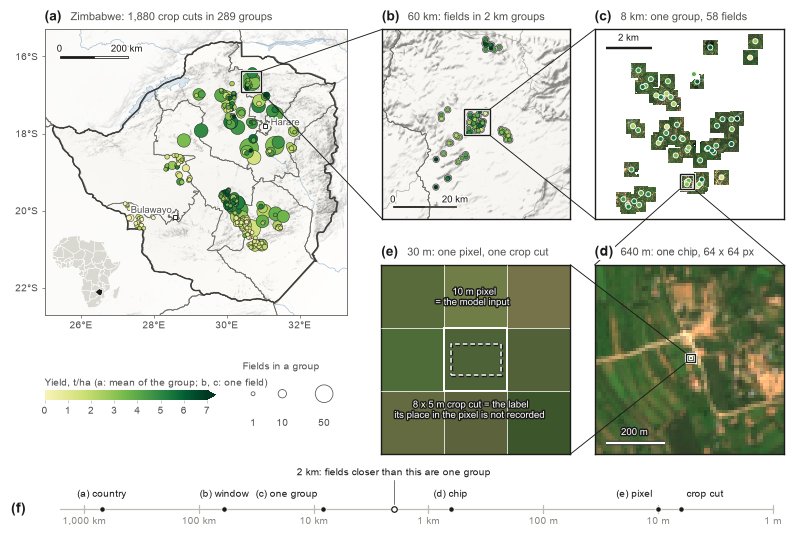

In [6]:
d = D[LACUNA]
fields = d["fields"].assign(y=d["y"])
group = fields[fields.group_id == fields.at[EXAMPLE, "group_id"]]
VMAX = 7                                                   # t/ha at the top of the yield colours (the 96th percentile)
norm = Normalize(0, VMAX)
W, H = FULL, 4.95
fig = plt.figure(figsize=(W, H))


def axes_in(x, y, w, h):                                   # a box in inches from the left and from the top
    return fig.add_axes([x / W, 1 - (y + h) / H, w / W, h / H])


# (a) the country: one circle per 2 km group
ZIM = (25.0, 33.3, -22.7, -15.3)
ax_a = axes_in(0.42, 0.22, 2.75, 2.75 * (ZIM[3] - ZIM[2]) / (ZIM[1] - ZIM[0]) / math.cos(math.radians(19)))
basemap(ax_a, "zimbabwe", ZIM, focus=["ZWE"], admin2=False, tick_step=2)
groups = fields.groupby("group_id").agg(lon=("lon", "mean"), lat=("lat", "mean"), n=("y", "size"), y=("y", "mean"))
groups = groups.sort_values("n", ascending=False)
ax_a.scatter(groups.lon, groups.lat, s=4 + 2.6 * groups.n, c=groups.y, cmap=YIELD, norm=norm, edgecolors=INK, linewidths=0.3,
             zorder=10)
cities(ax_a, {"Harare", "Bulawayo"}, offsets={"Bulawayo": (-0.12, 0.06, "right"), "Harare": (0.16, -0.02, "left")})
scalebar(ax_a, 200, x=0.05, y=0.90)
panel_title(ax_a, "a", f"Zimbabwe: {len(fields):,} crop cuts in {len(groups)} groups")
locator(fig, [(0.42 + 0.05) / W, 1 - (0.22 + ax_a.get_position().height * H - 0.05) / H, 0.66 / W, 0.68 / H], [], focus=["ZWE"])

# (b) 60 km: every field, and the 2 km groups as blobs
centre = group.lon.mean(), group.lat.mean()
half_lon, half_lat = 30 / (111.32 * math.cos(math.radians(centre[1]))), 30 / 110.57
B = (centre[0] - half_lon, centre[0] + half_lon, centre[1] - half_lat, centre[1] + half_lat)
S, X1, X2, Y1, Y2 = 1.72, 3.48, 5.42, 0.22, 2.36
ax_b = axes_in(X1, Y1, S, S)
basemap(ax_b, "zimbabwe", B, focus=["ZWE"], admin2=True, ticks=False, relief_gain=0.55)
near = fields[fields.lon.between(B[0], B[1]) & fields.lat.between(B[2], B[3])]
ax_b.add_patch(PathPatch(geom_path(discs(near.lon, near.lat, 1000)), facecolor=tint(INK, 0.80), edgecolor="none", zorder=8))
ax_b.add_collection(LineCollection(outlines([discs(near.lon, near.lat, 1000)]), colors=INK2, linewidths=0.5, zorder=9))
ax_b.scatter(near.lon, near.lat, s=7, c=near.y, cmap=YIELD, norm=norm, edgecolors=INK, linewidths=0.25, zorder=10)
scalebar(ax_b, 20, x=0.06, y=0.06)
panel_title(ax_b, "b", "60 km: fields in 2 km groups")

# (c) 8 km: one group on Sentinel-2 true colour, March 2023
MONTH = "2023-03"
image, extent, grid = mosaic(list(group.index), MONTH)
gx, gy = to_utm(grid, group.lon, group.lat)
cx, cy, half = (extent[0] + extent[1]) / 2, (extent[2] + extent[3]) / 2, 4100
ax_c = axes_in(X2, Y1, S, S)
ax_c.imshow(np.where(np.isnan(image), 1.0, image), extent=extent, zorder=1)
ax_c.set_xlim(cx - half, cx + half)
ax_c.set_ylim(cy - half, cy + half)
ax_c.scatter(gx, gy, s=11, c=group.y, cmap=YIELD, norm=norm, edgecolors=PAPER, linewidths=0.6, zorder=10)
plain(ax_c)
scalebar_m(ax_c, 2000, "2 km", x=0.06, y=0.90, color=INK)
panel_title(ax_c, "c", f"8 km: one group, {len(group)} fields")

# (d) 640 m: the chip of one field
chip = chip_of(EXAMPLE)
values = chip.reflectance(MONTH)
row, col = chip.pixel
ax_d = axes_in(X2, Y2, S, S)
ax_d.imshow(true_colour(values), extent=chip.extent, zorder=1)
px, py = chip.extent[0] + 10 * col, chip.extent[3] - 10 * (row + 1)          # lower-left corner of the labelled pixel
ax_d.add_patch(Rectangle((px, py), 10, 10, fill=False, edgecolor=PAPER, linewidth=0.8, zorder=12))
plain(ax_d)
scalebar_m(ax_d, 200, "200 m", x=0.06, y=0.06)


# (e) 30 m: the labelled pixel and the crop cut, to scale
ax_e = axes_in(X1, Y2, S, S)
ax_e.imshow(true_colour(values[:, row - 1:row + 2, col - 1:col + 2]), extent=(0, 30, 0, 30), zorder=1)
for v in (10, 20):
    ax_e.plot([v, v], [0, 30], color=PAPER, linewidth=0.5, zorder=3)
    ax_e.plot([0, 30], [v, v], color=PAPER, linewidth=0.5, zorder=3)
ax_e.add_patch(Rectangle((10, 10), 10, 10, fill=False, edgecolor=PAPER, linewidth=1.3, zorder=5))
ax_e.add_patch(Rectangle((11, 12.5), 8, 5, fill=False, edgecolor=PAPER, linewidth=1.0, linestyle=(0, (3, 2)), zorder=6,
                         path_effects=[pe.withStroke(linewidth=2.2, foreground=INK)]))
ax_e.text(15, 23.2, "10 m pixel\n= the model input", ha="center", va="bottom", fontsize=6.3, color=PAPER, zorder=7,
          path_effects=halo(1.8, INK), linespacing=1.15)
ax_e.text(15, 8.6, "8 x 5 m crop cut = the label\nits place in the pixel is not recorded", ha="center", va="top", fontsize=6.3,
          color=PAPER, zorder=7, path_effects=halo(1.8, INK), linespacing=1.15)
ax_e.set_xlim(0, 30)
ax_e.set_ylim(0, 30)
plain(ax_e)
panel_title(ax_e, "e", "30 m: one pixel, one crop cut")

# the zoom boxes: a -> b -> c -> d -> e
connect(fig, ax_a, B, ax_b, "right")
connect(fig, ax_b, tuple(np.ravel([to_lonlat(grid, [cx - half, cx + half], [cy, cy])[0], to_lonlat(grid, [cx, cx], [cy - half, cy + half])[1]])),
        ax_c, "right")
connect(fig, ax_c, chip.extent, ax_d, "down", color=INK)
connect(fig, ax_d, (px - 10, px + 20, py - 10, py + 20), ax_e, "left", color=INK)
# The title of (d) is figure text on a white box, drawn after the zoom lines, so that the line from (c) does not cross it.
corner = ax_d.get_position()
for dx, dy, text, style in ((0, 4, "(d)", {"fontsize": 9, "fontweight": "bold", "color": INK}),
                            (17, 4.6, "640 m: one chip, 64 x 64 px", {"fontsize": 7.2, "color": INK2})):
    fig.text(corner.x0 + dx / 72 / W, corner.y1 + dy / 72 / H, text, ha="left", va="bottom", zorder=100,
             bbox={"boxstyle": "square,pad=0.1", "facecolor": PAPER, "edgecolor": "none"}, **style)

# colour and size keys under (a)
cax = axes_in(0.42, 3.50, 1.55, 0.085)
bar = colorbar(fig, mpl.cm.ScalarMappable(norm, YIELD), cax=cax, orientation="horizontal", extend="max", ticks=range(VMAX + 1))
cax.set_title("Yield, t/ha (a: mean of the group; b, c: one field)", fontsize=6.8, fontweight="normal", color=INK2, pad=3, loc="left")
key = axes_in(2.22, 3.33, 0.95, 0.42)
key.axis("off")
key.set_xlim(0, 1)
key.set_ylim(0, 1)
key.text(0, 1.0, "Fields in a group", ha="left", va="bottom", fontsize=6.8, color=INK2)
for x, n in ((0.10, 1), (0.38, 10), (0.78, 50)):
    key.scatter([x], [0.52], s=4 + 2.6 * n, facecolors="none", edgecolors=INK2, linewidths=0.5, clip_on=False)
    key.text(x, -0.02, f"{n}", ha="center", va="top", fontsize=6.5, color=INK2)

# (f) the scale ladder
ax_f = axes_in(0.42, 4.50, W - 0.48, 0.16)
ax_f.set_xscale("log")
ax_f.set_xlim(2.2e6, 0.8)
ax_f.set_ylim(-1, 1)
ax_f.axis("off")
ax_f.plot([1.6e6, 1], [0, 0], color=AXIS, linewidth=0.8)
for metres, text in ((1e6, "1,000 km"), (1e5, "100 km"), (1e4, "10 km"), (1e3, "1 km"), (1e2, "100 m"), (1e1, "10 m"), (1, "1 m")):
    ax_f.plot([metres, metres], [-0.45, 0.45], color=AXIS, linewidth=0.8)
    ax_f.text(metres, -0.9, text, ha="center", va="top", fontsize=6.3, color=MUTED)
marks = ((7.0e5, "(a) country", "center"), (6.0e4, "(b) window", "center"), (8.2e3, "(c) one group", "right"),
         (640, "(d) chip", "center"), (10, "(e) pixel", "right"), (40 ** 0.5, "crop cut", "left"))
for metres, text, ha in marks:
    ax_f.plot([metres], [0], "o", ms=3.6, mfc=INK, mec=PAPER, mew=0.6, zorder=5, clip_on=False)
    shift = {"center": 1.0, "right": 1.12, "left": 0.89}[ha]
    ax_f.text(metres * shift, 1.15, text, ha=ha, va="bottom", fontsize=6.6, color=INK, clip_on=False)
# the 2 km rule of the split is not a panel: a hollow mark and a label on a second row
ax_f.plot([2000], [0], "o", ms=3.6, mfc=PAPER, mec=INK, mew=0.8, zorder=5, clip_on=False)
ax_f.plot([2000, 2000], [0.6, 3.3], color=INK2, linewidth=0.5, clip_on=False)
ax_f.text(2000, 3.6, "2 km: fields closer than this are one group", ha="center", va="bottom", fontsize=6.6, color=INK, clip_on=False)
ax_f.annotate("(f)", xy=(0, 0.5), xycoords="axes fraction", xytext=(-22, 0), textcoords="offset points", fontsize=9,
              fontweight="bold", va="center")
save(fig, "D01_powers_of_ten")

### D02. Where the crop cuts are

**What it shows.** Every field with a crop cut and a clear Sentinel-2 series, in the three countries: Zimbabwe (Lacuna 2023 and the auxiliary 2024 set), Malawi (2022 and 2023) and Kenya (2019 and 2020).

**Read it like this.** One mark is one field. The points of two data sets are drawn in random order, so no data set hides the other. The scale bar is 100 km in each map: the three maps have different scales.

**Take-away.** The fields are not spread over the countries. They sit in a few regions and in tight groups. Kenya has two seasons at the same places; Malawi 2023 covers one district only.

**Source.** `labels_v2` (model rows of each data set). Maps: Natural Earth, Copernicus DEM.

**Caption draft.** Fields with a crop cut and a clear Sentinel-2 series. (a) Zimbabwe: Lacuna 2023 (main data set) and the auxiliary 2024 set. (b) Malawi 2022 and 2023 (walked field polygons). (c) Kenya 2019 and 2020. The scale bar is 100 km in each map.

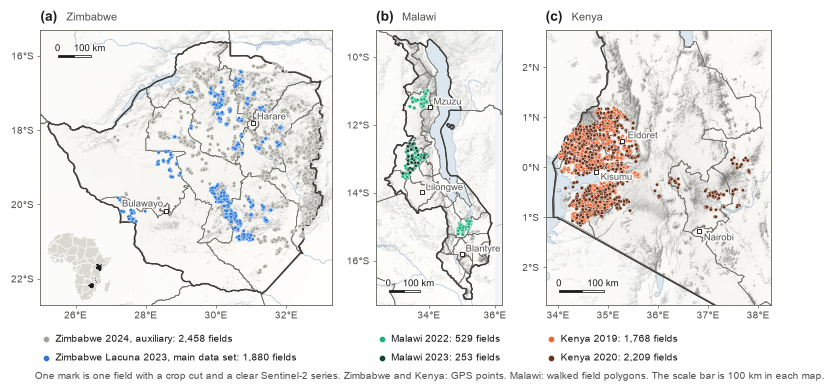

In [7]:
def cohort_points(cohorts_years, colours, seed=0):
    """Fields of one or more data sets in one table, in random order, so that no data set hides another."""
    parts = []
    for (cohort, year), colour in zip(cohorts_years, colours):
        rows = labels.loc[D[cohort]["y"].index, ["lon", "lat", "season_year"]]
        parts.append((rows if year is None else rows[rows.season_year == year]).assign(colour=colour))
    table = pd.concat(parts)
    return table.sample(frac=1, random_state=seed), [len(p) for p in parts]


MAPS = [  # letter, country, region of the relief, ISO code, extent, towns with label offsets, data sets, names, colours
    ("a", "Zimbabwe", "zimbabwe", "ZWE", (25.0, 33.3, -22.7, -15.3), {"Harare": (0.12, 0.05, "left"), "Bulawayo": (-0.12, 0.06, "right")},
     [(ZIM24, None), (LACUNA, None)], ["Zimbabwe 2024, auxiliary", "Zimbabwe Lacuna 2023, main data set"], ["#a3a29a", BLUE]),
    ("b", "Malawi", "malawi", "MWI", (32.4, 36.2, -17.3, -9.2), {"Lilongwe": (0.12, 0.0, "left"), "Blantyre": (0.12, 0.0, "left"), "Mzuzu": (0.12, 0.0, "left")},
     [(MALAWI22, None), (MALAWI23, None)], ["Malawi 2022", "Malawi 2023"], [AQUA, shade(AQUA, 0.6)]),
    ("c", "Kenya", "kenya", "KEN", (33.75, 38.25, -2.75, 2.75), {"Nairobi": (0.1, -0.22, "left"), "Kisumu": (0.1, -0.2, "left"), "Eldoret": (0.12, 0.02, "left")},
     [(KENYA, 2019), (KENYA, 2020)], ["Kenya 2019", "Kenya 2020"], [ORANGE, shade(ORANGE, 0.55)]),
]
HEIGHT, GAP, LEFT, TOP = 2.50, 0.40, 0.40, 0.24
widths = [HEIGHT / map_height(m[4], 1.0) for m in MAPS]
fig = plt.figure(figsize=(FULL, HEIGHT + 0.95))
x = LEFT + (FULL - LEFT - sum(widths) - 2 * GAP - 0.06) / 2
for (letter, country, region, iso, extent, towns, sets, names, colours), width in zip(MAPS, widths):
    ax = inch_axes(fig, x, TOP, width, HEIGHT)
    basemap(ax, region, extent, focus=[iso], admin2=False, tick_step=2 if iso != "KEN" else 1)
    points, counts = cohort_points(sets, colours)
    if iso == "ZWE":                                     # the auxiliary data set stays under the main data set
        points = points.sort_values("colour", key=lambda c: c == BLUE, kind="stable")
    ax.scatter(points.lon, points.lat, c=points.colour, s=4.5, edgecolors=PAPER, linewidths=0.2, zorder=10)
    cities(ax, set(towns), offsets=towns)
    scalebar(ax, 100, x=0.06 if iso != "MWI" else 0.10, y=0.90 if iso == "ZWE" else 0.045)
    panel_title(ax, letter, country)
    for i, (name, n, colour) in enumerate(zip(names, counts, colours)):     # the key under the map
        ypos = -0.125 - 0.068 * i
        ax.scatter([0.02 * 2.6 / width], [ypos], transform=ax.transAxes, s=16, c=colour, edgecolors=PAPER, linewidths=0.3,
                   clip_on=False, zorder=46)
        ax.text(0.02 * 2.6 / width + 0.085 / width, ypos, f"{name}: {n:,} fields", transform=ax.transAxes, fontsize=6.6, color=INK,
                va="center", clip_on=False)
    if iso == "ZWE":
        box_ = ax.get_position()
        locator(fig, [box_.x0 + 0.006, box_.y0 + 0.008, 0.62 / FULL, 0.64 / (HEIGHT + 0.95)], [], focus=["ZWE", "MWI", "KEN"])
    x += width + GAP
fig.text(LEFT / FULL, 0.005, "One mark is one field with a crop cut and a clear Sentinel-2 series. Zimbabwe and Kenya: GPS points. "
         "Malawi: walked field polygons. The scale bar is 100 km in each map.", fontsize=6.5, color=INK2, ha="left", va="bottom")
save(fig, "D02_study_area")

### D03. Yield map of Zimbabwe (dark and light version)

**What it shows.** (a) The mean yield of each 2 km group of fields. (b), (c) Two 130 km windows, north and south, with every field. The cell makes the same figure twice: on a dark relief (`D03_yield_map_dark`) and on a light relief (`D03_yield_map_light`).

**Read it like this.** Colour is yield in t/ha; the colour bar ends at 7 t/ha and higher values take the last colour. In (a) the area of a circle is the number of fields in the group.

**Take-away.** Yield changes over tens of kilometres: the south window goes from high yields in its north-west to low yields in its south-east. This large pattern is what a model can learn from the address alone.

**Source.** `labels_v2`, split `s1_cc2km`. These are measured yields, not model output.

**Caption draft.** Measured maize yield, Zimbabwe Lacuna 2023. (a) Mean yield of each 2 km group of fields (289 groups, 1,880 fields). (b), (c) All fields in two 130 km windows.

**Caution.** The map shows where crop cuts were made. It is not a wall-to-wall yield map.

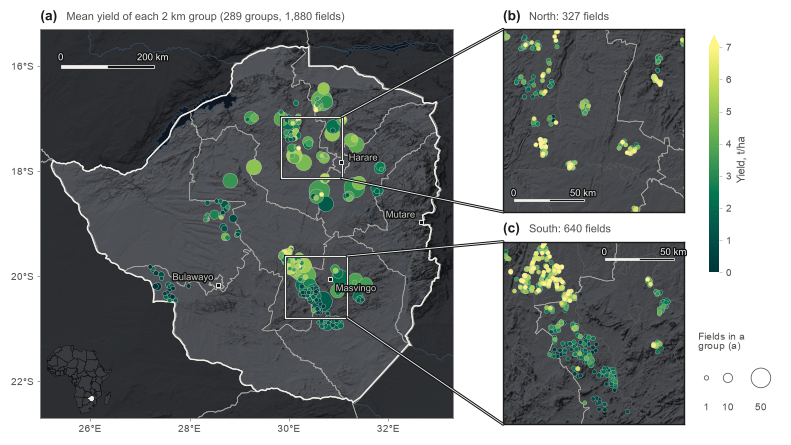

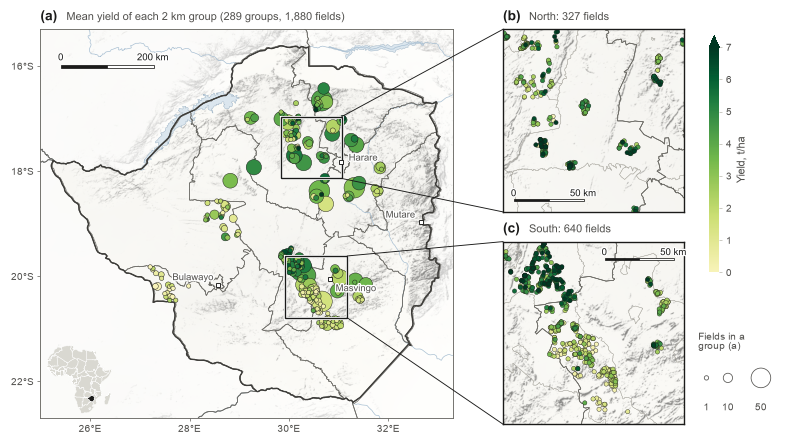

In [8]:
def yield_map(theme):
    """Zimbabwe Lacuna 2023: mean yield of each 2 km group, and two 130 km windows with every field."""
    t = THEMES[theme]
    cmap = YIELD if theme == "light" else YIELD_DARK
    edge = INK if theme == "light" else "#d9d8d1"       # a light ring keeps low yields visible on the dark map
    d = D[LACUNA]
    fields = d["fields"].assign(y=d["y"])
    norm = Normalize(0, 7)
    fig = plt.figure(figsize=(FULL, 4.1))
    ZIM = (25.0, 33.3, -22.7, -15.3)
    ax_a = inch_axes(fig, 0.42, 0.24, 3.75, map_height(ZIM, 3.75))
    basemap(ax_a, "zimbabwe", ZIM, theme, focus=["ZWE"], admin2=False, tick_step=2)
    groups = fields.groupby("group_id").agg(lon=("lon", "mean"), lat=("lat", "mean"), n=("y", "size"), y=("y", "mean"))
    groups = groups.sort_values("n", ascending=False)
    ax_a.scatter(groups.lon, groups.lat, s=5 + 3.2 * groups.n, c=groups.y, cmap=cmap, norm=norm, edgecolors=edge,
                 linewidths=0.3 if theme == "light" else 0.2, zorder=10)
    cities(ax_a, {"Harare", "Bulawayo", "Mutare", "Masvingo"}, theme,
           offsets={"Bulawayo": (-0.12, 0.06, "right"), "Harare": (0.16, -0.02, "left"), "Mutare": (-0.12, 0.05, "right"),
                    "Masvingo": (0.12, -0.26, "left")})
    scalebar(ax_a, 200, x=0.05, y=0.90, theme=theme)
    panel_title(ax_a, "a", f"Mean yield of each 2 km group ({len(groups)} groups, {len(fields):,} fields)")
    box_ = ax_a.get_position()
    locator(fig, [box_.x0 + 0.006, box_.y0 + 0.008, 0.62 / FULL, 0.64 / 4.1], [], theme, focus=["ZWE"])
    S, X = 1.66, 4.62
    for letter, name, (lon, lat), top in (("b", "North", (30.45, -17.55), 0.24), ("c", "South", (30.55, -20.20), 0.24 + S + 0.27)):
        extent = window(lon, lat, 130)
        ax = inch_axes(fig, X, top, S, S)
        basemap(ax, "zimbabwe", extent, theme, focus=["ZWE"], admin2=True, ticks=False, relief_gain=0.7)
        near = fields[fields.lon.between(extent[0], extent[1]) & fields.lat.between(extent[2], extent[3])].sort_values("y")
        ax.scatter(near.lon, near.lat, s=8, c=near.y, cmap=cmap, norm=norm, edgecolors=edge,
                   linewidths=0.25 if theme == "light" else 0.15, zorder=10)
        scalebar(ax, 50, x=0.06 if letter == "b" else 0.56, y=0.06 if letter == "b" else 0.90, theme=theme)   # clear of the fields
        panel_title(ax, letter, f"{name}: {len(near):,} fields")
        connect(fig, ax_a, extent, ax, "right", color=t["text"], halo_color=t["halo"] if theme == "dark" else None)
        for side in ("top", "right", "left", "bottom"):
            ax.spines[side].set_color(INK)
    cax = inch_axes(fig, X + S + 0.22, 0.30, 0.09, 2.15)
    colorbar(fig, mpl.cm.ScalarMappable(norm, cmap), cax=cax, extend="max", ticks=range(8), label="Yield, t/ha")
    key = inch_axes(fig, X + S + 0.12, 3.22, 0.75, 0.42)
    key.axis("off")
    key.set_xlim(0, 1)
    key.set_ylim(0, 1)
    for x, n in ((0.10, 1), (0.36, 10), (0.76, 50)):
        key.scatter([x], [0.55], s=5 + 3.2 * n, facecolors="none", edgecolors=INK2, linewidths=0.5, clip_on=False)
        key.text(x, 0.0, f"{n}", ha="center", va="top", fontsize=6.3, color=INK2)
    key.text(0.0, 1.12, "Fields in a\ngroup (a)", ha="left", va="bottom", fontsize=6.5, color=INK2, linespacing=1.1)
    return fig


save(yield_map("dark"), "D03_yield_map_dark")
save(yield_map("light"), "D03_yield_map_light")

### D04. Yield minus its address

**What it shows.** (a) The yield of each field in a 150 km window. (b) The same fields after the mean of their 2 km group is taken away. (c) The share of the yield variance that lies between the 2 km groups, for each data set (folds 1-4). (d) The correlation of the yields of two fields against their distance (all pairs of the 1,880 fields).

**Read it like this.** In (b) blue is below the group mean and red is above it. A grey ring is a field that is alone in its group. In (d) each point is one distance class.

**Take-away.** The pattern of (a) is gone in (b). In Lacuna, 56 % of the yield variance is between groups, and two fields less than 2 km apart correlate at r = 0.37. The correlation stays above 0.3 up to about 20 km.

**Source.** `labels_v2`, split `s1_cc2km`; panel (c) uses the fields of folds 1-4, as the result tables do.

**Caption draft.** (a) Field yield in a 150 km window of Zimbabwe. (b) The same fields minus the mean of their 2 km group. (c) Share of the yield variance between 2 km groups. (d) Correlation of the yields of two fields against their distance.

**Caution.** The median group has 2 fields, so a group mean is noisy. Panel (c) is one number for each data set, with no interval.

window: 686 fields in 108 groups; fields alone in their group: 41
pairs per distance class: {'0-0.25 km': 520, '0.25-0.5 km': 858, '0.5-1 km': 1980, '1-2 km': 4472, '2-5 km': 11556, '5-10 km': 14883, '10-20 km': 37384, '20-50 km': 108362, '50-100 km': 245543, '100-200 km': 410168, '200-400 km': 830077}


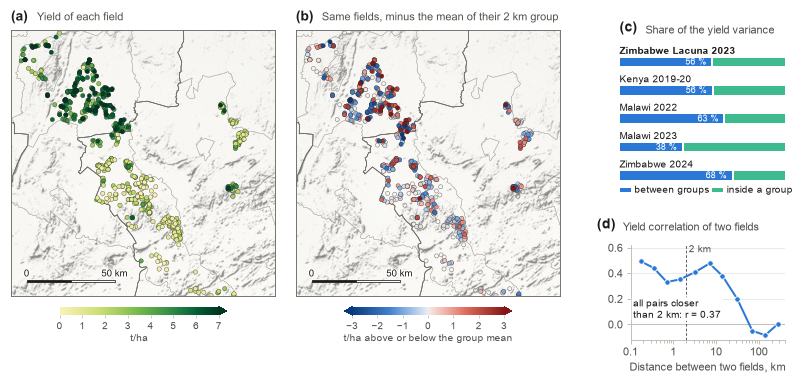

In [9]:
from scipy.spatial.distance import pdist

d = D[LACUNA]
fields = d["fields"].assign(y=d["y"])
fields["group_mean"] = fields.groupby("group_id").y.transform("mean")
fields["group_size"] = fields.groupby("group_id").y.transform("size")
fields["minus_group"] = fields.y - fields.group_mean
WIN = window(30.50, -20.15, 150)
near = fields[fields.lon.between(WIN[0], WIN[1]) & fields.lat.between(WIN[2], WIN[3])]


def variance_between(cohort):
    """Share of the yield variance that lies between the 2 km groups (per season), on the fields of folds 1-4."""
    table = P[cohort]
    key = cluster_year(table)
    means = table.y.groupby(key).transform("mean")
    return float(((means - table.y.mean()) ** 2).sum() / ((table.y - table.y.mean()) ** 2).sum())


# yield correlation of two fields against their distance (all pairs of the 1,880 fields)
x, y = to_utm("EPSG:32736", fields.lon, fields.lat)
distance_km = pdist(np.c_[x, y]) / 1000
i, j = np.triu_indices(len(fields), k=1)
yi, yj = fields.y.to_numpy()[i], fields.y.to_numpy()[j]


def pair_correlation(mask):
    """Pearson r of the two yields over all pairs of a distance class (each pair counted in both orders)."""
    a, b = np.r_[yi[mask], yj[mask]], np.r_[yj[mask], yi[mask]]
    return float(np.corrcoef(a, b)[0, 1])


EDGES = np.array([0, 0.25, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 400])
which = np.digitize(distance_km, EDGES) - 1
correlation = np.array([pair_correlation(which == k) for k in range(len(EDGES) - 1)])
pairs = np.array([(which == k).sum() for k in range(len(EDGES) - 1)])
within_2km = pair_correlation(distance_km < 2)

fig = plt.figure(figsize=(FULL, 3.42))
S = 2.42
norm_y, norm_d = Normalize(0, 7), Normalize(-3, 3)
for letter, left, title, values, cmap, norm in (
        ("a", 0.08, "Yield of each field", near.y, YIELD, norm_y),
        ("b", 0.08 + S + 0.17, "Same fields, minus the mean of their 2 km group", near.minus_group, DIVERGE, norm_d)):
    ax = inch_axes(fig, left, 0.24, S, S)
    basemap(ax, "zimbabwe", WIN, focus=["ZWE"], admin2=True, ticks=False, relief_gain=0.6)
    order = np.argsort(np.abs(values.to_numpy() - (0 if letter == "b" else values.median())))
    points = near.iloc[order]
    alone = points.group_size.to_numpy() == 1
    if letter == "b":      # a field alone in its group has no "inside": an open grey ring
        ax.scatter(points.lon[alone], points.lat[alone], s=7, facecolors="none", edgecolors=MUTED, linewidths=0.4, zorder=9)
        points, shown = points[~alone], values.iloc[order][~alone]
    else:
        shown = values.iloc[order]
    ax.scatter(points.lon, points.lat, s=8, c=shown, cmap=cmap, norm=norm, edgecolors=INK, linewidths=0.2, zorder=10)
    scalebar(ax, 50, x=0.06, y=0.05)
    panel_title(ax, letter, title)
    cax = inch_axes(fig, left + 0.45, 0.24 + S + 0.10, S - 0.9, 0.075)
    colorbar(fig, mpl.cm.ScalarMappable(norm, cmap), cax=cax, orientation="horizontal", extend="max" if letter == "a" else "both",
             ticks=range(8) if letter == "a" else range(-3, 4))
    cax.set_xlabel("t/ha" if letter == "a" else "t/ha above or below the group mean", fontsize=6.8, labelpad=1.5)
fig.text((0.08 + S + 0.085) / FULL, 1 - (0.24 + S / 2) / 3.42, "−", fontsize=1, alpha=0)   # keeps the two maps as one pair

# (c) how much of the variance is the address
RIGHT, WIDTH = 5.62, 1.50
ax_c = inch_axes(fig, RIGHT, 0.34, WIDTH, 1.42)
rows = [(LACUNA, "Zimbabwe Lacuna 2023"), (KENYA, "Kenya 2019-20"), (MALAWI22, "Malawi 2022"), (MALAWI23, "Malawi 2023"),
        (ZIM24, "Zimbabwe 2024")]
for k, (cohort, name) in enumerate(rows):
    share = variance_between(cohort)
    ypos = len(rows) - 1 - k
    ax_c.barh(ypos, share, height=0.30, color=VILLAGE, linewidth=0)
    ax_c.barh(ypos, 1 - share - 0.012, left=share + 0.012, height=0.30, color=tint(FIELD, 0.15), linewidth=0)
    ax_c.text(0.0, ypos + 0.21, name, fontsize=6.3, color=INK, va="bottom", ha="left", fontweight="bold" if cohort == LACUNA else "normal")
    ax_c.text(share - 0.03, ypos - 0.01, f"{100 * share:.0f} %", fontsize=6.2, color=PAPER, va="center", ha="right")
ax_c.set_xlim(0, 1)
ax_c.set_ylim(-0.75, len(rows) - 0.25)
ax_c.axis("off")
panel(ax_c, "c", dy=4)
ax_c.annotate("Share of the yield variance", xy=(0, 1), xycoords="axes fraction", xytext=(17, 4.6), textcoords="offset points",
              fontsize=7.2, color=INK2)
ax_c.plot([0.0, 0.07], [-0.52, -0.52], color=VILLAGE, linewidth=2.6, solid_capstyle="butt", clip_on=False)
ax_c.text(0.09, -0.52, "between groups", fontsize=6.3, color=INK, ha="left", va="center")
ax_c.plot([0.56, 0.63], [-0.52, -0.52], color=tint(FIELD, 0.15), linewidth=2.6, solid_capstyle="butt", clip_on=False)
ax_c.text(0.65, -0.52, "inside a group", fontsize=6.3, color=INK, ha="left", va="center")

# (d) how far the address reaches
ax_d = inch_axes(fig, RIGHT + 0.10, 2.20, WIDTH - 0.10, 0.86)
middle = np.sqrt(np.maximum(EDGES[:-1], 0.12) * EDGES[1:])
ax_d.axhline(0, color=AXIS, linewidth=0.6)
ax_d.axvline(2, color=INK2, linewidth=0.6, linestyle=(0, (3, 2)))
ax_d.plot(middle, correlation, color=VILLAGE, linewidth=1.3, marker="o", markersize=3.6, markerfacecolor=VILLAGE,
          markeredgecolor=PAPER, markeredgewidth=0.6)
ax_d.set_xscale("log")
ax_d.set_xlim(0.1, 400)
ax_d.set_ylim(-0.12, 0.62)
ax_d.set_xticks([0.1, 1, 10, 100], ["0.1", "1", "10", "100"])
ax_d.set_yticks([0, 0.2, 0.4, 0.6])
ax_d.set_xlabel("Distance between two fields, km")
ax_d.text(2.3, 0.585, "2 km", fontsize=6.3, color=INK2, va="center")
ax_d.text(0.115, 0.12, f"all pairs closer\nthan 2 km: r = {within_2km:.2f}", fontsize=6.3, color=INK, va="center", ha="left", linespacing=1.15,
          bbox={"boxstyle": "round,pad=0.15", "facecolor": PAPER, "edgecolor": "none"}, zorder=5)
hgrid(ax_d)
panel(ax_d, "d", dx=-22, dy=9)
ax_d.annotate("Yield correlation of two fields", xy=(0, 1), xycoords="axes fraction", xytext=(-5, 9.6), textcoords="offset points",
              fontsize=7.2, color=INK2)
print(f"window: {len(near)} fields in {near.group_id.nunique()} groups; fields alone in their group: {int((near.group_size == 1).sum())}")
print("pairs per distance class:", {f"{EDGES[k]:g}-{EDGES[k + 1]:g} km": int(n) for k, n in enumerate(pairs)})
save(fig, "D04_yield_minus_address")

### D05. The split that you can see

**What it shows.** (a) The fields of each of the five folds; fold 0 is held back. (b), (c) One 24 km window under a random split and under the spatial split: blue = the test fold, grey = the training folds; the grey shapes are circles of 1 km round each field, so fields less than 2 km apart melt into one group. (d) The distance from each test field to its nearest training field. (e) The R² of a model that knows only the coordinates, under each split.

**Read it like this.** In (e) the dark dot is the random split and the blue dot is the spatial split.

**Take-away.** With a random split, half of the test fields have a training field closer than 0.5 km, and the address alone gives R² 0.40 in Lacuna. With whole 2 km groups held out, every test field is at least 2 km from the training data and the address gives 0.11.

**Source.** Split files `s1_cc2km` and `random_diag` of data v2; model rows of folds 1-4 only (fold 0 is not scored). The Lacuna value of the spatial split is checked against R1 of the ladder.

**Caption draft.** Spatial cross-validation. (a) Whole 2 km groups of fields are dealt into five folds; fold 0 is held back. (b), (c) A random split and the spatial split in the same window. (d) Distance from a test field to the nearest training field. (e) R² of a coordinates-only model under each split.

**Caution.** The random split is a diagnostic only. No result of the report uses it.

{'Zimbabwe Lacuna 2023': (0.403, 0.106), 'Kenya 2019-20': (0.278, 0.183), 'Malawi 2022': (0.446, 0.289), 'Zimbabwe 2024': (0.245, 0.183)} | median gap km: {'random': 0.473, 'spatial': 5.788} | smallest spatial gap km: 2.01


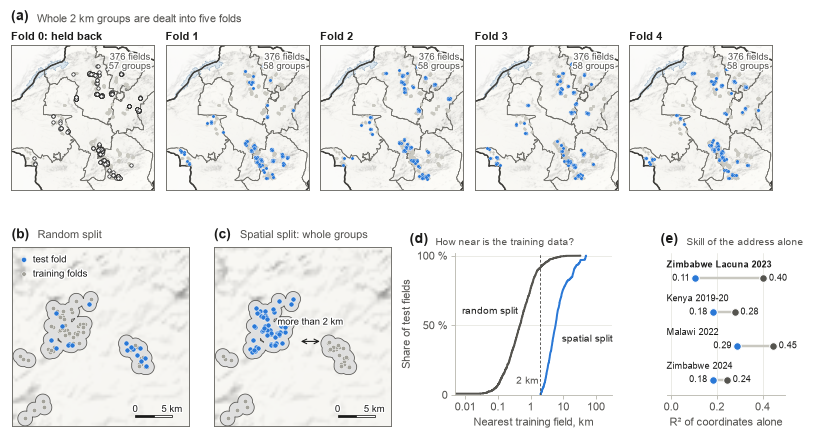

In [10]:
from scipy.spatial import cKDTree

from cropyield.baselines.models import coordinates_knn

d = D[LACUNA]
fields = d["fields"].assign(y=d["y"])
random_fold = pd.read_csv(V2 / "splits" / f"{LACUNA}__random_diag.csv", dtype={"fold": str}).set_index("obs_id")["fold"]
fields["random_fold"] = random_fold.reindex(fields.index)
dev = fields[fields.fold != "0"]                           # folds 1-4: the fields that development may score
ux, uy = to_utm("EPSG:32736", dev.lon, dev.lat)


def nearest_other_fold(fold):
    """Distance in km from each field to the nearest field of another fold (its nearest training field)."""
    out = np.full(len(dev), np.nan)
    for value in np.unique(fold):
        test = fold == value
        out[test] = cKDTree(np.c_[ux[~test], uy[~test]]).query(np.c_[ux[test], uy[test]])[0] / 1000
    return out


def knn_r2(table, fold):
    """Coordinates-only model (mean of the 10 nearest training fields), cross-validated over the given folds."""
    latlon, y, pred = table[["lat", "lon"]].to_numpy(), table.y.to_numpy(), np.full(len(table), np.nan)
    for value in np.unique(fold):
        test = fold == value
        pred[test] = coordinates_knn(latlon[~test], y[~test], latlon[test], step8.K)
    return r2(y, pred)


gap = {"random": nearest_other_fold(dev.random_fold.to_numpy()), "spatial": nearest_other_fold(dev.fold.to_numpy())}
address = {}
for cohort, name in ((LACUNA, "Zimbabwe Lacuna 2023"), (KENYA, "Kenya 2019-20"), (MALAWI22, "Malawi 2022"), (ZIM24, "Zimbabwe 2024")):
    table = D[cohort]["fields"].assign(y=D[cohort]["y"])
    table = table[table.fold != "0"]
    rfold = pd.read_csv(V2 / "splits" / f"{cohort}__random_diag.csv", dtype={"fold": str}).set_index("obs_id")["fold"].reindex(table.index)
    address[name] = (knn_r2(table, rfold.to_numpy()), knn_r2(table, table.fold.to_numpy()))
assert abs(address["Zimbabwe Lacuna 2023"][1] - score(P[LACUNA], "R1")["r2"]) < 1e-9     # the R1 of the ladder

fig = plt.figure(figsize=(FULL, 4.25))
# (a) five small maps: the fields of each fold
EXTENT = (26.7, 32.4, -21.4, -15.9)
width = 1.30
height = map_height(EXTENT, width)
for k, fold in enumerate("01234"):
    ax = inch_axes(fig, 0.08 + k * (width + 0.105), 0.42, width, height)
    basemap(ax, "zimbabwe", EXTENT, focus=["ZWE"], ticks=False, rivers=False, relief_gain=0.5)
    here = fields.fold == fold
    ax.scatter(fields.lon[~here], fields.lat[~here], s=1.6, c=NEUTRAL_LIGHT, linewidths=0, zorder=9)
    if fold == "0":
        ax.scatter(fields.lon[here], fields.lat[here], s=5, facecolors=PAPER, edgecolors=INK, linewidths=0.45, zorder=10)
    else:
        ax.scatter(fields.lon[here], fields.lat[here], s=4.5, c=BLUE, edgecolors=PAPER, linewidths=0.15, zorder=10)
    groups = fields[here].group_id.nunique()
    ax.set_title(f"Fold {fold}" + (": held back" if fold == "0" else ""), fontsize=7.2, fontweight="bold", color=INK, pad=3, loc="left")
    ax.text(0.97, 0.955, f"{int(here.sum())} fields\n{groups} groups", transform=ax.transAxes, fontsize=6.2, color=INK2, ha="right",
            va="top", linespacing=1.15, path_effects=halo(1.8), zorder=20)
    if k == 0:
        panel(ax, "a", dy=14)
        ax.annotate("Whole 2 km groups are dealt into five folds", xy=(0, 1), xycoords="axes fraction", xytext=(17, 14.6),
                    textcoords="offset points", fontsize=7.2, color=INK2)

# (b), (c) the same 24 km window under a random split and under the spatial split
TOP = 0.42 + height + 0.52
WIN = window(30.705, -16.662, 24)
near = dev[dev.lon.between(WIN[0], WIN[1]) & dev.lat.between(WIN[2], WIN[3])]
blob = discs(near.lon, near.lat, 1000)
S = 1.62
for letter, left, title, test in (("b", 0.08, "Random split", near.random_fold == "1"),
                                  ("c", 0.08 + S + 0.22, "Spatial split: whole groups", near.fold == "1")):
    ax = inch_axes(fig, left, TOP, S, S)
    basemap(ax, "zimbabwe", WIN, focus=["ZWE"], ticks=False, admin1=False, relief_gain=0.3)
    ax.add_patch(PathPatch(geom_path(blob), facecolor=tint(INK, 0.86), edgecolor=INK2, linewidth=0.5, zorder=8))
    ax.scatter(near.lon[~test], near.lat[~test], s=9, c="#a3a29a", edgecolors=PAPER, linewidths=0.3, zorder=10)
    ax.scatter(near.lon[test], near.lat[test], s=11, c=BLUE, edgecolors=PAPER, linewidths=0.3, zorder=11)
    scalebar(ax, 5, x=0.70, y=0.05)
    panel_title(ax, letter, title)
    if letter == "c":
        ax.annotate("", xy=(30.727, -16.668), xytext=(30.703, -16.668), arrowprops={"arrowstyle": "<->", "color": INK, "linewidth": 0.7,
                                                                                         "shrinkA": 0, "shrinkB": 0}, zorder=30)
        ax.text(30.715, -16.650, "more than 2 km", fontsize=6.2, color=INK, ha="center", va="bottom", path_effects=halo(1.8), zorder=31)
    else:
        ax.scatter([0.07, 0.07], [0.93, 0.85], transform=ax.transAxes, s=[11, 9], c=[BLUE, "#a3a29a"], edgecolors=PAPER, linewidths=0.3,
                   zorder=40)
        ax.text(0.12, 0.93, "test fold", transform=ax.transAxes, fontsize=6.3, va="center", path_effects=halo(1.8), zorder=40)
        ax.text(0.12, 0.85, "training folds", transform=ax.transAxes, fontsize=6.3, va="center", path_effects=halo(1.8), zorder=40)

# (d) distance from a test field to its nearest training field
ax_d = inch_axes(fig, 0.08 + 2 * S + 0.22 + 0.58, TOP + 0.05, 1.42, S - 0.33)
for name, colour, text, xy in (("random", NEUTRAL, "random split", (0.008, 0.60)), ("spatial", BLUE, "spatial split", (9.0, 0.40))):
    values = np.sort(gap[name])
    ax_d.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=colour, linewidth=1.3)
    ax_d.text(*xy, text, fontsize=6.4, color=INK, va="center")
ax_d.axvline(2, color=INK2, linewidth=0.6, linestyle=(0, (3, 2)))
ax_d.text(1.7, 0.08, "2 km", fontsize=6.3, color=INK2, ha="right")
ax_d.set_xscale("log")
ax_d.set_xlim(0.005, 300)
ax_d.set_ylim(0, 1.02)
ax_d.set_xticks([0.01, 0.1, 1, 10, 100], ["0.01", "0.1", "1", "10", "100"])
ax_d.set_yticks([0, 0.5, 1], ["0", "50 %", "100 %"])
ax_d.set_xlabel("Nearest training field, km")
ax_d.set_ylabel("Share of test fields")
hgrid(ax_d)
panel(ax_d, "d", dx=-30, dy=4.5)
ax_d.annotate("How near is the training data?", xy=(0, 1), xycoords="axes fraction", xytext=(-13, 5.1), textcoords="offset points",
              fontsize=6.8, color=INK2)

# (e) what the address alone predicts under each split
ax_e = inch_axes(fig, 0.08 + 2 * S + 0.22 + 0.58 + 1.42 + 0.50, TOP + 0.05, FULL - (0.08 + 2 * S + 0.22 + 0.58 + 1.42 + 0.50) - 0.08, S - 0.33)
for k, (name, (r_random, r_spatial)) in enumerate(address.items()):
    ypos = len(address) - 1 - k
    ax_e.plot([r_spatial, r_random], [ypos, ypos], color=NEUTRAL_LIGHT, linewidth=1.6, solid_capstyle="round", zorder=2)
    ax_e.plot(r_random, ypos, "o", ms=5, mfc=NEUTRAL, mec=PAPER, mew=0.7, zorder=3)
    ax_e.plot(r_spatial, ypos, "o", ms=5, mfc=BLUE, mec=PAPER, mew=0.7, zorder=3)
    ax_e.text(-0.02, ypos + 0.26, name, fontsize=6.2, color=INK, va="bottom", ha="left",
              fontweight="bold" if name.startswith("Zimbabwe Lacuna") else "normal")
    ax_e.text(r_random + 0.025, ypos, f"{r_random:.2f}", fontsize=6.2, color=INK, va="center", ha="left")
    ax_e.text(r_spatial - 0.025, ypos, f"{r_spatial:.2f}", fontsize=6.2, color=INK, va="center", ha="right")
ax_e.set_xlim(-0.02, 0.50)
ax_e.set_ylim(-0.45, len(address) - 0.25)
ax_e.set_yticks([])
ax_e.spines["left"].set_visible(False)
ax_e.set_xticks([0, 0.2, 0.4])
ax_e.set_xlabel("R² of coordinates alone")
hgrid(ax_e, "x")
panel(ax_e, "e", dx=-4, dy=4.5)
ax_e.annotate("Skill of the address alone", xy=(0, 1), xycoords="axes fraction", xytext=(13, 5.1), textcoords="offset points",
              fontsize=6.8, color=INK2)
print({k: (round(a, 3), round(b, 3)) for k, (a, b) in address.items()}, "| median gap km:", {k: round(float(np.median(v)), 3) for k, v in gap.items()},
      "| smallest spatial gap km:", round(float(gap["spatial"].min()), 2))
save(fig, "D05_the_split")

### D06. District maps: level, spread and sample size

**What it shows.** For each district of Zimbabwe with at least 10 Lacuna fields: (a) the mean yield, (b) the spread of yield inside the district (standard deviation in percent of the mean), (c) the number of fields.

**Read it like this.** Hatched districts have fewer than 10 fields and get no colour. Districts without a colour or a hatch have no field.

**Take-away.** The district means run from about 0.6 t/ha to about 5 t/ha. The low-yield districts also have the largest spread. Two districts hold a third of all fields (Chivi 351, Shurugwi 311).

**Source.** `labels_v2` (1,880 model rows); district outlines from geoBoundaries (OCHA, ZIMSTAT). The cell prints the table behind the maps.

**Caption draft.** Zimbabwe Lacuna 2023 by district (districts with at least 10 fields). (a) Mean yield. (b) Standard deviation of yield in percent of the mean. (c) Number of fields.

**Caution.** The fields are not a random sample of a district, so a district mean describes this sample only.

   district   n  groups  mean     cv
   Bulilima  44      23  0.61 138.31
       Seke  31       1  1.41  43.86
      Chivi 351      71  1.84  64.96
    Mwenezi  24       7  1.87  60.73
      Nkayi  75      26  2.14  66.98
    Murehwa  27       3  2.53  40.00
       Zaka  75      10  2.92  54.51
    Makonde 104      32  2.94  62.58
   Masvingo  90       8  2.98  50.74
  Marondera 128      11  3.31  59.95
Gokwe South  28       1  3.34  31.72
   Hurungwe  59       6  3.81  32.31
    Chegutu 102       7  3.83  50.13
     Mazowe  75       6  3.92  46.95
     Guruve 115      12  4.11  35.02
    Bindura  59       3  4.40  46.74
     Zvimba 134      12  4.48  47.53
   Shurugwi 311      46  4.94  33.48
    Sanyati  30       1  4.95  34.12


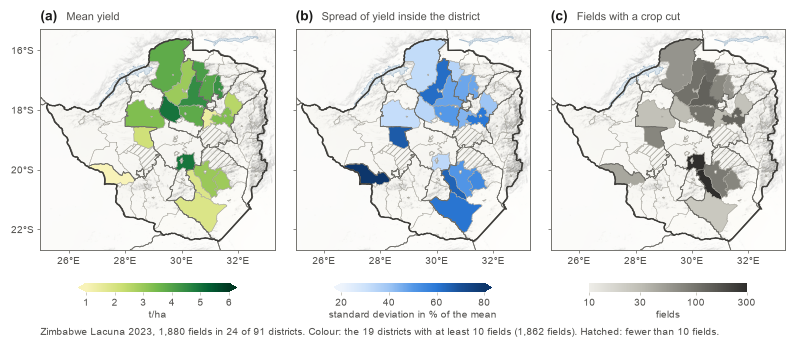

In [11]:
def district_maps(min_fields=10):
    """Three maps of the districts of Zimbabwe; a district needs `min_fields` fields to get a colour."""
    d = D[LACUNA]
    fields = d["fields"].assign(y=d["y"])
    rows = []
    for geom, name in DISTRICTS["ZWE"]:
        inside = shapely.contains_xy(geom, fields.lon.to_numpy(), fields.lat.to_numpy())
        if inside.any():
            y = fields.y[inside]
            rows.append({"district": name, "geom": geom, "n": int(inside.sum()), "mean": y.mean(), "cv": 100 * y.std() / y.mean(),
                         "groups": fields.group_id[inside].nunique()})
    districts = pd.DataFrame(rows)
    enough = districts[districts.n >= min_fields]
    greys = LinearSegmentedColormap.from_list("greys", ["#eeede8", "#bdbcb3", "#77766f", "#2f2e2c"])
    extent = (25.0, 33.3, -22.7, -15.3)
    panels = [("a", "Mean yield", "mean", YIELD, Normalize(1, 6), "t/ha", [1, 2, 3, 4, 5, 6], "both"),
              ("b", "Spread of yield inside the district", "cv", COUNT, Normalize(20, 80), "standard deviation in % of the mean",
               [20, 40, 60, 80], "both"),
              ("c", "Fields with a crop cut", "n", greys, mpl.colors.LogNorm(10, 300), "fields", [10, 30, 100, 300], "neither")]
    width, left, gap = 2.13, 0.40, 0.19
    height = map_height(extent, width)
    fig = plt.figure(figsize=(FULL, height + 1.04))
    for k, (letter, title, column, cmap, norm, unit, ticks, extend) in enumerate(panels):
        ax = inch_axes(fig, left + k * (width + gap), 0.24, width, height)
        basemap(ax, "zimbabwe", extent, focus=["ZWE"], admin2=True, ticks=True, tick_step=2, rivers=False)
        if k:
            ax.set_yticklabels([])
        for row in districts.itertuples():
            if row.n >= min_fields:
                ax.add_patch(PathPatch(geom_path(row.geom), facecolor=cmap(norm(getattr(row, column))), edgecolor="none", zorder=2.5))
            else:
                ax.add_patch(PathPatch(geom_path(row.geom), facecolor="none", edgecolor="#a3a29a", linewidth=0, hatch="//////", zorder=2.5))
        panel_title(ax, letter, title)
        cax = inch_axes(fig, left + k * (width + gap) + 0.35, 0.24 + height + 0.30, width - 0.70, 0.075)
        colorbar(fig, mpl.cm.ScalarMappable(norm, cmap), cax=cax, orientation="horizontal", extend=extend, ticks=ticks)
        if column == "n":
            cax.set_xticks(ticks, [str(t) for t in ticks])
            cax.minorticks_off()
        cax.set_xlabel(unit, fontsize=6.8, labelpad=1.5)
    fig.text(left / FULL, 0.004, f"Zimbabwe Lacuna 2023, {len(fields):,} fields in {len(districts)} of {len(DISTRICTS['ZWE'])} districts. Colour: "
             f"the {len(enough)} districts with at least {min_fields} fields ({int(enough.n.sum()):,} fields). Hatched: fewer than {min_fields} "
             "fields.", fontsize=6.5, color=INK2, ha="left", va="bottom")
    print(enough.sort_values("mean")[["district", "n", "groups", "mean", "cv"]].round(2).to_string(index=False))
    return fig


if HAVE_BASEMAP:
    save(district_maps(), "D06_district_maps")
else:
    print("D06 needs the district outlines of section 0.3 (data/imagery/basemap). The figure is not drawn.")

### D07. Four label footprints, to scale

**What it shows.** One typical field of each data set in a 160 m window, on Sentinel-2 true colour with the 10 m pixel grid. Orange: the crop cuts, to scale. White: the pixels that the model reads (one pixel for a GPS point, all pixels inside a walked polygon).

**Read it like this.** Compare the orange area (the label) with the white area (the model input). The two lines under each panel give both areas.

**Take-away.** In Zimbabwe and Kenya the label covers less than one pixel and the model reads one pixel. In Malawi the label covers half a pixel or one pixel, but the model reads 30 to 60 pixels of the whole field. Label and input never cover the same ground.

**Source.** `labels_v2` (cut size and number of cuts), the data v2 chips. Each field is picked by a rule: a scene from the clearest tiles of the month, then the field nearest to the median yield and the median pixel count.

**Caption draft.** Label and model input, to scale, for one typical field of each data set (160 m windows, Sentinel-2 true colour, 10 m grid). Orange: crop cuts. White: the pixels that the model reads.

**Caution.** The true place of a cut inside the pixel or the polygon is not recorded. The orange boxes are at a nominal place.

[('Zimbabwe Lacuna 2023', 'zimbabwe:02455e59-78e3-4315-9c16-c2b635e2582d', 1), ('Kenya 2019', 'one_acre_fund_full:41131a28', 1), ('Malawi 2022', 'malawi_2022:959e10c6-ac3d-486b-8956-f17ef4330136', 30), ('Malawi 2023', 'malawi_2023:ea2ca6d4-1f20-42d9-877a-f0b82eff6e72', 58)]


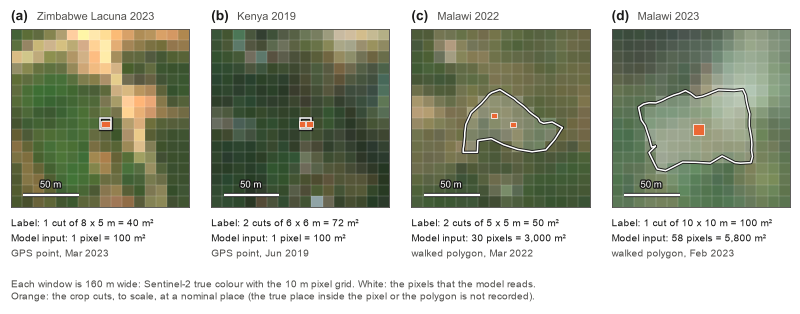

In [12]:
def typical_field(cohort, month, year=None):
    """A field with a clear scene in `month`, near the median yield and (for polygons) the median number of pixels."""
    table = D[cohort]["fields"].assign(y=D[cohort]["y"], pixels=downloads.loc[D[cohort]["y"].index, "field_pixels"])
    if year:
        table = table[table.season_year == year]
    shots = scenes[(scenes.month == month) & scenes.obs_id.isin(table.index)]
    clear = set(shots[shots.tile_cloud_cover <= shots.tile_cloud_cover.quantile(0.10)].obs_id)   # scenes of the clearest tiles
    table = table[table.index.isin(clear)]
    rank = (table.y - table.y.median()).abs().rank() + 4 * (table.pixels - table.pixels.median()).abs().rank()
    return rank.sort_values(kind="stable").index[0]


CASES = [("a", "Zimbabwe Lacuna 2023", EXAMPLE, "2023-03"), ("b", "Kenya 2019", typical_field(KENYA, "2019-06", 2019), "2019-06"),
         ("c", "Malawi 2022", typical_field(MALAWI22, "2022-03"), "2022-03"), ("d", "Malawi 2023", typical_field(MALAWI23, "2023-02"), "2023-02")]
HALF = 8                                                    # the window is 16 x 16 pixels = 160 m
S, gap = 1.62, 0.20
fig = plt.figure(figsize=(FULL, S + 1.12))
for k, (letter, name, obs, month) in enumerate(CASES):
    chip = chip_of(obs)
    values = chip.reflectance(month)
    row, col = chip.pixel
    row, col = min(max(row, HALF), 64 - HALF), min(max(col, HALF), 64 - HALF)
    crop = values[:, row - HALF:row + HALF, col - HALF:col + HALF]
    left_m, top_m = chip.extent[0] + 10 * (col - HALF), chip.extent[3] - 10 * (row - HALF)
    ax = inch_axes(fig, 0.06 + k * (S + gap), 0.24, S, S)
    ax.imshow(true_colour(crop), extent=(0, 160, 0, 160), zorder=1)
    for v in range(10, 160, 10):                            # the 10 m pixel grid
        ax.plot([v, v], [0, 160], color=PAPER, linewidth=0.2, alpha=0.55, zorder=2)
        ax.plot([0, 160], [v, v], color=PAPER, linewidth=0.2, alpha=0.55, zorder=2)
    mask = chip.field[row - HALF:row + HALF, col - HALF:col + HALF]
    for r, c in zip(*np.nonzero(mask)):                     # the pixels that the model reads
        ax.add_patch(Rectangle((10 * c, 160 - 10 * (r + 1)), 10, 10, facecolor=PAPER, alpha=0.20, edgecolor="none", zorder=3))
    stroke = [pe.withStroke(linewidth=2.2, foreground=INK)]
    area, cuts = float(labels.at[obs, "cut_area_m2"]), int(labels.at[obs, "n_cuts"])
    side = {40.0: (8, 5), 36.0: (6, 6), 25.0: (5, 5), 100.0: (10, 10)}[area]
    if chip.polygon is None:                                # a GPS point: one pixel
        r, c = np.argwhere(mask)[0]
        px, py = 10 * c, 160 - 10 * (r + 1)
        ax.add_patch(Rectangle((px, py), 10, 10, fill=False, edgecolor=PAPER, linewidth=1.0, zorder=5, path_effects=stroke))
        cx, cy = px + 5, py + 5
        anchor = (px + 5, py)
    else:                                                   # a walked polygon
        xy = np.asarray(chip.polygon.exterior.coords) if chip.polygon.geom_type == "Polygon" else np.asarray(
            max(chip.polygon.geoms, key=lambda g: g.area).exterior.coords)
        ax.plot(xy[:, 0] - left_m, xy[:, 1] - (top_m - 160), color=PAPER, linewidth=1.0, zorder=5, path_effects=stroke)
        centre = chip.polygon.representative_point()
        cx, cy = centre.x - left_m, centre.y - (top_m - 160)
        anchor = (cx, xy[:, 1].min() - (top_m - 160))
    offsets = [(-side[0] / 2, -side[1] / 2)] if cuts == 1 else ([(-side[0] - 0.5, -side[1] / 2), (0.5, -side[1] / 2)] if chip.polygon is None
                                                               else [(-side[0] - 6, -side[1] / 2 + 4), (6, -side[1] / 2 - 4)])
    for dx, dy in offsets:                                  # the crop cuts, to scale; their true place is not recorded
        ax.add_patch(Rectangle((cx + dx, cy + dy), *side, facecolor=ORANGE, edgecolor=PAPER, linewidth=0.5, zorder=6))
    ax.set_xlim(0, 160)
    ax.set_ylim(0, 160)
    plain(ax)
    scalebar_m(ax, 50, "50 m", x=0.07, y=0.07)
    panel_title(ax, letter, name)
    pixels = int(chip.field.sum())
    kind = "GPS point" if chip.polygon is None else "walked polygon"
    lines = [f"Label: {cuts} cut{'s' if cuts > 1 else ''} of {side[0]} x {side[1]} m = {area * cuts:.0f} m²",
             f"Model input: {pixels} pixel{'s' if pixels > 1 else ''} = {100 * pixels:,} m²",
             f"{kind}, {MONTH_NAME[int(month[5:])]} {month[:4]}"]
    for i, line in enumerate(lines):
        ax.text(0, -0.065 - 0.085 * i, line, transform=ax.transAxes, fontsize=6.5, color=INK if i < 2 else INK2, va="top")
fig.text(0.06 / FULL, 0.004, "Each window is 160 m wide: Sentinel-2 true colour with the 10 m pixel grid. White: the pixels that the model reads.\n"
         "Orange: the crop cuts, to scale, at a nominal place (the true place inside the pixel or the polygon is not recorded).", fontsize=6.5,
         color=INK2, ha="left", va="bottom", linespacing=1.3)
print([(name, obs, int(chip_of(obs).field.sum())) for _, name, obs, _ in CASES])
save(fig, "D07_label_footprints")

### D08. Film strips of neighbours

**What it shows.** Four fields from December to June, as 640 m chips in true colour. Rows 1-2 are the fields with the highest and the lowest yield of one 2 km group; rows 3-4 are the same for a second group. Right: the GCVI of the labelled pixel.

**Read it like this.** The white box is the labelled pixel. A hatched tile is a month without a clear scene. An orange bar on top of a chip means that the scene is later than the crop cut.

**Take-away.** Neighbours with 7.7 and 0.8 t/ha look almost the same from space. To tell the fields of one village apart is the hard part of the task. The season is clear in every row: green from December to March, dry from April.

**Source.** The data v2 chips and `labels_v2`. The fields are picked by a rule (highest and lowest yield of the group, among fields with enough clear months), not by eye.

**Caption draft.** Monthly Sentinel-2 chips (640 m, true colour, one fixed stretch) of the fields with the highest and the lowest yield in two 2 km groups, with the GCVI of the labelled pixel. White box: the labelled pixel. Orange bar: scene later than the crop cut.

**Caution.** Four fields are an example, not evidence. The evidence is in Part 3.

[('zimbabwe:5ae92828-fae7-4154-bd72-39ffecc23c57', '12', np.float64(7.7), '2023-05-29'), ('zimbabwe:78c3dc47-5f2a-47f8-b9e9-081079072162', '12', np.float64(0.78), '2023-05-27'), ('zimbabwe:19b3415c-a2fa-44ae-87c0-9c673ba23470', '16', np.float64(8.12), '2023-05-03'), ('zimbabwe:c2695371-5be4-4e62-af1d-b7d4e3baccd7', '16', np.float64(0.34), '2023-06-01')]


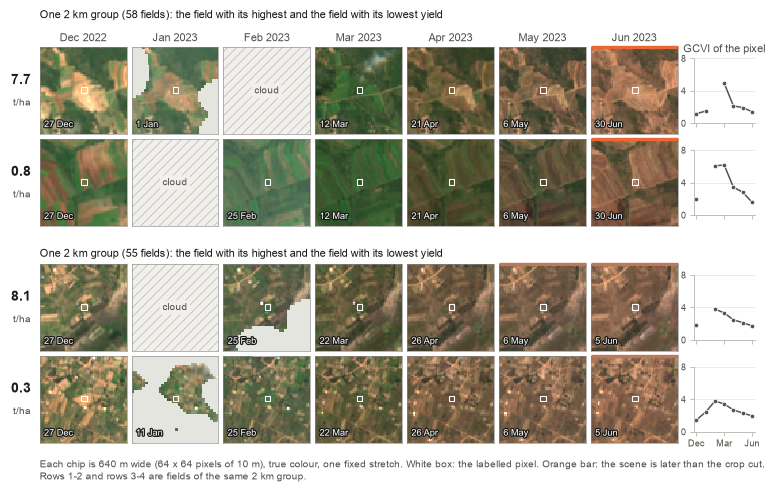

In [13]:
d = D[LACUNA]
fields = d["fields"].assign(y=d["y"])
MONTHS = ["2022-12", "2023-01", "2023-02", "2023-03", "2023-04", "2023-05", "2023-06"]
state = coverage[coverage.cohort == LACUNA].pivot(index="obs_id", columns="month", values="coverage_state")
complete = state.index[(state[["2022-12", "2023-03", "2023-04", "2023-05", "2023-06"]] == "clear").all(axis=1)
                       & (state[["2023-01", "2023-02"]] == "clear").any(axis=1)]


def extremes(group_id):
    """The field with the highest and the field with the lowest yield of one 2 km group (fields with enough clear months)."""
    members = fields[(fields.group_id == group_id) & fields.index.isin(complete)].sort_values("y")
    return [members.index[-1], members.index[0]]


ROWS = [(obs, g) for g in ("12", "16") for obs in extremes(g)]     # group 12 holds the example field; group 16 is a second village
gcvi = d["cube"]["gcvi"]
C, GAP, LEFT, TOP = 0.79, 0.045, 0.62, 0.52
fig = plt.figure(figsize=(FULL, TOP + 4 * C + 3 * GAP + 0.30 + 0.42))
for r, (obs, group_id) in enumerate(ROWS):
    chip = chip_of(obs)
    top = TOP + r * (C + GAP) + (0.30 if r >= 2 else 0)
    row, col = chip.pixel
    cut = pd.Timestamp(labels.at[obs, "obs_date"])
    for c, month in enumerate(MONTHS):
        ax = inch_axes(fig, LEFT + c * (C + GAP), top, C, C)
        values = chip.reflectance(month)
        if values is None:                                   # a cloudy month: no accepted scene
            ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor="#f1f0ec", edgecolor="#bdbcb3", hatch="////", linewidth=0))
            ax.text(0.5, 0.5, "cloud", transform=ax.transAxes, ha="center", va="center", fontsize=6.5, color=INK2,
                    bbox={"boxstyle": "round,pad=0.25", "facecolor": "#f1f0ec", "edgecolor": "none"})
        else:
            ax.imshow(true_colour(values), extent=(0, 64, 0, 64))
            ax.add_patch(Rectangle((col - 1.5, 64 - row - 2.5), 4, 4, fill=False, edgecolor=PAPER, linewidth=0.7))
            day = chip.day(month)
            ax.text(0.05, 0.06, f"{day.day} {MONTH_NAME[day.month]}", transform=ax.transAxes, fontsize=6, color=PAPER, va="bottom",
                    path_effects=halo(1.6, INK))
            if day > cut.date():                             # this scene is later than the crop cut
                ax.plot([0, 1], [1, 1], transform=ax.transAxes, color=ORANGE, linewidth=2.2, solid_capstyle="butt", clip_on=False)
        plain(ax, frame="#8a8985", width=0.4)
        if r == 0:
            ax.set_title(f"{MONTH_NAME[int(month[5:])]} {month[:4]}", fontsize=7, fontweight="normal", color=INK2, pad=4, loc="center")
        if c == 0:
            ax.text(-0.10, 0.62, f"{fields.at[obs, 'y']:.1f}", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="center")
            ax.text(-0.10, 0.36, "t/ha", transform=ax.transAxes, fontsize=6.5, color=INK2, ha="right", va="center")
    spark = inch_axes(fig, LEFT + 7 * (C + GAP) + 0.10, top + 0.10, FULL - (LEFT + 7 * (C + GAP) + 0.10) - 0.08, C - 0.20)
    series = gcvi.loc[obs].reindex(range(2, 9))
    spark.plot(series.index, series.to_numpy(), color=NEUTRAL, linewidth=1.0, marker="o", markersize=3, markerfacecolor=NEUTRAL,
               markeredgecolor=PAPER, markeredgewidth=0.5, clip_on=False)      # the line breaks at a month without a clear scene
    spark.set_xlim(1.7, 8.3)
    spark.set_ylim(0, 8)
    spark.set_xticks([2, 5, 8], ["Dec", "Mar", "Jun"] if r == 3 else [])
    spark.set_yticks([0, 4, 8])
    spark.tick_params(labelsize=6)
    hgrid(spark)
    if r == 0:
        spark.set_title("GCVI of the pixel", fontsize=7, fontweight="normal", color=INK2, pad=4, loc="center")
    if r in (0, 2):
        size = int((fields.group_id == group_id).sum())
        fig.text(LEFT / FULL, 1 - (top - 0.045 - (0.20 if r == 0 else 0.0)) / fig.get_size_inches()[1],
                 f"One 2 km group ({size} fields): the field with its highest and the field with its lowest yield", fontsize=7,
                 color=INK, ha="left", va="bottom")
fig.text(LEFT / FULL, 0.012, "Each chip is 640 m wide (64 x 64 pixels of 10 m), true colour, one fixed stretch. White box: the labelled pixel. "
         "Orange bar: the scene is later than the crop cut.\nRows 1-2 and rows 3-4 are fields of the same 2 km group.", fontsize=6.5, color=INK2,
         ha="left", va="bottom", linespacing=1.3)
print([(obs, g, round(fields.at[obs, "y"], 2), str(labels.at[obs, "obs_date"])[:10]) for obs, g in ROWS])
save(fig, "D08_film_strips")

### D09. Availability barcode

**What it shows.** (a) The share of the 1,880 Lacuna fields with a clear scene in each month. (b) One row for each field and one column for each month: clear before the crop cut, clear after the crop cut, cloudy, or no scene in the catalogue. The rows are sorted by the day of the crop cut (orange line). (c) The rank correlation of the month's GCVI with yield, for all fields, between 2 km groups and inside groups.

**Read it like this.** Read one month from top to bottom through the three panels.

**Take-away.** October and November have no scene. February has the strongest signal and the most cloud (76 % clear). Of the 12,215 clear field-months, 32 % are later than the crop cut, so the models estimate yield at the end of the season; they do not forecast it.

**Source.** Views `monthly` and `scenes` of the v2 database, `labels_v2.obs_date`, `experiments/stepup/gcvi_months.csv` (folds 1-4).

**Caption draft.** Zimbabwe Lacuna 2023. (a) Fields with a clear Sentinel-2 scene by month. (b) State of each field-month; rows sorted by the day of the crop cut (line). (c) Spearman correlation of monthly GCVI with yield: all fields, between 2 km groups, inside groups.

**Caution.** The crop-cut date is used only to draw this figure. It is never a model input.

clear field-months: 12,215; after the crop cut: 32.2 %; clear share by month: {'Oct': 0.0, 'Nov': 0.0, 'Dec': 0.976, 'Jan': 0.824, 'Feb': 0.756, 'Mar': 0.941, 'Apr': 1.0, 'May': 1.0, 'Jun': 1.0}


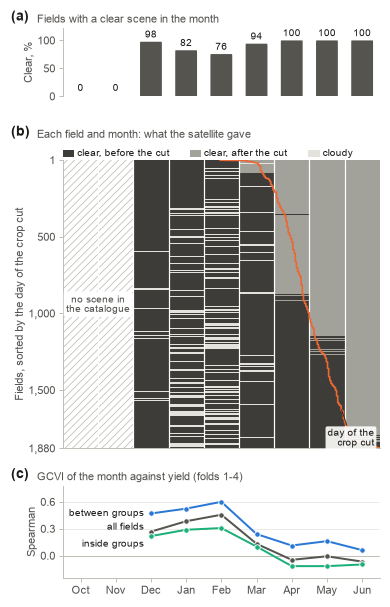

In [14]:
d = D[LACUNA]
ids = d["y"].index
MONTHS = ["2022-10", "2022-11", "2022-12", "2023-01", "2023-02", "2023-03", "2023-04", "2023-05", "2023-06"]
state = coverage[coverage.cohort == LACUNA].pivot(index="obs_id", columns="month", values="coverage_state").loc[ids, MONTHS]
shot = scenes[scenes.obs_id.isin(ids)].pivot(index="obs_id", columns="month", values="acquired").reindex(index=ids, columns=MONTHS)
cut = pd.to_datetime(labels.loc[ids, "obs_date"])
order = np.argsort(cut.to_numpy(), kind="stable")
# 0 = no scene in the catalogue, 1 = cloudy, 2 = clear and after the crop cut, 3 = clear and before the crop cut
after = shot.apply(lambda column: pd.to_datetime(column) > cut)
code = np.select([state.to_numpy() == "no_scene", state.to_numpy() == "cloudy", after.to_numpy()], [0, 1, 2], default=3)[order]
clear_share = (state == "clear").mean()
share_after = (code == 2).sum() / (code >= 2).sum()
month_start = pd.to_datetime([m + "-01" for m in MONTHS])
cut_x = np.array([(c.year * 12 + c.month) - (2022 * 12 + 10) + (c.day - 1) / c.days_in_month - 0.5 for c in cut.iloc[order]])
months_lacuna = gcvi_months[gcvi_months.cohort == LACUNA].set_index("k")

fig = plt.figure(figsize=(COL, 5.62))
LEFT, WIDTH = 0.52, COL - 0.52 - 0.10
names = [MONTH_NAME[int(m[5:])] for m in MONTHS]
# (a) share of the fields with a clear scene
ax_a = inch_axes(fig, LEFT, 0.26, WIDTH, 0.62)
for k, value in enumerate(clear_share):
    if value > 0:
        rounded_bar(ax_a, 0, value, k, 0.62, NEUTRAL, horizontal=False)
        ax_a.text(k, value + 0.04, f"{100 * value:.0f}", ha="center", va="bottom", fontsize=6.3, color=INK)
    else:
        ax_a.text(k, 0.06, "0", ha="center", va="bottom", fontsize=6.3, color=INK)
ax_a.set_xlim(-0.5, 8.5)
ax_a.set_ylim(0, 1.22)
ax_a.set_xticks([])
ax_a.set_yticks([0, 0.5, 1], ["0", "50", "100"])
ax_a.set_ylabel("Clear, %", labelpad=2)
ax_a.spines["bottom"].set_visible(False)
panel(ax_a, "a", dx=-34, dy=3)
ax_a.annotate("Fields with a clear scene in the month", xy=(0, 1), xycoords="axes fraction", xytext=(-17, 3.6), textcoords="offset points",
              fontsize=7.2, color=INK2)

# (b) one row for each field, sorted by the day of its crop cut
ax_b = inch_axes(fig, LEFT, 1.46, WIDTH, 2.62)
SHADES = ListedColormap([PAPER, "#e3e2dc", "#a3a29a", "#3d3c39"])
ax_b.imshow(code, cmap=SHADES, vmin=0, vmax=3, aspect="auto", interpolation="nearest", extent=(-0.5, 8.5, len(ids), 0))
ax_b.add_patch(Rectangle((-0.5, 0), 2, len(ids), facecolor="none", edgecolor="#bdbcb3", hatch="/////", linewidth=0))
for k in range(1, 9):
    ax_b.plot([k - 0.5, k - 0.5], [0, len(ids)], color=PAPER, linewidth=0.8)
ax_b.plot(cut_x, np.arange(len(ids)) + 0.5, color=ORANGE, linewidth=1.1)
ax_b.set_xlim(-0.5, 8.5)
ax_b.set_ylim(len(ids), 0)
ax_b.set_xticks([])
ax_b.set_yticks([0, 500, 1000, 1500, len(ids)], ["1", "500", "1,000", "1,500", f"{len(ids):,}"])
ax_b.set_ylabel("Fields, sorted by the day of the crop cut", labelpad=2)
for side in ("top", "right"):
    ax_b.spines[side].set_visible(False)
ax_b.text(0.5, 0.5 * len(ids), "no scene in\nthe catalogue", ha="center", va="center", fontsize=6.3, color=INK2, linespacing=1.15,
          bbox={"boxstyle": "round,pad=0.25", "facecolor": PAPER, "edgecolor": "none"})
ax_b.annotate("day of the\ncrop cut", xy=(cut_x[int(0.86 * len(ids))], 0.86 * len(ids)), xytext=(8.35, 0.965 * len(ids)), fontsize=6.3, color=INK,
              ha="right", va="center", linespacing=1.1, arrowprops={"arrowstyle": "-", "color": INK, "linewidth": 0.5, "shrinkA": 1, "shrinkB": 1},
              bbox={"boxstyle": "round,pad=0.2", "facecolor": PAPER, "edgecolor": "none", "alpha": 0.9})
panel(ax_b, "b", dx=-34, dy=14)
ax_b.annotate("Each field and month: what the satellite gave", xy=(0, 1), xycoords="axes fraction", xytext=(-17, 14.6),
              textcoords="offset points", fontsize=7.2, color=INK2)
for x, colour, text in ((0.0, "#3d3c39", "clear, before the cut"), (0.40, "#a3a29a", "clear, after the cut"), (0.775, "#e3e2dc", "cloudy")):
    ax_b.add_patch(Rectangle((x, 1.012), 0.035, 0.022, transform=ax_b.transAxes, facecolor=colour, edgecolor="none", clip_on=False))
    ax_b.text(x + 0.045, 1.023, text, transform=ax_b.transAxes, fontsize=6.3, color=INK, va="center")

# (c) how much the GCVI of each month tells about the yield
ax_c = inch_axes(fig, LEFT, 4.42, WIDTH, 0.84)
ax_c.axhline(0, color=AXIS, linewidth=0.6)
for column, colour, text, dy in (("all", NEUTRAL, "all fields", 0.05), ("between_clusters", VILLAGE, "between groups", 0.0),
                                 ("inside_clusters", FIELD, "inside groups", -0.09)):
    ax_c.plot(months_lacuna.index, months_lacuna[column], color=colour, linewidth=1.3, marker="o", markersize=3.6, markerfacecolor=colour,
              markeredgecolor=PAPER, markeredgewidth=0.6)
    ax_c.text(1.80, months_lacuna.loc[2, column] + dy, text, fontsize=6.3, color=INK, ha="right", va="center")
ax_c.set_xlim(-0.5, 8.5)
ax_c.set_ylim(-0.25, 0.78)
ax_c.set_xticks(range(9), names)
ax_c.set_yticks([0, 0.3, 0.6])
ax_c.set_ylabel("Spearman", labelpad=2)
hgrid(ax_c)
panel(ax_c, "c", dx=-34, dy=3)
ax_c.annotate("GCVI of the month against yield (folds 1-4)", xy=(0, 1), xycoords="axes fraction", xytext=(-17, 3.6),
              textcoords="offset points", fontsize=7.2, color=INK2)
print(f"clear field-months: {(code >= 2).sum():,}; after the crop cut: {100 * share_after:.1f} %; clear share by month:",
      {n: round(float(v), 3) for n, v in zip(names, clear_share)})
save(fig, "D09_availability_barcode")

### D10. Where in the light the yield lives

**What it shows.** The rank correlation of each band and each index with yield, month by month: (a) between the 2 km groups (group means), (b) inside the groups (each value minus its group mean; groups with 3 or more fields).

**Read it like this.** Red is a positive correlation, blue a negative one. A number is printed where the value is 0.3 or more. Rows: the 10 bands in wavelength order, then the 5 indices.

**Take-away.** Between groups the signal is strong from December to February (up to 0.62): high-yield villages are darker in the visible and short-wave bands and greener. Inside a group the same pattern is there but weak (0.31 at most), and it is gone after March.

**Source.** View `monthly` of the v2 database, folds 1-4 (1,504 fields). The GCVI row is checked against `experiments/stepup/gcvi_months.csv`.

**Caption draft.** Spearman correlation of monthly band values and vegetation indices with yield, Zimbabwe Lacuna 2023, folds 1-4. (a) Between 2 km groups. (b) Inside 2 km groups.

**Caution.** 210 cells and no test: read the pattern, not one cell. The bands are strongly correlated with each other.

strongest between: ndvi740 0.62 | strongest inside: gcvi 0.31


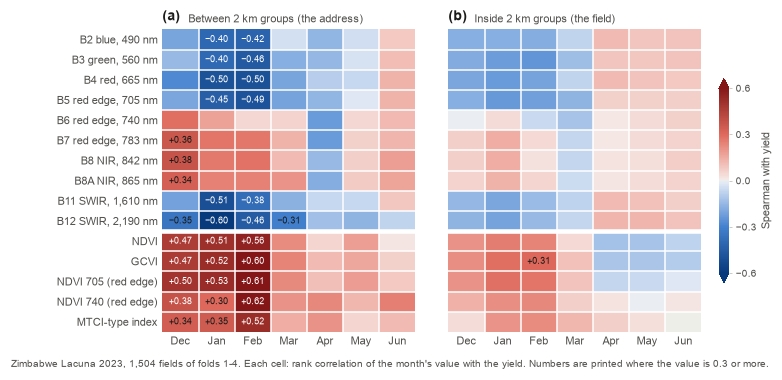

In [15]:
d = D[LACUNA]
dev = d["dev"]                                             # folds 1-4 only
y_dev = d["y"][dev]
groups_dev = cluster_year(d["fields"][dev])
ROWS = BANDS + ["ndvi", "gcvi", "ndvi705", "ndvi740", "mtci"]
ROW_NAME = {**{b: f"{BAND_NAME[b]}, {BAND_NM[b]:,} nm" for b in BANDS}, "ndvi": "NDVI", "gcvi": "GCVI", "ndvi705": "NDVI 705 (red edge)",
            "ndvi740": "NDVI 740 (red edge)", "mtci": "MTCI-type index"}
ks = sorted(d["calendar"])
between, inside = np.full((len(ROWS), len(ks)), np.nan), np.full((len(ROWS), len(ks)), np.nan)
for r, name in enumerate(ROWS):
    cube = d["cube"][name][dev]
    for c, k in enumerate(ks):
        have = cube[k].notna().to_numpy()
        x, y, g = cube[k].to_numpy()[have], y_dev.to_numpy()[have], groups_dev[have]
        means = pd.DataFrame({"x": x, "y": y}).groupby(g).mean()
        between[r, c] = spearman(means.y.to_numpy(), means.x.to_numpy())
        keep = in_large_clusters(g, 3)                      # inside a group: only groups with 3 or more fields in this month
        inside[r, c] = spearman(centred(y[keep], g[keep]), centred(x[keep], g[keep]))
norm = Normalize(-0.6, 0.6)
fig = plt.figure(figsize=(FULL, 3.55))
W, H, LEFT = 2.30, 2.75, 1.52
for letter, title, values, left in (("a", "Between 2 km groups (the address)", between, LEFT), ("b", "Inside 2 km groups (the field)", inside, LEFT + W + 0.30)):
    ax = inch_axes(fig, left, 0.42, W, H)
    ax.imshow(values, cmap=DIVERGE, norm=norm, aspect="auto")
    for edge in np.arange(0.5, len(ks) - 0.5):               # a thin gap in the page colour between the cells
        ax.plot([edge, edge], [-0.5, len(ROWS) - 0.5], color=PAPER, linewidth=1.0)
    for edge in np.arange(0.5, len(ROWS) - 0.5):
        ax.plot([-0.5, len(ks) - 0.5], [edge, edge], color=PAPER, linewidth=3.0 if edge == len(BANDS) - 0.5 else 1.0)
    for r in range(len(ROWS)):
        for c in range(len(ks)):
            if abs(values[r, c]) >= 0.3:                    # print only the strong cells
                ax.text(c, r, f"{values[r, c]:+.2f}".replace("-", "−"), ha="center", va="center", fontsize=6,
                        color=PAPER if abs(values[r, c]) > 0.38 else INK)
    ax.set_xticks(range(len(ks)), [MONTH_NAME[d["calendar"][k]] for k in ks])
    ax.set_yticks(range(len(ROWS)), [ROW_NAME[n] for n in ROWS] if letter == "a" else [])
    ax.tick_params(length=0, pad=3)
    ax.set_xlim(-0.5, len(ks) - 0.5)
    ax.set_ylim(len(ROWS) - 0.5, -0.5)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    panel(ax, letter, dy=4)
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(17, 4.6), textcoords="offset points", fontsize=7.2, color=INK2)
cax = inch_axes(fig, LEFT + 2 * W + 0.30 + 0.16, 0.42 + 0.45, 0.09, H - 0.9)
colorbar(fig, mpl.cm.ScalarMappable(norm, DIVERGE), cax=cax, extend="both", ticks=[-0.6, -0.3, 0, 0.3, 0.6], label="Spearman with yield")
fig.text(0.02, 0.012, f"Zimbabwe Lacuna 2023, {int(dev.sum()):,} fields of folds 1-4. Each cell: rank correlation of the month's value with the yield. "
         "Numbers are printed where the value is 0.3 or more.", fontsize=6.5, color=INK2, ha="left", va="bottom")
print("strongest between:", ROWS[np.unravel_index(np.nanargmax(np.abs(between)), between.shape)[0]], round(float(np.nanmax(np.abs(between))), 2),
      "| strongest inside:", ROWS[np.unravel_index(np.nanargmax(np.abs(inside)), inside.shape)[0]], round(float(np.nanmax(np.abs(inside))), 2))
gcvi_row = ROWS.index("gcvi")
check = gcvi_months[gcvi_months.cohort == LACUNA].set_index("k")
assert np.allclose(between[gcvi_row], check.loc[ks, "between_clusters"], atol=1e-9), "the GCVI row differs from experiments/stepup"
assert np.allclose(inside[gcvi_row], check.loc[ks, "inside_clusters"], atol=1e-9), "the GCVI row differs from experiments/stepup"
save(fig, "D10_light_and_yield")

### D11. Yield distributions and label noise

**What it shows.** (a) The yield distribution of each data set and season, with the median. (b) Zimbabwe 2024: the yield of box 1 against box 2 of the same field. (c) Malawi 2023: the yield of two cuts in the same field.

**Read it like this.** In (b) and (c) a point on the dashed line is a field where both measurements agree.

**Take-away.** All labels are right-skewed. Two measurements in one field agree at r = 0.87 (Zimbabwe 2024, 2,416 fields) and r = 0.90 (Malawi 2023, 253 fields), so the label itself has noise and no model can explain all of the variance.

**Source.** `labels_v2` (`yield_kg_ha`, `cut1_kg_ha`, `cut2_kg_ha`), model rows.

**Caption draft.** (a) Yield of each data set (kernel density, mirrored at zero; mark: median). (b), (c) Two crop-cut measurements in the same field: Zimbabwe 2024 and Malawi 2023.

**Caution.** Never compare t/ha between data sets: cut size and moisture basis differ. Lacuna and Kenya have one value for each field, so their label noise is not known; do not use 0.87 as a ceiling for Lacuna.

zimbabwe_2024 two measurements: 2416 r = 0.868 | SD of the difference: 0.52 t/ha
malawi_2023 two measurements: 253 r = 0.903 | SD of the difference: 0.79 t/ha


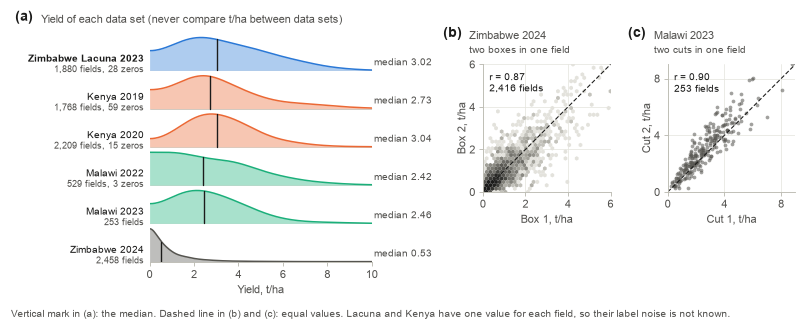

In [16]:
from scipy.stats import gaussian_kde

RIDGES = [(LACUNA, None, "Zimbabwe Lacuna 2023", BLUE), (KENYA, 2019, "Kenya 2019", ORANGE), (KENYA, 2020, "Kenya 2020", ORANGE),
          (MALAWI22, None, "Malawi 2022", AQUA), (MALAWI23, None, "Malawi 2023", AQUA), (ZIM24, None, "Zimbabwe 2024", NEUTRAL)]
grid = np.linspace(0, 10, 400)
fig = plt.figure(figsize=(FULL, 2.95))
ax = inch_axes(fig, 1.30, 0.30, 2.02, 2.10)
for k, (cohort, year, name, colour) in enumerate(RIDGES):
    y = D[cohort]["y"] if year is None else D[cohort]["y"][D[cohort]["fields"].season_year == year]
    density = 2 * gaussian_kde(np.r_[y, -y])(grid)           # mirror at 0, so that no density leaks below zero yield
    base = len(RIDGES) - 1 - k
    height = 0.86 * density / density.max()
    ax.fill_between(grid, base, base + height, color=tint(colour, 0.62), linewidth=0, zorder=2 + k)
    ax.plot(grid, base + height, color=colour, linewidth=1.0, zorder=2 + k)
    ax.plot([0, 10], [base, base], color=AXIS, linewidth=0.5, zorder=1)
    median = float(y.median())
    ax.plot([median, median], [base, base + 0.86 * np.interp(median, grid, density) / density.max()], color=INK, linewidth=0.9, zorder=3 + k)
    ax.text(-0.25, base + 0.30, name, ha="right", va="center", fontsize=6.8, color=INK, fontweight="bold" if cohort == LACUNA else "normal")
    zeros = int((y == 0).sum())
    ax.text(-0.25, base + 0.02, f"{len(y):,} fields" + (f", {zeros} zeros" if zeros else ""), ha="right", va="center", fontsize=6.1, color=INK2)
    ax.text(10.1, base + 0.20, f"median {median:.2f}", ha="left", va="center", fontsize=6.3, color=INK2, clip_on=False)
ax.set_xlim(0, 10)
ax.set_ylim(-0.02, len(RIDGES) + 0.02)
ax.set_yticks([])
ax.set_xticks(range(0, 11, 2))
ax.set_xlabel("Yield, t/ha")
ax.spines["left"].set_visible(False)
panel(ax, "a", dx=-88, dy=5)
ax.annotate("Yield of each data set (never compare t/ha between data sets)", xy=(0, 1), xycoords="axes fraction", xytext=(-71, 5.6),
            textcoords="offset points", fontsize=7.2, color=INK2)

GREYS = LinearSegmentedColormap.from_list("greys", ["#e3e2dc", "#a3a29a", "#55544f", "#1b1b1a"])
S = 1.16
for letter, cohort, title, xlabel, ylabel, left, top in (
        ("b", ZIM24, "Zimbabwe 2024: two boxes in one field", "Box 1, t/ha", "Box 2, t/ha", 4.33, 0.30),
        ("c", MALAWI23, "Malawi 2023: two cuts in one field", "Cut 1, t/ha", "Cut 2, t/ha", 4.33 + S + 0.52, 0.30)):
    rows = labels.loc[D[cohort]["y"].index]
    rows = rows[rows.cut1_kg_ha.notna() & rows.cut2_kg_ha.notna()]
    a, b = rows.cut1_kg_ha.to_numpy() / 1000, rows.cut2_kg_ha.to_numpy() / 1000
    top_value = float(np.ceil(np.quantile(np.r_[a, b], 0.995)))
    panel_ax = inch_axes(fig, left, top + 0.30, S, S)
    if len(a) > 1000:
        panel_ax.hexbin(a, b, gridsize=34, extent=(0, top_value, 0, top_value), cmap=GREYS, norm=mpl.colors.LogNorm(1, 60), mincnt=1,
                        linewidths=0, rasterized=True)
    else:
        panel_ax.scatter(a, b, s=6, c=NEUTRAL, alpha=0.55, linewidths=0, rasterized=True)
    panel_ax.plot([0, top_value], [0, top_value], color=INK, linewidth=0.7, linestyle=(0, (4, 2)))
    panel_ax.set_xlim(0, top_value)
    panel_ax.set_ylim(0, top_value)
    panel_ax.set_aspect("equal")
    ticks = np.arange(0, top_value + 0.1, 2 if top_value <= 8 else 4)
    panel_ax.set_xticks(ticks)
    panel_ax.set_yticks(ticks)
    panel_ax.set_xlabel(xlabel)
    panel_ax.set_ylabel(ylabel, labelpad=1)
    hgrid(panel_ax, "both")
    r = float(np.corrcoef(a, b)[0, 1])
    panel_ax.text(0.05, 0.95, f"r = {r:.2f}\n{len(a):,} fields", transform=panel_ax.transAxes, ha="left", va="top", fontsize=6.8, color=INK,
                  linespacing=1.2)
    panel(panel_ax, letter, dx=-26, dy=16)
    panel_ax.annotate(title.split(": ")[0], xy=(0, 1), xycoords="axes fraction", xytext=(-9, 16.6), textcoords="offset points", fontsize=7.2,
                      color=INK2)
    panel_ax.annotate(title.split(": ")[1], xy=(0, 1), xycoords="axes fraction", xytext=(-9, 7.5), textcoords="offset points", fontsize=6.5,
                      color=INK2)
    print(cohort, "two measurements:", len(a), "r =", round(r, 3), "| SD of the difference:", round(float(np.std(a - b)), 2), "t/ha")
fig.text(0.04 / FULL, 0.012, "Vertical mark in (a): the median. Dashed line in (b) and (c): equal values. Lacuna and Kenya have one value for each "
         "field, so their label noise is not known.", fontsize=6.5, color=INK2, ha="left", va="bottom")
save(fig, "D11_yield_and_label_noise")

### D12. From the survey to the model rows

**What it shows.** (a) How the 3,002 surveyed Lacuna fields become the 1,880 model rows, and how these split into folds 1-4 (1,504) and the held-back fold 0 (376). (b) Where the fields of season 2022, the intercropped or irrigated fields and the model rows are.

**Read it like this.** A dark bar is the fields that stay after a step. The grey bar beside it is the fields that leave.

**Take-away.** The largest step is the crop (733 fields are not maize). The model rows are 63 % of the survey. The fields that leave are spread over the same regions as the fields that stay.

**Source.** `data/audit/summary.csv` (survey, maize and arithmetic check), `labels_v2` (exclusion reasons), split `s1_cc2km`.

**Caption draft.** Zimbabwe Lacuna: from 3,002 surveyed fields to 1,880 model rows (1,504 in folds 1-4 and 376 in the held-back fold). Right: location of the fields that were left out and of the model rows.

[('Surveyed fields', 3002), ('Maize', 2269), ('Yield equals dry weight x 0.25', 2266), ('Season 2023', 2097), ('Grown alone, rain-fed', 1880)] 1504 376


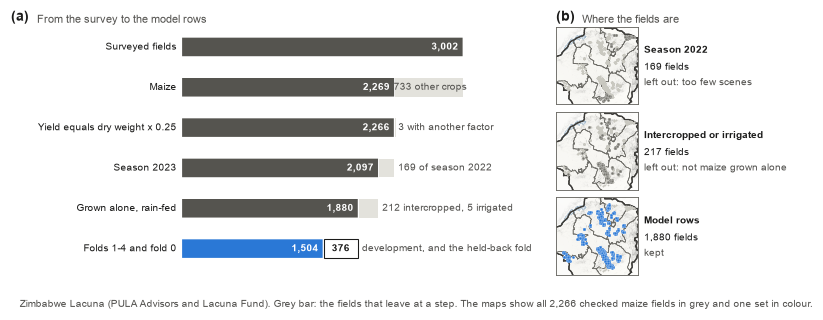

In [17]:
audit = pd.read_csv(REPO / "data" / "audit" / "summary.csv").set_index("dataset").loc["zimbabwe"]
lacuna_rows = labels[labels.cohort == LACUNA]
reason = lacuna_rows.exclusion_reason.value_counts()
folds = D[LACUNA]["fields"].fold
kept = int(lacuna_rows.include_primary.sum())
STEPS = [  # name of the step, fields that stay, text for the fields that leave
    ("Surveyed fields", int(audit.all_source_rows), ""),
    ("Maize", int(audit.maize_records), f"{int(audit.all_source_rows - audit.maize_records):,} other crops"),
    ("Yield equals dry weight x 0.25", int(audit.screened_candidates), f"{int(audit.maize_records - audit.screened_candidates)} with another factor"),
    ("Season 2023", int(audit.screened_candidates) - int(reason["dropped_year_2022_imagery_gap"]),
     f"{int(reason['dropped_year_2022_imagery_gap'])} of season 2022"),
    ("Grown alone, rain-fed", kept, f"{int(reason['lacuna_intercropped'])} intercropped, {int(reason['lacuna_irrigated'])} irrigated"),
]
assert kept == len(D[LACUNA]["y"]) == STEPS[-1][1]
fig = plt.figure(figsize=(FULL, 2.86))
ax = inch_axes(fig, 1.62, 0.26, 2.55, 2.20)
total = STEPS[0][1]
for k, (name, stays, leaves) in enumerate(STEPS):
    ypos = len(STEPS) - k
    before = STEPS[k - 1][1] if k else stays
    rounded_bar(ax, 0, stays, ypos, 0.46, NEUTRAL)
    if before > stays:                                      # the fields that leave at this step
        ax.add_patch(Rectangle((stays + 12, ypos - 0.23), max(before - stays - 12, 14), 0.46, facecolor="#e3e2dc", edgecolor="none"))
        inside_bar = before - stays > 500                  # a wide grey bar holds its own text
        ax.text((stays + before) / 2 + 20 if inside_bar else before + 45, ypos, leaves, fontsize=6.3, color=INK2, va="center",
                ha="center" if inside_bar else "left")
    ax.text(-60, ypos, name, fontsize=6.8, color=INK, va="center", ha="right")
    ax.text(stays - 45, ypos, f"{stays:,}", fontsize=6.6, color=PAPER, va="center", ha="right", fontweight="bold")
dev_n, held_n = int((folds != "0").sum()), int((folds == "0").sum())
rounded_bar(ax, 0, dev_n, 0, 0.46, BLUE)
ax.add_patch(Rectangle((dev_n + 12, -0.23), held_n - 12, 0.46, facecolor=PAPER, edgecolor=INK, linewidth=0.7))
ax.text(-60, 0, "Folds 1-4 and fold 0", fontsize=6.8, color=INK, va="center", ha="right")
ax.text(dev_n - 45, 0, f"{dev_n:,}", fontsize=6.6, color=PAPER, va="center", ha="right", fontweight="bold")
ax.text(dev_n + held_n / 2 + 6, 0, f"{held_n}", fontsize=6.6, color=INK, va="center", ha="center", fontweight="bold")
ax.text(kept + 45, 0, "development, and the held-back fold", fontsize=6.3, color=INK2, va="center", ha="left")
ax.set_xlim(0, total)
ax.set_ylim(-0.5, len(STEPS) + 0.5)
ax.axis("off")
panel(ax, "a", dx=-112, dy=2)
ax.annotate("From the survey to the model rows", xy=(0, 1), xycoords="axes fraction", xytext=(-95, 2.6), textcoords="offset points",
            fontsize=7.2, color=INK2)

EXTENT = (26.7, 32.9, -21.5, -15.9)
width = 0.74
height = map_height(EXTENT, width)
MAPS = [("Season 2022", "left out: too few scenes", lacuna_rows[lacuna_rows.exclusion_reason == "dropped_year_2022_imagery_gap"], "#77766f"),
        ("Intercropped or irrigated", "left out: not maize grown alone", lacuna_rows[lacuna_rows.exclusion_reason.isin(["lacuna_intercropped", "lacuna_irrigated"])], "#77766f"),
        ("Model rows", "kept", lacuna_rows[lacuna_rows.include_primary], BLUE)]
for k, (title, note, rows, colour) in enumerate(MAPS):
    axm = inch_axes(fig, 5.02, 0.26 + k * (height + 0.07), width, height)
    basemap(axm, "zimbabwe", EXTENT, focus=["ZWE"], ticks=False, rivers=False, relief_gain=0.45)
    axm.scatter(lacuna_rows.lon, lacuna_rows.lat, s=1.2, c=NEUTRAL_LIGHT, linewidths=0, zorder=9)
    axm.scatter(rows.lon, rows.lat, s=3.5, c=colour, edgecolors=PAPER, linewidths=0.12, zorder=10)
    axm.text(1.08, 0.70, title, transform=axm.transAxes, fontsize=6.8, color=INK, va="center", fontweight="bold")
    axm.text(1.08, 0.48, f"{len(rows):,} fields", transform=axm.transAxes, fontsize=6.6, color=INK, va="center")
    axm.text(1.08, 0.28, note, transform=axm.transAxes, fontsize=6.3, color=INK2, va="center")
    if k == 0:
        panel(axm, "b", dy=2)
        axm.annotate("Where the fields are", xy=(0, 1), xycoords="axes fraction", xytext=(17, 2.6), textcoords="offset points",
                     fontsize=7.2, color=INK2)
fig.text(0.02, 0.012, "Zimbabwe Lacuna (PULA Advisors and Lacuna Fund). Grey bar: the fields that leave at a step. The maps show all 2,266 checked maize "
         "fields in grey and one set in colour.", fontsize=6.5, color=INK2, ha="left", va="bottom")
print([(name, stays) for name, stays, _ in STEPS], dev_n, held_n)
save(fig, "D12_data_funnel")

### D13. Points that never look green

**What it shows.** (a) The highest NDVI of the season at the labelled pixel of each Lacuna field. (b) Twenty of the fields that never pass NDVI 0.5, at their greenest month: 200 m round the point, with the yield in the corner. (c) The yield of these fields against the yield of the other fields.

**Read it like this.** The white box in (b) is the labelled pixel.

**Take-away.** 174 of 1,880 fields (9 %) never pass NDVI 0.5. Many of their points lie on bare soil, a track or a yard. Their median yield is 1.6 t/ha against 3.2 t/ha, so some of them are real poor crops and not only wrong points.

**Source.** `ndvi_season_max` of the v2 database, the data v2 chips. The twenty fields are a random draw with a fixed seed, not the worst cases.

**Caption draft.** (a) Season-maximum NDVI at the labelled pixel, Zimbabwe Lacuna 2023. (b) Twenty randomly drawn fields with a maximum below 0.5 (200 m windows at the greenest month; yield in t/ha). (c) Yield of these fields and of the other fields.

**Caution.** "Likely off the crop" is a guess from the image. The data cannot separate a wrong point from a failed crop.

never above NDVI 0.5: 174 of 1880 fields = 9.3 %; median yield 1.61 against 3.17 t/ha


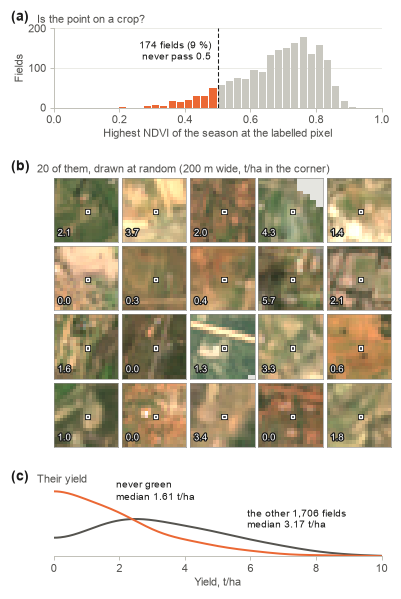

In [18]:
from scipy.stats import gaussian_kde

d = D[LACUNA]
peak = d["X_a1"]["ndvi_season_max"]
THRESHOLD = 0.5
never = peak < THRESHOLD
greenest = d["cube"]["ndvi"].idxmax(axis=1)                 # month of the season (0 = October 2022) with the highest NDVI
sample = pd.Series(never[never].index).sample(20, random_state=20261029).tolist()   # a seeded random draw, not the worst cases
fig = plt.figure(figsize=(COL, 4.85))
# (a) the highest NDVI of the season
ax_a = inch_axes(fig, 0.42, 0.26, COL - 0.52, 0.72)
bins = np.linspace(0, 1, 41)
counts, _ = np.histogram(peak, bins)
ax_a.bar(bins[:-1], counts, width=np.diff(bins) * 0.86, align="edge", color=np.where(bins[:-1] < THRESHOLD, ORANGE, NEUTRAL_LIGHT), linewidth=0)
ax_a.axvline(THRESHOLD, color=INK, linewidth=0.7, linestyle=(0, (4, 2)))
ax_a.text(THRESHOLD - 0.02, counts.max() * 0.80, f"{int(never.sum())} fields ({100 * never.mean():.0f} %)\nnever pass {THRESHOLD}", ha="right",
          va="center", fontsize=6.5, color=INK, linespacing=1.2)
ax_a.set_xlim(0, 1)
ax_a.set_xlabel("Highest NDVI of the season at the labelled pixel", labelpad=2)
ax_a.set_ylabel("Fields", labelpad=2)
ax_a.set_yticks([0, 100, 200])
hgrid(ax_a)
panel(ax_a, "a", dx=-28, dy=3)
ax_a.annotate("Is the point on a crop?", xy=(0, 1), xycoords="axes fraction", xytext=(-11, 3.6), textcoords="offset points", fontsize=7.2,
              color=INK2)

# (b) twenty of these fields at their greenest month: 200 m round the point
C, GAP, TOP = 0.585, 0.035, 1.62
for k, obs in enumerate(sample):
    chip = chip_of(obs)
    month = (pd.Period("2022-10", "M") + int(greenest[obs])).strftime("%Y-%m")
    values = chip.reflectance(month)
    row, col = chip.pixel
    r0, c0 = min(max(row - 10, 0), 44), min(max(col - 10, 0), 44)
    ax = inch_axes(fig, 0.42 + (k % 5) * (C + GAP), TOP + (k // 5) * (C + GAP), C, C)
    ax.imshow(true_colour(values[:, r0:r0 + 20, c0:c0 + 20]), extent=(0, 20, 0, 20))
    ax.add_patch(Rectangle((col - c0, 20 - (row - r0) - 1), 1, 1, fill=False, edgecolor=PAPER, linewidth=0.9,
                           path_effects=[pe.withStroke(linewidth=1.9, foreground=INK)]))
    ax.text(0.06, 0.07, f"{d['y'][obs]:.1f}", transform=ax.transAxes, fontsize=6.2, color=PAPER, va="bottom", path_effects=halo(1.6, INK))
    plain(ax, frame="#8a8985", width=0.4)
    if k == 0:
        panel(ax, "b", dx=-28, dy=3)
        ax.annotate("20 of them, drawn at random (200 m wide, t/ha in the corner)", xy=(0, 1), xycoords="axes fraction",
                    xytext=(-11, 3.6), textcoords="offset points", fontsize=7.2, color=INK2)

# (c) their yield against the yield of the other fields
ax_c = inch_axes(fig, 0.42, TOP + 4 * (C + GAP) + 0.34, COL - 0.52, 0.62)
grid = np.linspace(0, 10, 300)
for mask, colour, text, xy in ((~never, NEUTRAL, f"the other {int((~never).sum()):,} fields", (5.9, 0.19)), (never, ORANGE, "never green", (1.9, 0.33))):
    y = d["y"][mask]
    ax_c.plot(grid, 2 * gaussian_kde(np.r_[y, -y])(grid), color=colour, linewidth=1.3)
    ax_c.text(*xy, f"{text}\nmedian {y.median():.2f} t/ha", fontsize=6.3, color=INK, va="center", linespacing=1.15)
ax_c.set_xlim(0, 10)
ax_c.set_ylim(0, None)
ax_c.set_yticks([])
ax_c.spines["left"].set_visible(False)
ax_c.set_xlabel("Yield, t/ha", labelpad=2)
panel(ax_c, "c", dx=-28, dy=3)
ax_c.annotate("Their yield", xy=(0, 1), xycoords="axes fraction", xytext=(-11, 3.6), textcoords="offset points", fontsize=7.2, color=INK2)
print(f"never above NDVI {THRESHOLD}: {int(never.sum())} of {len(never)} fields = {100 * never.mean():.1f} %; "
      f"median yield {d['y'][never].median():.2f} against {d['y'][~never].median():.2f} t/ha")
save(fig, "D13_never_green")

### D14. The light of a field: spectrum and season

**What it shows.** The 1,880 Lacuna fields in three groups of equal size by yield. (a) The median reflectance in the 10 Sentinel-2 bands in February. (b) GCVI by month. (c) The short-wave infrared band B12 by month.

**Read it like this.** Pale green is the low-yield third, deep green the high-yield third. In (b) and (c) the line is the median and the band holds the middle half of the fields.

**Take-away.** High-yield fields reflect less visible and short-wave light and are greener in January and February. From April the three groups are the same. The groups overlap a lot in every month.

**Source.** View `monthly` of the v2 database (clear months only), `labels_v2`.

**Caption draft.** Zimbabwe Lacuna 2023 by yield third. (a) Median reflectance in the ten Sentinel-2 bands in February. (b) GCVI and (c) band B12 by month (median and interquartile range).

**Caution.** The thirds mix villages and fields, so most of the gap between the lines is the gap between villages (see D10).

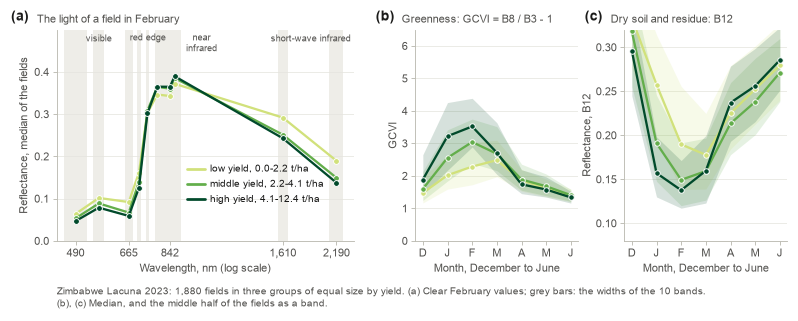

In [19]:
d = D[LACUNA]
y = d["y"]
tercile = pd.qcut(y, 3, labels=["low", "middle", "high"])
SHADES = {"low": YIELD(0.22), "middle": YIELD(0.55), "high": YIELD(0.93)}       # one ordered family: pale to deep green
cuts = y.groupby(tercile, observed=True).agg(["min", "max"])
names = {t: f"{t} yield, {cuts.loc[t, 'min']:.1f}-{cuts.loc[t, 'max']:.1f} t/ha" for t in SHADES}
ks = sorted(d["calendar"])
month_names = [MONTH_NAME[d["calendar"][k]] for k in ks]
FEB = next(k for k in ks if d["calendar"][k] == 2)

fig = plt.figure(figsize=(FULL, 2.86))
# (a) the spectrum of the labelled pixel in February
ax_a = inch_axes(fig, 0.46, 0.30, 2.70, 1.92)
for band in BANDS:                                          # the width of each Sentinel-2 band
    ax_a.axvspan(BAND_NM[band] - BAND_WIDTH_NM[band] / 2, BAND_NM[band] + BAND_WIDTH_NM[band] / 2, color="#eeede8", linewidth=0, zorder=0)
wavelengths = [BAND_NM[b] for b in BANDS]
for t, colour in SHADES.items():
    rows = tercile.index[tercile == t]
    spectrum = [d["cube"][b].loc[rows, FEB].median() for b in BANDS]
    ax_a.plot(wavelengths, spectrum, color=colour, linewidth=1.5, marker="o", markersize=3.8, markerfacecolor=colour, markeredgecolor=PAPER,
              markeredgewidth=0.6, zorder=3)
ax_a.set_xscale("log")
ax_a.set_xlim(440, 2420)
ax_a.set_ylim(0, 0.50)
ax_a.set_xticks([490, 665, 842, 1610, 2190], ["490", "665", "842", "1,610", "2,190"])
ax_a.minorticks_off()
ax_a.set_yticks([0, 0.1, 0.2, 0.3, 0.4])
ax_a.set_xlabel("Wavelength, nm (log scale)")
ax_a.set_ylabel("Reflectance, median of the fields")
hgrid(ax_a)
for text, x in (("visible", 560), ("red edge", 742), ("near\ninfrared", 1010), ("short-wave infrared", 1890)):
    ax_a.text(x, 0.492, text, fontsize=6.2, color=INK2, ha="center", va="top", linespacing=1.1)
for i, (t, colour) in enumerate(SHADES.items()):
    ax_a.plot([930, 1030], [0.170 - 0.036 * i] * 2, color=colour, linewidth=1.8)
    ax_a.text(1060, 0.170 - 0.036 * i, names[t], fontsize=6.4, color=INK, va="center")
panel(ax_a, "a", dx=-30, dy=4)
ax_a.annotate("The light of a field in February", xy=(0, 1), xycoords="axes fraction", xytext=(-13, 4.6), textcoords="offset points",
              fontsize=7.2, color=INK2)

# (b), (c) two readings of the same light through the season
for letter, variable, title, ylabel, left, ylim in (("b", "gcvi", "Greenness: GCVI = B8 / B3 - 1", "GCVI", 3.72, (0, 6.5)),
                                                    ("c", "b12", "Dry soil and residue: B12", "Reflectance, B12", 5.62, (0.08, 0.32))):
    ax = inch_axes(fig, left, 0.30, 1.48, 1.92)
    for t, colour in SHADES.items():
        cube = d["cube"][variable].loc[tercile.index[tercile == t], ks]
        low, mid, high = cube.quantile(0.25), cube.median(), cube.quantile(0.75)
        ax.fill_between(range(len(ks)), low, high, color=colour, alpha=0.16, linewidth=0)
        ax.plot(range(len(ks)), mid, color=colour, linewidth=1.5, marker="o", markersize=3.6, markerfacecolor=colour, markeredgecolor=PAPER,
                markeredgewidth=0.6)
    ax.set_xticks(range(len(ks)), [m[0] for m in month_names])
    ax.set_xlim(-0.3, len(ks) - 0.7)
    ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel, labelpad=2)
    ax.set_xlabel("Month, December to June")
    hgrid(ax)
    panel(ax, letter, dx=-26, dy=4)
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(-9, 4.6), textcoords="offset points", fontsize=7.2, color=INK2)
fig.text(0.46 / FULL, 0.004, f"Zimbabwe Lacuna 2023: {len(y):,} fields in three groups of equal size by yield. (a) Clear February values; grey bars: "
         "the widths of the 10 bands.\n(b), (c) Median, and the middle half of the fields as a band.", fontsize=6.5, color=INK2, ha="left",
         va="bottom", linespacing=1.3)
save(fig, "D14_spectra_and_season")

## Part 2. Architecture

Helpers of Part 2 (no figure): boxes, flow lines, brackets, the token and heat-map cells, the bar code of an embedding, the variance stamp, and the data of the example field.

In [20]:
# ---- drawing tools for the schematics of Part 2 ----------------------------------------------------------------------
# Grammar: square corners = data, rounded corners = operation, pill = score. Filled cell = measured, dashed outline =
# interpolated, hollow = masked. Solid dark line = data flow; dashed orange line = how far the yield label reaches;
# a bracket without an arrow head = a comparison. A closed lock = frozen weights, an open lock = trained weights.
GREY = LinearSegmentedColormap.from_list("grey", ["#f3f2ee", "#d7d6cf", "#8f8e88", "#3b3a37", "#141413"])
GREY.set_bad("#00000000")
HOLLOW = "#b9b8b0"                       # hairline of a masked (hollow) cell
PRESTO_FILL, PRESTO_EDGE = tint(PRESTO, 0.82), shade(PRESTO, 0.12)


def canvas(width, height):
    """A figure whose single axes is measured in inches: (0, 0) is the lower left corner."""
    fig = plt.figure(figsize=(width, height))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.axis("off")
    return fig, ax


def keep_frame(ax, width, height):
    """Images change the limits of an axes; put the inch frame back."""
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_aspect("auto")


def node(ax, x, y, w, h, text="", kind="data", fc=PAPER, ec=NEUTRAL, lw=0.7, size=6.5, color=INK, weight="normal",
         ha="center", pad=0.05, z=5, **kw):
    """One box with its lower left corner at (x, y). kind: data (square), op (rounded), score (pill)."""
    r = {"data": 0.0, "op": min(0.055, h / 2), "score": h / 2}[kind]
    style = f"round,pad=0,rounding_size={r}" if r else "square,pad=0"
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=fc, edgecolor=ec, linewidth=lw, zorder=z,
                                joinstyle="round", **kw))
    if text:
        tx = {"center": x + w / 2, "left": x + pad, "right": x + w - pad}[ha]
        ax.text(tx, y + h / 2, text, ha=ha, va="center", fontsize=size, color=color, fontweight=weight, zorder=z + 1,
                linespacing=1.15)


def flow(ax, points, color=INK2, lw=0.8, head=True, dashed=False, z=4, head_len=0.055, head_w=0.048):
    """A line through `points` (right angles are the caller's job) with an optional solid arrow head at the end.
    The axes must be measured in inches (see canvas)."""
    pts = np.asarray(points, dtype=float)
    if head:
        step = pts[-1] - pts[-2]
        step = step / np.hypot(*step)
        base, normal = pts[-1] - step * head_len, np.array([-step[1], step[0]])
        ax.add_patch(MplPolygon([pts[-1], base + normal * head_w / 2, base - normal * head_w / 2], closed=True,
                                facecolor=color, edgecolor="none", zorder=z + 0.1))
        pts = np.vstack([pts[:-1], base + step * 0.004])
    ax.plot(pts[:, 0], pts[:, 1], color=color, linewidth=lw, linestyle=(0, (2.6, 1.8)) if dashed else "solid", zorder=z,
            solid_capstyle="butt", dash_capstyle="butt", solid_joinstyle="miter", dash_joinstyle="miter")


def bracket(ax, p0, p1, depth=0.06, side=1, color=INK2, lw=0.7, z=4):
    """A comparison bracket from p0 to p1 (a horizontal or a vertical pair), with short ends and no arrow head."""
    (x0, y0), (x1, y1) = p0, p1
    if abs(y0 - y1) < 1e-9:      # horizontal bracket, ends go down (side=-1) or up (side=1)
        pts = [(x0, y0 - side * depth), (x0, y0), (x1, y1), (x1, y1 - side * depth)]
    else:                        # vertical bracket, ends go left (side=-1) or right (side=1)
        pts = [(x0 - side * depth, y0), (x0, y0), (x1, y1), (x1 - side * depth, y1)]
    ax.plot(*zip(*pts), color=color, linewidth=lw, zorder=z, solid_joinstyle="miter", solid_capstyle="butt")


def lock(ax, x, y, size=0.095, closed=True, color=INK2, z=8):
    """A small lock with its centre at (x, y): closed = frozen weights, open = trained weights."""
    w, h = size, size * 0.72
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h * 0.62), w, h, boxstyle=f"round,pad=0,rounding_size={size * 0.14}",
                                facecolor=color if closed else PAPER, edgecolor=color, linewidth=0.7, zorder=z))
    theta = np.linspace(0, np.pi, 24)
    r = w * 0.30
    cx = x if closed else x + w * 0.60
    base = y + h * 0.38
    xs = np.r_[cx + r, cx + r * np.cos(theta), cx - r]
    ys = np.r_[base, base + size * 0.24 + r * np.sin(theta), base + (0 if closed else size * 0.24)]
    ax.plot(xs, ys, color=color, linewidth=0.8, zorder=z, solid_capstyle="butt")


def pin(ax, x, y, size=0.11, color=None, z=8):
    """A map pin whose tip is at (x, y): the latitude and longitude of the field."""
    color = color or VILLAGE
    r = size * 0.36
    cy = y + size - r
    theta = np.linspace(np.radians(-35), np.radians(215), 40)
    verts = np.c_[x + r * np.cos(theta), cy + r * np.sin(theta)]
    ax.add_patch(MplPolygon(np.vstack([verts, [x, y]]), closed=True, facecolor=color, edgecolor="none", zorder=z))
    ax.add_patch(Circle((x, cy), r * 0.38, facecolor=PAPER, edgecolor="none", zorder=z + 1))


def cells(ax, values, x, y, w, h, vmin, vmax, cmap=None, gap=0.008, hollow=None, dashed=None, z=5, edge=None):
    """A grid of cells with its lower left corner at (x, y). values[row, column]; row 0 is the top row.
    NaN cells and cells in `hollow` are drawn empty; cells in `dashed` get a dashed outline (interpolated)."""
    cmap = cmap or GREY
    values = np.atleast_2d(np.asarray(values, dtype=float))
    rows, cols = values.shape
    cw, ch = w / cols, h / rows
    for i in range(rows):
        for j in range(cols):
            x0, y0 = x + j * cw + gap / 2, y + h - (i + 1) * ch + gap / 2
            empty = not np.isfinite(values[i, j]) or (hollow is not None and hollow[i, j])
            if empty:
                ax.add_patch(Rectangle((x0, y0), cw - gap, ch - gap, facecolor=PAPER, edgecolor=HOLLOW, linewidth=0.35, zorder=z))
            else:
                level = np.clip((values[i, j] - vmin) / (vmax - vmin), 0, 1)
                is_dashed = dashed is not None and dashed[i, j]
                ax.add_patch(Rectangle((x0, y0), cw - gap, ch - gap, facecolor=cmap(level), zorder=z,
                                       edgecolor=INK if is_dashed else (edge or "none"), linewidth=0.6 if is_dashed else 0.3,
                                       linestyle=(0, (1.6, 1.2)) if is_dashed else "solid"))


def barcode(ax, values, x, y, w, h, vmin, vmax, z=5):
    """A vector of numbers as a bar code in grey (dark = high), lower left corner at (x, y)."""
    values = np.asarray(values, dtype=float)[None, :]
    ax.imshow(values, extent=(x, x + w, y, y + h), cmap=GREY, vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest",
              zorder=z)
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=NEUTRAL, linewidth=0.5, zorder=z + 1))


def stamp(ax, x, y, size, share_between, r2_between, r2_within, z=5, frame=True):
    """The variance stamp: a unit square (lower left corner at x, y). Its width is split by the share of the yield
    variance between and inside 2 km groups; each column is filled to its R2. The filled area is the total R2."""
    wb = size * share_between
    ax.add_patch(Rectangle((x, y), wb, size, facecolor=tint(VILLAGE, 0.86), edgecolor="none", zorder=z))
    ax.add_patch(Rectangle((x + wb, y), size - wb, size, facecolor=tint(FIELD, 0.86), edgecolor="none", zorder=z))
    ax.add_patch(Rectangle((x, y), wb, size * max(r2_between, 0), facecolor=VILLAGE, edgecolor="none", zorder=z + 1))
    ax.add_patch(Rectangle((x + wb, y), size - wb, size * max(r2_within, 0), facecolor=FIELD, edgecolor="none", zorder=z + 1))
    ax.plot([x + wb, x + wb], [y, y + size], color=PAPER, linewidth=0.8, zorder=z + 2)
    if frame:
        ax.add_patch(Rectangle((x, y), size, size, fill=False, edgecolor=NEUTRAL, linewidth=0.5, zorder=z + 3))


# ---- the example field: its chip, its monthly values and its Presto view ------------------------------------------------
EX = {"d": D[LACUNA], "chip": chip_of(EXAMPLE) if HAVE_CHIPS else None}        # the chip is needed only for A01 (HAVE_CHIPS: Part 1 helpers)
EX["y"] = float(EX["d"]["y"].loc[EXAMPLE])
EX["months"] = [m for m in sorted(coverage.loc[coverage.obs_id == EXAMPLE, "month"])]                      # 2022-10 ... 2023-06
EX["state"] = coverage[coverage.obs_id == EXAMPLE].set_index("month")["coverage_state"].reindex(EX["months"])
EX["letters"] = [MONTH_NAME[int(m[5:])][0] for m in EX["months"]]
EX["names"] = [MONTH_NAME[int(m[5:])] for m in EX["months"]]
EX["scene"] = {m: EX["chip"].reflectance(m) for m in EX["chip"].items} if HAVE_CHIPS else {}              # month -> (10, 64, 64) reflectance
EX["pixel"] = EX["chip"].pixel if HAVE_CHIPS else None                                                     # row, column of the field pixel
# bands (rows, in wavelength order) x the 9 months of the window (columns); NaN where the month has no clear scene
EX["bands"] = np.full((len(BANDS), len(EX["months"])), np.nan)
for _i, _band in enumerate(BANDS):
    for _k, _value in EX["d"]["cube"][_band].loc[EXAMPLE].items():
        EX["bands"][_i, int(_k)] = _value
with np.errstate(invalid="ignore"):
    EX["ndvi"] = (EX["bands"][6] - EX["bands"][2]) / (EX["bands"][6] + EX["bands"][2])                      # (B8 - B4) / (B8 + B4)
_emb = np.load(PRESTO_RUNS / LACUNA / "p0_embeddings.npz", allow_pickle=True)
EMB_ALL = pd.DataFrame(_emb["P0"], index=_emb["obs_id"].astype(str))
EX["embedding"] = EMB_ALL.loc[EXAMPLE].to_numpy()
ARM_SCORES = presto[LACUNA][presto[LACUNA].kind == "arm"].drop_duplicates("arm").set_index("arm")          # committed scores, Lacuna
PAIRS = presto[LACUNA][presto[LACUNA].kind == "pair"].set_index(["a", "b"])                               # committed paired differences
M2_ROW = ladder[(ladder.cohort == LACUNA) & ladder.step.str.startswith("S7") & (ladder["head"] == "Ridge")].iloc[0]
print(f"example field {EXAMPLE}: {EX['y']:.2f} t/ha, months {dict(zip(EX['names'], EX['state']))}")

example field zimbabwe:02455e59-78e3-4315-9c16-c2b635e2582d: 3.20 t/ha, months {'Oct': 'no_scene', 'Nov': 'no_scene', 'Dec': 'clear', 'Jan': 'clear', 'Feb': 'cloudy', 'Mar': 'clear', 'Apr': 'clear', 'May': 'clear', 'Jun': 'clear'}


### A01. One field, one season, one number

**What it shows.** The whole path for one real field (the example field, 3.20 t/ha): the crop cut and the GPS point, the nine monthly Sentinel-2 chips, the months x bands table of the one pixel that stands for the field, the six model arms, and the R² of each arm on the 1,504 development fields.
**Read it like this.** Left to right. Solid dark lines carry data. The dashed orange line carries the yield label: it reaches the three heads and the score, and only for P1 it also goes back into the encoder. Hollow cells have no value (no scene in October and November, cloud in February). A closed lock means frozen weights, an open lock means trained weights. Blue bar = the model reads only the address; orange bars = Presto.
**Take-away.** All arms read the same light and differ only in what they keep of it. The two Presto arms end at the same R² as Ridge on the raw monthly values.
**Source.** `D`, `coverage`, `chip_of(EXAMPLE)` and `p0_embeddings.npz` for the pictures; R² from `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv` and `posthoc_controls.csv`, and from `experiments/stepup/results.csv` (step S7 = M2).
**Caption draft.** From one crop cut to one score. For each field, a label-free rule keeps one Sentinel-2 scene per month; the field is the 10 m pixel under the GPS point. Six arms keep different parts of the same monthly light (R1: coordinates only; A1: ten season indices; M2: monthly band curve; X1: the raw values that Presto reads; P0, P1: Presto frozen and fine-tuned). Bars: R² on 1,504 fields in held-out 2 km groups.
**Caution.** X1 is post hoc (added after the first Presto scores). The place of the 8 x 5 m cut inside the pixel is not recorded. The embedding of P1 is not saved, so its box is empty.

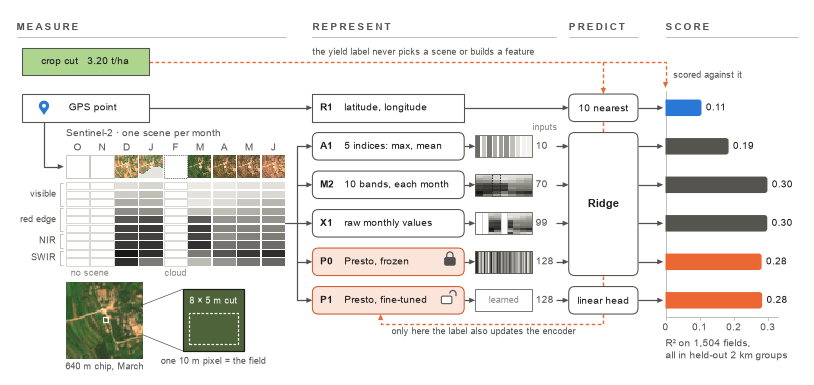

In [21]:
W, H = FULL, 3.30
fig, ax = canvas(W, H)
r2_of = {arm: float(ARM_SCORES.loc[arm, "r2"]) for arm in ("R1", "A1", "X1", "P0", "P1")} | {"M2": float(M2_ROW.r2)}
lanes = dict(zip(("R1", "A1", "M2", "X1", "P0", "P1"), (2.42, 2.07, 1.72, 1.37, 1.02, 0.67)))   # lane centres, inches
y_label, bh = 2.84, 0.25                                                                         # label lane, box height

# ---- band headers ---------------------------------------------------------------------------------------------------
for name, x0, x1 in (("MEASURE", 0.05, 2.50), ("REPRESENT", 2.74, 4.95), ("PREDICT", 5.07, 5.70), ("SCORE", 5.95, 7.15)):
    ax.text(x0, 3.15, " ".join(name), fontsize=6.5, fontweight="bold", color=INK2, va="center")
    ax.plot([x0, x1], [3.065, 3.065], color=AXIS, linewidth=0.6)

# ---- MEASURE: the label, the GPS point, nine monthly chips and the months x bands matrix of the example field ---------
node(ax, 0.10, y_label - bh / 2, 1.15, bh, f"crop cut   {EX['y']:.2f} t/ha", "data", fc=tint(YIELD(EX["y"] / 7), 0.35))
node(ax, 0.10, lanes["R1"] - bh / 2, 1.15, bh, "     GPS point", "data")
pin(ax, 0.30, lanes["R1"] - 0.065, size=0.13)
ax.text(0.50, 2.185, "Sentinel-2 · one scene per month", fontsize=6.3, color=INK2, va="center")
x_s, pitch, side = 0.50, 0.2225, 0.21
flow(ax, [(0.30, lanes["R1"] - bh / 2), (0.30, 1.885), (x_s - 0.02, 1.885)])                      # the point picks the pixel
for j, (month, letter) in enumerate(zip(EX["months"], EX["letters"])):
    x0 = x_s + j * pitch
    ax.text(x0 + side / 2, 2.055, letter, fontsize=6.3, color=INK2, ha="center", va="center")
    if month in EX["scene"]:
        ax.imshow(true_colour(EX["scene"][month]), extent=(x0, x0 + side, 1.78, 1.78 + side), zorder=5)
        r, c = EX["pixel"]
        ax.add_patch(Rectangle((x0 + (c - 1.5) / 64 * side, 1.78 + side - (r + 2.5) / 64 * side), 4 / 64 * side, 4 / 64 * side,
                               fill=False, edgecolor="white", linewidth=0.5, zorder=6))
    else:
        cloudy = EX["state"][month] == "cloudy"
        ax.add_patch(Rectangle((x0, 1.78), side, side, facecolor=PAPER, edgecolor=NEUTRAL if cloudy else HOLLOW, linewidth=0.5,
                               linestyle=(0, (1.6, 1.2)) if cloudy else "solid", zorder=5))
cells(ax, EX["bands"], x_s - 0.00625, 0.98, 9 * pitch, 0.77, 0, 0.5, gap=0.0125)
for text, first, last in (("visible", 0, 2), ("red edge", 3, 5), ("NIR", 6, 7), ("SWIR", 8, 9)):
    top, bottom = 0.98 + 0.77 - first * 0.077 - 0.012, 0.98 + 0.77 - (last + 1) * 0.077 + 0.012
    bracket(ax, (0.445, top), (0.445, bottom), depth=0.025, side=-1, color=AXIS, lw=0.6)
    ax.text(0.41, (top + bottom) / 2, text, fontsize=6, color=INK2, ha="right", va="center")
for text, first, last in (("no scene", 0, 1), ("cloud", 4, 4)):
    ax.text(x_s + (first + last + 1) / 2 * pitch - 0.00625, 0.915, text, fontsize=6, color=MUTED, ha="center", va="center")

# the peak-month chip, the one pixel that stands for the field, and the 8 x 5 m crop cut drawn to scale inside it
peak = EX["scene"]["2023-03"]
cx0, cy0, cs = 0.50, 0.14, 0.70
ax.imshow(true_colour(peak), extent=(cx0, cx0 + cs, cy0, cy0 + cs), zorder=5)
r, c = EX["pixel"]
px, py = cx0 + (c + 0.5) / 64 * cs, cy0 + cs - (r + 0.5) / 64 * cs
ax.add_patch(Rectangle((px - 2 / 64 * cs, py - 2 / 64 * cs), 4 / 64 * cs, 4 / 64 * cs, fill=False, edgecolor="white", linewidth=0.7, zorder=6))
gx0, gy0, gs = 1.56, 0.21, 0.56
for corner_y in (gy0, gy0 + gs):
    ax.plot([px, gx0], [py, corner_y], color=INK2, linewidth=0.45, zorder=4)
ax.add_patch(Rectangle((gx0, gy0), gs, gs, facecolor=true_colour(peak)[r, c], edgecolor=INK, linewidth=0.8, zorder=6))
ax.add_patch(Rectangle((gx0 + 0.1 * gs, gy0 + 0.12 * gs), 0.8 * gs, 0.5 * gs, fill=False, edgecolor="white", linewidth=0.8,
                       linestyle=(0, (2.2, 1.4)), zorder=7))
ax.text(gx0 + gs / 2, gy0 + 0.81 * gs, "8 × 5 m cut", fontsize=6, color="white", ha="center", va="center", zorder=8)
ax.text(cx0 + cs / 2, 0.065, "640 m chip, March", fontsize=6, color=INK2, ha="center", va="center")
ax.text(gx0 + gs / 2, 0.115, "one 10 m pixel = the field", fontsize=6, color=INK2, ha="center", va="center")

# ---- REPRESENT: what each arm keeps of the same light ------------------------------------------------------------------
x_bus, x_op, w_op, x_th, w_th, x_n = 2.60, 2.74, 1.38, 4.22, 0.52, 4.77
flow(ax, [(1.25, lanes["R1"]), (x_op, lanes["R1"])])                                              # GPS point -> R1
ax.plot([x_s + 9 * pitch - 0.0125, x_bus], [lanes["X1"], lanes["X1"]], color=INK2, linewidth=0.8, zorder=4)
ax.plot([x_bus, x_bus], [lanes["P1"], lanes["A1"]], color=INK2, linewidth=0.8, zorder=4, solid_capstyle="projecting")
text_of = {"R1": "latitude, longitude", "A1": "5 indices: max, mean", "M2": "10 bands, each month",
           "X1": "raw monthly values", "P0": "Presto, frozen", "P1": "Presto, fine-tuned"}
z_a1 = ((EX["d"]["X_a1"].loc[EXAMPLE] - EX["d"]["X_a1"].mean()) / EX["d"]["X_a1"].std()).to_numpy()
ax.text(x_n + 0.085, lanes["A1"] + 0.17, "inputs", fontsize=6, color=MUTED, va="center", ha="center")
for arm, yc in lanes.items():
    is_presto = arm in ("P0", "P1")
    node(ax, x_op, yc - bh / 2, w_op, bh, "", "data" if arm == "R1" else "op", fc=PRESTO_FILL if is_presto else PAPER,
         ec=PRESTO_EDGE if is_presto else NEUTRAL)
    ax.text(x_op + 0.07, yc, arm, fontsize=6.5, fontweight="bold", va="center", zorder=7)
    ax.text(x_op + 0.29, yc, text_of[arm], fontsize=6.5, va="center", zorder=7)
    if arm == "R1":
        flow(ax, [(x_op + w_op, yc), (5.07, yc)])
        continue
    flow(ax, [(x_bus, yc), (x_op, yc)])
    flow(ax, [(x_op + w_op, yc), (x_th, yc)])
    y0, hh = yc - 0.10, 0.20
    if arm == "A1":
        cells(ax, z_a1[None, :], x_th, y0, w_th, hh, -2, 2, gap=0.012)
    elif arm == "M2":
        filled = EX["d"]["variants"]["M2 monthly band curve"].loc[EXAMPLE].to_numpy().reshape(len(BANDS), -1)
        ax.imshow(filled, extent=(x_th, x_th + w_th, y0, y0 + hh), cmap=GREY, vmin=0, vmax=0.5, aspect="auto", zorder=5)
        for j, m in enumerate(EX["months"][2:]):                                                  # interpolated months
            if EX["state"][m] != "clear":
                ax.add_patch(Rectangle((x_th + j * w_th / 7, y0), w_th / 7, hh, fill=False, edgecolor=INK, linewidth=0.6,
                                       linestyle=(0, (1.6, 1.2)), zorder=6))
    elif arm == "X1":
        raw = np.vstack([EX["bands"], EX["ndvi"][None, :] / 2])                                   # NDVI drawn at half scale
        ax.imshow(raw, extent=(x_th, x_th + w_th, y0, y0 + hh), cmap=GREY, vmin=0, vmax=0.5, aspect="auto", zorder=5)
        for j, m in enumerate(EX["months"]):
            if EX["state"][m] != "clear":
                ax.add_patch(Rectangle((x_th + j * w_th / 9, y0), w_th / 9, hh, facecolor=PAPER, edgecolor=HOLLOW, linewidth=0.35, zorder=6))
    elif arm == "P0":
        barcode(ax, EX["embedding"], x_th, y0, w_th, hh, -3, 3)
        lock(ax, x_op + w_op - 0.13, yc + 0.012, closed=True)
    else:
        ax.text(x_th + w_th / 2, yc, "learned", fontsize=6, color=MUTED, ha="center", va="center", zorder=8)
        lock(ax, x_op + w_op - 0.16, yc + 0.012, closed=False)
    ax.add_patch(Rectangle((x_th, y0), w_th, hh, fill=False, edgecolor=NEUTRAL, linewidth=0.5, zorder=7))
    ax.text(x_n, yc, f"{ARMS[arm][2]}", fontsize=6.3, color=INK2, va="center")
    flow(ax, [(4.955, yc), (5.07, yc)])

# ---- PREDICT: three heads; the dashed line shows where the yield label is used -----------------------------------------
x_p, w_p = 5.07, 0.63
xm = x_p + w_p / 2
node(ax, x_p, lanes["R1"] - bh / 2, w_p, bh, "10 nearest", "op")
node(ax, x_p, lanes["P0"] - bh / 2, w_p, lanes["A1"] - lanes["P0"] + bh, "Ridge", "op", size=7.2, weight="bold")
node(ax, x_p, lanes["P1"] - bh / 2, w_p, bh, "linear head", "op")
flow(ax, [(1.25, y_label), (xm, y_label), (xm, lanes["R1"] + bh / 2)], color=PRESTO, dashed=True, lw=0.9)
for upper, lower in (("R1", "A1"), ("P0", "P1")):
    ax.plot([xm, xm], [lanes[upper] - bh / 2, lanes[lower] + bh / 2], color=PRESTO, linewidth=0.9, linestyle=(0, (2.6, 1.8)), zorder=4)
flow(ax, [(xm, lanes["P1"] - bh / 2), (xm, 0.455), (x_op + 0.62, 0.455), (x_op + 0.62, lanes["P1"] - bh / 2)], color=PRESTO,
     dashed=True, lw=0.9)
ax.text(x_op + 0.72, 0.385, "only here the label also updates the encoder", fontsize=6, color=INK2, va="center")
ax.text(2.74, 2.925, "the yield label never picks a scene or builds a feature", fontsize=6, color=INK2, va="center")

# ---- SCORE: R2 of every lane on one axis ---------------------------------------------------------------------------------
x0, scale = 5.95, 3.1
flow(ax, [(xm, y_label), (x0, y_label), (x0, 2.60)], color=PRESTO, dashed=True, lw=0.9)
ax.text(x0 + 0.07, 2.715, "scored against it", fontsize=6, color=INK2, va="center")
ax.plot([x0, x0], [0.52, 2.57], color=AXIS, linewidth=0.6, zorder=3)
for arm, yc in lanes.items():
    color = VILLAGE if arm == "R1" else PRESTO if arm in ("P0", "P1") else NEUTRAL
    flow(ax, [(x_p + w_p, yc), (x0 - 0.02, yc)])
    rounded_bar(ax, x0, x0 + scale * r2_of[arm], yc, 0.15, color, zorder=5)
    ax.text(x0 + scale * r2_of[arm] + 0.04, yc, f"{r2_of[arm]:.2f}", fontsize=6.5, va="center")
for tick in (0, 0.1, 0.2, 0.3):
    ax.plot([x0 + scale * tick] * 2, [0.52, 0.49], color=AXIS, linewidth=0.6)
    ax.text(x0 + scale * tick, 0.42, f"{tick:g}", fontsize=6.3, color=INK2, ha="center", va="center")
ax.plot([x0, x0 + scale * 0.33], [0.52, 0.52], color=AXIS, linewidth=0.6)
ax.text(x0, 0.275, f"R² on {int(D[LACUNA]['dev'].sum()):,} fields,", fontsize=6.3, color=INK2, va="center")
ax.text(x0, 0.165, "all in held-out 2 km groups", fontsize=6.3, color=INK2, va="center")

keep_frame(ax, W, H)
save(fig, "A01_one_field_one_number")

### A02. Lit and dark tokens: what Presto gets from us

**What it shows.** The token grid of Presto for the example field. One cell is one token: a channel group in one month. A filled cell is a real value (darker = larger), a hollow cell is masked. The bars on top give the share of all 1,880 fields that have a clear scene in that month.
**Read it like this.** Top to bottom. Presto was pretrained with radar, weather, terrain and land cover. We give it only the Sentinel-2 groups, NDVI and the place (blue). October and November have no scene; February is cloudy for this field. Masked tokens are dropped before the encoder, so this field enters with 37 of 83 tokens. The bracket on the right marks the numbers that X1 gives straight to Ridge.
**Take-away.** Presto works here on less than half of the input that it was built for, and the control X1 reads exactly the same lit numbers without the network (and without the place).
**Source.** `D[LACUNA]["cube"]`, `coverage`, `p0_embeddings.npz`. Architecture facts (2 blocks, 8 heads, width 128, 404,160 encoder parameters, code widths 32 + 32 + 64) were read from the pinned weights and from `_parked/src/cropyield/models/presto_single_file.py`; they are typed in the cell.
**Caption draft.** Presto's input for one field. Each cell is one token (channel group x month); hollow cells are masked and are removed before the encoder. Of 83 possible tokens, 37 stay. The encoder output is the mean over these tokens (128 values). Control X1 gives the same Sentinel-2 and NDVI values to Ridge without the network.
**Caution.** The rows are in reading order, not in Presto's internal order. The grey level of a multi-band group is the mean of its bands; NDVI is drawn at half scale.

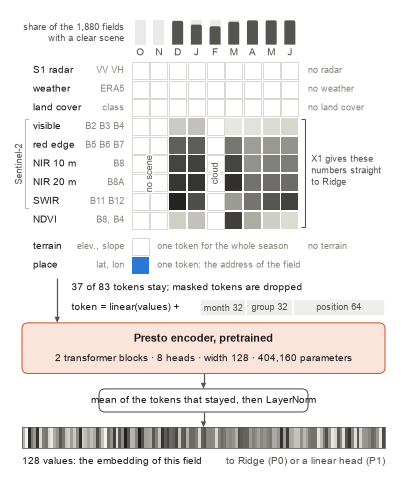

In [22]:
W, H = COL, 4.14
fig, ax = canvas(W, H)
months, state = EX["months"], EX["state"]
clear = (state == "clear").to_numpy()
x_name, x_detail, x_g, c = 0.20, 1.03, 1.09, 0.17                 # name column, detail column (right edge), grid, cell size
x_r = x_g + 9 * c + 0.08                                          # right margin: why a block is dark

# share of all model fields with a clear scene in each month (context for this one field)
lit_share = (coverage[coverage.obs_id.isin(D[LACUNA]["y"].index)].assign(lit=lambda t: t.coverage_state == "clear")
             .groupby("month")["lit"].mean().reindex(months).to_numpy())
y_bar, h_bar = H - 0.31, 0.22
for j, share in enumerate(lit_share):
    xc = x_g + (j + 0.5) * c
    ax.add_patch(Rectangle((xc - 0.05, y_bar), 0.10, h_bar, facecolor=tint(NEUTRAL, 0.88), edgecolor="none"))
    if share > 0:
        rounded_bar(ax, y_bar, y_bar + h_bar * share, xc, 0.10, NEUTRAL, horizontal=False, radius_pt=1.2)
    ax.text(xc, y_bar - 0.075, EX["letters"][j], fontsize=6.3, color=INK2, ha="center", va="center")
ax.text(x_detail, y_bar + 0.155, f"share of the {len(D[LACUNA]['y']):,} fields", fontsize=6, color=INK2, ha="right", va="center")
ax.text(x_detail, y_bar + 0.055, "with a clear scene", fontsize=6, color=INK2, ha="right", va="center")

# the token grid of the example field: one cell = one token; filled = real value (grey = its size), hollow = masked
group = lambda rows: EX["bands"][rows].mean(axis=0)
token_rows = [("S1 radar", "VV VH", None, "no radar"), ("weather", "ERA5", None, "no weather"),
           ("land cover", "class", None, "no land cover"),
           ("visible", "B2 B3 B4", group([0, 1, 2]), ""), ("red edge", "B5 B6 B7", group([3, 4, 5]), ""),
           ("NIR 10 m", "B8", group([6]), ""), ("NIR 20 m", "B8A", group([7]), ""), ("SWIR", "B11 B12", group([8, 9]), ""),
           ("NDVI", "B8, B4", EX["ndvi"] / 2, "")]
y_top = y_bar - 0.15
for i, (name, detail, values, reason) in enumerate(token_rows):
    yc = y_top - (i + 0.5) * c
    ax.text(x_name, yc, name, fontsize=6.3, va="center")
    ax.text(x_detail, yc, detail, fontsize=6, color=MUTED, ha="right", va="center")
    cells(ax, np.full(9, np.nan) if values is None else values, x_g, yc - c / 2, 9 * c, c, 0, 0.5, gap=0.016)
    if reason:
        ax.text(x_r, yc, reason, fontsize=6, color=MUTED, va="center")
bracket(ax, (0.13, y_top - 3 * c - 0.02), (0.13, y_top - 8 * c + 0.02), depth=0.03, side=-1, color=AXIS)
ax.text(0.075, y_top - 5.5 * c, "Sentinel-2", fontsize=6, color=INK2, rotation=90, ha="center", va="center")
for text, first, last in (("no scene", 0, 1), ("cloud", 4, 4)):                     # why a month is dark for this field
    ax.text(x_g + (first + last + 1) / 2 * c, y_top - 6 * c, text, fontsize=6, color=INK2, rotation=90, ha="center",
            va="center", zorder=9, path_effects=halo(2.2))
# X1 reads the same lit numbers, with no network
bracket(ax, (x_r - 0.03, y_top - 3 * c - 0.02), (x_r - 0.03, y_top - 9 * c + 0.02), depth=0.03, side=1)
for k, line in enumerate(("X1 gives these", "numbers straight", "to Ridge")):
    ax.text(x_r + 0.03, y_top - 5.25 * c - k * 0.105, line, fontsize=6, color=INK2, va="center")

# two tokens that do not change with the month
y_static = y_top - 9 * c - 0.07
static = (("terrain", "elev., slope", False, "one token for the whole season", "no terrain"),
          ("place", "lat, lon", True, "one token: the address of the field", ""))
for i, (name, detail, lit, what, note) in enumerate(static):
    yc = y_static - (i + 0.5) * c
    ax.text(x_name, yc, name, fontsize=6.3, va="center")
    ax.text(x_detail, yc, detail, fontsize=6, color=MUTED, ha="right", va="center")
    ax.add_patch(Rectangle((x_g + 0.008, yc - c / 2 + 0.008), c - 0.016, c - 0.016, facecolor=VILLAGE if lit else PAPER,
                           edgecolor="none" if lit else HOLLOW, linewidth=0.35))
    ax.text(x_g + c + 0.07, yc, what, fontsize=6, color=MUTED, va="center")
    if note:
        ax.text(x_r, yc, note, fontsize=6, color=MUTED, va="center")

# from tokens to the embedding (architecture facts: measured on the pinned weights, commit 11e207a6, see section 2)
n_kept, n_all = 6 * int(clear.sum()) + 1, 9 * len(months) + 2          # 6 lit groups per clear month + place; 9 per month + 2
y_mid = y_static - 2 * c
flow(ax, [(0.42, y_mid - 0.03), (0.42, y_mid - 0.44)])
ax.text(0.55, y_mid - 0.12, f"{n_kept} of {n_all} tokens stay; masked tokens are dropped", fontsize=6.3, va="center")
ax.text(0.55, y_mid - 0.30, "token = linear(values) +", fontsize=6.3, va="center")
x_code, w_code = 1.72, 1.68
for label, start, width in (("month 32", 0, 32), ("group 32", 32, 32), ("position 64", 64, 64)):
    node(ax, x_code + start / 128 * w_code, y_mid - 0.375, width / 128 * w_code, 0.15, label, "data", fc=tint(NEUTRAL, 0.9),
         ec=PAPER, lw=1.0, size=6, color=INK2)
y_enc = y_mid - 0.44 - 0.46
node(ax, 0.10, y_enc, W - 0.20, 0.46, "", "op", fc=PRESTO_FILL, ec=PRESTO_EDGE)
ax.text(W / 2, y_enc + 0.315, "Presto encoder, pretrained", fontsize=7.2, fontweight="bold", ha="center", va="center", zorder=7)
ax.text(W / 2, y_enc + 0.135, "2 transformer blocks · 8 heads · width 128 · 404,160 parameters", fontsize=6.3,
        ha="center", va="center", zorder=7)
flow(ax, [(W / 2, y_enc), (W / 2, y_enc - 0.14)])
node(ax, W / 2 - 0.95, y_enc - 0.14 - 0.21, 1.90, 0.21, "mean of the tokens that stayed, then LayerNorm", "op", size=6.3)
flow(ax, [(W / 2, y_enc - 0.35), (W / 2, y_enc - 0.49)])
barcode(ax, EX["embedding"], 0.10, y_enc - 0.49 - 0.19, W - 0.20, 0.19, -3, 3)
ax.text(0.10, y_enc - 0.80, "128 values: the embedding of this field", fontsize=6.3, va="center")
ax.text(W - 0.10, y_enc - 0.80, "to Ridge (P0) or a linear head (P1)", fontsize=6.3, color=INK2, ha="right", va="center")

keep_frame(ax, W, H)
save(fig, "A02_lit_and_dark_tokens")

### A03. The contrast square: which subtraction isolates what

**What it shows.** The design of the Presto controls, with the measured results. Rows: pretrained or random weights. Columns: frozen encoder + Ridge, or encoder trained end to end. On top: X1, the same raw numbers with no network. Each cell has a gauge for R² (the tick is the R² of X1) and the RMSE.
**Read it like this.** A bracket joins the two arms that are compared and gives the paired difference in RMSE (t/ha) with its 95 % cluster-bootstrap interval. Below 0 means that the first arm is better. Bold means that the interval excludes 0. Orange fill = pretrained weights; dashed orange frame = the yield label reaches the encoder.
**Take-away.** Pre-training is real: it helps much when the encoder is trained (P1 minus P2), and a little when it is frozen. But neither Presto arm beats Ridge on its own raw inputs (X1), fine-tuning adds nothing to the frozen embedding, and the place token changes nothing.
**Source.** `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv` and `posthoc_controls.csv` (through `presto[LACUNA]`). Lacuna, 1,504 fields, folds 1-4.
**Caption draft.** The controls as a 2 x 2 design (pretrained or random weights; frozen or trained) with Ridge on the raw inputs (X1) on top. Brackets give paired RMSE differences in t/ha with 95 % cluster-bootstrap intervals (2,000 draws). Only pre-training of the trained encoder is clearly different from 0; Presto does not beat its own inputs.
**Caution.** X1 and X2 are post hoc. The run saved no paired interval for P2 minus X2, so only the difference of the two scores is shown. These are RMSE differences; the rank differences are in the results part.

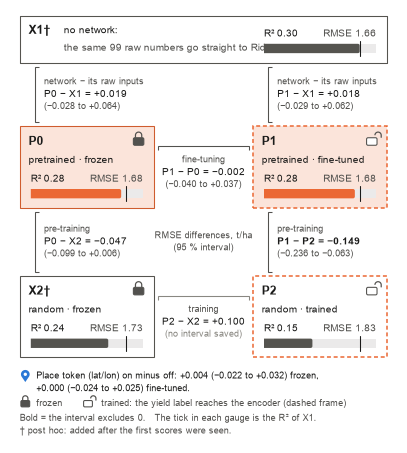

In [23]:
W, H = COL, 3.92
fig, ax = canvas(W, H)
minus = lambda text: text.replace("-", "−")
R2_MAX = 0.35                                                                      # right end of every gauge


def gauge(x, y, width, arm, color):
    """R2 of one arm as a filled track; the tick is the level of X1 (Ridge on the same raw numbers)."""
    r2_arm, rmse_arm = float(ARM_SCORES.loc[arm, "r2"]), float(ARM_SCORES.loc[arm, "rmse"])
    ax.add_patch(Rectangle((x, y), width, 0.085, facecolor=tint(NEUTRAL, 0.88), edgecolor="none", zorder=6))
    rounded_bar(ax, x, x + width * r2_arm / R2_MAX, y + 0.0425, 0.085, color, radius_pt=1.2, zorder=7)
    level = x + width * float(ARM_SCORES.loc["X1", "r2"]) / R2_MAX
    ax.plot([level, level], [y - 0.025, y + 0.11], color=INK, linewidth=0.7, zorder=8)
    ax.text(x, y + 0.175, f"R² {r2_arm:.2f}", fontsize=6.5, va="center", zorder=8)
    ax.text(x + width, y + 0.175, f"RMSE {rmse_arm:.2f}", fontsize=6.5, color=INK2, ha="right", va="center", zorder=8)
    return level


def difference(a, b):
    """Committed paired difference a minus b on RMSE (t/ha): value text, interval text, and whether it excludes 0."""
    row = PAIRS.loc[(a, b)]
    return (minus(f"{a} - {b} = {row.rmse_diff:+.3f}"), minus(f"({row.rmse_low:+.3f} to {row.rmse_high:+.3f})"),
            bool(row.rmse_low > 0 or row.rmse_high < 0))


def note(x, y, title, a, b, ha="left"):
    value, interval, clear_of_zero = difference(a, b)
    ax.text(x, y + 0.115, title, fontsize=6, color=INK2, ha=ha, va="center")
    ax.text(x, y, value, fontsize=6.5, fontweight="bold" if clear_of_zero else "normal", ha=ha, va="center")
    ax.text(x, y - 0.11, interval, fontsize=6, color=INK2, ha=ha, va="center")


x_c, w_c, h_c = (0.08, 2.20), 1.22, 0.74                                           # the two columns, cell width and height
y_slab, h_slab = H - 0.05 - 0.42, 0.42
y_r = (y_slab - 0.58 - h_c, y_slab - 0.58 - h_c - 0.62 - h_c)                      # lower edges of the two rows

# the slab on top: the same numbers with no network
node(ax, x_c[0], y_slab, x_c[1] + w_c - x_c[0], h_slab, "", "data")
ax.text(x_c[0] + 0.08, y_slab + 0.29, "X1†", fontsize=8, fontweight="bold", va="center", zorder=7)
ax.text(x_c[0] + 0.40, y_slab + 0.29, "no network:", fontsize=6.5, va="center", zorder=7)
ax.text(x_c[0] + 0.40, y_slab + 0.13, "the same 99 raw numbers go straight to Ridge", fontsize=6.3, color=INK2, va="center", zorder=7)
gauge(x_c[1] + 0.10, y_slab + 0.085, w_c - 0.20, "X1", NEUTRAL)

# the square: pretrained or random weights (rows) x frozen or trained (columns)
arms = {"P0": (0, 0, "pretrained · frozen"), "P1": (1, 0, "pretrained · fine-tuned"),
        "X2": (0, 1, "random · frozen"), "P2": (1, 1, "random · trained")}
for arm, (col, row, text) in arms.items():
    x, y = x_c[col], y_r[row]
    pretrained, trained = row == 0, col == 1
    ax.add_patch(Rectangle((x, y), w_c, h_c, facecolor=PRESTO_FILL if pretrained else PAPER, zorder=5,
                           edgecolor=PRESTO if trained else (PRESTO_EDGE if pretrained else NEUTRAL), linewidth=1.0 if trained else 0.7,
                           linestyle=(0, (2.6, 1.8)) if trained else "solid"))
    ax.text(x + 0.08, y + h_c - 0.14, arm + ("†" if arm == "X2" else ""), fontsize=8, fontweight="bold", va="center", zorder=7)
    ax.text(x + 0.08, y + h_c - 0.31, text, fontsize=6.3, va="center", zorder=7)
    lock(ax, x + w_c - 0.14, y + h_c - 0.13, closed=not trained)
    gauge(x + 0.10, y + 0.085, w_c - 0.20, arm, PRESTO if pretrained else NEUTRAL)

# the contrasts: a bracket joins the two arms that are compared (no arrow head = comparison, not flow)
for col, (upper, lower_row0, title) in enumerate((("P0", "X1", "network − its raw inputs"), ("P1", "X1", "network − its raw inputs"))):
    xb = x_c[col] + 0.14
    bracket(ax, (xb, y_slab - 0.04), (xb, y_r[0] + h_c + 0.04), depth=0.035, side=-1)
    note(xb + 0.08, (y_slab + y_r[0] + h_c) / 2, title, upper, lower_row0)
for col, (a, b) in enumerate((("P0", "X2"), ("P1", "P2"))):
    xb = x_c[col] + 0.14
    bracket(ax, (xb, y_r[0] - 0.04), (xb, y_r[1] + h_c + 0.04), depth=0.035, side=-1)
    note(xb + 0.08, (y_r[0] + y_r[1] + h_c) / 2, "pre-training", a, b)
xm = (x_c[0] + w_c + x_c[1]) / 2
yb = y_r[0] + h_c / 2 + 0.19
bracket(ax, (x_c[0] + w_c + 0.04, yb), (x_c[1] - 0.04, yb), depth=0.035, side=1)
note(xm, yb - 0.24, "fine-tuning", "P1", "P0", ha="center")
yb = y_r[1] + h_c / 2 + 0.19
bracket(ax, (x_c[0] + w_c + 0.04, yb), (x_c[1] - 0.04, yb), depth=0.035, side=1, color=MUTED)
gap = float(ARM_SCORES.loc["P2", "rmse"] - ARM_SCORES.loc["X2", "rmse"])           # only the two scores are saved, no pairs
ax.text(xm, yb - 0.125, "training", fontsize=6, color=INK2, ha="center", va="center")
ax.text(xm, yb - 0.24, minus(f"P2 - X2 = {gap:+.3f}"), fontsize=6.5, ha="center", va="center")
ax.text(xm, yb - 0.35, "(no interval saved)", fontsize=6, color=MUTED, ha="center", va="center")
ax.text(xm, (y_r[0] + y_r[1] + h_c) / 2 + 0.055, "RMSE differences, t/ha", fontsize=6, color=INK2, ha="center", va="center")
ax.text(xm, (y_r[0] + y_r[1] + h_c) / 2 - 0.055, "(95 % interval)", fontsize=6, color=INK2, ha="center", va="center")

# the place switch and the reading key
y_f = y_r[1] - 0.17
pin(ax, x_c[0] + 0.05, y_f - 0.055, size=0.11)
place = [difference(a, b) for a, b in (("P0", "P0_noloc"), ("P1", "P1_noloc"))]
ax.text(x_c[0] + 0.15, y_f, "Place token (lat/lon) on minus off: "
        + f"{place[0][0].split('= ')[1]} {place[0][1]} frozen,", fontsize=6, va="center")
ax.text(x_c[0] + 0.15, y_f - 0.115, f"{place[1][0].split('= ')[1]} {place[1][1]} fine-tuned.", fontsize=6, va="center")
lock(ax, x_c[0] + 0.05, y_f - 0.245, size=0.08, closed=True)
ax.text(x_c[0] + 0.15, y_f - 0.25, "frozen", fontsize=6, color=INK2, va="center")
lock(ax, x_c[0] + 0.62, y_f - 0.245, size=0.08, closed=False)
ax.text(x_c[0] + 0.74, y_f - 0.25, "trained: the yield label reaches the encoder (dashed frame)", fontsize=6, color=INK2, va="center")
ax.text(x_c[0], y_f - 0.385, "Bold = the interval excludes 0.   The tick in each gauge is the R² of X1.", fontsize=6,
        color=INK2, va="center")
ax.text(x_c[0], y_f - 0.50, "† post hoc: added after the first scores were seen.", fontsize=6, color=INK2, va="center")

keep_frame(ax, W, H)
save(fig, "A03_contrast_square")

### A04. Villages are dealt, not fields: the split and the two parts of R²

**What it shows.** (a) Real Lacuna fields in a 25 km window. Fields less than 2 km apart are linked into one group (grey shape = the fields with a 1 km disc round each; lines = the links). The blue arrow is the smallest gap between two groups. (b) Whole groups go into five folds of 376 fields. Fold 0 is locked. Folds 1-4 are cross-validated, and every tuning step uses grouped folds inside the training fields. (c) The out-of-fold predictions of the monthly-band model (M2), split into village means and deviations from the village mean.
**Read it like this.** In (c), the scatter of all fields is the sum of the two scatters to its right. The variance stamp says the same in one glyph: its width is the share of the yield variance between and inside villages, each column is filled to its R², and the filled area is the total R².
**Take-away.** A test field is always at least 2 km from every training field. The model predicts the village mean much better (R² 0.47) than the field inside its village (R² 0.09).
**Source.** `D[LACUNA]["fields"]` (frozen split `s1_cc2km`) and `P[LACUNA]` (M2, folds 1-4). The cell checks that every link is shorter than 2 km, that the smallest gap is at least 2 km, and that share x R² between + (1 - share) x R² within equals R².
**Caption draft.** Spatial cross-validation and the decomposition of skill. (a) Fields within 2 km are chained into groups. (b) Groups, not fields, are assigned to folds; fold 0 is held back and hyper-parameters are tuned in grouped inner folds. (c) For the monthly-band Ridge, R² = 0.30 over all fields splits into R² = 0.47 for the group means and 0.09 for the deviations inside groups; 56 % of the yield variance lies between groups.
**Caution.** A group is a chain of nearby fields, not a surveyed village. Groups with one or two fields count in the split but add little to the "inside" part.

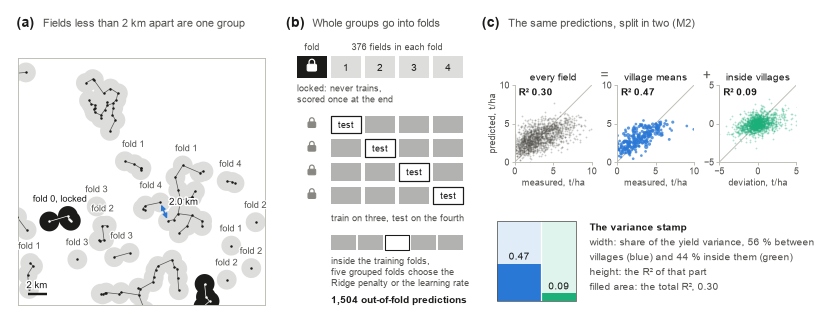

In [24]:
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.spatial.distance import cdist, pdist, squareform

W, H = FULL, 2.78
fig, ax = canvas(W, H)
d = D[LACUNA]


def head(x, letter, text):
    ax.text(x, H - 0.12, f"({letter})", fontsize=9, fontweight="bold", va="center")
    ax.text(x + 0.24, H - 0.125, text, fontsize=7.2, color=INK2, va="center")


# ---- (a) real fields round one place: chains of fields less than 2 km apart are one group ---------------------------------
head(0.05, "a", "Fields less than 2 km apart are one group")
centre = d["fields"][d["fields"].group_id == "86"][["lat", "lon"]].mean()            # a window that holds all five folds
kx, ky, half = 111.32 * math.cos(math.radians(centre.lat)), 110.57, 12.5              # km per degree; half window in km
near = d["fields"].assign(x=(d["fields"].lon - centre.lon) * kx - 0.5, y=(d["fields"].lat - centre.lat) * ky + 1.5)
near = near[(near.x.abs() < half + 2) & (near.y.abs() < half + 2)]
am = fig.add_axes([0.06 / W, 0.10 / H, 2.25 / W, 2.25 / H])
for gid, rows in near.groupby("group_id"):
    pts, locked = rows[["x", "y"]].to_numpy(), rows.fold.iloc[0] == "0"
    blob = unary_union([Point(p).buffer(1.0, 24) for p in pts])                       # 1 km discs melt into the 2 km group
    am.add_patch(PathPatch(geom_path(blob), facecolor=INK if locked else tint(NEUTRAL, 0.80), edgecolor="none", zorder=1))
    if len(pts) > 1:                                                                  # the chain: every link is shorter than 2 km
        tree = minimum_spanning_tree(squareform(pdist(pts))).tocoo()
        assert tree.data.max() < 2.0
        am.add_collection(LineCollection([[pts[i], pts[j]] for i, j in zip(tree.row, tree.col)], linewidths=0.45, zorder=2,
                                         colors=PAPER if locked else INK2))
    am.scatter(pts[:, 0], pts[:, 1], s=2.6, color=PAPER if locked else INK, linewidths=0, zorder=3)
    cx, top = blob.centroid.x, blob.bounds[3]
    if abs(cx) < half - 0.8 and top < half - 1.6 and blob.bounds[1] > -half:
        am.text(cx, top + 0.25, "fold 0, locked" if locked else f"fold {rows.fold.iloc[0]}", fontsize=6, color=INK if locked else INK2,
                ha="center", va="bottom", zorder=5, path_effects=halo(1.6))
inside = near[(near.x.abs() < half - 1) & (near.y.abs() < half - 1)]
gap = cdist(inside[["x", "y"]], inside[["x", "y"]])
gap[inside.group_id.to_numpy()[:, None] == inside.group_id.to_numpy()[None, :]] = np.inf
i, j = np.unravel_index(np.argmin(gap), gap.shape)                                    # the two nearest fields of different groups
p, q = inside[["x", "y"]].to_numpy()[i], inside[["x", "y"]].to_numpy()[j]
assert gap[i, j] >= 2.0
am.annotate("", xy=q, xytext=p, arrowprops={"arrowstyle": "<|-|>,head_length=0.35,head_width=0.16", "color": VILLAGE, "linewidth": 0.9,
                                                "shrinkA": 1.5, "shrinkB": 1.5}, zorder=6)
am.text((p[0] + q[0]) / 2 + 0.5, (p[1] + q[1]) / 2 + 0.5, f"{gap[i, j]:.1f} km", fontsize=6.3, va="bottom", zorder=7, path_effects=halo(2))
am.plot([-half + 1, -half + 3], [-half + 1.1, -half + 1.1], color=INK, linewidth=1.6, solid_capstyle="butt", zorder=6)
am.text(-half + 2, -half + 1.5, "2 km", fontsize=6.3, ha="center", va="bottom", zorder=6, path_effects=halo(2))
am.set_xlim(-half, half)
am.set_ylim(-half, half)
plain(am, frame=AXIS)

# ---- (b) the fold ledger ----------------------------------------------------------------------------------------------------
x_b, bw, bg = 2.60, 0.27, 0.04
head(x_b - 0.10, "b", "Whole groups go into folds")
col = lambda k: x_b + k * (bw + bg)
sizes = d["fields"]["fold"].value_counts()
for k in range(5):
    locked = k == 0
    node(ax, col(k), 2.16, bw, 0.20, "" if locked else str(k), "data", fc=INK if locked else tint(NEUTRAL, 0.80), ec="none", size=6.5)
lock(ax, col(0) + bw / 2, 2.265, size=0.085, color=PAPER)
ax.text(col(0) + bw / 2, 2.44, "fold", fontsize=6, color=INK2, ha="center", va="center")
ax.text(col(2) + bw + bg / 2, 2.44, f"{int(sizes.iloc[0])} fields in each fold", fontsize=6, color=INK2, ha="center", va="center")
ax.text(col(0), 2.065, "locked: never trains,", fontsize=6, color=INK2, va="center")
ax.text(col(0), 1.965, "scored once at the end", fontsize=6, color=INK2, va="center")
for r in range(4):                                                                    # four rotations over folds 1-4
    yr = 1.66 - r * 0.215
    for k in range(1, 5):
        test = k == r + 1
        node(ax, col(k), yr, bw, 0.16, "test" if test else "", "data", fc=PAPER if test else tint(NEUTRAL, 0.55),
             ec=INK if test else "none", lw=0.8, size=6)
    lock(ax, col(0) + bw / 2, yr + 0.085, size=0.07, color=MUTED)
ax.text(col(1), 0.885, "train on three, test on the fourth", fontsize=6, color=INK2, va="center")
for k in range(5):                                                                    # the grouped inner loop of one fit
    node(ax, col(1) + k * 0.243, 0.60, 0.225, 0.14, "", "data", fc=PAPER if k == 2 else tint(NEUTRAL, 0.55), ec=INK if k == 2 else "none", lw=0.7)
for k, line in enumerate(("inside the training folds,", "five grouped folds choose the", "Ridge penalty or the learning rate")):
    ax.text(col(1), 0.495 - k * 0.10, line, fontsize=6, color=INK2, va="center")
ax.text(col(1), 0.14, f"{int(d['dev'].sum()):,} out-of-fold predictions", fontsize=6.3, fontweight="bold", va="center")

# ---- (c) R2 of the monthly-band model (M2) splits into a village part and a field part -------------------------------------
x_c, side, pitch, y_s = 4.58, 0.70, 0.93, 1.40
head(x_c - 0.30, "c", "The same predictions, split in two (M2)")
table = P[LACUNA]
cy = cluster_year(table)
means = table[["y", "M2"]].groupby(cy).transform("mean")
by_group = table[["y", "M2"]].groupby(cy).agg(y=("y", "mean"), p=("M2", "mean"), n=("y", "size"))
s = score(table, "M2")
share = float(((means.y - table.y.mean()) ** 2).sum() / ((table.y - table.y.mean()) ** 2).sum())
assert abs(share * s["r2_between"] + (1 - share) * s["r2_within"] - s["r2"]) < 1e-9   # the stamp is exact
panels = (("every field", table.y, table.M2, NEUTRAL, 1.3, 0.30, (0, 10), s["r2"]),
          ("village means", by_group.y, by_group.p, VILLAGE, 2 + 1.1 * np.sqrt(by_group.n), 0.75, (0, 10), s["r2_between"]),
          ("inside villages", table.y - means.y, table.M2 - means.M2, FIELD, 1.3, 0.35, (-5, 5), s["r2_within"]))
for k, (title, x, y, color, size, alpha, lim, value) in enumerate(panels):
    a = fig.add_axes([(x_c + k * pitch) / W, y_s / H, side / W, side / H])
    a.plot(lim, lim, color=AXIS, linewidth=0.6, zorder=1)
    a.scatter(x, y, s=size, color=color, alpha=alpha, linewidths=0, zorder=2, rasterized=True)
    a.set_xlim(lim)
    a.set_ylim(lim)
    a.set_xticks([lim[0], sum(lim) / 2, lim[1]])
    a.set_yticks([lim[0], sum(lim) / 2, lim[1]])
    a.tick_params(labelsize=6, length=2, pad=1.5)
    a.set_title(title, fontsize=6.3, fontweight="normal", color=INK, loc="center", pad=3)
    a.text(0.05, 0.96, f"R² {value:.2f}", transform=a.transAxes, fontsize=6.5, fontweight="bold", va="top")
    a.set_xlabel("measured, t/ha" if k < 2 else "deviation, t/ha", fontsize=6, labelpad=1.5)
    if k == 0:
        a.set_ylabel("predicted, t/ha", fontsize=6, labelpad=1.5)
    if k:
        ax.text(x_c + k * pitch - (pitch - side) / 2, y_s + side + 0.085, "=" if k == 1 else "+", fontsize=9, color=INK2,
                ha="center", va="center")

# the variance stamp, with its reading key
x_st, y_st, st = 4.42, 0.14, 0.72
stamp(ax, x_st, y_st, st, share, s["r2_between"], s["r2_within"])
ax.text(x_st + st * share / 2, y_st + st * s["r2_between"] + 0.06, f"{s['r2_between']:.2f}", fontsize=6.3, ha="center", va="center", zorder=9)
ax.text(x_st + st * (1 + share) / 2, y_st + st * s["r2_within"] + 0.06, f"{s['r2_within']:.2f}", fontsize=6.3, ha="center", va="center", zorder=9)
key = (("The variance stamp", INK, "bold"),
       (f"width: share of the yield variance, {share * 100:.0f} % between", INK2, "normal"),
       (f"villages (blue) and {(1 - share) * 100:.0f} % inside them (green)", INK2, "normal"),
       ("height: the R² of that part", INK2, "normal"),
       (f"filled area: the total R², {s['r2']:.2f}", INK2, "normal"))
for k, (line, color, weight) in enumerate(key):
    ax.text(x_st + st + 0.12, y_st + st - 0.06 - k * 0.135, line, fontsize=6.3, color=color, fontweight=weight, va="center")

keep_frame(ax, W, H)
save(fig, "A04_villages_are_dealt")

### A05. Arm passport: what each model can use

**What it shows.** One row for each arm on Lacuna. Six yes/no facts (filled dot = yes, ring = no), the number of inputs, the R² on the 1,504 development fields, and the variance stamp of A04.
**Read it like this.** Go down a column to see which arms share a property; go along a row to see one arm. Blue dots = the arm gets the place (latitude and longitude). Orange dots = pretrained weights. The pair P0 and X2 differs only in pre-training, the pair P0 and P1 only in training, and X1 has the same spectra and timing as the Presto arms but no encoder and no place.
**Take-away.** R² rises when the model sees the monthly timing (A1 to M2). After that, an encoder, pre-training and fine-tuning do not add to it, and in every stamp the blue column (village) holds almost all of the filled area.
**Source.** R² of R0, R1, A1, P0, P1, P2, X1, X2: `scores.csv` and `posthoc_controls.csv` of the Lacuna Presto run; M2: `experiments/stepup/results.csv` (S7). Stamps: `P[LACUNA]`; the cell checks that each stamp gives the committed R².
**Caption draft.** The arms and what they can use. Dots mark the information and the training that an arm has; R² is on 1,504 fields in held-out 2 km groups. Stamps show how R² splits between villages (blue) and inside villages (green).
**Caution.** X1 and X2 are post hoc and have no saved prediction per field, so they have no stamp. The yes/no facts are typed from the experiment READMEs.

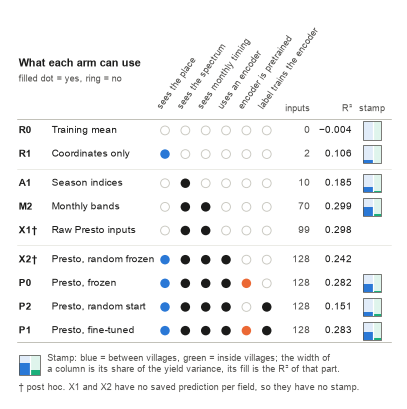

In [25]:
W, H = COL, 3.52
fig, ax = canvas(W, H)
# What each arm can use. Facts of the design (experiments/stepup/README.md, experiments/presto_finetune/README.md):
# place = latitude and longitude enter the model; timing = the model sees which month a value belongs to.
columns = ("sees the place", "sees the spectrum", "sees monthly timing", "uses an encoder", "encoder is pretrained",
           "label trains the encoder")
passport = {"R0": (0, 0, 0, 0, 0, 0), "R1": (1, 0, 0, 0, 0, 0), "A1": (0, 1, 0, 0, 0, 0), "M2": (0, 1, 1, 0, 0, 0),
            "X1": (0, 1, 1, 0, 0, 0), "X2": (1, 1, 1, 1, 0, 0), "P0": (1, 1, 1, 1, 1, 0), "P2": (1, 1, 1, 1, 0, 1),
            "P1": (1, 1, 1, 1, 1, 1)}
post_hoc = ("X1", "X2")
x_dot, pitch, row_h = 1.40, 0.185, 0.215
x_in, x_r2, x_st, st = 2.72, 3.10, 3.20, 0.165
y0 = H - 0.98                                                                         # top of the first row
dot_colour = {0: VILLAGE, 4: PRESTO}                                                  # the address is blue, pretrained weights are orange

for k, text in enumerate(columns):
    ax.text(x_dot + k * pitch - 0.02, y0 + 0.07, text, fontsize=6.2, color=INK2, rotation=55, ha="left", va="bottom",
            rotation_mode="anchor")
ax.text(x_in, y0 + 0.09, "inputs", fontsize=6.2, color=INK2, ha="right", va="center")
ax.text(x_r2, y0 + 0.09, "R²", fontsize=6.2, color=INK2, ha="right", va="center")
ax.text(x_st + st / 2, y0 + 0.09, "stamp", fontsize=6.2, color=INK2, ha="center", va="center")
ax.plot([0.05, W - 0.05], [y0, y0], color=AXIS, linewidth=0.6)

ax.text(0.07, y0 + 0.50, "What each arm can use", fontsize=7.2, fontweight="bold", va="center")
ax.text(0.07, y0 + 0.36, "filled dot = yes, ring = no", fontsize=6.2, color=INK2, va="center")

table = P[LACUNA]
cy = cluster_year(table)
means_y = table["y"].groupby(cy).transform("mean")
share = float(((means_y - table.y.mean()) ** 2).sum() / ((table.y - table.y.mean()) ** 2).sum())   # variance between villages
y = y0
for arm, flags in passport.items():
    if arm in ("A1", "X2"):                                                           # a little air between the three families
        y -= 0.05
        ax.plot([0.05, W - 0.05], [y + 0.025, y + 0.025], color=GRID, linewidth=0.5)
    yc = y - row_h / 2
    ax.text(0.07, yc, arm + ("†" if arm in post_hoc else ""), fontsize=6.8, fontweight="bold", va="center")
    ax.text(0.37, yc, ARMS[arm][0], fontsize=6.3, va="center")
    for k, flag in enumerate(flags):
        centre = (x_dot + k * pitch, yc)
        if flag:
            ax.add_patch(Circle(centre, 0.043, facecolor=dot_colour.get(k, INK), edgecolor="none", zorder=5))
        else:
            ax.add_patch(Circle(centre, 0.040, facecolor=PAPER, edgecolor=NEUTRAL_LIGHT, linewidth=0.6, zorder=5))
    r2_arm = float(M2_ROW.r2) if arm == "M2" else float(ARM_SCORES.loc[arm, "r2"])   # committed scores
    ax.text(x_in, yc, f"{ARMS[arm][2]}", fontsize=6.3, color=INK2, ha="right", va="center")
    ax.text(x_r2, yc, f"{r2_arm:.3f}".replace("-", "−"), fontsize=6.3, ha="right", va="center")
    if arm in table.columns:                                                          # the stamp needs the prediction of every field
        s = score(table, arm)
        assert abs(share * s["r2_between"] + (1 - share) * s["r2_within"] - s["r2"]) < 1e-9
        assert abs(s["r2"] - r2_arm) < 1e-6, arm                                      # the figure and the committed table agree
        stamp(ax, x_st, yc - st / 2, st, share, s["r2_between"], s["r2_within"])
    y -= row_h
ax.plot([0.05, W - 0.05], [y, y], color=AXIS, linewidth=0.6)

# reading key
stamp(ax, 0.07, y - 0.30, 0.19, share, 0.6, 0.25)                                    # an example, not a result
ax.text(0.33, y - 0.145, "Stamp: blue = between villages, green = inside villages; the width of", fontsize=6, color=INK2, va="center")
ax.text(0.33, y - 0.245, "a column is its share of the yield variance, its fill is the R² of that part.", fontsize=6, color=INK2, va="center")
ax.text(0.07, y - 0.41, "† post hoc. X1 and X2 have no saved prediction per field, so they have no stamp.", fontsize=6, color=INK2,
        va="center")

keep_frame(ax, W, H)
save(fig, "A05_arm_passport")

### A06. Same light, four readings

**What it shows.** The inputs of four arms for the same example field, all made from the same monthly Sentinel-2 values. (a) A1: the season maximum and mean of five vegetation indices (10 numbers). (b) M2: every band in every month, December to June (70 numbers). (c) X1: the raw table that Presto reads, 10 bands and NDVI in 9 months (99 numbers). (d) P0: the 128 numbers that the frozen Presto encoder makes of (c) and the place.
**Read it like this.** Grey cells are real values (darker = larger). In (a) the dot is the maximum and the line is the mean; the curve breaks at the cloudy February. In (b) the dashed cells are filled from the months next to them. In (c) a month with no clear scene stays empty (hollow).
**Take-away.** From (a) to (c) the model sees more of the season. A1 keeps how green the season was and loses when; M2 and X1 keep the curve. The embedding (d) is a learned mixture with no names.
**Source.** `D[LACUNA]` (`X_a1`, `cube`, the variant "M2 monthly band curve"), `EX` and `p0_embeddings.npz`. The cell checks that the dot and the line of (a) are the stored season features.
**Caption draft.** Four readings of the same light for one field: (a) ten season indices (A1), (b) the monthly curve of ten bands with the cloudy month interpolated (M2), (c) the raw monthly values that Presto reads, with missing months left empty (X1), (d) the 128-value Presto embedding (P0).
**Caution.** Grey levels: reflectance 0 to 0.5 in (b) and (c), NDVI at half scale, embedding values from -3 to 3. X1 also gets one missing-month flag for each column; the flags are not drawn.

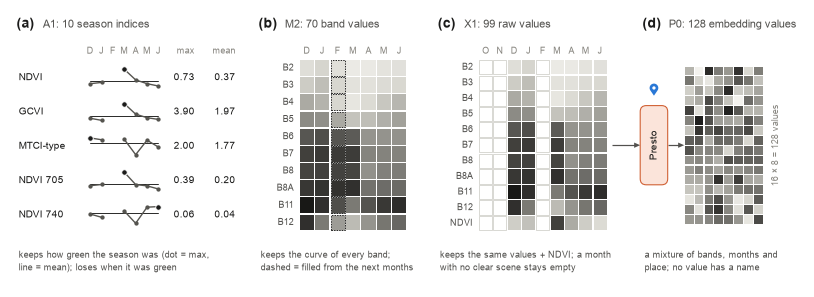

In [26]:
W, H = FULL, 2.50
fig, ax = canvas(W, H)
d = EX["d"]
ks = sorted(d["calendar"])                                                # months of the season with data: Dec ... Jun
letters = [MONTH_NAME[d["calendar"][k]][0] for k in ks]
filled_gap = [EX["state"][EX["months"][k]] != "clear" for k in ks]         # the month that M2 fills from its neighbours
y_top, y_bot = 2.06, 0.50                                                 # the band that holds the four pictures


def head(x, letter, text):
    ax.text(x, H - 0.12, f"({letter})", fontsize=9, fontweight="bold", va="center")
    ax.text(x + 0.24, H - 0.125, text, fontsize=7.2, color=INK2, va="center")


def notes(x, lines):
    for k, line in enumerate(lines):
        ax.text(x, 0.28 - k * 0.115, line, fontsize=6.2, color=INK2, va="center")


# ---- (a) A1: the season maximum and mean of five indices ---------------------------------------------------------------------
head(0.05, "a", "A1: 10 season indices")
names = {"ndvi": "NDVI", "gcvi": "GCVI", "mtci": "MTCI-type", "ndvi705": "NDVI 705", "ndvi740": "NDVI 740"}
x_sp, w_sp, row = 0.72, 0.62, (y_top - y_bot) / 5
ax.text(x_sp + w_sp + 0.33, y_top + 0.075, "max", fontsize=6, color=MUTED, ha="right", va="center")
ax.text(x_sp + w_sp + 0.70, y_top + 0.075, "mean", fontsize=6, color=MUTED, ha="right", va="center")
for j, letter in enumerate(letters):
    ax.text(x_sp + j / (len(ks) - 1) * w_sp, y_top + 0.075, letter, fontsize=6, color=MUTED, ha="center", va="center")
for i, (index, name) in enumerate(names.items()):
    series = d["cube"][index].loc[EXAMPLE].reindex(ks).to_numpy()
    top, mean = float(d["X_a1"].loc[EXAMPLE, f"{index}_season_max"]), float(d["X_a1"].loc[EXAMPLE, f"{index}_season_mean"])
    assert np.isclose(np.nanmax(series), top) and np.isclose(np.nanmean(series), mean)        # the picture is the feature
    lo, hi = np.nanmin(series), np.nanmax(series)
    yb = y_top - (i + 1) * row + 0.07
    xs = x_sp + np.arange(len(ks)) / (len(ks) - 1) * w_sp
    ys = yb + (series - lo) / (hi - lo) * (row - 0.16)
    ax.plot(xs, ys, color=NEUTRAL, linewidth=0.9, zorder=4)                                    # the line breaks at the cloudy month
    ax.plot(xs, ys, "o", ms=1.8, color=NEUTRAL, zorder=5)
    ax.plot([x_sp, x_sp + w_sp], [yb + (mean - lo) / (hi - lo) * (row - 0.16)] * 2, color=INK, linewidth=0.6, zorder=3)
    ax.plot(xs[np.nanargmax(series)], ys[np.nanargmax(series)], "o", ms=3.6, mfc=INK, mec=PAPER, mew=0.6, zorder=6)
    ax.text(0.07, yb + (row - 0.16) / 2, name, fontsize=6.3, va="center")
    ax.text(x_sp + w_sp + 0.33, yb + (row - 0.16) / 2, f"{top:.2f}", fontsize=6.3, ha="right", va="center")
    ax.text(x_sp + w_sp + 0.70, yb + (row - 0.16) / 2, f"{mean:.2f}", fontsize=6.3, ha="right", va="center")
notes(0.07, ("keeps how green the season was (dot = max,", "line = mean); loses when it was green"))

# ---- (b) M2: every band in every month, the cloudy month filled from its neighbours ----------------------------------------
x_b, w_b = 2.62, 0.98
head(2.25, "b", "M2: 70 band values")
curve = d["variants"]["M2 monthly band curve"].loc[EXAMPLE].to_numpy().reshape(len(BANDS), len(ks))
cells(ax, curve, x_b, y_bot, w_b, y_top - y_bot, 0, 0.5, gap=0.012, dashed=np.tile(filled_gap, (len(BANDS), 1)))
for j, letter in enumerate(letters):
    ax.text(x_b + (j + 0.5) * w_b / len(ks), y_top + 0.075, letter, fontsize=6, color=MUTED, ha="center", va="center")
for i, band in enumerate(BANDS):
    ax.text(x_b - 0.05, y_top - (i + 0.5) * (y_top - y_bot) / len(BANDS), band.upper().replace("B0", "B"), fontsize=6, color=INK2,
            ha="right", va="center")
notes(2.27, ("keeps the curve of every band;", "dashed = filled from the next months"))

# ---- (c) X1: the raw table that Presto reads, masked months left empty ------------------------------------------------------
x_c, w_c = 4.25, 1.17
head(3.88, "c", "X1: 99 raw values")
raw = np.vstack([EX["bands"], EX["ndvi"][None, :] / 2])                                        # NDVI drawn at half scale
cells(ax, raw, x_c, y_bot, w_c, y_top - y_bot, 0, 0.5, gap=0.012)
for j, letter in enumerate(EX["letters"]):
    ax.text(x_c + (j + 0.5) * w_c / 9, y_top + 0.075, letter, fontsize=6, color=MUTED, ha="center", va="center")
for i, band in enumerate([*BANDS, "ndvi"]):
    ax.text(x_c - 0.05, y_top - (i + 0.5) * (y_top - y_bot) / 11, band.upper().replace("B0", "B"), fontsize=6, color=INK2,
            ha="right", va="center")
notes(3.90, ("keeps the same values + NDVI; a month", "with no clear scene stays empty"))

# ---- (d) P0: the encoder turns (c) and the place into 128 numbers ----------------------------------------------------------
head(5.74, "d", "P0: 128 embedding values")
y_mid = (y_top + y_bot) / 2
flow(ax, [(x_c + w_c + 0.04, y_mid), (5.72, y_mid)])
node(ax, 5.72, y_mid - 0.36, 0.25, 0.72, "", "op", fc=PRESTO_FILL, ec=PRESTO_EDGE)
ax.text(5.845, y_mid, "Presto", fontsize=6.5, rotation=90, ha="center", va="center", zorder=7)
pin(ax, 5.845, y_mid + 0.45, size=0.11)
flow(ax, [(5.97, y_mid), (6.12, y_mid)])
grid = EX["embedding"].reshape(16, 8)
cells(ax, grid, 6.12, y_mid - 0.72, 0.72, 1.44, -3, 3, gap=0.010)
ax.text(6.95, y_mid, "16 × 8 = 128 values", fontsize=6, color=MUTED, rotation=90, ha="center", va="center")
notes(5.76, ("a mixture of bands, months and", "place; no value has a name"))

keep_frame(ax, W, H)
save(fig, "A06_same_light_four_readings")

### A07. How one fine-tuned prediction is made

**What it shows.** The nested procedure behind every P1 prediction, with the real runs of test fold 1 (the fold of the example field). (a) The test fold is put away. The three training folds are cut into five grouped inner folds. Four learning rates x five inner models give 20 small runs; each cell shows the best epoch of a run, and darker means a larger validation error. (b) The validation error of the five runs of the winning rate. (c) The mean inner validation error of each rate, for the pretrained start (P1) and the random start (P2).
**Read it like this.** Follow the arrows in (a) from top to bottom. The orange frame is the rate with the lowest mean validation error; the mean of its five models is the prediction for the test fold. In (b) a dot marks the epoch that is kept (early stopping).
**Take-away.** The test fold never chooses anything: the rate and the stopping epoch come from inner folds of the training fields only. Pre-training gives a head start (panel c: P1 is far below P2 at every rate), but the best epoch comes early and differs much between inner models.
**Source.** `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/inner_curves.csv` and `choices.csv`; the training rules are read from `experiments/presto_finetune/presto_lib.py`. The cell checks that the best epochs of the winning row equal `choices.csv`.
**Caption draft.** Fine-tuning protocol for one test fold. For each of four learning rates, five models are trained on grouped inner folds of the training fields with early stopping; the rate with the lowest mean inner validation error is chosen, and the test prediction is the mean of its five models. The test fold takes no part in any choice.
**Caution.** One test fold of four is shown. The validation errors in (b) come from five different inner folds, so their levels differ.

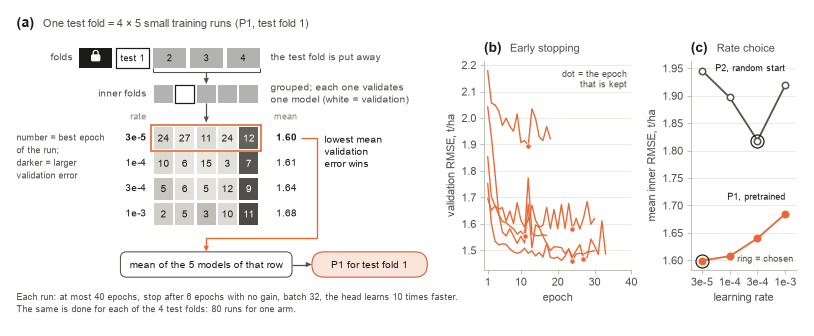

In [27]:
import re

W, H = FULL, 2.86
fig, ax = canvas(W, H)
FOLD = int(D[LACUNA]["fields"].loc[EXAMPLE, "fold"])                                  # the test fold of the example field
curves = pd.read_csv(PRESTO_RUNS / LACUNA / "inner_curves.csv")
choices = pd.read_csv(PRESTO_RUNS / LACUNA / "choices.csv").set_index(["arm", "fold"])
rule = dict(re.findall(r"^(MAX_EPOCHS|PATIENCE|BATCH_SIZE|INNER_FOLDS|HEAD_LR_FACTOR|WEIGHT_DECAY|GRAD_CLIP) = ([\d.]+)",
                       (REPO / "experiments" / "presto_finetune" / "presto_lib.py").read_text(encoding="utf-8"), flags=re.MULTILINE))
n_inner = int(rule["INNER_FOLDS"])
runs = curves[(curves.arm == "P1") & (curves.fold == FOLD)]
rates = sorted(runs.lr.unique())
chosen = float(choices.loc[("P1", FOLD), "chosen_lr"])
best = runs.loc[runs.groupby(["lr", "inner"]).val_mse.idxmin()].set_index(["lr", "inner"])   # best epoch of each of the 20 runs
assert " ".join(str(int(best.loc[(chosen, i), "epoch"])) for i in range(n_inner)) == choices.loc[("P1", FOLD), "best_epochs"]
rate_name = lambda lr: f"{lr:.0e}".replace("e-0", "e-")


def head(x, letter, text):
    ax.text(x, H - 0.12, f"({letter})", fontsize=9, fontweight="bold", va="center")
    ax.text(x + 0.24, H - 0.125, text, fontsize=7.2, color=INK2, va="center")


# ---- (a) the nested procedure for one test fold ---------------------------------------------------------------------------------
head(0.05, "a", f"One test fold = {len(rates)} × {n_inner} small training runs (P1, test fold {FOLD})")
x0, bw, bg = 0.62, 0.30, 0.035
col = lambda k: x0 + k * (bw + bg)
train = [k for k in (1, 2, 3, 4) if k != FOLD]
for k, fold in enumerate([0, FOLD, *train]):                                          # locked fold, test fold, three training folds
    node(ax, col(k), 2.34, bw, 0.18, "" if fold == 0 else f"test {fold}" if fold == FOLD else str(fold), "data",
         fc=INK if fold == 0 else PAPER if fold == FOLD else tint(NEUTRAL, 0.55), ec=INK if fold == FOLD else "none", lw=0.8, size=6)
lock(ax, col(0) + bw / 2, 2.435, size=0.075, color=PAPER)
ax.text(x0 - 0.06, 2.43, "folds", fontsize=6.3, color=INK2, ha="right", va="center")
ax.text(col(4) + bw + 0.10, 2.43, "the test fold is put away", fontsize=6.3, color=INK2, va="center")
x_l, x_r = col(2), col(4) + bw                                                        # everything below uses the training folds only
xm, cw = (x_l + x_r) / 2, (x_r - x_l) / n_inner
bracket(ax, (x_l, 2.30), (x_r, 2.30), depth=0.035, side=-1)
flow(ax, [(xm, 2.30), (xm, 2.19)])
for i in range(n_inner):                                                              # grouped inner folds of the training fields
    node(ax, x_l + i * cw + 0.01, 2.02, cw - 0.02, 0.16, "", "data", fc=PAPER if i == 1 else tint(NEUTRAL, 0.55),
         ec=INK if i == 1 else "none", lw=0.8)
ax.text(x_l - 0.06, 2.10, "inner folds", fontsize=6.3, color=INK2, ha="right", va="center")
ax.text(x_r + 0.10, 2.155, "grouped; each one validates", fontsize=6.3, color=INK2, va="center")
ax.text(x_r + 0.10, 2.045, "one model (white = validation)", fontsize=6.3, color=INK2, va="center")
flow(ax, [(xm, 2.02), (xm, 1.84)])

# the grid of runs: number = best epoch, grey = best validation RMSE of that run (real values)
y_g, ch = 1.60, 0.20
level = np.sqrt(best.val_mse)
for r, lr in enumerate(rates):
    yr = y_g - r * (ch + 0.03)
    hit = np.isclose(lr, chosen)
    ax.text(x_l - 0.06, yr + ch / 2, rate_name(lr), fontsize=6.3, fontweight="bold" if hit else "normal", ha="right", va="center")
    for i in range(n_inner):
        dark = float(np.clip((level.loc[(lr, i)] - level.min()) / (level.max() - level.min()), 0, 1))
        node(ax, x_l + i * cw + 0.01, yr, cw - 0.02, ch, f"{int(best.loc[(lr, i), 'epoch'])}", "data", fc=GREY(0.08 + 0.62 * dark),
             ec="none", size=6.3, color="white" if dark > 0.55 else INK)
    mean_rmse = float(choices.loc[("P1", FOLD), f"inner_val_rmse_lr_{lr:g}"])
    ax.text(x_r + 0.34, yr + ch / 2, f"{mean_rmse:.2f}", fontsize=6.3, fontweight="bold" if hit else "normal", ha="right", va="center")
    if hit:
        ax.add_patch(Rectangle((x_l - 0.015, yr - 0.015), x_r - x_l + 0.03, ch + 0.03, fill=False, edgecolor=PRESTO, linewidth=1.1, zorder=8))
        y_hit = yr + ch / 2
ax.text(x_l - 0.06, y_g + ch + 0.09, "rate", fontsize=6, color=MUTED, ha="right", va="center")
ax.text(x_r + 0.34, y_g + ch + 0.09, "mean", fontsize=6, color=MUTED, ha="right", va="center")
for k, line in enumerate(("number = best epoch", "of the run;", "darker = larger", "validation error")):
    ax.text(0.05, y_g + ch / 2 - k * 0.115, line, fontsize=6, color=INK2, va="center")
x_turn = x_r + 0.52
flow(ax, [(x_r + 0.38, y_hit), (x_turn, y_hit), (x_turn, 0.79), (xm, 0.79), (xm, 0.665)], color=PRESTO, lw=0.9)
for k, line in enumerate(("lowest mean", "validation", "error wins")):
    ax.text(x_turn + 0.07, y_hit - 0.02 - k * 0.11, line, fontsize=6.3, va="center")
node(ax, xm - 0.78, 0.435, 1.56, 0.23, f"mean of the {n_inner} models of that row", "op", size=6.5)
flow(ax, [(xm + 0.78, 0.55), (xm + 0.96, 0.55)])
node(ax, xm + 0.96, 0.435, 1.05, 0.23, f"P1 for test fold {FOLD}", "score", fc=PRESTO_FILL, ec=PRESTO_EDGE, size=6.5)
ax.text(0.05, 0.25, f"Each run: at most {rule['MAX_EPOCHS']} epochs, stop after {rule['PATIENCE']} epochs with no gain, batch "
        f"{rule['BATCH_SIZE']}, the head learns {float(rule['HEAD_LR_FACTOR']):g} times faster.", fontsize=6, color=INK2, va="center")
ax.text(0.05, 0.14, f"The same is done for each of the 4 test folds: {4 * len(rates) * n_inner} runs for one arm.",
        fontsize=6, color=INK2, va="center")

# ---- (b) the five runs of the winning row: validation error by epoch ------------------------------------------------------------
bx = fig.add_axes([4.30 / W, 0.50 / H, 1.34 / W, 1.90 / H])
won = runs[np.isclose(runs.lr, chosen)]
for i, run in won.groupby("inner"):
    bx.plot(run.epoch, np.sqrt(run.val_mse), color=PRESTO, linewidth=0.9, zorder=3)
    stop = run.loc[run.val_mse.idxmin()]
    bx.plot(stop.epoch, np.sqrt(stop.val_mse), "o", ms=3.6, mfc=PRESTO, mec=PAPER, mew=0.6, zorder=4)
bx.set_xlim(0, int(rule["MAX_EPOCHS"]))
bx.set_xticks([1, 10, 20, 30, 40])
bx.set_xlabel("epoch")
bx.set_ylabel("validation RMSE, t/ha")
hgrid(bx)
panel_title(bx, "b", "Early stopping")
bx.text(0.97, 0.96, "dot = the epoch\nthat is kept", transform=bx.transAxes, fontsize=6, color=INK2, ha="right", va="top", linespacing=1.2)

# ---- (c) the choice of the learning rate, with and without pre-training --------------------------------------------------------
cx = fig.add_axes([6.18 / W, 0.50 / H, 0.96 / W, 1.90 / H])
for arm, color, name in (("P2", NEUTRAL, "P2, random start"), ("P1", PRESTO, "P1, pretrained")):
    values = [float(choices.loc[(arm, FOLD), f"inner_val_rmse_lr_{lr:g}"]) for lr in rates]
    pick = rates.index(float(choices.loc[(arm, FOLD), "chosen_lr"]))
    cx.plot(range(len(rates)), values, color=color, linewidth=1.2, zorder=3)
    cx.plot(range(len(rates)), values, "o", ms=4.2, mfc=PAPER if arm == "P2" else color, mec=color, mew=1.0, zorder=4)
    cx.plot(pick, values[pick], "o", ms=8.5, mfc="none", mec=INK, mew=0.8, zorder=5)
    cx.text(len(rates) - 1, values[-1] + 0.022, name, fontsize=6.2, ha="right", va="bottom")
cx.set_xticks(range(len(rates)), [rate_name(lr) for lr in rates])
cx.set_xlim(-0.4, len(rates) - 0.6)
cx.set_xlabel("learning rate")
cx.set_ylabel("mean inner RMSE, t/ha")
hgrid(cx)
panel_title(cx, "c", "Rate choice")
cx.text(0.97, 0.03, "ring = chosen", transform=cx.transAxes, fontsize=6, color=INK2, ha="right", va="bottom")

keep_frame(ax, W, H)
save(fig, "A07_one_finetuned_prediction")

### A08. The Ridge head and its one knob

**What it shows.** (a) The head that the arms A1, M2, X1, P0 and X2 share: clip each input to the training 1 % to 99 % range, standardise, then Ridge with one penalty. Every step is fitted on the training fields only. (b) How the penalty is chosen for one test fold (the fold of the example field): the inner validation error of 17 penalties in 5 grouped inner folds, for three input sets.
**Read it like this.** Left = almost no penalty, right = all weights pressed to zero (the training mean). The ring is the penalty that the head uses for this test fold.
**Take-away.** The head has one knob and the test fold never turns it. The 128 Presto values need a strong penalty: with a weak one they are no better than the ten season indices. The monthly bands are good over a wide range.
**Source.** Recomputed in the cell with the project's own pipeline (`cropyield.baselines.models.Winsorize`, the 17 penalties of `scripts/baselines/baseline_table.py`), on `D[LACUNA]` and `p0_embeddings.npz`; the same search as `ridge_cv`.
**Caption draft.** The shared Ridge head. Inputs are clipped to the training 1st to 99th percentile and standardised; the penalty is chosen by grouped five-fold cross-validation inside the training folds. Curves: inner validation RMSE for the season indices (A1), the monthly band curve (M2) and the frozen Presto embedding (P0) in one test fold.
**Caution.** One test fold of four. These are inner validation errors on training fields, not the reported test scores. This figure is an addition to the seven figures of the brief.

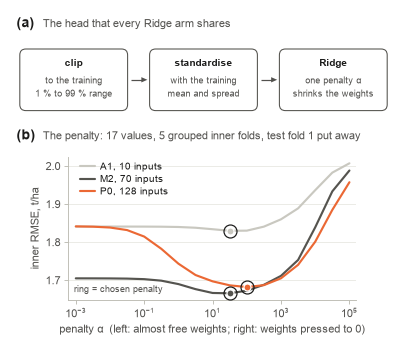

In [28]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cropyield.baselines.models import Winsorize
from cropyield.eval.protocol import train_mask

W, H = COL, 3.05
fig, ax = canvas(W, H)
d = D[LACUNA]
FOLD = d["fields"].loc[EXAMPLE, "fold"]                                               # the test fold of the example field
train = train_mask(d["fields"]["fold"], FOLD)                                         # the other three of folds 1-4
target, villages = d["y"].to_numpy(), d["fields"]["group_id"].to_numpy()
inputs = {"A1": d["X_a1"], "M2": d["variants"]["M2 monthly band curve"], "P0": EMB_ALL.reindex(d["y"].index)}
search = {}
for arm, table in inputs.items():                                                     # the same search as cropyield.baselines.models.ridge_cv
    search[arm] = GridSearchCV(make_pipeline(Winsorize(), StandardScaler(), Ridge()), {"ridge__alpha": step8.ALPHAS},
                               cv=GroupKFold(n_splits=5), scoring="neg_mean_squared_error")
    search[arm].fit(table.to_numpy()[train], target[train], groups=villages[train])


def head(y, letter, text):
    ax.text(0.05, y, f"({letter})", fontsize=9, fontweight="bold", va="center")
    ax.text(0.29, y - 0.005, text, fontsize=7.2, color=INK2, va="center")


# ---- (a) the head: three steps, every one fitted on the training fields only ---------------------------------------------------
head(H - 0.12, "a", "The head that every Ridge arm shares")
steps = (("clip", "to the training", "1 % to 99 % range"), ("standardise", "with the training", "mean and spread"),
         ("Ridge", "one penalty α", "shrinks the weights"))
x_box, w_box, gap = 0.08, 0.98, 0.20
for k, (title, line1, line2) in enumerate(steps):
    left = x_box + k * (w_box + gap)
    node(ax, left, 2.14, w_box, 0.56, "", "op")
    ax.text(left + w_box / 2, 2.57, title, fontsize=6.8, fontweight="bold", ha="center", va="center", zorder=7)
    ax.text(left + w_box / 2, 2.41, line1, fontsize=6.2, color=INK2, ha="center", va="center", zorder=7)
    ax.text(left + w_box / 2, 2.29, line2, fontsize=6.2, color=INK2, ha="center", va="center", zorder=7)
    if k:
        flow(ax, [(left - gap + 0.03, 2.42), (left - 0.02, 2.42)])

# ---- (b) how the penalty is chosen: grouped inner folds of the training fields, test fold never used ---------------------------
head(1.91, "b", f"The penalty: {len(step8.ALPHAS)} values, 5 grouped inner folds, test fold {FOLD} put away")
bx = fig.add_axes([0.52 / W, 0.42 / H, 2.62 / W, 1.30 / H])
styles = {"A1": (NEUTRAL_LIGHT, f"A1, {inputs['A1'].shape[1]} inputs"), "M2": (NEUTRAL, f"M2, {inputs['M2'].shape[1]} inputs"),
          "P0": (PRESTO, f"P0, {inputs['P0'].shape[1]} inputs")}
for arm, (color, name) in styles.items():
    rmse_inner = np.sqrt(-search[arm].cv_results_["mean_test_score"])
    pick = int(np.argmin(rmse_inner))
    assert np.isclose(step8.ALPHAS[pick], search[arm].best_params_["ridge__alpha"])
    bx.plot(step8.ALPHAS, rmse_inner, color=color, linewidth=1.4, zorder=3, label=name)
    bx.plot(step8.ALPHAS[pick], rmse_inner[pick], "o", ms=4.6, mfc=color, mec=PAPER, mew=0.8, zorder=5)
    bx.plot(step8.ALPHAS[pick], rmse_inner[pick], "o", ms=8.5, mfc="none", mec=INK, mew=0.8, zorder=6)
bx.legend(loc="upper left", bbox_to_anchor=(0.02, 1.0), fontsize=6.3, handlelength=1.6)
bx.set_xscale("log")
bx.set_xlim(step8.ALPHAS[0] * 0.6, step8.ALPHAS[-1] * 1.6)
bx.set_xticks([1e-3, 1e-1, 1e1, 1e3, 1e5])
bx.minorticks_off()
bx.set_xlabel("penalty α  (left: almost free weights; right: weights pressed to 0)")
bx.set_ylabel("inner RMSE, t/ha")
hgrid(bx)
bx.text(0.02, 0.04, "ring = chosen penalty", transform=bx.transAxes, fontsize=6, color=INK2, va="bottom")

keep_frame(ax, W, H)
save(fig, "A08_ridge_head")

## Part 3. Results and outcomes

Helpers of Part 3 (no figure): the paired cluster bootstrap (2,000 draws, seed 20261029, checked against a saved interval), the loaders of the committed result files and the shared plot parts.

In [29]:
POST_HOC = {"X1", "X2", "P3"}      # arms that were added after the first scores were seen: diamond marker and a dagger
DAGGER = "†"
MINUS = "−"


def tag(code):
    """Arm code with a dagger when the arm is post hoc."""
    return code + (DAGGER if code in POST_HOC else "")


def num(value, digits=3, sign=False):
    """A number as text with a real minus sign; a value that rounds to zero is written without a sign."""
    if round(value, digits) == 0:
        return f"{0:.{digits}f}"
    return (f"{value:+.{digits}f}" if sign else f"{value:.{digits}f}").replace("-", MINUS)


def paired(table, a, b):
    """Arm a minus arm b on the same fields: the difference in RMSE and in rank inside groups, each with a 95 %
    interval from the paired cluster bootstrap of the project (2,000 draws of whole 2 km groups, seed 20261029)."""
    y, pa, pb = (table[c].to_numpy() for c in ("y", a, b))
    groups, cy = table["group_id"].to_numpy(), cluster_year(table)
    keep = in_large_clusters(cy, step8.MIN_CLUSTER_FIELDS)
    y_in, a_in, b_in = (centred(v[keep], cy[keep]) for v in (y, pa, pb))
    rank = [spearman(y_in[i], a_in[i]) - spearman(y_in[i], b_in[i]) for i in group_draws(groups[keep], 2000, step8.SEED)]
    diff = [rmse(y[i], pa[i]) - rmse(y[i], pb[i]) for i in group_draws(groups, 2000, step8.SEED)]
    return {"rmse_diff": rmse(y, pa) - rmse(y, pb), "rmse_low": np.quantile(diff, .025), "rmse_high": np.quantile(diff, .975),
                "rank_diff": spearman(y_in, a_in) - spearman(y_in, b_in), "rank_low": np.nanquantile(rank, .025),
                "rank_high": np.nanquantile(rank, .975)}


def paired_rmse(table, a, b):
    """Only the RMSE part of paired(): the difference a minus b and its 95 % interval (same draws, same seed)."""
    y, pa, pb, groups = (table[c].to_numpy() for c in ("y", a, b, "group_id"))
    diff = [rmse(y[i], pa[i]) - rmse(y[i], pb[i]) for i in group_draws(groups, 2000, step8.SEED)]
    return rmse(y, pa) - rmse(y, pb), float(np.quantile(diff, .025)), float(np.quantile(diff, .975))


def ladder_of(cohort):
    """The Ridge rows of the step-up ladder of one data set, indexed by the rung code S0 ... S12."""
    rows = ladder[(ladder.cohort == cohort) & ladder["head"].isin(["Ridge", "-", "kNN"])].copy()
    rows["code"] = rows.step.str.split(" ").str[0]
    return rows.set_index("code")


def presto_arms(cohort):
    """Saved scores of the Presto arms and their controls, one row per arm."""
    rows = presto[cohort][presto[cohort].kind == "arm"].drop_duplicates("arm").set_index("arm")
    return rows[["rmse", "mae", "bias", "r2", "rank_inside_clusters"]]


def presto_pair(cohort, a, b):
    """One saved paired contrast a minus b (RMSE and rank inside groups, with intervals)."""
    rows = presto[cohort]
    return rows[(rows.kind == "pair") & (rows.a == a) & (rows.b == b)].iloc[0]


# The rungs of the ladder: the short label under a bar, the group of the rung, and the full name for tables.
_pre = [MONTH_NAME[m] for m in D[LACUNA]["calendar"].values() if m in tf.SOUTH]      # the pre-harvest months observed
PRE_HARVEST = f"{_pre[0]}–{_pre[-1]}"
RUNGS = {
    "S0": ("Training\nmean", "Place", "Training mean"),
    "S1": ("Lat/lon\nonly", "Place", "Coordinates only (10 nearest)"),
    "S2": ("GCVI\npeak", "GCVI only", "GCVI peak"),
    "S3": ("GCVI\nshape", "GCVI only", "GCVI season shape (4 numbers)"),
    "S4": ("GCVI\nmonthly", "GCVI only", "GCVI monthly curve"),
    "S5": ("5 indices\nmax+mean", "Season indices", "5 indices, max and mean"),
    "S6": ("5 indices\nmonthly", "Monthly detail", "5 indices, monthly curve"),
    "S7": ("10 bands\nmonthly", "Monthly detail", "10 bands, monthly curve"),
    "S8": (f"10 bands\n{PRE_HARVEST}", "Monthly detail", f"10 bands, pre-harvest ({PRE_HARVEST})"),
    "S9": ("10 bands\n+ lat/lon", "Monthly detail", "10 bands monthly + coordinates"),
    "S10": ("Presto\nfrozen", "Foundation model, MOSAIKS", "Presto, frozen embedding"),
    "S11": ("10 bands\n+ Presto", "Foundation model, MOSAIKS", "10 bands + Presto embedding"),
    "S12": ("MOSAIKS", "Foundation model, MOSAIKS", "MOSAIKS random features"),
}
RUNG_ARM = {"S0": "R0", "S1": "R1", "S5": "A1", "S7": "M2", "S10": "P0"}     # rungs that are also named arms


def interval(ax, y, est, low, high, color=INK, marker="o", size=4.4, horizontal=True, zorder=5):
    """One estimate with its 95 % interval: a thin line without caps; the marker is filled only when the interval
    excludes 0."""
    solid = (low > 0) or (high < 0)
    xs, ys = ([low, high], [y, y]) if horizontal else ([y, y], [low, high])
    ax.plot(xs, ys, color=color, linewidth=0.9, solid_capstyle="butt", zorder=zorder)
    px, py = (est, y) if horizontal else (y, est)
    ax.plot(px, py, marker, ms=size, mfc=color if solid else PAPER, mec=color, mew=0.9, zorder=zorder + 1)
    return solid


def zero_line(ax, horizontal=False):
    (ax.axhline if horizontal else ax.axvline)(0, color=AXIS, linewidth=0.7, zorder=1)


CONTROL_ROWS = [  # the design of the controls: a heading, or (label, arm a, arm b) for the contrast a minus b
    "Pretraining", ("frozen", "P0", "X2"), ("trained", "P1", "P2"),
    "Fine-tuning", ("trained minus frozen", "P1", "P0"),
    "Presto against its own raw inputs", ("frozen", "P0", "X1"), ("fine-tuned", "P1", "X1"),
    "Place: the lat/lon token on or off", ("frozen", "P0", "P0_noloc"), ("fine-tuned", "P1", "P1_noloc"),
]


def controls_panels(fig, cohort, bottom, height, letters=("a", "b"), heads=True, place=None):
    """The controls of one data set in a horizontal band of the figure: an interaction plot (frozen against trained,
    pretrained against random weights) and a forest plot of the saved paired contrasts (right = first arm better).
    `place` moves the label of a reference line, with an optional shorter text: {"X1": ("left", "below", "X1 ...")}."""
    place = {"X1": ("left", "below"), "A1": ("left", "above")} | (place or {})
    arms = presto_arms(cohort)
    ax = fig.add_axes([0.068, bottom, 0.225, height])
    for (a, b), color, hollow in ((("P0", "P1"), PRESTO, False), (("X2", "P2"), tint(PRESTO, 0.35), True)):
        ax.plot([0, 1], [arms.rmse[a], arms.rmse[b]], color=color, linewidth=1.5, zorder=3)
        for xpos, arm in enumerate((a, b)):
            ax.plot(xpos, arms.rmse[arm], "D" if arm in POST_HOC else "o", ms=5.2 if arm in POST_HOC else 5.6,
                    mfc=PAPER if hollow else PRESTO, mec=PRESTO, mew=1.1, zorder=4)
    ax.annotate("P0", (0, arms.rmse["P0"]), xytext=(-6, 0), textcoords="offset points", ha="right", va="center", fontsize=6.6)
    ax.annotate(tag("X2"), (0, arms.rmse["X2"]), xytext=(-6, 0), textcoords="offset points", ha="right", va="center", fontsize=6.6)
    ax.annotate("P1  pretrained", (1, arms.rmse["P1"]), xytext=(6, 0), textcoords="offset points", ha="left", va="center",
                fontsize=6.6, annotation_clip=False)
    ax.annotate("P2  random", (1, arms.rmse["P2"]), xytext=(6, 0), textcoords="offset points", ha="left",
                va="center", fontsize=6.6, annotation_clip=False)
    values = arms.rmse[["P0", "P1", "P2", "X1", "X2", "A1"]]
    pad = 0.09 * (values.max() - values.min())
    ax.set_xlim(-0.48, 1.12)
    ax.set_ylim(values.min() - 1.6 * pad, values.max() + 1.2 * pad)
    for arm, text in (("X1", f"{tag('X1')} Ridge on the same raw inputs"), ("A1", "A1 season indices")):
        ax.axhline(arms.rmse[arm], color=NEUTRAL, linewidth=0.8, zorder=2)
        side, where, *short = place[arm]
        text = short[0] if short else text
        x_text, ha = (-0.46, "left") if side == "left" else (1.10, "right")
        va, shift = ("top", -2.5) if where == "below" else ("bottom", 2)
        ax.annotate(text, (x_text, arms.rmse[arm]), xytext=(0, shift), textcoords="offset points", ha=ha, va=va,
                    fontsize=6.2, color=INK2)
    ax.set_xticks([0, 1], ["frozen\n+ Ridge", "trained\nend to end"])
    ax.tick_params(axis="x", length=0, pad=3)
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.2f"))
    ax.set_ylabel("RMSE, t/ha  (lower is better)")
    hgrid(ax)
    panel(ax, letters[0], x=-0.30, dy=6)
    if heads:
        ax.set_title(COHORTS[cohort]["name"], fontsize=7.5, pad=6, x=-0.08)

    count = len(CONTROL_ROWS)
    lx = fig.add_axes([0.385, bottom, 0.235, height])
    lx.set_xlim(0, 1)
    lx.set_ylim(count - 0.4, -0.7)
    lx.axis("off")
    specs = (("rmse", -1, "RMSE reduction, t/ha", 0.632), ("rank", 1, "Rank gain inside groups", 0.818))
    forests = []
    for key, sign, head, left in specs:
        fx = fig.add_axes([left, bottom, 0.172, height])
        low, high = [], []
        for y, row in enumerate(CONTROL_ROWS):
            if isinstance(row, str):
                continue
            pair = presto_pair(cohort, row[1], row[2])
            est, a, b = sign * pair[f"{key}_diff"], sign * pair[f"{key}_low"], sign * pair[f"{key}_high"]
            a, b = min(a, b), max(a, b)
            post = bool({row[1], row[2]} & POST_HOC)
            interval(fx, y, est, a, b, marker="D" if post else "o", size=4.0 if post else 4.4)
            low.append(a)
            high.append(b)
            fx.annotate(num(est, 3, True), (1.0, y), xycoords=("axes fraction", "data"), ha="right", va="center",
                        fontsize=6.3, color=INK2)
        span = max(high) - min(low)
        fx.set_xlim(min(low) - 0.06 * span, max(high) + 0.42 * span)
        fx.set_ylim(count - 0.4, -0.7)
        zero_line(fx)
        fx.set_yticks([])
        fx.spines["left"].set_visible(False)
        fx.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
        hgrid(fx, "x")
        fx.set_xlabel(head)
        fx.annotate("better →", (1.0, 1.0), xycoords="axes fraction", xytext=(0, 3), textcoords="offset points",
                    ha="right", va="bottom", fontsize=6.3, color=MUTED)
        forests.append(fx)
    for y, row in enumerate(CONTROL_ROWS):
        if isinstance(row, str):
            lx.text(0.0, y, row, ha="left", va="center", fontsize=6.9, fontweight="bold", color=INK)
        else:
            name, a, b = row
            text = f"{a}, with minus without" if b.endswith("_noloc") else f"{tag(a)} minus {tag(b)}"
            lx.text(0.05, y, name, ha="left", va="center", fontsize=6.6, color=INK2)
            lx.text(1.0, y, text, ha="right", va="center", fontsize=6.6, color=INK)
    panel(lx, letters[1], x=-0.10, dy=6)
    return ax, lx, forests


GREYS = LinearSegmentedColormap.from_list("greys", ["#e9e8e2", "#bdbcb3", "#77766f", "#2b2b29"])   # counts of raw points
# Signed values: the blue and the red arm of DIVERGE, each with one hue from the neutral middle to the dark end, so
# that small values are pale blue or pale red and never green or tan.
SIGNED = ramp("signed", [(0, .36, .125, 258), (.25, .60, .135, 255), (.497, .945, .012, 255), (.5, .950, .0, 255),
                         (.503, .945, .012, 28), (.75, .66, .150, 28), (1, .40, .145, 26)])
SIGNED.set_bad("#00000000")


def village_field_panels(fig, cohort, arm, span=11.0):
    """Two square panels with the same t/ha per inch: the means of the 2 km groups (the village), and the deviations
    of the fields from their group mean (the field). Returns both axes."""
    table, scores = P[cohort], score(P[cohort], arm)
    cy = cluster_year(table)
    size = pd.Series(cy).groupby(cy).transform("size").to_numpy()
    y_mean = table["y"].groupby(cy).transform("mean").to_numpy()
    p_mean = table[arm].groupby(cy).transform("mean").to_numpy()
    means = pd.DataFrame({"y": y_mean, "p": p_mean, "n": size}).groupby(cy).first()
    side = 2.78 / fig.get_figwidth()
    tall = 2.78 / fig.get_figheight()
    ax = fig.add_axes([0.075, 0.155, side, tall])
    bx = fig.add_axes([0.575, 0.155, side, tall])

    # (a) the village: one dot per group, area = fields in the group
    order = means.n.argsort()[::-1]
    ax.scatter(means.p.iloc[order], means.y.iloc[order], s=5 + 3.0 * means.n.iloc[order], color=VILLAGE, edgecolors=PAPER,
               linewidths=0.5, zorder=3)
    slope, cut = np.polyfit(means.p, means.y, 1, w=np.sqrt(means.n))
    xs = np.array([means.p.min(), means.p.max()])
    ax.plot([-0.5, span - 0.5], [-0.5, span - 0.5], color=NEUTRAL_LIGHT, linewidth=0.8, zorder=1)
    ax.plot(xs, cut + slope * xs, color=shade(VILLAGE, 0.45), linewidth=1.3, zorder=4)
    ax.set_xlim(-0.5, span - 0.5)
    ax.set_ylim(-0.5, span - 0.5)
    ax.set_xlabel("Predicted group mean, t/ha")
    ax.set_ylabel("Measured group mean, t/ha")
    head = {"xy": (1, 1), "xycoords": "axes fraction", "xytext": (0, 4.6), "textcoords": "offset points", "ha": "right", "va": "bottom",
                "fontsize": 7.6, "fontweight": "bold"}
    ax.annotate(f"R² between groups = {num(scores['r2_between'], 2)}", **head)
    ax.annotate("1:1", (span - 1.6, span - 1.6), xytext=(4, -8), textcoords="offset points", fontsize=6.3, color=MUTED)
    for k, n in enumerate((1, 10, 50)):                                   # key of the dot area
        ax.scatter(span - 4.15 + 1.25 * k, 0.45, s=5 + 3.0 * n, color=VILLAGE, edgecolors=PAPER, linewidths=0.5, zorder=3)
        ax.text(span - 4.15 + 1.25 * k + 0.10 + 0.045 * np.sqrt(5 + 3.0 * n), 0.45, f"{n}", va="center", fontsize=6.3, color=INK2)
    ax.text(span - 4.45, 1.12, "fields in the group", fontsize=6.3, color=INK2, va="bottom")
    ax.text(span - 0.8, 2.55, f"{len(means)} groups\nfit slope {num(slope, 2)}", fontsize=6.6, color=INK2, ha="right",
            va="bottom", linespacing=1.25)

    # (b) the field: deviations from the group mean, groups of two or more fields
    many = size >= 2
    dy, dp = (table["y"].to_numpy() - y_mean)[many], (table[arm].to_numpy() - p_mean)[many]
    half = span / 2
    inside = np.abs(dy) <= half
    bins = bx.hexbin(dp[inside], dy[inside], gridsize=44, extent=(-half, half, -half, half), cmap=GREYS, mincnt=1,
                     linewidths=0, rasterized=True, zorder=2)
    slope_in = np.polyfit(dp, dy, 1)[0]
    xs = np.array([np.quantile(dp, 0.002), np.quantile(dp, 0.998)])
    bx.plot([-half, half], [-half, half], color=NEUTRAL_LIGHT, linewidth=0.8, zorder=1)
    bx.plot(xs, slope_in * xs, color=shade(FIELD, 0.35), linewidth=1.5, zorder=4)
    bx.plot(dp[~inside], np.sign(dy[~inside]) * (half - 0.12), "^", ms=3, color=NEUTRAL, zorder=3)
    bx.set_xlim(-half, half)
    bx.set_ylim(-half, half)
    bx.set_xlabel("Predicted deviation from the group mean, t/ha")
    bx.set_ylabel("Measured deviation from the group mean, t/ha")
    bx.annotate(f"R² inside groups = {num(scores['r2_within'], 2)}", **head)
    note = f"{int(many.sum()):,} fields in groups\nof 2 or more\nfit slope {num(slope_in, 2)}"
    if (~inside).any():
        note += f"\n{int((~inside).sum())} fields outside the\nframe (triangles)"
    bx.text(0.035, 0.965, note, transform=bx.transAxes, va="top", fontsize=6.6, color=INK2, linespacing=1.25)
    bx.annotate("1:1", (half - 1.1, half - 1.1), xytext=(4, -8), textcoords="offset points", fontsize=6.3, color=MUTED)
    cax = bx.inset_axes([0.60, 0.075, 0.34, 0.028])
    colorbar(fig, bins, cax=cax, orientation="horizontal", ticks=[1, int(bins.get_array().max())])
    cax.set_title("fields per hexagon", fontsize=6.3, fontweight="normal", color=INK2, pad=2, loc="center")
    for axis in (ax, bx):
        axis.set_aspect("equal")
        axis.xaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
        axis.yaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
        hgrid(axis, "both")
    return ax, bx


# Fold 0: the newest logged look (models trained on folds 1-4, scored once on the 376 held-back fields).
_looks = pd.read_csv(REPO / "experiments" / "fold0" / "looks.csv")
FOLD0_RUN = REPO / "experiments" / "fold0" / _looks["run"].iloc[-1]
fold0_scores = pd.read_csv(FOLD0_RUN / "scores.csv").set_index("arm")
fold0_pred = pd.read_csv(FOLD0_RUN / "predictions.csv", dtype={"group_id": str}).set_index("obs_id")

# Checks: the bootstrap here gives the saved intervals, and the stacked parts of R2 add up.
_m2, _saved = paired(P[LACUNA], "M2", "A1"), ladder_of(LACUNA).loc["S7"]
assert abs(_m2["rmse_low"] - _saved.rmse_lo) < 1e-6 and abs(_m2["rmse_high"] - _saved.rmse_hi) < 1e-6
assert abs(_m2["rank_low"] - _saved.rank_lo) < 1e-6 and abs(_m2["rank_high"] - _saved.rank_hi) < 1e-6
_p0, _saved = paired(P[LACUNA], "P0", "A1"), presto_pair(LACUNA, "P0", "A1")
assert abs(_p0["rmse_low"] - _saved.rmse_low) < 1e-6 and abs(_p0["rank_high"] - _saved.rank_high) < 1e-6
_rows = ladder_of(LACUNA)
_parts = _rows.share_between * _rows.r2_between + (1 - _rows.share_between) * _rows.r2_within
assert (_parts - _rows.r2).abs().max() < 0.005
print(f"paired bootstrap equals the saved intervals; R2 = village part + field part (largest gap "
      f"{(_parts - _rows.r2).abs().max():.4f}); fold-0 run: {FOLD0_RUN.name}, {len(fold0_pred)} fields")

paired bootstrap equals the saved intervals; R2 = village part + field part (largest gap 0.0000); fold-0 run: 20261108T162116Z, 376 fields


### R01. The ladder as a two-tone staircase

**What it shows.** The 13 rungs of the step-up ladder for Zimbabwe Lacuna 2023 (Ridge head, folds 1–4, 1,504 fields). Each bar is the R² of one rung, split into the part that comes from the means of the 2 km groups (blue) and the part that comes from the fields inside a group (green). Panel (b) shows the variance of the measured yield and the part that M2 reads.

**Read it like this.** The black tread is the R² on the test folds; the two colours add up to it (the cell checks this). The hollow circle is the R² on the training folds, so the grey line is the overfit gap. A bracket gives the paired RMSE difference against A1 with its 95 % interval.

**Take-away.** More monthly detail helps (M2 minus A1: RMSE −0.130 t/ha, interval −0.220 to −0.045). The gain is blue: the village part grows from 0.16 (A1) to 0.26 (M2), and the field part stays between 0.02 and 0.06 on every rung with imagery. Frozen Presto is on the level of the monthly bands, not above it.

**Source.** `experiments/stepup/results.csv`, Ridge rows (`r2`, `share_between`, `r2_between`, `r2_within`, `train_r2`, `rmse_vs_A1` with its interval).

**Caption draft.** Step-up ladder on Zimbabwe Lacuna 2023 (1,504 fields in 232 groups, spatial cross-validation, Ridge head). Bars: R² split into skill between 2 km groups (blue) and inside groups (green); circles: R² on the training folds; brackets: paired RMSE difference against A1 with 95 % cluster-bootstrap interval. (b) 56 % of the yield variance lies between groups; M2 reads 26 points of it between groups and 4 points inside groups.

**Caution.** The rungs are not all nested, so read each bar alone and not as a strict staircase. For coordinates only, the inside part is slightly below 0 (−0.006) and is not drawn.

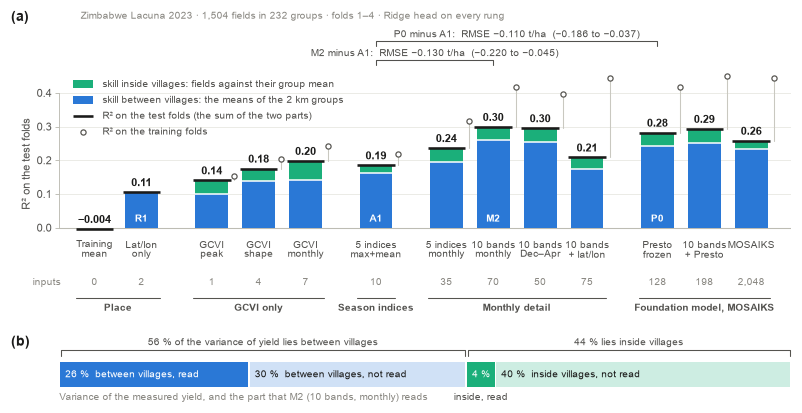

In [30]:
rows = ladder_of(LACUNA)
table = P[LACUNA]
village = rows.share_between * rows.r2_between            # part of R2 that comes from the group means
field = (1 - rows.share_between) * rows.r2_within         # part of R2 that comes from fields inside their group
assert ((village + field) - rows.r2).abs().max() < 0.005, "the two parts must add up to R2"

groups = [RUNGS[code][1] for code in rows.index]
x, pos = 0.0, {}
for i, code in enumerate(rows.index):
    x += 1.0 if i == 0 or groups[i] == groups[i - 1] else 1.5
    pos[code] = x
width = 0.70

fig = plt.figure(figsize=(FULL, 3.7))
ax = fig.add_axes([0.068, 0.425, 0.924, 0.515])
bx = fig.add_axes([0.068, 0.052, 0.924, 0.060])

for code, r in rows.iterrows():
    left = pos[code] - width / 2
    blue = min(village[code], r.r2) if field[code] < 0 else village[code]     # R1: the inside part is below 0, not drawn
    if blue > 0.002:
        ax.add_patch(Rectangle((left, 0), width, blue, facecolor=VILLAGE, edgecolor="none", zorder=2))
    if field[code] > 0.002:
        ax.add_patch(Rectangle((left, village[code]), width, field[code], facecolor=FIELD, edgecolor="none", zorder=2))
        ax.plot([left, left + width], [village[code]] * 2, color=PAPER, linewidth=1.0, zorder=3, solid_capstyle="butt")
    ax.plot([left - 0.05, left + width + 0.05], [r.r2, r.r2], color=INK, linewidth=1.7, zorder=4, solid_capstyle="butt")
    ax.text(pos[code], r.r2 + 0.011, num(r.r2, 2 if abs(r.r2) >= 0.005 else 3), ha="center", va="bottom", fontsize=7,
            fontweight="bold", color=INK)
    if np.isfinite(r.train_r2):                        # R2 on the training folds: a hollow mark beside the tread
        side = left + width + 0.13
        ax.plot([side, side], [r.r2, r.train_r2], color=NEUTRAL_LIGHT, linewidth=0.7, zorder=3)
        ax.plot(side, r.train_r2, "o", ms=3.4, mfc=PAPER, mec=NEUTRAL, mew=0.8, zorder=5)
    if code in RUNG_ARM and blue > 0.05:               # the arm code that the other figures use
        ax.text(pos[code], 0.012, RUNG_ARM[code], ha="center", va="bottom", fontsize=6.3, color=PAPER, fontweight="bold", zorder=6)

ax.axhline(0, color=AXIS, linewidth=0.7, zorder=1)
ax.set_xlim(pos["S0"] - 0.75, pos["S12"] + 0.85)
ax.set_ylim(-0.022, 0.60)
ax.set_yticks(np.arange(0, 0.41, 0.1))
ax.spines["left"].set_bounds(0, 0.4)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0, pad=3)
ax.set_xticks([pos[c] for c in rows.index], [RUNGS[c][0] for c in rows.index], fontsize=6.3, linespacing=1.08)
ax.set_ylabel("R² on the test folds", y=0.34)
hgrid(ax)
for line, tick in zip(ax.get_ygridlines(), ax.get_yticks()):
    line.set_visible(tick <= 0.4)

# Under the rung names: the number of inputs, then the group of the rung.
trans = ax.get_xaxis_transform()
for code, r in rows.iterrows():
    ax.text(pos[code], -0.205, f"{int(r.n_features):,}", transform=trans, ha="center", va="top", fontsize=6.3, color=MUTED)
ax.text(pos["S0"] - 0.72, -0.205, "inputs", transform=trans, ha="right", va="top", fontsize=6.3, color=MUTED)
for name in dict.fromkeys(groups):
    members = [c for c in rows.index if RUNGS[c][1] == name]
    a, b = pos[members[0]] - width / 2 - 0.05, pos[members[-1]] + width / 2 + 0.05
    ax.plot([a, b], [-0.300, -0.300], transform=trans, color=NEUTRAL, linewidth=0.7, clip_on=False)
    ax.text((a + b) / 2, -0.325, name, transform=trans, ha="center", va="top", fontsize=6.8, color=INK2, fontweight="bold")

# Brackets: the paired RMSE differences against A1 (95 % intervals from the saved ladder).
for other, height in (("S7", 0.497), ("S10", 0.553)):
    a, b, r = pos["S5"], pos[other], rows.loc[other]
    ax.plot([a, a, b, b], [height - 0.013, height, height, height - 0.013], color=INK2, linewidth=0.7, zorder=6)
    ax.text((a + b) / 2, height + 0.006,
            f"{RUNG_ARM[other]} minus A1:  RMSE {num(r.rmse_vs_A1, 3, True)} t/ha  ({num(r.rmse_lo, 3, True)} to {num(r.rmse_hi, 3, True)})",
            ha="center", va="bottom", fontsize=6.4, color=INK2)

# Key, in the empty corner above the low rungs.
kx, ky, dy = pos["S0"] - 0.45, 0.425, 0.047
ax.add_patch(Rectangle((kx, ky - 0.012), 0.42, 0.026, facecolor=FIELD, edgecolor="none"))
ax.text(kx + 0.62, ky, "skill inside villages: fields against their group mean", va="center", fontsize=6.6, color=INK2)
ax.add_patch(Rectangle((kx, ky - dy - 0.012), 0.42, 0.026, facecolor=VILLAGE, edgecolor="none"))
ax.text(kx + 0.62, ky - dy, "skill between villages: the means of the 2 km groups", va="center", fontsize=6.6, color=INK2)
ax.plot([kx, kx + 0.42], [ky - 2 * dy] * 2, color=INK, linewidth=1.7, solid_capstyle="butt")
ax.text(kx + 0.62, ky - 2 * dy, "R² on the test folds (the sum of the two parts)", va="center", fontsize=6.6, color=INK2)
ax.plot(kx + 0.21, ky - 3 * dy, "o", ms=3.4, mfc=PAPER, mec=NEUTRAL, mew=0.8)
ax.text(kx + 0.62, ky - 3 * dy, "R² on the training folds", va="center", fontsize=6.6, color=INK2)
ax.annotate(f"Zimbabwe Lacuna 2023 · {len(table):,} fields in {table.group_id.nunique()} groups · folds 1–4 · "
            "Ridge head on every rung", xy=(0, 1), xycoords="axes fraction", xytext=(14, 3), textcoords="offset points",
            va="bottom", fontsize=6.6, color=MUTED)
panel(ax, "a", x=-0.066, dy=1)

# (b) The variance of yield under M2: read or not read, between and inside villages.
m2 = rows.loc["S7"]
share = m2.share_between
parts = [("between villages, read", share * m2.r2_between, VILLAGE, PAPER),
         ("between villages, not read", share * (1 - m2.r2_between), tint(VILLAGE, 0.78), INK),
         ("inside, read", (1 - share) * m2.r2_within, FIELD, PAPER),
         ("inside villages, not read", (1 - share) * (1 - m2.r2_within), tint(FIELD, 0.78), INK)]
start = 0.0
for name, size, color, ink in parts:
    bx.add_patch(Rectangle((start + 0.0012, 0), size - 0.0024, 1, facecolor=color, edgecolor="none"))
    label = f"{100 * size:.0f} %" if size < 0.08 else f"{100 * size:.0f} %  {name}"
    bx.text(start + 0.008, 0.5, label, ha="left", va="center", fontsize=6.6, color=ink)
    start += size
bx.set_xlim(0, 1)
bx.set_ylim(0, 1)
bx.axis("off")
for a, b, text in ((0, share, f"{100 * share:.0f} % of the variance of yield lies between villages"),
                   (share, 1, f"{100 * (1 - share):.0f} % lies inside villages")):
    bx.plot([a + 0.002, a + 0.002, b - 0.002, b - 0.002], [1.28, 1.5, 1.5, 1.28], color=NEUTRAL, linewidth=0.7, clip_on=False)
    bx.text((a + b) / 2, 1.62, text, ha="center", va="bottom", fontsize=6.6, color=INK2)
bx.text(share + (1 - share) * m2.r2_within / 2, -0.25, "inside, read", ha="center", va="top", fontsize=6.3, color=INK2)
bx.text(0.0, -0.25, "Variance of the measured yield, and the part that M2 (10 bands, monthly) reads", ha="left", va="top",
        fontsize=6.3, color=MUTED)
panel(bx, "b", x=-0.066, y=1.0, dy=9)
save(fig, "R01_ladder_staircase")

### R02. Presto and its controls (Zimbabwe Lacuna 2023)

**What it shows.** (a) The RMSE of the four networks of the design: pretrained or random weights, frozen (embedding + Ridge) or trained end to end. The two grey lines are Ridge on the same raw inputs (X1†) and Ridge on the ten season indices (A1). (b) The saved paired contrasts in the order of the design, for RMSE and for the rank inside 2 km groups.

**Read it like this.** In (b) each row is "first arm minus second arm", signed so that right is better for the first arm. A filled mark means that the 95 % interval excludes 0; a hollow mark means that it includes 0.

**Take-away.** Pretraining is real: it lowers the RMSE of the trained network (P1 minus P2, interval excludes 0) and it improves the rank of the frozen embedding. But it is not extra: frozen and fine-tuned Presto are not better than Ridge on their own raw inputs (both intervals include 0). Fine-tuning does not lower RMSE and ranks slightly worse than the frozen embedding. The lat/lon token changes nothing here.

**Source.** `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/scores.csv` and `posthoc_controls.csv` (arm scores and paired contrasts).

**Caption draft.** Controls for Presto on Zimbabwe Lacuna 2023 (1,504 fields, folds 1–4). (a) RMSE by weights (pretrained, random) and training (frozen embedding + Ridge, end to end); lines: Ridge on the same raw inputs (X1) and on ten season indices (A1). (b) Paired differences with 95 % cluster-bootstrap intervals, signed so that right is better for the first arm. † post hoc.

**Caution.** X1 and X2 were added after the first scores were seen, so the rows with † are exploratory. The figure shows seven contrasts for two scores, without a correction for multiple tests.

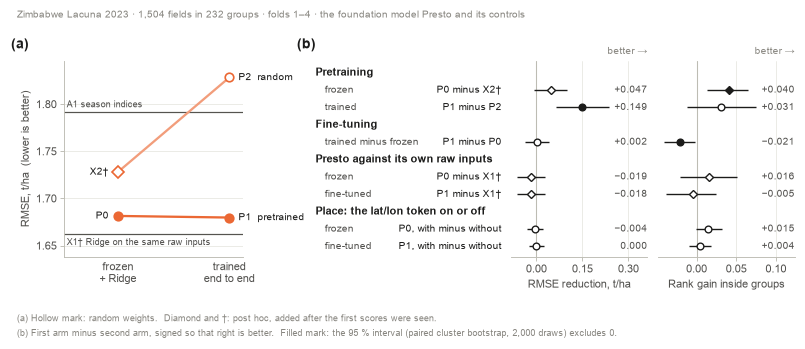

In [31]:
table = P[LACUNA]
fig = plt.figure(figsize=(FULL, 3.05))
ax, lx, forests = controls_panels(fig, LACUNA, bottom=0.250, height=0.585, heads=False)
fig.text(0.008, 0.985, f"Zimbabwe Lacuna 2023 · {len(table):,} fields in {table.group_id.nunique()} groups · folds 1–4 · "
         "the foundation model Presto and its controls", ha="left", va="top", fontsize=6.6, color=MUTED)
fig.text(0.008, 0.052, f"(a) Hollow mark: random weights.  Diamond and {DAGGER}: post hoc, added after the first scores were seen.",
         ha="left", va="bottom", fontsize=6.2, color=MUTED)
fig.text(0.008, 0.008, "(b) First arm minus second arm, signed so that right is better.  Filled mark: the 95 % interval "
         "(paired cluster bootstrap, 2,000 draws) excludes 0.", ha="left", va="bottom", fontsize=6.2, color=MUTED)
save(fig, "R02_presto_controls")

### R02b. Presto and its controls (Malawi 2022 and Malawi 2023)

**What it shows.** The same two panels as R02 for the two Malawi seasons: (a, c) RMSE by weights and training, (b, d) the saved paired contrasts for RMSE and for the rank inside 2 km groups.

**Read it like this.** As R02. Each data set has its own crop cut, so compare the patterns and not the t/ha values between the two rows.

**Take-away.** Malawi 2022 (423 fields): random weights fail, so both pretraining contrasts are clear. Frozen Presto ranks fields worse than Ridge on its own raw inputs (interval excludes 0), and the lat/lon token lowers RMSE (both intervals exclude 0): here Presto uses place. Malawi 2023 (204 fields): the intervals are wide; only the pretraining contrasts are clear.

**Source.** `experiments/presto_finetune/runs/malawi_2022/` and `runs/malawi_2023/`: `scores.csv`, `posthoc_controls.csv`.

**Caption draft.** Controls for Presto on Malawi 2022 (423 fields) and Malawi 2023 (204 fields), folds 1–4. Left: RMSE by weights and training, with Ridge on the same raw inputs (X1) and on the season indices (A1). Right: paired differences with 95 % cluster-bootstrap intervals, signed so that right is better for the first arm. † post hoc.

**Caution.** Malawi 2023 has 204 scored fields in 44 groups, so no interval is narrow. X1 and X2 are post hoc.

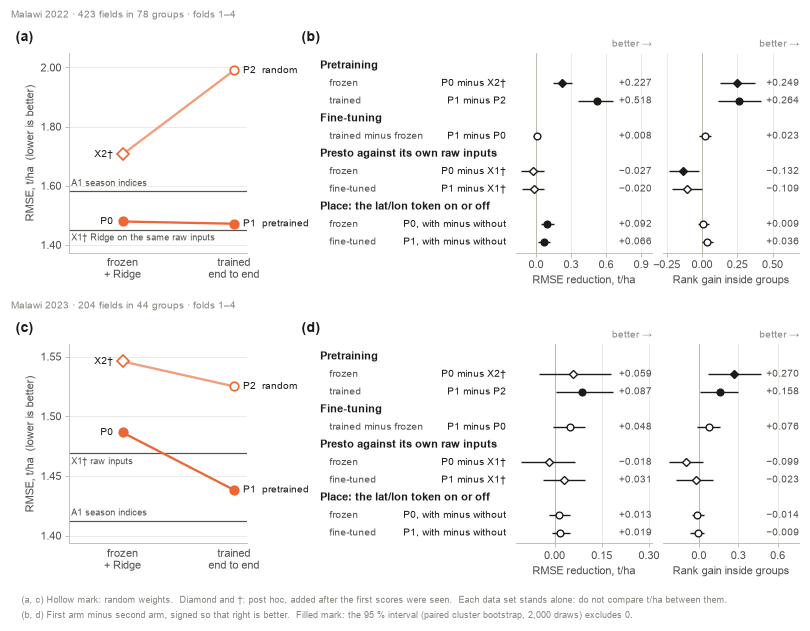

In [32]:
fig = plt.figure(figsize=(FULL, 5.75))
for cohort, bottom, letters, place in ((MALAWI22, 0.585, ("a", "b"), None),
                                       (MALAWI23, 0.125, ("c", "d"), {"X1": ("left", "below", f"{tag('X1')} raw inputs")})):
    table = P[cohort]
    ax, lx, forests = controls_panels(fig, cohort, bottom=bottom, height=0.315, letters=letters, heads=False, place=place)
    ax.annotate(f"{COHORTS[cohort]['name']} · {len(table):,} fields in {table.group_id.nunique()} groups · folds 1–4",
                xy=(0, 1), xycoords="axes fraction", xytext=(-38, 22), textcoords="offset points", va="bottom", fontsize=6.6,
                color=MUTED, annotation_clip=False)
fig.text(0.008, 0.028, f"(a, c) Hollow mark: random weights.  Diamond and {DAGGER}: post hoc, added after the first scores were seen.  "
         "Each data set stands alone: do not compare t/ha between them.", ha="left", va="bottom", fontsize=6.2, color=MUTED)
fig.text(0.008, 0.004, "(b, d) First arm minus second arm, signed so that right is better.  Filled mark: the 95 % interval "
         "(paired cluster bootstrap, 2,000 draws) excludes 0.", ha="left", va="bottom", fontsize=6.2, color=MUTED)
save(fig, "R02b_presto_controls_malawi")

### R03. Right village, wrong field (M2)

**What it shows.** The out-of-fold predictions of M2 (Ridge on the monthly band curve) for Zimbabwe Lacuna 2023, split into two parts. (a) One dot for each 2 km group: the measured group mean against the predicted group mean; the dot area is the number of fields. (b) Each field against its own group mean: measured deviation against predicted deviation (grey hexagons = number of fields).

**Read it like this.** Both panels have the same t/ha per inch, so the two clouds can be compared by eye. The pale line is 1:1; the dark line is the least-squares fit.

**Take-away.** M2 gets the village about right (R² between groups 0.47, fit slope near 1). Inside a village it knows little: R² 0.09, and the predicted deviations cover a much smaller range than the measured ones.

**Source.** `P[LACUNA]` (predictions made in the data cell with the project's functions; checked there against `experiments/stepup/results.csv`), `score()`.

**Caption draft.** M2 on Zimbabwe Lacuna 2023 (1,504 fields, 232 groups, folds 1–4). (a) Measured against predicted mean yield of each 2 km group (dot area: fields in the group). (b) Measured against predicted deviation of each field from its group mean (1,418 fields in groups of two or more). Same scale in both panels.

**Caution.** 86 of the 232 groups hold one field; such a group has no "inside". The measured deviations also hold the noise of one small crop cut, so R² inside groups cannot reach 1.

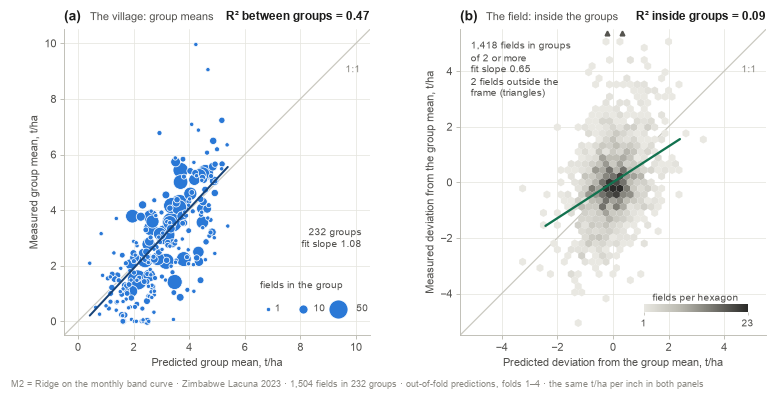

In [33]:
table = P[LACUNA]
fig = plt.figure(figsize=(FULL, 3.42))
ax, bx = village_field_panels(fig, LACUNA, "M2")
panel_title(ax, "a", "The village: group means")
panel_title(bx, "b", "The field: inside the groups")
fig.text(0.008, 0.012, f"M2 = Ridge on the monthly band curve · Zimbabwe Lacuna 2023 · {len(table):,} fields in "
         f"{table.group_id.nunique()} groups · out-of-fold predictions, folds 1–4 · the same t/ha per inch in both panels",
         ha="left", va="bottom", fontsize=6.2, color=MUTED)
save(fig, "R03_right_village_wrong_field")

### R03b. Right village, wrong field (frozen Presto)

**What it shows.** The same two panels as R03 for P0, the frozen Presto embedding with a Ridge head.

**Read it like this.** As R03: (a) group means, (b) fields against their group mean, the same t/ha per inch.

**Take-away.** The foundation model gives the same picture as Ridge on the bands: it knows the village (R² between groups 0.44) and little about the field inside the village (R² 0.09).

**Source.** `P[LACUNA]`, column `P0` (from `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/predictions.csv`), `score()`.

**Caption draft.** Frozen Presto (P0) on Zimbabwe Lacuna 2023 (1,504 fields, 232 groups, folds 1–4). (a) Measured against predicted mean yield of each 2 km group. (b) Measured against predicted deviation of each field from its group mean. Same scale in both panels.

**Caution.** As R03. Use R03 or R03b in the report, or both side by side; they answer the same question for two models.

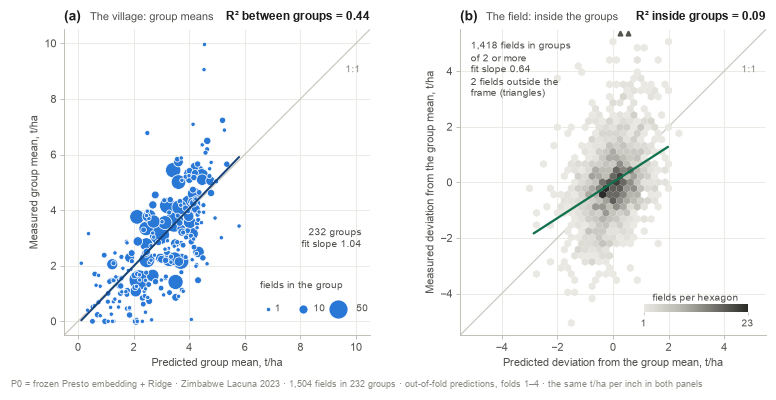

In [34]:
table = P[LACUNA]
fig = plt.figure(figsize=(FULL, 3.42))
ax, bx = village_field_panels(fig, LACUNA, "P0")
panel_title(ax, "a", "The village: group means")
panel_title(bx, "b", "The field: inside the groups")
fig.text(0.008, 0.012, f"P0 = frozen Presto embedding + Ridge · Zimbabwe Lacuna 2023 · {len(table):,} fields in "
         f"{table.group_id.nunique()} groups · out-of-fold predictions, folds 1–4 · the same t/ha per inch in both panels",
         ha="left", va="bottom", fontsize=6.2, color=MUTED)
save(fig, "R03b_right_village_wrong_field_presto")

### R04. The village–field plane

**What it shows.** Each arm as one point: how well it predicts the means of the 2 km groups (x) and how well it predicts the fields inside a group (y). Zimbabwe Lacuna 2023, folds 1–4. The grey lines join points with the same total R².

**Read it like this.** Right = the model knows the village. Up = the model knows the field. Two arms on one grey line have the same total R² but split it differently.

**Take-away.** All gains from more bands and from Presto go to the right: the arms move from 0.2–0.3 to about 0.45 between groups, and stay at 0.09 or lower inside groups. The GCVI monthly curve (7 inputs) has the highest value inside groups (0.13). Equal R² is not equal insight: A1 and the GCVI monthly curve lie near one line, but A1 has less than half of the field part.

**Source.** `experiments/stepup/results.csv` (`r2_between`, `r2_within`, `share_between`); P1 and P2 from `P[LACUNA]` with `score()`.

**Caption draft.** Skill between 2 km groups against skill inside groups for each arm on Zimbabwe Lacuna 2023 (1,504 fields, folds 1–4). Grey lines: equal total R² (56 % of the yield variance lies between groups). Orange: Presto arms (hollow: random start); blue: coordinates only.

**Caution.** The points have no intervals here; R05 gives the paired intervals against A1. X1 and X2 are missing because their per-field predictions were not saved.

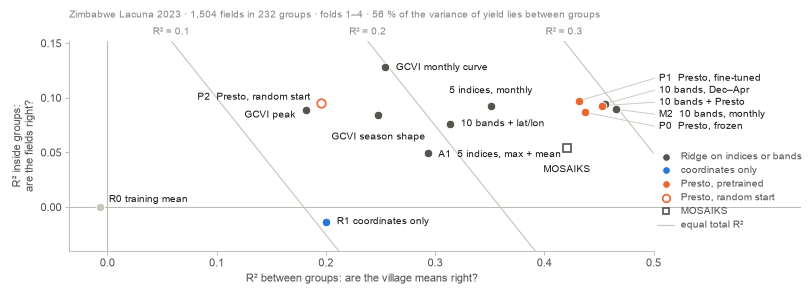

In [35]:
rows = ladder_of(LACUNA)
table = P[LACUNA]
share = rows.share_between.iloc[0]
points = {code: (r.r2_between, r.r2_within) for code, r in rows.iterrows()}
points |= {arm: (score(table, arm)["r2_between"], score(table, arm)["r2_within"]) for arm in ("P1", "P2")}
assert abs(points["S10"][0] - score(table, "P0")["r2_between"]) < 1e-6          # the ladder rung S10 is the arm P0

# name, colour, marker, filled; then where the label goes (offset in points, alignment), or a slot in the side column
STYLE = {
    "S0": ("R0 training mean", NEUTRAL_LIGHT, "o", True, (6, 5, "left")),
    "S1": ("R1 coordinates only", VILLAGE, "o", True, (7, 0, "left")),
    "S2": ("GCVI peak", NEUTRAL, "o", True, (-7, -3, "right")),
    "S3": ("GCVI season shape", NEUTRAL, "o", True, (0, -11, "center")),
    "S4": ("GCVI monthly curve", NEUTRAL, "o", True, (7, 0, "left")),
    "S5": ("A1  5 indices, max + mean", NEUTRAL, "o", True, (7, -1, "left")),
    "S6": ("5 indices, monthly", NEUTRAL, "o", True, (0, 7, "center")),
    "S9": ("10 bands + lat/lon", NEUTRAL, "o", True, (7, 0, "left")),
    "S12": ("MOSAIKS", NEUTRAL, "s", False, (0, -11, "center")),
    "P2": ("P2  Presto, random start", PRESTO, "o", False, (-7, 4, "right")),
    "P1": ("P1  Presto, fine-tuned", PRESTO, "o", True, 0),
    "S8": (f"10 bands, {PRE_HARVEST}", NEUTRAL, "o", True, 1),
    "S11": ("10 bands + Presto", PRESTO, "o", True, 2),
    "S7": ("M2  10 bands, monthly", NEUTRAL, "o", True, 3),
    "S10": ("P0  Presto, frozen", PRESTO, "o", True, 4),
}

fig = plt.figure(figsize=(FULL, 2.62))
ax = fig.add_axes([0.068, 0.165, 0.924, 0.745])
x0, x1, y0, y1 = -0.035, 0.635, -0.040, 0.152
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_aspect("equal")
ax.axhline(0, color=AXIS, linewidth=0.7, zorder=1)
ax.axvline(0, color=AXIS, linewidth=0.7, zorder=1)
for total in (0.1, 0.2, 0.3):                       # lines of equal R2: share x between + (1 - share) x inside = total
    b = np.array([0.0, 0.5])
    w = (total - share * b) / (1 - share)
    ax.plot(b, w, color=NEUTRAL_LIGHT, linewidth=0.8, zorder=1)
    top = (total - (1 - share) * y1) / share
    ax.annotate(f"R² = {total:.1f}", (top, y1), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                fontsize=6.3, color=MUTED, annotation_clip=False)

column_x, column_y = 0.505, [0.118, 0.107, 0.096, 0.085, 0.074]
for code, (name, color, marker, filled, where) in STYLE.items():
    b, w = points[code]
    ax.plot(b, w, marker, ms=5.6 if marker == "o" else 5.0, mfc=color if filled else PAPER, mec=PAPER if filled else color,
            mew=0.6 if filled else 1.1, zorder=4)
    if isinstance(where, int):                      # the knot of monthly bands and Presto: labels in a side column
        ax.plot([b, column_x - 0.004], [w, column_y[where]], color=NEUTRAL_LIGHT, linewidth=0.6, zorder=2)
        ax.text(column_x, column_y[where], name, ha="left", va="center", fontsize=6.6, color=INK)
    else:
        dx, dy, ha = where
        ax.annotate(name, (b, w), xytext=(dx, dy), textcoords="offset points", ha=ha,
                    va="center" if dy in (0, -1, -3, 4, 5) else ("bottom" if dy > 0 else "top"), fontsize=6.6, color=INK)

# Key of the marks, under the side column.
key = [("o", NEUTRAL, True, "Ridge on indices or bands"), ("o", VILLAGE, True, "coordinates only"),
       ("o", PRESTO, True, "Presto, pretrained"), ("o", PRESTO, False, "Presto, random start"), ("s", NEUTRAL, False, "MOSAIKS")]
for k, (marker, color, filled, text) in enumerate(key):
    y = 0.046 - 0.0125 * k
    ax.plot(column_x + 0.006, y, marker, ms=5.0 if marker == "o" else 4.5, mfc=color if filled else PAPER,
            mec=PAPER if filled else color, mew=0.6 if filled else 1.1)
    ax.text(column_x + 0.020, y, text, ha="left", va="center", fontsize=6.3, color=INK2)
ax.plot([column_x - 0.002, column_x + 0.014], [0.046 - 0.0125 * len(key)] * 2, color=NEUTRAL_LIGHT, linewidth=0.8)
ax.text(column_x + 0.020, 0.046 - 0.0125 * len(key), "equal total R²", ha="left", va="center", fontsize=6.3, color=INK2)

ax.set_xticks(np.arange(0, 0.51, 0.1))
ax.set_yticks(np.arange(0, 0.151, 0.05))
ax.spines["bottom"].set_bounds(x0, 0.5)
ax.set_xlabel("R² between groups: are the village means right?", x=0.40)
ax.set_ylabel("R² inside groups:\nare the fields right?")
ax.annotate(f"Zimbabwe Lacuna 2023 · {len(table):,} fields in {table.group_id.nunique()} groups · folds 1–4 · "
            f"{100 * share:.0f} % of the variance of yield lies between groups", xy=(0, 1), xycoords="axes fraction",
            xytext=(0, 14), textcoords="offset points", va="bottom", fontsize=6.6, color=MUTED)
save(fig, "R04_village_field_plane")

### R05. Ladder ledger: the table as a figure

**What it shows.** Every rung of the step-up ladder for Zimbabwe Lacuna 2023 with all its scores in one row: number of inputs, R², R² between and inside the 2 km groups, the rank inside groups, and the paired RMSE difference against A1 with its 95 % interval on one shared zero line.

**Read it like this.** Each bar column has its own scale, printed under the header, so compare bars inside a column only. The hollow circle in the R² column is the R² on the training folds. In the last column, left of 0 is better than A1; a filled mark means that the interval excludes 0.

**Take-away.** Four rungs lower RMSE against A1 with an interval that excludes 0: the monthly bands (all months and pre-harvest months), the frozen Presto embedding, and the bands with Presto. They are not separable from one another. No rung passes the Holm correction for the rank inside groups.

**Source.** `experiments/stepup/results.csv` (Ridge rows). The cell also prints the same numbers as a LaTeX `booktabs` table.

**Caption draft.** Step-up ladder on Zimbabwe Lacuna 2023 (1,504 fields, 232 groups, folds 1–4, Ridge head). Bars: R², R² between and inside 2 km groups; line: Spearman rank inside groups; last column: RMSE minus A1 with 95 % paired cluster-bootstrap interval.

**Caution.** The GCVI peak (S2) is worse than A1 on RMSE (interval above 0). Coordinates added to the bands (S9) lose most of the gain of the bands.

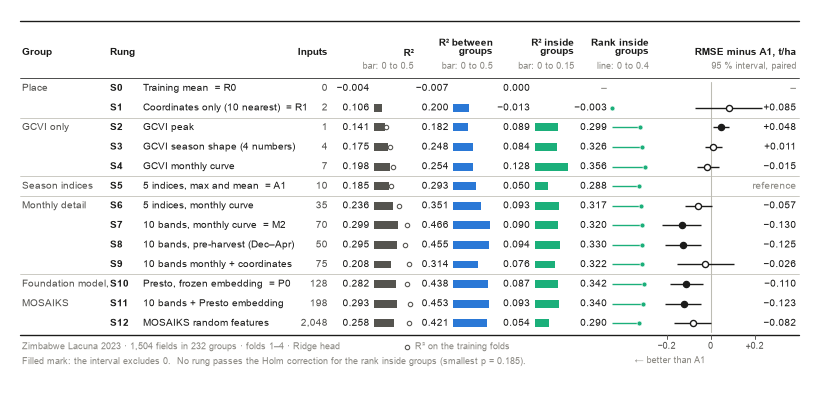

\begin{tabular}{@{}llrrrrrl@{}}
\toprule
Rung & Features & Inputs & $R^2$ & $R^2_\text{between}$ & $R^2_\text{inside}$ & Rank & RMSE $-$ A1 (95\,\% interval) \\
\midrule
S0 & Training mean & 0 & $-0.004$ & $-0.007$ & $0.000$ & -- & -- \\
S1 & Coordinates only (10 nearest) & 2 & $0.106$ & $0.200$ & $-0.013$ & -0.003 & $+0.085$ ($-0.070$ to $+0.234$) \\
\addlinespace[2pt]
S2 & GCVI peak & 1 & $0.141$ & $0.182$ & $0.089$ & 0.299 & $+0.048$ ($+0.013$ to $+0.083$) \\
S3 & GCVI season shape (4 numbers) & 4 & $0.175$ & $0.248$ & $0.084$ & 0.326 & $+0.011$ ($-0.026$ to $+0.051$) \\
S4 & GCVI monthly curve & 7 & $0.198$ & $0.254$ & $0.128$ & 0.356 & $-0.015$ ($-0.064$ to $+0.040$) \\
\addlinespace[2pt]
S5 & 5 indices, max and mean & 10 & $0.185$ & $0.293$ & $0.050$ & 0.288 & reference \\
\addlinespace[2pt]
S6 & 5 indices, monthly curve & 35 & $0.236$ & $0.351$ & $0.093$ & 0.317 & $-0.057$ ($-0.118$ to $+0.007$) \\
S7 & 10 bands, monthly curve & 70 & $0.299$ & $0.466$ & $0.090$ & 0.320 & $-0.130

In [36]:
rows = ladder_of(LACUNA)
table = P[LACUNA]
pitch, top = 0.178, 0.62                               # row height and the height of the header block, in inches
height = top + pitch * len(rows) + 0.50
fig = plt.figure(figsize=(FULL, height))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, FULL)
ax.set_ylim(height, 0)
ax.axis("off")

# Columns in inches: where the number ends, where the bar starts, the bar length of the full scale, the full scale.
BARS = {"r2": (3.26, 3.30, 0.36, 0.5, NEUTRAL, "R²"), "r2_between": (3.98, 4.02, 0.36, 0.5, VILLAGE, "R² between\ngroups"),
        "r2_within": (4.72, 4.76, 0.36, 0.15, FIELD, "R² inside\ngroups"),
        "rank_inside_clusters": (5.42, 5.46, 0.34, 0.4, FIELD, "Rank inside\ngroups")}
ZERO, PER_T = 6.36, 2.0                                # the forest column: x of zero, inches for 1 t/ha

head = {"fontsize": 6.8, "fontweight": "bold", "color": INK, "va": "bottom", "linespacing": 1.05}
ax.text(0.10, top - 0.19, "Group", **head)
ax.text(0.90, top - 0.19, "Rung", **head)
ax.text(2.88, top - 0.19, "Inputs", ha="right", **head)
for key, (number, start, length, scale, color, name) in BARS.items():
    ax.text(start + length, top - 0.19, name, ha="right", **head)
    ax.text(start + length, top - 0.07, f"{'line' if key.startswith('rank') else 'bar'}: 0 to {scale:g}", ha="right",
            va="bottom", fontsize=6.0, color=MUTED)
ax.text(7.14, top - 0.19, "RMSE minus A1, t/ha", ha="right", **head)
ax.text(7.14, top - 0.07, "95 % interval, paired", ha="right", va="bottom", fontsize=6.0, color=MUTED)
for y, width, color in ((0.10, 0.9, INK), (top, 0.5, INK), (top + pitch * len(rows) + 0.02, 0.9, INK)):
    ax.plot([0.08, 7.16], [y, y], color=color, linewidth=width)
ax.plot([ZERO, ZERO], [top + 0.03, top + pitch * len(rows) - 0.01], color=AXIS, linewidth=0.7)

previous = None
for i, (code, r) in enumerate(rows.iterrows()):
    y = top + pitch * (i + 0.5)
    short, group, name = RUNGS[code]
    if group != previous:
        if previous is not None:
            ax.plot([0.08, 7.16], [y - pitch / 2] * 2, color=AXIS, linewidth=0.5)
        ax.text(0.10, y, group.replace(", MOSAIKS", ","), va="center", fontsize=6.5, color=INK2)
        if group.endswith("MOSAIKS"):
            ax.text(0.10, y + pitch, "MOSAIKS", va="center", fontsize=6.5, color=INK2)
        previous = group
    ax.text(0.90, y, code, va="center", fontsize=6.6, fontweight="bold")
    ax.text(1.20, y, name + (f"  = {RUNG_ARM[code]}" if code in RUNG_ARM else ""), va="center", fontsize=6.6)
    ax.text(2.88, y, f"{int(r.n_features):,}", ha="right", va="center", fontsize=6.6, color=INK2)
    for key, (number, start, length, scale, color, _) in BARS.items():
        value = r[key]
        if not np.isfinite(value):
            ax.text(number, y, "–", ha="right", va="center", fontsize=6.6, color=MUTED)
            continue
        ax.text(number, y, num(value, 3), ha="right", va="center", fontsize=6.6)
        size = length * min(max(value, 0), scale) / scale
        if key == "rank_inside_clusters":            # a rank is a correlation, not a share: a line with a dot
            ax.plot([start, start + size], [y, y], color=color, linewidth=0.9, solid_capstyle="butt")
            ax.plot(start + size, y, "o", ms=3.2, mfc=color, mec=PAPER, mew=0.4)
        elif size > 0.004:
            ax.add_patch(Rectangle((start, y - 0.036), size, 0.072, facecolor=color, edgecolor="none"))
        if key == "r2" and np.isfinite(r.train_r2):   # R2 on the training folds
            ax.plot(start + length * r.train_r2 / scale, y, "o", ms=2.9, mfc=PAPER, mec=NEUTRAL, mew=0.7)
    if np.isfinite(r.rmse_vs_A1):
        lo, hi, est = ZERO + PER_T * r.rmse_lo, ZERO + PER_T * r.rmse_hi, ZERO + PER_T * r.rmse_vs_A1
        solid = r.rmse_lo > 0 or r.rmse_hi < 0
        ax.plot([lo, hi], [y, y], color=INK, linewidth=0.9, solid_capstyle="butt")
        ax.plot(est, y, "o", ms=4.0, mfc=INK if solid else PAPER, mec=INK, mew=0.9)
        ax.text(7.14, y, num(r.rmse_vs_A1, 3, True), ha="right", va="center", fontsize=6.6)
    else:
        ax.text(7.14, y, "reference" if code == "S5" else "–", ha="right", va="center", fontsize=6.6, color=MUTED)

base = top + pitch * len(rows) + 0.02
for value in (-0.2, 0.0, 0.2):
    ax.plot([ZERO + PER_T * value] * 2, [base, base + 0.035], color=INK2, linewidth=0.6)
    ax.text(ZERO + PER_T * value, base + 0.06, num(value, 1, True) if value else "0", ha="center", va="top", fontsize=6.2, color=INK2)
ax.text(ZERO - 0.05, base + 0.19, "← better than A1", ha="right", va="top", fontsize=6.2, color=MUTED)
ax.plot(3.30 + 0.36 * 0.42 / 0.5, base + 0.105, "o", ms=2.9, mfc=PAPER, mec=NEUTRAL, mew=0.7)
ax.text(3.30 + 0.36 * 0.42 / 0.5 + 0.07, base + 0.105, "R² on the training folds", va="center", fontsize=6.2, color=MUTED)
ax.text(0.10, base + 0.105, f"Zimbabwe Lacuna 2023 · {len(table):,} fields in {table.group_id.nunique()} groups · folds 1–4 · "
        "Ridge head", va="center", fontsize=6.2, color=MUTED)
ax.text(0.10, base + 0.24, "Filled mark: the interval excludes 0.  No rung passes the Holm correction for the rank inside groups "
        f"(smallest p = {rows.p_rank_holm.min():.3f}).", va="center", fontsize=6.2, color=MUTED)
save(fig, "R05_ladder_ledger")

# The same numbers as a LaTeX table (booktabs); paste it into the report.
lines = [r"\begin{tabular}{@{}llrrrrrl@{}}", r"\toprule",
         r"Rung & Features & Inputs & $R^2$ & $R^2_\text{between}$ & $R^2_\text{inside}$ & Rank & RMSE $-$ A1 (95\,\% interval) \\",
         r"\midrule"]
previous = None
for code, r in rows.iterrows():
    if previous not in (None, RUNGS[code][1]):
        lines.append(r"\addlinespace[2pt]")
    previous = RUNGS[code][1]
    rank = "--" if not np.isfinite(r.rank_inside_clusters) else f"{r.rank_inside_clusters:.3f}"
    diff = ("reference" if code == "S5" else "--") if not np.isfinite(r.rmse_vs_A1) else \
        f"${r.rmse_vs_A1:+.3f}$ (${r.rmse_lo:+.3f}$ to ${r.rmse_hi:+.3f}$)"
    name = RUNGS[code][2].replace("–", "--")
    lines.append(f"{code} & {name} & {int(r.n_features):,} & ${r.r2:.3f}$ & ${r.r2_between:.3f}$ & ${r.r2_within:.3f}$ & "
                 f"{rank} & {diff} \\\\")
lines += [r"\bottomrule", r"\end{tabular}"]
print("\n".join(lines))

### R06. Travel matrix: the same arms in five data sets, and the season transfer

**What it shows.** (a) The R² of each arm in each data set (folds 1–4, each data set alone). The tint is the R² minus the "address line" of the row: the better of coordinates only and the training mean. A dot shows the paired RMSE interval against coordinates: filled = excludes 0, hollow = includes 0. (b) Train on one season and rank the fields of the other: Spearman of the index model (A1) minus Spearman of coordinates (R1), with the saved 95 % interval.

**Read it like this.** Red = the arm beats the address line; blue = the address line is better. Read along a row. Do not compare numbers between rows: the crop cuts differ.

**Take-away.** The light beats the address in Zimbabwe Lacuna and in Malawi 2022. In Zimbabwe 2024 it is a tie, and in Kenya the coordinates are better than every Ridge arm on the Sentinel-2 values. In the season transfer, the index model ranks the other season better than coordinates in Malawi 2022 → 2023 only; in Kenya 2020 → 2019 it is worse.

**Source.** `experiments/stepup/results.csv`; `experiments/presto_finetune/runs/*/scores.csv` and `posthoc_controls.csv`; `P` for the paired RMSE intervals against R1; `results/v2/data_v2_comparison.csv` for (b).

**Caption draft.** (a) R² of each arm in five data sets (folds 1–4; tint: R² minus the better of coordinates only and the training mean; dot: paired RMSE interval against coordinates excludes 0 (filled) or not (hollow)). (b) Season transfer: Spearman of the index model minus Spearman of coordinates in the other season, with 95 % interval.

**Caution.** Here the tint uses max(0, R² of coordinates), not the raw R² of coordinates: in Malawi 2023 coordinates are worse than the mean (−0.15), and the raw difference would flatter every arm. Season transfer is a new season, not a new place: 10–53 % of the test fields lie within 2 km of a training field.

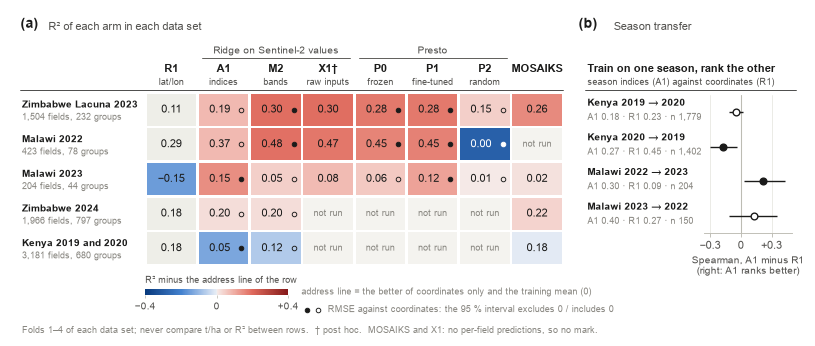

In [37]:
# R2 of each arm in each data set (each data set stands alone), and the season transfer.
COLUMNS = [("R1", "S1", "R1", "lat/lon"), ("A1", "S5", "A1", "indices"), ("M2", "S7", "M2", "bands"),
           ("X1", None, tag("X1"), "raw inputs"), ("P0", "S10", "P0", "frozen"), ("P1", None, "P1", "fine-tuned"),
           ("P2", None, "P2", "random"), ("MOSAIKS", "S12", "MOSAIKS", "")]
value, mark = {}, {}
for cohort in COHORTS:
    rungs = ladder_of(cohort)
    saved = presto_arms(cohort) if cohort in presto else None
    for arm, rung, _, _ in COLUMNS:
        if rung in rungs.index:
            value[cohort, arm] = rungs.r2[rung]
        elif saved is not None and arm in saved.index:
            value[cohort, arm] = saved.r2[arm]
        if arm in ("A1", "M2", "P0", "P1", "P2") and arm in P[cohort]:      # paired RMSE interval against coordinates
            _, low, high = paired_rmse(P[cohort], arm, "R1")
            mark[cohort, arm] = (low > 0) or (high < 0)
address = {cohort: max(0.0, value[cohort, "R1"]) for cohort in COHORTS}    # the better of coordinates only and the mean
order = sorted(COHORTS, key=lambda c: value[c, "M2"] - address[c], reverse=True)

H = 2.92
fig = plt.figure(figsize=(FULL, H))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, FULL)
ax.set_ylim(H, 0)
ax.axis("off")
left, top, cw, ch = 1.22, 0.74, 0.475, 0.315
norm = Normalize(-0.4, 0.4)
for j, (arm, _, code, name) in enumerate(COLUMNS):
    ax.text(left + cw * (j + 0.5), top - 0.165, code, ha="center", va="bottom", fontsize=6.9, fontweight="bold")
    ax.text(left + cw * (j + 0.5), top - 0.05, name, ha="center", va="bottom", fontsize=6.0, color=INK2)
for first, last, name in ((1, 3, "Ridge on Sentinel-2 values"), (4, 6, "Presto")):
    ax.plot([left + cw * first + 0.04, left + cw * (last + 1) - 0.04], [top - 0.315] * 2, color=NEUTRAL, linewidth=0.6)
    ax.text(left + cw * (first + last + 1) / 2, top - 0.335, name, ha="center", va="bottom", fontsize=6.3, color=INK2)
for i, cohort in enumerate(order):
    y = top + ch * i
    ax.text(0.10, y + ch * 0.36, COHORTS[cohort]["name"], va="center", fontsize=6.8, fontweight="bold")
    ax.text(0.10, y + ch * 0.72, f"{len(P[cohort]):,} fields, {P[cohort].group_id.nunique()} groups", va="center",
            fontsize=6.0, color=MUTED)
    for j, (arm, _, _, _) in enumerate(COLUMNS):
        x = left + cw * j
        if (cohort, arm) not in value:
            ax.add_patch(Rectangle((x + 0.012, y + 0.012), cw - 0.024, ch - 0.024, facecolor="#f4f3ef", edgecolor="none"))
            ax.text(x + cw / 2, y + ch / 2, "not run", ha="center", va="center", fontsize=6.0, color=MUTED)
            continue
        lift = value[cohort, arm] - address[cohort]
        ink = INK if abs(lift) < 0.27 else PAPER
        ax.add_patch(Rectangle((x + 0.012, y + 0.012), cw - 0.024, ch - 0.024, facecolor=SIGNED(norm(lift)), edgecolor="none"))
        ax.text(x + cw / 2 - (0.035 if (cohort, arm) in mark else 0), y + ch / 2, num(value[cohort, arm], 2), ha="center",
                va="center", fontsize=7, color=ink)
        if (cohort, arm) in mark:
            ax.plot(x + cw - 0.075, y + ch / 2, "o", ms=3.0, mfc=ink if mark[cohort, arm] else "none", mec=ink, mew=0.6)
ax.plot([0.08, left + cw * len(COLUMNS)], [top - 0.02] * 2, color=INK, linewidth=0.5)
ax.text(0.34, 0.10, "R² of each arm in each data set", va="top", fontsize=7.2, color=INK2)
panel(ax, "a", x=0.012, y=1.0, dy=-13)

# Key under the matrix.
ky = top + ch * len(order) + 0.21
cax = fig.add_axes([left / FULL, 1 - (ky + 0.06) / H, 1.30 / FULL, 0.06 / H])
colorbar(fig, mpl.cm.ScalarMappable(norm, SIGNED), cax=cax, orientation="horizontal", ticks=[-0.4, 0, 0.4])
cax.set_xticklabels([num(-0.4, 1, True), "0", num(0.4, 1, True)])
ax.text(left, ky - 0.035, "R² minus the address line of the row", va="bottom", fontsize=6.2, color=INK2)
ax.text(left + 1.42, ky + 0.03, "address line = the better of coordinates only and the training mean (0)", va="center",
        fontsize=6.0, color=MUTED)
ax.plot(left + 1.47, ky + 0.19, "o", ms=3.0, mfc=INK, mec=INK, mew=0.6)
ax.plot(left + 1.57, ky + 0.19, "o", ms=3.0, mfc=PAPER, mec=INK, mew=0.6)
ax.text(left + 1.66, ky + 0.19, "RMSE against coordinates: the 95 % interval excludes 0 / includes 0", va="center",
        fontsize=6.0, color=MUTED)
ax.text(0.10, ky + 0.38, f"Folds 1–4 of each data set; never compare t/ha or R² between rows.  {DAGGER} post hoc.  "
        "MOSAIKS and X1: no per-field predictions, so no mark.", va="center", fontsize=6.0, color=MUTED)

# (b) Season transfer: train on one season, rank the fields of the other; the index model against coordinates.
moves = pd.read_csv(REPO / "results" / "v2" / "data_v2_comparison.csv")
moves = moves[moves.test.isin(["season_transfer", "kenya_transfer"])].set_index(["cohort", "metric"])
tx = 5.24                                                      # left edge of panel (b), inches
bx = fig.add_axes([6.30 / FULL, 1 - (top + ch * 4 + 0.02) / H, 0.80 / FULL, ch * 4 / H])
names = {"kenya 2019 -> 2020": "Kenya 2019 → 2020", "kenya 2020 -> 2019": "Kenya 2020 → 2019",
         "malawi_2022 -> malawi_2023": "Malawi 2022 → 2023", "malawi_2023 -> malawi_2022": "Malawi 2023 → 2022"}
for k, (key, name) in enumerate(names.items()):
    diff = moves.loc[(key, "spearman_A1_minus_R1")]
    interval(bx, k, diff.value, diff.ci_low, diff.ci_high)
    y = top + ch * (k + 0.5)
    ax.text(tx, y - 0.06, name, va="center", fontsize=6.6, fontweight="bold")
    ax.text(tx, y + 0.07, f"A1 {num(moves.loc[(key, 'spearman_A1')].value, 2)} · R1 {num(moves.loc[(key, 'spearman_R1')].value, 2)}"
            f" · n {int(diff.n_rows):,}", va="center", fontsize=6.0, color=MUTED)
bx.set_ylim(3.5, -0.5)
bx.set_xlim(-0.36, 0.50)
zero_line(bx)
bx.set_yticks([])
bx.spines["left"].set_visible(False)
bx.set_xticks([-0.3, 0, 0.3], [num(-0.3, 1, True), "0", num(0.3, 1, True)])
hgrid(bx, "x")
bx.set_xlabel("Spearman, A1 minus R1\n(right: A1 ranks better)", fontsize=6.3, linespacing=1.15)
ax.text(tx, top - 0.165, "Train on one season, rank the other", va="bottom", fontsize=6.9, fontweight="bold")
ax.text(tx, top - 0.05, "season indices (A1) against coordinates (R1)", va="bottom", fontsize=6.0, color=INK2)
ax.plot([tx - 0.02, 7.14], [top - 0.02] * 2, color=INK, linewidth=0.5)
ax.text(tx + 0.24, 0.10, "Season transfer", va="top", fontsize=7.2, color=INK2)
panel(ax, "b", x=(tx - 0.08) / FULL, y=1.0, dy=-13)
save(fig, "R06_travel_matrix")

### R07. Fold 0: the order survived the one look

**What it shows.** (a) The R² of six arms in development (folds 1–4, cross-validation) and on the held-back fold 0 (376 fields, models trained on folds 1–4, one logged look). (b) The paired RMSE difference against A1 in both samples, with 95 % intervals.

**Read it like this.** In (a) read the order of the lines at each end, not their slope: fold 0 is another sample with another mean yield, and its models train on more fields. In (b) left of 0 is better than A1; grey is development and black is fold 0.

**Take-away.** The order is the same on the held-back fold: monthly bands, raw inputs and Presto on top, the season indices below, then coordinates and the training mean. M2 and X1 beat A1 on RMSE in both samples; for P0 the fold-0 interval touches 0.

**Source.** `experiments/fold0/looks.csv` and the run it names (`scores.csv`); `experiments/stepup/results.csv`; `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/posthoc_controls.csv` (X1).

**Caption draft.** Development scores (folds 1–4, 1,504 fields) and the held-back fold 0 (376 fields, one logged look) on Zimbabwe Lacuna 2023. (a) R² per arm. (b) RMSE minus A1 with 95 % paired cluster-bootstrap intervals (grey: folds 1–4; black: fold 0). † post hoc.

**Caution.** Fold 0 is a logged check, not a blind test: R0, R1 and A1 were scored on it before. Its fields yield 0.56 t/ha more than the other folds, so every model predicts too low there.

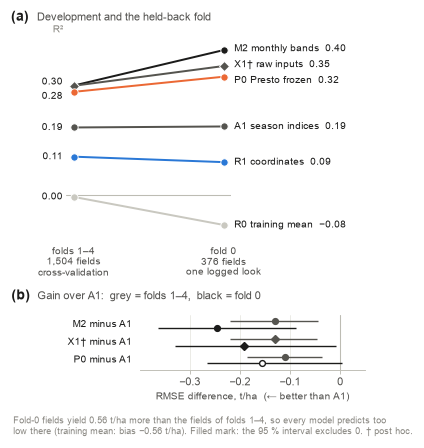

In [38]:
rows, saved = ladder_of(LACUNA), presto_arms(LACUNA)
d = D[LACUNA]
dev_r2 = {"R0": rows.r2["S0"], "R1": rows.r2["S1"], "A1": rows.r2["S5"], "M2": rows.r2["S7"], "P0": rows.r2["S10"],
          "X1": saved.r2["X1"]}
held = fold0_scores.r2
STYLE = {"M2": (INK, "o"), "X1": (NEUTRAL, "D"), "P0": (PRESTO, "o"), "A1": (NEUTRAL, "o"), "R1": (VILLAGE, "o"),
         "R0": (NEUTRAL_LIGHT, "o")}
NAMES = {"M2": "M2 monthly bands", "X1": f"{tag('X1')} raw inputs", "P0": "P0 Presto frozen", "A1": "A1 season indices",
         "R1": "R1 coordinates", "R0": "R0 training mean"}

fig = plt.figure(figsize=(COL, 4.0))
ax = inch_axes(fig, 0.55, 0.32, 1.50, 1.82)
for arm, (color, marker) in STYLE.items():
    ax.plot([0, 1], [dev_r2[arm], held[arm]], color=color, linewidth=1.3, zorder=3)
    ax.plot([0, 1], [dev_r2[arm], held[arm]], marker, ms=4.8 if marker == "o" else 4.2, mfc=color, mec=PAPER, mew=0.6,
            linestyle="none", zorder=4)
# Direct labels: the arm and its fold-0 value at the right end, the development value at the left end.
nudge = {"M2": 0.004, "X1": 0.004, "P0": -0.010}
for arm in STYLE:
    ax.annotate(f"{NAMES[arm]}  {num(held[arm], 2)}", (1, held[arm] + nudge.get(arm, 0)), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=6.5, annotation_clip=False)
assert abs(dev_r2["M2"] - dev_r2["X1"]) < 0.005                       # M2 and X1 share one label at the left end
for arm, shift in (("M2", 0.010), ("P0", -0.012), ("A1", 0), ("R1", 0), ("R0", 0)):
    ax.annotate(num(dev_r2[arm], 2), (0, dev_r2[arm] + shift), xytext=(-7, 0), textcoords="offset points", ha="right",
                va="center", fontsize=6.5, annotation_clip=False)
ax.axhline(0, color=AXIS, linewidth=0.7, zorder=1)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.115, 0.43)
n_dev, n_held = int(d["dev"].sum()), int((~d["dev"]).sum())
ax.set_xticks([0, 1], [f"folds 1–4\n{n_dev:,} fields\ncross-validation", f"fold 0\n{n_held} fields\none logged look"],
              fontsize=6.5, linespacing=1.15)
ax.tick_params(axis="x", length=0, pad=5)
ax.set_yticks([])
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.annotate("R²", (0, 0.43), xytext=(-7, 2), textcoords="offset points", ha="right", va="bottom", fontsize=6.5, color=MUTED,
            annotation_clip=False)
panel(ax, "a", x=0, dx=-36, dy=9)
ax.annotate("Development and the held-back fold", xy=(0, 1), xycoords="axes fraction", xytext=(-19, 9.6),
            textcoords="offset points", fontsize=7.2, color=INK2, va="bottom")

# (b) The paired RMSE differences against A1 in both samples, on one axis.
bx = inch_axes(fig, 1.22, 2.84, 2.05, 0.50)
pairs = [("M2", rows.loc["S7", ["rmse_vs_A1", "rmse_lo", "rmse_hi"]].to_numpy(dtype=float)),
         ("X1", presto_pair(LACUNA, "X1", "A1")[["rmse_diff", "rmse_low", "rmse_high"]].to_numpy(dtype=float)),
         ("P0", rows.loc["S10", ["rmse_vs_A1", "rmse_lo", "rmse_hi"]].to_numpy(dtype=float))]
for k, (arm, dev) in enumerate(pairs):
    look = fold0_scores.loc[arm, ["rmse_vs_A1", "rmse_lo", "rmse_hi"]].to_numpy(dtype=float)
    marker = "D" if arm in POST_HOC else "o"
    interval(bx, k - 0.19, *dev, color=NEUTRAL, marker=marker, size=3.8)
    interval(bx, k + 0.19, *look, color=INK, marker=marker, size=3.8)
    bx.annotate(f"{tag(arm)} minus A1", (0, k), xycoords=("axes fraction", "data"), xytext=(-5, 0),
                textcoords="offset points", ha="right", va="center", fontsize=6.5, annotation_clip=False)
bx.set_ylim(2.55, -0.55)
bx.set_xlim(-0.40, 0.05)
zero_line(bx)
bx.set_yticks([])
bx.spines["left"].set_visible(False)
bx.set_xticks([-0.3, -0.2, -0.1, 0], [num(-0.3, 1), num(-0.2, 1), num(-0.1, 1), "0"])
hgrid(bx, "x")
bx.set_xlabel("RMSE difference, t/ha  (← better than A1)", fontsize=6.5)
panel(bx, "b", x=0, dx=-84, dy=8)
bx.annotate("Gain over A1:  grey = folds 1–4,  black = fold 0", xy=(0, 1), xycoords="axes fraction", xytext=(-67, 8.6),
            textcoords="offset points", fontsize=7.2, color=INK2, va="bottom")

gap = d["y"][~d["dev"]].mean() - d["y"][d["dev"]].mean()
fig.text(0.02, 0.012, f"Fold-0 fields yield {num(gap, 2)} t/ha more than the fields of folds 1–4, so every model predicts too\n"
         f"low there (training mean: bias {num(fold0_scores.bias['R0'], 2)} t/ha). Filled mark: the 95 % interval excludes 0. "
         f"{DAGGER} post hoc.", ha="left", va="bottom", fontsize=6.0, color=MUTED, linespacing=1.25)
save(fig, "R07_fold0_slope")

### R08. Season clock: when and where in the light the signal is

**What it shows.** (a) The Spearman correlation of the GCVI of each month with yield (Zimbabwe Lacuna 2023, folds 1–4): for all fields, for the means of the 2 km groups, and inside the groups. (b) and (c) The M2 model with one block shuffled across the test fields: one month (all bands), or one band (all months). Grey = drop in R², green = drop in the rank inside groups.

**Read it like this.** In (a) a point above 0 means "greener in that month, higher yield". In (b) and (c) a long stem means that the model leans on that block.

**Take-away.** The signal is in January and February, between villages and inside them. From April on, the greenness inside a village points the other way (about −0.1), and the months after March add little to M2. The model uses all four parts of the spectrum.

**Source.** `experiments/stepup/gcvi_months.csv` and `experiments/stepup/importance.csv`.

**Caption draft.** (a) Spearman correlation of monthly GCVI with yield for all fields, between and inside 2 km groups (Zimbabwe Lacuna 2023, folds 1–4). (b, c) Drop in R² and in the rank inside groups of M2 when one month or one band is shuffled across the test fields.

**Caution.** Do not write "the most informative band". The bands are strongly correlated, so a shuffle drop can be larger than the R² of the model and it says how the Ridge weights are spread, not where the information is. January and February are also the cloudiest months (fewer fields with a clear image).

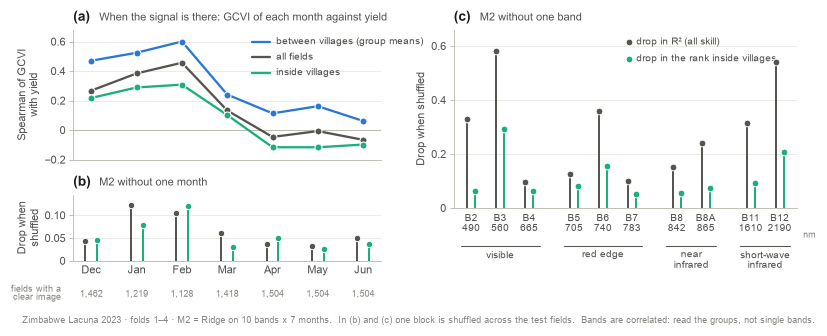

In [39]:
months = gcvi_months[gcvi_months.cohort == LACUNA].sort_values("k")
drops = importance[importance.cohort == LACUNA].set_index("block")
names = [MONTH_NAME[int(m)] for m in months.months]
xs = np.arange(len(months))

fig = plt.figure(figsize=(FULL, 3.02))
ax = inch_axes(fig, 0.52, 0.30, 2.80, 1.18)
series = (("between_clusters", VILLAGE, "between villages (group means)"), ("all", NEUTRAL, "all fields"),
          ("inside_clusters", FIELD, "inside villages"))
for k, (column, color, name) in enumerate(series):
    ax.plot(xs, months[column], color=color, linewidth=1.5, zorder=3)
    ax.plot(xs, months[column], "o", ms=4.6, mfc=color, mec=PAPER, mew=0.7, zorder=4)
    ax.plot([3.55, 3.95], [0.60 - 0.105 * k] * 2, color=color, linewidth=1.5)
    ax.text(4.08, 0.60 - 0.105 * k, name, va="center", fontsize=6.5, color=INK2)
zero_line(ax, horizontal=True)
ax.set_xlim(-0.4, len(xs) - 0.6)
ax.set_ylim(-0.2, 0.68)
ax.set_yticks([-0.2, 0, 0.2, 0.4, 0.6], [num(-0.2, 1), "0", "0.2", "0.4", "0.6"])
ax.set_xticks(xs, [])
ax.tick_params(axis="x", length=0)
ax.set_ylabel("Spearman of GCVI\nwith yield", linespacing=1.1)
hgrid(ax)
panel_title(ax, "a", "When the signal is there: GCVI of each month against yield")

bx = inch_axes(fig, 0.52, 1.80, 2.80, 0.60)
for column, color, shift in (("r2_drop", NEUTRAL, -0.13), ("rank_drop", FIELD, 0.13)):
    values = [drops.loc[f"month {k}", column] for k in months.k]
    bx.vlines(xs + shift, 0, values, color=color, linewidth=1.3, zorder=3)
    bx.plot(xs + shift, values, "o", ms=4.2, mfc=color, mec=PAPER, mew=0.6, zorder=4)
bx.set_xlim(-0.4, len(xs) - 0.6)
bx.set_ylim(0, 0.145)
bx.set_yticks([0, 0.05, 0.1], ["0", "0.05", "0.10"])
bx.set_xticks(xs, names)
bx.tick_params(axis="x", length=0, pad=3)
bx.set_ylabel("Drop when\nshuffled", linespacing=1.1)
hgrid(bx)
for x, n in zip(xs, months.fields):
    bx.annotate(f"{n:,}", (x, 0), xycoords=("data", "axes fraction"), xytext=(0, -19), textcoords="offset points",
                ha="center", va="top", fontsize=6.0, color=MUTED, annotation_clip=False)
bx.annotate("fields with a\nclear image", (0, 0), xycoords="axes fraction", xytext=(-8, -15), textcoords="offset points",
            ha="right", va="top", fontsize=6.0, color=MUTED, linespacing=1.05, annotation_clip=False)
panel_title(bx, "b", "M2 without one month")

# (c) Shuffle one band (all months) of M2; bands in wavelength order, in four groups.
cx = inch_axes(fig, 3.98, 0.30, 3.12, 1.62)
GROUPS = (("visible", ["b02", "b03", "b04"]), ("red edge", ["b05", "b06", "b07"]), ("near\ninfrared", ["b08", "b8a"]),
          ("short-wave\ninfrared", ["b11", "b12"]))
x, spot = 0.0, {}
for _, members in GROUPS:
    for band in members:
        spot[band] = x
        x += 1.0
    x += 0.55
for column, color, shift in (("r2_drop", NEUTRAL, -0.14), ("rank_drop", FIELD, 0.14)):
    values = [drops.loc[f"band {band}", column] for band in spot]
    at = np.array(list(spot.values())) + shift
    cx.vlines(at, 0, values, color=color, linewidth=1.3, zorder=3)
    cx.plot(at, values, "o", ms=4.4, mfc=color, mec=PAPER, mew=0.6, zorder=4)
cx.set_xlim(-0.6, max(spot.values()) + 0.6)
cx.set_ylim(0, 0.66)
cx.set_yticks([0, 0.2, 0.4, 0.6], ["0", "0.2", "0.4", "0.6"])
cx.set_xticks(list(spot.values()), [f"{BAND_NAME[band].split()[0]}\n{BAND_NM[band]}" for band in spot], fontsize=6.3,
              linespacing=1.1)
cx.tick_params(axis="x", length=0, pad=3)
cx.set_ylabel("Drop when shuffled")
hgrid(cx)
trans = cx.get_xaxis_transform()
for name, members in GROUPS:
    a, b = spot[members[0]] - 0.36, spot[members[-1]] + 0.36
    cx.plot([a, b], [-0.215, -0.215], transform=trans, color=NEUTRAL, linewidth=0.7, clip_on=False)
    cx.text((a + b) / 2, -0.235, name, transform=trans, ha="center", va="top", fontsize=6.4, color=INK2, linespacing=1.05)
cx.annotate("nm", (1, 0), xycoords="axes fraction", xytext=(4, -15), textcoords="offset points", fontsize=6.0, color=MUTED,
            va="top", annotation_clip=False)
for k, (color, name) in enumerate(((NEUTRAL, "drop in R² (all skill)"), (FIELD, "drop in the rank inside villages"))):
    cx.plot(spot["b06"] + 0.9, 0.615 - 0.062 * k, "o", ms=4.4, mfc=color, mec=PAPER, mew=0.6)
    cx.text(spot["b06"] + 1.15, 0.615 - 0.062 * k, name, va="center", fontsize=6.5, color=INK2)
panel_title(cx, "c", "M2 without one band")
fig.text(0.008, 0.012, f"Zimbabwe Lacuna 2023 · folds 1–4 · M2 = Ridge on 10 bands x {len(months)} months.  In (b) and (c) one "
         "block is shuffled across the test fields.  Bands are correlated: read the groups, not single bands.",
         ha="left", va="bottom", fontsize=6.0, color=MUTED)
save(fig, "R08_season_clock")

### R09. Fine-tuning: the validation curves

**What it shows.** (a) The validation RMSE of every inner model of the fine-tuning runs on Zimbabwe Lacuna 2023, by learning rate: the pretrained encoder (P1, top row) and the same network from random weights (P2, bottom row, hollow line). Each panel holds 20 runs (4 test folds x 5 inner models). (b) The out-of-fold prediction of each field from the frozen embedding (P0) against the fine-tuned network (P1).

**Read it like this.** Thin lines are single runs; the bold line is the median of the runs that still train; the ticks at the bottom are the best epoch of each run (early stopping). "Mean best" is the mean of the best validation RMSE over the runs; "chosen" names the test folds for which this learning rate was selected.

**Take-away.** The pretrained network starts low and gains little with training; its best validation RMSE is about 1.6 t/ha at every learning rate. From random weights the network stays about 0.2 t/ha higher. Fine-tuning barely changes what the model says about a field: the frozen and the fine-tuned predictions correlate at 0.94.

**Source.** `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/inner_curves.csv` and `choices.csv`; `P[LACUNA]` for (b).

**Caption draft.** Fine-tuning Presto on Zimbabwe Lacuna 2023. (a) Validation RMSE of the inner models by learning rate for pretrained weights (P1) and a random start (P2); thin lines: runs, bold: median, ticks: best epochs. (b) Out-of-fold predictions of frozen (P0) against fine-tuned (P1) Presto.

**Caution.** These are inner validation folds, not the test folds, so the levels are not the scores of R02. Only the validation loss was saved, so no training curve is shown. Values above 2.6 t/ha are cut off.

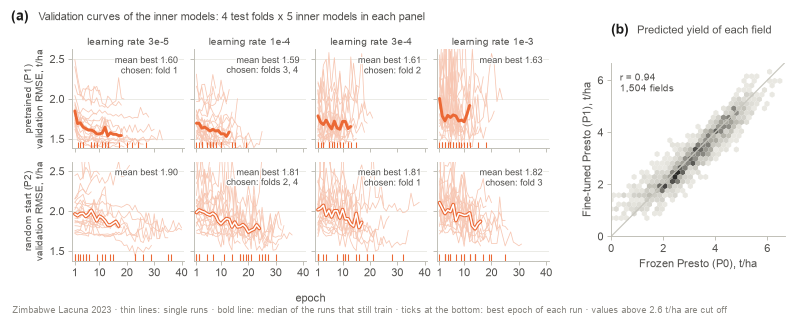

In [40]:
curves = pd.read_csv(PRESTO_RUNS / LACUNA / "inner_curves.csv")
choices = pd.read_csv(PRESTO_RUNS / LACUNA / "choices.csv")
rates = sorted(curves.lr.unique())
table = P[LACUNA]

fig = plt.figure(figsize=(FULL, 2.95))
w, h, x0, gap, rows_y = 1.02, 0.90, 0.60, 0.085, (0.50, 1.52)
low, high = 1.38, 2.62
for r, arm in enumerate(("P1", "P2")):
    for c, rate in enumerate(rates):
        ax = inch_axes(fig, x0 + c * (w + gap), rows_y[r], w, h)
        runs = curves[(curves.arm == arm) & np.isclose(curves.lr, rate)]
        wide = np.sqrt(runs.pivot_table(index="epoch", columns=["fold", "inner"], values="val_mse"))
        ax.plot(wide.index, wide.to_numpy(), color=tint(PRESTO, 0.62), linewidth=0.5, zorder=2)
        median = wide.median(axis=1)[wide.notna().sum(axis=1) >= wide.shape[1] / 2]
        ax.plot(median.index, median, color=PRESTO, linewidth=2.4 if arm == "P2" else 1.9, zorder=4)
        if arm == "P2":                                   # random weights: the same orange, hollow
            ax.plot(median.index, median, color=PAPER, linewidth=1.0, zorder=5)
        ax.vlines(wide.idxmin(), low, low + 0.085, color=PRESTO, linewidth=0.7, zorder=3)       # the best epoch of each run
        ax.set_xlim(0, 41)
        ax.set_ylim(low, high)
        ax.set_xticks([1, 10, 20, 30, 40], ["1", "10", "20", "30", "40"] if r == 1 else [])
        ax.set_yticks([1.5, 2.0, 2.5], ["1.5", "2.0", "2.5"] if c == 0 else [])
        hgrid(ax)
        chosen = choices[(choices.arm == arm) & np.isclose(choices.chosen_lr, rate)].fold.tolist()
        best = choices.loc[choices.arm == arm, f"inner_val_rmse_lr_{rate:g}"].mean()
        note = f"mean best {num(best, 2)}" + (f"\nchosen: fold{'s' if len(chosen) > 1 else ''} {', '.join(map(str, chosen))}" if chosen else "")
        ax.text(0.96, 0.95, note, transform=ax.transAxes, ha="right", va="top", fontsize=6.0, color=INK2, linespacing=1.2,
                path_effects=halo(1.5), zorder=6)
        if r == 0:
            ax.set_title("learning rate " + f"{rate:.0e}".replace("e-0", "e-"), fontsize=6.8, fontweight="normal", color=INK2,
                         pad=3, loc="center")
        if c == 0:
            ax.set_ylabel(("pretrained (P1)" if arm == "P1" else "random start (P2)") + "\nvalidation RMSE, t/ha",
                          fontsize=6.6, linespacing=1.15)
            first = ax if r == 0 else first
fig.text((x0 + 2 * w + 1.5 * gap) / FULL, 1 - (rows_y[1] + h + 0.30) / 2.95, "epoch", ha="center", va="top", fontsize=7, color=INK2)
panel(first, "a", x=0, dx=-40, dy=17)
first.annotate("Validation curves of the inner models: 4 test folds x 5 inner models in each panel", xy=(0, 1),
               xycoords="axes fraction", xytext=(-22, 17.6), textcoords="offset points", fontsize=7.2, color=INK2, va="bottom")

# (b) Does fine-tuning change the prediction of a field? Frozen against fine-tuned, out of fold.
bx = inch_axes(fig, 5.50, 0.62, 1.58, 1.58)
lim = (0, max(table.P0.max(), table.P1.max()) * 1.02)
bins = bx.hexbin(table.P0, table.P1, gridsize=34, extent=(*lim, *lim), cmap=GREYS, mincnt=1, linewidths=0, rasterized=True)
bx.plot(lim, lim, color=NEUTRAL_LIGHT, linewidth=0.8, zorder=1)
bx.set_xlim(lim)
bx.set_ylim(lim)
bx.set_aspect("equal")
bx.xaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
bx.yaxis.set_major_locator(mpl.ticker.MultipleLocator(2))
bx.set_xlabel("Frozen Presto (P0), t/ha")
bx.set_ylabel("Fine-tuned Presto (P1), t/ha")
bx.text(0.05, 0.95, f"r = {num(np.corrcoef(table.P0, table.P1)[0, 1], 2)}\n{len(table):,} fields", transform=bx.transAxes,
        va="top", fontsize=6.6, color=INK2, linespacing=1.2)
panel_title(bx, "b", "Predicted yield of each field", dy=17)
fig.text(0.008, 0.012, "Zimbabwe Lacuna 2023 · thin lines: single runs · bold line: median of the runs that still train · "
         f"ticks at the bottom: best epoch of each run · values above {high:.1f} t/ha are cut off", ha="left", va="bottom",
         fontsize=6.0, color=MUTED)
save(fig, "R09_finetune_learning_curves")

### R10. Map: where the village mean is right, where the field order is right

**What it shows.** (a) One dot for each 2 km group of Zimbabwe Lacuna 2023 (M2, out of fold). A group of 3 or more fields gets two questions: is the predicted group mean inside ±0.5 t/ha of the measured mean ("village right"), and is the rank correlation of its fields above 0 ("field order right")? (b) The four cases, counted. (c) The same two shares for five arms.

**Read it like this.** Black = both right, blue = village right only, green = field order right only, open ring = neither. In (c) the line marks 50 %, which a model without knowledge of the fields gets for the field order.

**Take-away.** What the monthly bands add is at the village level: the share of villages inside ±0.5 t/ha goes from 21 % (A1) to 36 % (M2), while the share of groups with the right field order stays the same (78 % and 77 %). Presto gives the same two shares as M2. Even for M2 the village mean is off by more than 0.5 t/ha in two of three groups.

**Source.** `P[LACUNA]` (out-of-fold predictions R0, R1, A1, M2, P0), `spearman()` of the project.

**Caption draft.** M2 in each 2 km group of Zimbabwe Lacuna 2023 (folds 1–4): group mean inside ±0.5 t/ha of the truth (village right) and rank correlation of the fields above 0 (field order right). (b) Counts of the four cases over the 105 groups of three or more fields. (c) The two shares for five arms.

**Caution.** The two questions are not on one scale: ±0.5 t/ha is a strict limit, "rank above 0" is a weak one, and a rank from about six fields is close to noise. So this map does not say "the model knows the village and not the field"; R01 and R03 show that in units of variance. Read regions, never single dots. The margin of 0.5 t/ha is a choice of this figure.

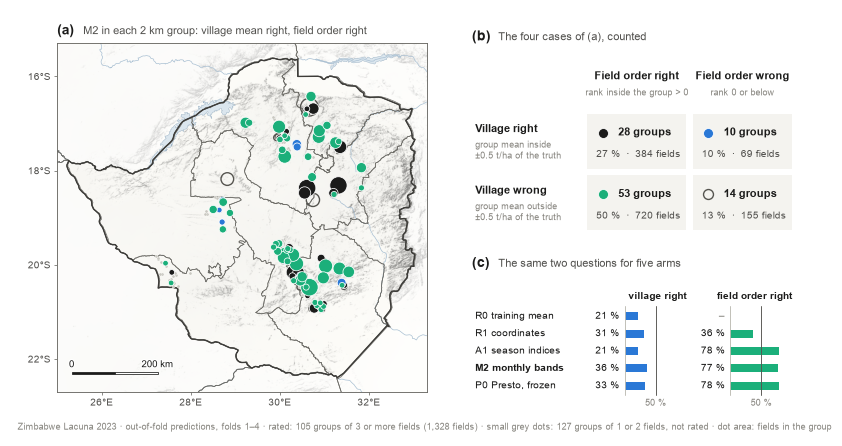

In [41]:
VILLAGE_RIGHT = 0.5      # t/ha: a group mean counts as right when the mean error of the group is inside this margin
table = P[LACUNA]


def group_view(arm):
    """One row per 2 km group: fields, place, the mean error of the group and the rank of its fields (3 or more)."""
    out = []
    for group, g in table.groupby("group_id"):
        rank = spearman(g.y.to_numpy(), g[arm].to_numpy()) if len(g) >= step8.MIN_CLUSTER_FIELDS else np.nan
        out.append({"group": group, "n": len(g), "lon": g.lon.mean(), "lat": g.lat.mean(), "error": (g[arm] - g.y).mean(), "rank": rank})
    return pd.DataFrame(out).set_index("group")


groups = group_view("M2")
rated = groups[groups["rank"].notna()].copy()            # groups of 3 or more fields: both questions can be asked
rated["village"] = rated.error.abs() <= VILLAGE_RIGHT
rated["order"] = rated["rank"] > 0
small = groups[groups["rank"].isna()]
KINDS = {(True, True): (INK, True), (True, False): (VILLAGE, True), (False, True): (FIELD, True), (False, False): (NEUTRAL, False)}

extent, H = (25.0, 33.3, -22.7, -15.3), 3.86
fig = plt.figure(figsize=(FULL, H))
ax = inch_axes(fig, 0.42, 0.30, 3.36, map_height(extent, 3.36))
basemap(ax, "zimbabwe", extent, focus=["ZWE"])
ax.scatter(small.lon, small.lat, s=4, color=NEUTRAL_LIGHT, edgecolors=PAPER, linewidths=0.2, zorder=9)
for (village, order), (color, filled) in KINDS.items():
    part = rated[(rated.village == village) & (rated.order == order)].sort_values("n", ascending=False)
    ax.scatter(part.lon, part.lat, s=7 + 2.2 * part.n, facecolors=color if filled else "none",
               edgecolors=PAPER if filled else color, linewidths=0.5 if filled else 0.9, zorder=10 + filled)
scalebar(ax, 200)
panel_title(ax, "a", "M2 in each 2 km group: village mean right, field order right")

# (b) The key of the map is a table: the groups (and their fields) in each of the four cases.
bx = fig.add_axes([0, 0, 1, 1], facecolor="none")
bx.set_xlim(0, FULL)
bx.set_ylim(H, 0)
bx.axis("off")
x0, cols, lines, cw, ch = 4.22, (5.24, 6.20), (0.94, 1.50), 0.90, 0.50
bx.text(x0 - 0.03, 0.30, "(b)", fontsize=9, fontweight="bold", va="bottom")
bx.text(x0 + 0.21, 0.292, "The four cases of (a), counted", fontsize=7.2, color=INK2, va="bottom")
for x, head, sub in zip(cols, ("Field order right", "Field order wrong"), ("rank inside the group > 0", "rank 0 or below")):
    bx.text(x + cw / 2, 0.60, head, ha="center", va="center", fontsize=6.9, fontweight="bold")
    bx.text(x + cw / 2, 0.75, sub, ha="center", va="center", fontsize=6.0, color=MUTED)
for village, y in zip((True, False), lines):
    bx.text(x0, y + 0.14, "Village right" if village else "Village wrong", va="center", fontsize=6.9, fontweight="bold")
    bx.text(x0, y + 0.24, f"group mean {'inside' if village else 'outside'}\n±{VILLAGE_RIGHT:g} t/ha of the truth", va="top",
            fontsize=6.0, color=MUTED, linespacing=1.15)
    for order, x in zip((True, False), cols):
        color, filled = KINDS[village, order]
        part = rated[(rated.village == village) & (rated.order == order)]
        bx.add_patch(Rectangle((x, y), cw, ch, facecolor="#f4f3ef", edgecolor="none"))
        bx.plot(x + 0.14, y + 0.17, "o", ms=6.5, mfc=color if filled else "none", mec=PAPER if filled else color,
                mew=0.5 if filled else 0.9)
        bx.text(x + 0.28, y + 0.17, f"{len(part)} groups", va="center", fontsize=7.4, fontweight="bold")
        bx.text(x + 0.08, y + 0.37, f"{100 * len(part) / len(rated):.0f} %  ·  {int(part.n.sum()):,} fields", va="center",
                fontsize=6.3, color=INK2)

# (c) The same two questions for five arms: share of the rated groups.
bx.text(x0 - 0.03, 2.36, "(c)", fontsize=9, fontweight="bold", va="bottom")
bx.text(x0 + 0.21, 2.352, "The same two questions for five arms", fontsize=7.2, color=INK2, va="bottom")
bx.text(cols[0] + cw, 2.60, "village right", ha="right", va="center", fontsize=6.6, fontweight="bold")
bx.text(cols[1] + cw, 2.60, "field order right", ha="right", va="center", fontsize=6.6, fontweight="bold")
ARMS_HERE = (("R0", "R0 training mean"), ("R1", "R1 coordinates"), ("A1", "A1 season indices"), ("M2", "M2 monthly bands"),
             ("P0", "P0 Presto, frozen"))
for k, (arm, name) in enumerate(ARMS_HERE):
    y = 2.78 + 0.158 * k
    view = group_view(arm).loc[rated.index]
    shares = ((view.error.abs() <= VILLAGE_RIGHT).mean(), (view["rank"] > 0).mean() if arm != "R0" else np.nan)
    bx.text(x0, y, name, va="center", fontsize=6.5, fontweight="bold" if arm == "M2" else "normal")
    for x, share, color in zip(cols, shares, (VILLAGE, FIELD)):
        if np.isfinite(share):
            bx.add_patch(Rectangle((x + 0.34, y - 0.036), (cw - 0.34) * share, 0.072, facecolor=color, edgecolor="none"))
            bx.text(x + 0.29, y, f"{100 * share:.0f} %", ha="right", va="center", fontsize=6.5)
        else:
            bx.text(x + 0.29, y, "–", ha="right", va="center", fontsize=6.5, color=MUTED)
for x in cols:
    bx.plot([x + 0.34 + (cw - 0.34) * 0.5] * 2, [2.69, 2.78 + 0.158 * 4.55], color=NEUTRAL, linewidth=0.6)
    bx.plot([x + 0.34, x + 0.34], [2.69, 2.78 + 0.158 * 4.55], color=AXIS, linewidth=0.6)
bx.text(cols[1] + 0.34 + (cw - 0.34) * 0.5, 2.78 + 0.158 * 4.75, "50 %", ha="center", va="top", fontsize=6.0, color=MUTED)
bx.text(cols[0] + 0.34 + (cw - 0.34) * 0.5, 2.78 + 0.158 * 4.75, "50 %", ha="center", va="top", fontsize=6.0, color=MUTED)
bx.text(0.06, H - 0.03, f"Zimbabwe Lacuna 2023 · out-of-fold predictions, folds 1–4 · rated: {len(rated)} groups of 3 or more fields "
        f"({int(rated.n.sum()):,} fields) · small grey dots: {len(small)} groups of 1 or 2 fields, not rated · dot area: fields in the group",
        ha="left", va="bottom", fontsize=6.0, color=MUTED)
save(fig, "R10_village_field_map")

### R11. Gain map: where the monthly bands beat the season indices

**What it shows.** (a) For each 2 km group of Zimbabwe Lacuna 2023: the mean squared error of M2 minus that of A1 (blue = M2 is better; dot area = fields in the group). (b) The groups sorted from the largest gain: the cumulative share of the net gain of M2 over A1 against the share of the fields.

**Read it like this.** In (b) the pale line is an even spread of the gain over the fields. The curve goes above 100 % because M2 is worse than A1 in some groups; the last part of the curve gives that back.

**Take-away.** The gain of M2 is not one region and not one group: without any single group the RMSE difference stays between −0.147 and −0.107 t/ha. But it is not even: M2 is better in 142 of 232 groups (65 % of the fields), and the 10 best groups (20 % of the fields) give 79 % of the net gain.

**Source.** `P[LACUNA]`, columns `A1` and `M2` (out-of-fold predictions, folds 1–4).

**Caption draft.** (a) Change in mean squared error per 2 km group, M2 minus A1, Zimbabwe Lacuna 2023 (1,504 fields, folds 1–4; blue: M2 better; dot area: fields). (b) Cumulative share of the net gain of M2 over A1, groups sorted from the largest gain.

**Caution.** A dot is a mean over the fields of one group; small groups are noisy and the colour scale is cut at the 90th percentile of the groups of three or more fields. The map shows dots only: do not read a regional pattern without a test.

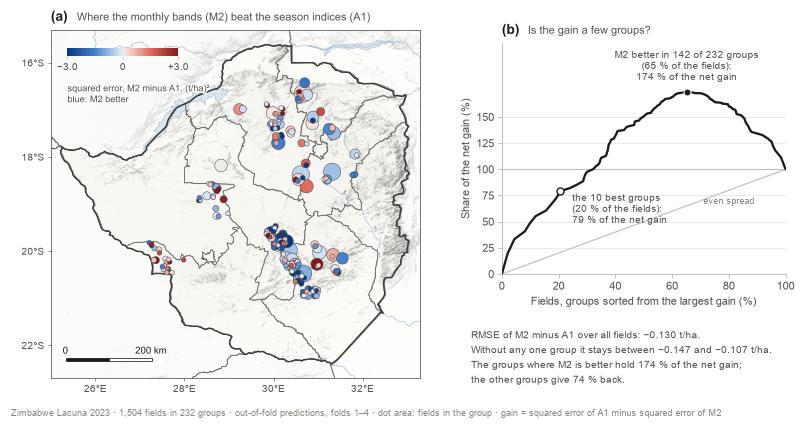

In [42]:
table = P[LACUNA]
se_a1, se_m2 = (table.y - table.A1) ** 2, (table.y - table.M2) ** 2
per = pd.DataFrame({"gain": se_a1 - se_m2, "lon": table.lon, "lat": table.lat, "group": table.group_id})
groups = per.groupby("group").agg(n=("gain", "size"), gain=("gain", "sum"), lon=("lon", "mean"), lat=("lat", "mean"))
groups["change"] = -groups.gain / groups.n                 # mean squared error of M2 minus A1 in the group: below 0 = M2 better
total = groups.gain.sum()
assert total > 0                                           # M2 has the lower squared error over all fields

extent, H = (25.0, 33.3, -22.7, -15.3), 3.86
fig = plt.figure(figsize=(FULL, H))
ax = inch_axes(fig, 0.42, 0.30, 3.36, map_height(extent, 3.36))
basemap(ax, "zimbabwe", extent, focus=["ZWE"])
limit = float(np.ceil(2 * groups[groups.n >= 3].change.abs().quantile(0.90)) / 2)      # colour limit from the larger groups
order = groups.sort_values("n", ascending=False)
dots = ax.scatter(order.lon, order.lat, s=7 + 2.2 * order.n, c=order.change, cmap=SIGNED, vmin=-limit, vmax=limit,
                  edgecolors="#3d3c39", linewidths=0.3, zorder=10)
scalebar(ax, 200)
cax = ax.inset_axes([0.045, 0.925, 0.30, 0.024])
colorbar(fig, dots, cax=cax, orientation="horizontal", ticks=[-limit, 0, limit])
cax.set_xticklabels([num(-limit, 1, True), "0", num(limit, 1, True)])
ax.text(0.045, 0.845, "squared error, M2 minus A1, (t/ha)²\nblue: M2 better", transform=ax.transAxes, va="top", fontsize=6.0,
        color=INK2, linespacing=1.15, path_effects=halo(1.6), zorder=45)
panel_title(ax, "a", "Where the monthly bands (M2) beat the season indices (A1)")

# (b) Is the gain a few groups? Groups sorted from the largest gain; cumulative share of the net gain.
bx = inch_axes(fig, 4.52, 0.42, 2.58, 2.10)
ranked = groups.sort_values("gain", ascending=False)
x = np.r_[0, ranked.n.cumsum() / ranked.n.sum()] * 100
y = np.r_[0, ranked.gain.cumsum() / total] * 100
bx.plot([0, 100], [0, 100], color=NEUTRAL_LIGHT, linewidth=0.9, zorder=1)
bx.axhline(100, color=AXIS, linewidth=0.7, zorder=1)
bx.plot(x, y, color=INK, linewidth=1.5, zorder=3)
peak, better = int(np.argmax(y)), int((ranked.gain > 0).sum())
bx.plot(x[peak], y[peak], "o", ms=4.6, mfc=INK, mec=PAPER, mew=0.7, zorder=4)
bx.annotate(f"M2 better in {better} of {len(ranked)} groups\n({x[peak]:.0f} % of the fields):\n{y[peak]:.0f} % of the net gain",
            (x[peak], y[peak]), xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=6.4, color=INK2,
            linespacing=1.2)
bx.plot(x[10], y[10], "o", ms=4.6, mfc=PAPER, mec=INK, mew=0.9, zorder=4)
bx.annotate(f"the 10 best groups\n({x[10]:.0f} % of the fields):\n{y[10]:.0f} % of the net gain", (x[10], y[10]), xytext=(8, -1),
            textcoords="offset points", ha="left", va="top", fontsize=6.4, color=INK2, linespacing=1.2)
bx.annotate("even spread", (80, 80), xytext=(0, -9), textcoords="offset points", ha="center", fontsize=6.2, color=MUTED)
bx.set_xlim(0, 100)
bx.set_ylim(0, max(y) * 1.27)
bx.set_yticks(np.arange(0, max(y) + 1, 25))
bx.set_xlabel("Fields, groups sorted from the largest gain (%)")
bx.set_ylabel("Share of the net gain (%)")
hgrid(bx)
panel_title(bx, "b", "Is the gain a few groups?")

# Leave one group out: how far the RMSE difference moves.
y_all, a_all, m_all, g_all = (table[c].to_numpy() for c in ("y", "A1", "M2", "group_id"))
loo = [rmse(y_all[g_all != g], m_all[g_all != g]) - rmse(y_all[g_all != g], a_all[g_all != g]) for g in groups.index]
full = rmse(y_all, m_all) - rmse(y_all, a_all)
notes = [f"RMSE of M2 minus A1 over all fields: {num(full, 3, True)} t/ha.",
         f"Without any one group it stays between {num(min(loo), 3, True)} and {num(max(loo), 3, True)} t/ha.",
         f"The groups where M2 is better hold {y[peak]:.0f} % of the net gain;",
         f"the other groups give {y[peak] - 100:.0f} % back."]
for k, text in enumerate(notes):
    fig.text(4.24 / FULL, 1 - (3.04 + 0.135 * k) / H, text, ha="left", va="top", fontsize=6.3, color=INK2)
fig.text(0.008, 0.008, f"Zimbabwe Lacuna 2023 · {len(table):,} fields in {len(groups)} groups · out-of-fold predictions, folds 1–4 · "
         "dot area: fields in the group · gain = squared error of A1 minus squared error of M2", ha="left", va="bottom",
         fontsize=6.0, color=MUTED)
save(fig, "R11_gain_map")

### R12. Changes that gave no clear gain

**What it shows.** One forest plot of RMSE differences on Zimbabwe Lacuna 2023 (1,504 fields, folds 1–4) for the changes that the team tried and that did not help: the lat/lon token of Presto, fine-tuning, a second fine-tuning recipe, Presto added to the bands, pre-harvest months only, coordinates added, weather features, and rows of Zimbabwe 2024.

**Read it like this.** Left of 0 = the change lowers RMSE. A line is a saved 95 % paired interval; the mark is filled only when the interval excludes 0. A square is the difference of two saved scores for which no paired interval was saved.

**Take-away.** No change lowers RMSE with an interval that excludes 0. Most intervals are narrow and lie on 0 (lat/lon token, fine-tuning, adaptive pooling), so these are "no effect of a useful size". Some changes hurt: 46 weather features, coordinates added to the bands, and naive pooling with Zimbabwe 2024 (+0.29 t/ha).

**Source.** `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/` (`scores.csv`, `posthoc_a3ft.csv`); `experiments/stepup/results.csv`; `results/merge_v2/merge/paired_differences.csv`; `results/weather_v2/compact/` and `full/paired_differences.csv`.

**Caption draft.** RMSE differences for changes without a clear gain on Zimbabwe Lacuna 2023 (1,504 fields, folds 1–4). Lines: 95 % paired cluster-bootstrap intervals; filled marks: interval excludes 0; squares: no interval saved. * side experiments (other Ridge head, data version 1). † post hoc.

**Caution.** "No clear gain" is not "no effect": only a narrow interval round 0 shows that. No margin of equivalence was fixed before these runs. The side experiments (*) use another Ridge head, so compare each row with its own reference only.

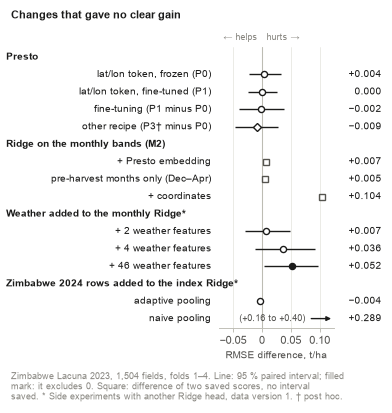

In [43]:
rows = ladder_of(LACUNA)
third = pd.read_csv(PRESTO_RUNS / LACUNA / "posthoc_a3ft.csv")
third = third[(third.kind == "pair") & (third.a == "P3") & (third.b == "P0")].iloc[0]
merge = pd.read_csv(REPO / "results" / "merge_v2" / "merge" / "paired_differences.csv").set_index(["method", "reference"])
compact = pd.read_csv(REPO / "results" / "weather_v2" / "compact" / "paired_differences.csv")
compact = compact[compact.bootstrap_unit == "spatial_group"].set_index(["method", "reference"])
weather = pd.read_csv(REPO / "results" / "weather_v2" / "full" / "paired_differences.csv").set_index(["method", "reference"])


def saved(pair):
    return float(pair.rmse_diff), float(pair.rmse_low), float(pair.rmse_high)


def felix(frame, method, reference):
    r = frame.loc[(method, reference)]
    return float(r.delta_rmse_t_ha), float(r.ci_low), float(r.ci_high)


def rungs(a, b):                                   # two rungs of the ladder: no paired interval was saved
    return float(rows.rmse[a] - rows.rmse[b]), np.nan, np.nan


ROWS = [  # heading, or (label, (difference, low, high), post hoc)
    "Presto",
    ("lat/lon token, frozen (P0)", saved(presto_pair(LACUNA, "P0", "P0_noloc")), False),
    ("lat/lon token, fine-tuned (P1)", saved(presto_pair(LACUNA, "P1", "P1_noloc")), False),
    ("fine-tuning (P1 minus P0)", saved(presto_pair(LACUNA, "P1", "P0")), False),
    (f"other recipe (P3{DAGGER} minus P0)", saved(third), True),
    "Ridge on the monthly bands (M2)",
    ("+ Presto embedding", rungs("S11", "S7"), False),
    (f"pre-harvest months only ({PRE_HARVEST})", rungs("S8", "S7"), False),
    ("+ coordinates", rungs("S9", "S7"), False),
    "Weather added to the monthly Ridge*",
    ("+ 2 weather features", felix(compact, "compact2_target", "monthly_target"), False),
    ("+ 4 weather features", felix(compact, "compact4_target", "monthly_target"), False),
    ("+ 46 weather features", felix(weather, "weather_target", "monthly_target"), False),
    "Zimbabwe 2024 rows added to the index Ridge*",
    ("adaptive pooling", felix(merge, "pooled_adaptive", "lacuna_only"), False),
    ("naive pooling", felix(merge, "pooled_naive", "lacuna_only"), False),
]

H = 3.62
fig = plt.figure(figsize=(COL, H))
ax = inch_axes(fig, 1.93, 0.36, 1.05, 2.56)
x_low, x_high = -0.075, 0.125
for y, row in enumerate(ROWS):
    if isinstance(row, str):
        ax.annotate(row, (0, y), xycoords=("figure fraction", "data"), xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=6.6, fontweight="bold", annotation_clip=False)
        continue
    label, (diff, low, high), post = row
    ax.annotate(label, (0, y), xycoords=("axes fraction", "data"), xytext=(-5, 0), textcoords="offset points", ha="right",
                va="center", fontsize=6.4, annotation_clip=False)
    ax.annotate(num(diff, 3, True), (1, y), xycoords=("axes fraction", "data"), xytext=(31, 0), textcoords="offset points",
                ha="right", va="center", fontsize=6.4, annotation_clip=False)
    if not np.isfinite(low):                        # a difference of two saved scores, without an interval
        ax.plot(min(diff, x_high), y, "s", ms=3.6, mfc="none", mec=NEUTRAL, mew=0.9, zorder=5)
    elif diff > x_high:                             # off the scale: an arrow and the interval as text
        ax.annotate("", (x_high, y), xytext=(x_high - 0.045, y), arrowprops={"arrowstyle": "-|>", "color": INK, "linewidth": 0.9,
                                                                                 "mutation_scale": 6})
        ax.annotate(f"({num(low, 2, True)} to {num(high, 2, True)})", (x_high - 0.05, y), ha="right", va="center", fontsize=6.0,
                    color=INK2)
    else:
        interval(ax, y, diff, low, high, marker="D" if post else "o", size=3.6 if post else 4.0)
ax.set_ylim(len(ROWS) - 0.45, -0.6)
ax.set_xlim(x_low, x_high)
zero_line(ax)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_xticks([-0.05, 0, 0.05, 0.1], [num(-0.05, 2), "0", "0.05", "0.10"])
hgrid(ax, "x")
ax.set_xlabel("RMSE difference, t/ha", fontsize=6.8)
ax.annotate("← helps", (0, 1), xycoords=("data", "axes fraction"), xytext=(-3, 3), textcoords="offset points", ha="right",
            va="bottom", fontsize=6.2, color=MUTED)
ax.annotate("hurts →", (0, 1), xycoords=("data", "axes fraction"), xytext=(3, 3), textcoords="offset points", ha="left",
            va="bottom", fontsize=6.2, color=MUTED)
fig.text(0.012, 0.992, "Changes that gave no clear gain", ha="left", va="top", fontsize=7.4, fontweight="bold")
fig.text(0.012, 0.008, f"Zimbabwe Lacuna 2023, {len(P[LACUNA]):,} fields, folds 1–4. Line: 95 % paired interval; filled\nmark: it excludes 0. "
         f"Square: difference of two saved scores, no interval\nsaved. * Side experiments with another Ridge head, data version 1. {DAGGER} post hoc.",
         ha="left", va="bottom", fontsize=5.9, color=MUTED, linespacing=1.2)
save(fig, "R12_equivalence_strip")

### R13. Predicted against measured yield, four arms

**What it shows.** The out-of-fold predictions of four arms against the measured yield of the 1,504 development fields of Zimbabwe Lacuna 2023 (grey hexagons = number of fields). The dots are the mean measured yield of ten groups of fields sorted by predicted yield.

**Read it like this.** The pale line is 1:1. Dots on the line mean that the predictions are right on average at that level. A cloud that is narrow from left to right means that the model predicts a small range.

**Take-away.** All four arms are right on average (the dots follow the line), but the cloud is wide: one field can be several t/ha away from its prediction. The monthly bands and Presto spread their predictions over a wider range than the season indices and the coordinates.

**Source.** `P[LACUNA]`, `score()`.

**Caption draft.** Measured against predicted yield (out of fold, folds 1–4) for coordinates only, season indices, monthly bands and frozen Presto on Zimbabwe Lacuna 2023 (1,504 fields). Dots: mean measured yield in deciles of the predicted yield.

**Caution.** The decile means hide the scatter of single fields; R² and RMSE are printed in each panel. Two fields above 10 t/ha are outside the frame.

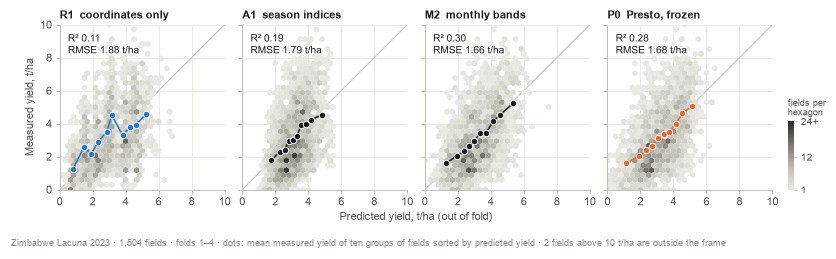

In [44]:
table = P[LACUNA]
SHOW = (("R1", "R1  coordinates only", VILLAGE), ("A1", "A1  season indices", INK), ("M2", "M2  monthly bands", INK),
        ("P0", "P0  Presto, frozen", PRESTO))
top = 10.0                                              # t/ha: the frame; fields above it are counted in the note
above = int((table.y > top).sum())

fig = plt.figure(figsize=(FULL, 2.42))
side, gap, x0 = 1.50, 0.16, 0.50
for k, (arm, name, color) in enumerate(SHOW):
    ax = inch_axes(fig, x0 + k * (side + gap), 0.36, side, side)
    s = score(table, arm)
    bins = ax.hexbin(table[arm], table.y, gridsize=30, extent=(0, top, 0, top), cmap=GREYS, mincnt=1, linewidths=0,
                     rasterized=True, vmax=24, zorder=2)
    ax.plot([0, top], [0, top], color=NEUTRAL_LIGHT, linewidth=0.8, zorder=1)
    tenth = pd.qcut(table[arm], 10, labels=False, duplicates="drop")       # ten groups of fields by predicted yield
    means = table.groupby(tenth).agg(x=(arm, "mean"), y=("y", "mean"))
    ax.plot(means.x, means.y, color=color, linewidth=1.0, zorder=4)
    ax.plot(means.x, means.y, "o", ms=4.2, mfc=color, mec=PAPER, mew=0.6, zorder=5)
    ax.set_xlim(0, top)
    ax.set_ylim(0, top)
    ax.set_aspect("equal")
    ax.set_xticks([0, 2, 4, 6, 8, 10])
    ax.set_yticks([0, 2, 4, 6, 8, 10], ["0", "2", "4", "6", "8", "10"] if k == 0 else [])
    hgrid(ax, "both")
    ax.set_title(name, fontsize=7.4, pad=4)
    ax.text(0.05, 0.955, f"R² {num(s['r2'], 2)}\nRMSE {num(s['rmse'], 2)} t/ha", transform=ax.transAxes, va="top", fontsize=6.6,
            color=INK, linespacing=1.25, path_effects=halo(2.0), zorder=6)
    if k == 0:
        ax.set_ylabel("Measured yield, t/ha")
        first = ax
cax = inch_axes(fig, x0 + 4 * (side + gap) - 0.02, 0.36 + side - 0.62, 0.055, 0.62)
colorbar(fig, bins, cax=cax, ticks=[1, 12, 24])
cax.set_yticklabels(["1", "12", "24+"])
cax.set_title("fields per\nhexagon", fontsize=6.0, fontweight="normal", color=INK2, pad=4, loc="left", linespacing=1.1)
fig.text((x0 + 2 * side + 1.5 * gap) / FULL, 1 - (0.36 + side + 0.20) / 2.42, "Predicted yield, t/ha (out of fold)", ha="center",
         va="top", fontsize=7.5, color=INK2)
fig.text(0.008, 0.012, f"Zimbabwe Lacuna 2023 · {len(table):,} fields · folds 1–4 · dots: mean measured yield of ten groups of "
         f"fields sorted by predicted yield · {above} fields above {top:g} t/ha are outside the frame", ha="left", va="bottom",
         fontsize=6.0, color=MUTED)
save(fig, "R13_predicted_measured")

### R20. A village from the model's side: the yield map of every pixel

**What it shows.** Two villages (2 km groups) in 4.4 km windows. (a), (c) Sentinel-2 true colour, March 2023. (b), (d) The monthly-band Ridge (M2) applied to every pixel of the chips. The dots are the crop cuts, in the same colours as the map.

**Read it like this.** A dot that melts into the map is a field that the model has right. A dot that stands out is a field that the model has wrong.

**Take-away.** The model draws a plausible field-scale map in both villages. In village B it ranks the crop cuts well (rank correlation +0.64). In village A it does not (−0.02). Skill inside a village is not stable from village to village.

**Source.** The data v2 chips; M2 fitted with the project functions on the other three of folds 1-4, so each village is in the test fold of its model. The cell checks that the model gives the scored M2 value at every labelled pixel (largest difference 0.000 t/ha).

**Caption draft.** Illustration: the monthly-band Ridge applied to every 10 m pixel of two villages that it never saw. Dots: crop cuts on the same colour scale.

**Caution.** This is an illustration, not a validated map. The model was fitted on labelled maize pixels only, so its value on trees, roads and houses has no meaning, and there is no crop mask. Two villages are examples.

Village A (group 12, fold 1): 58 fields, 40 in the window; model at the labelled pixel against the scored M2 value: largest difference 0.000 t/ha; rank correlation -0.024; R2 inside the group -0.476
Village B (group 16, fold 4): 55 fields, 55 in the window; model at the labelled pixel against the scored M2 value: largest difference 0.000 t/ha; rank correlation 0.642; R2 inside the group 0.318


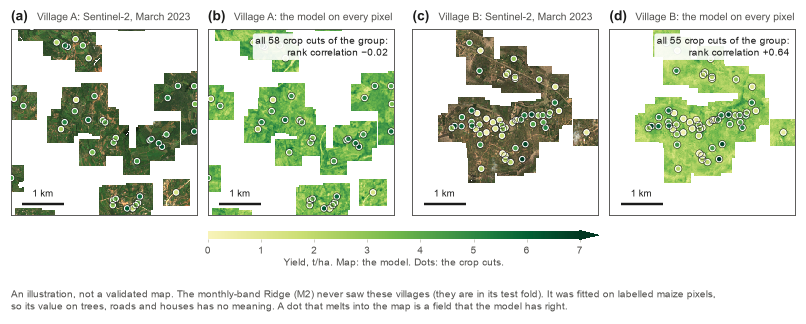

In [45]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from cropyield.baselines.models import Winsorize
from cropyield.eval.protocol import train_mask

d = D[LACUNA]
X, y, fields = d["variants"]["M2 monthly band curve"], d["y"], d["fields"]
MONTHS = [(pd.Period("2022-10", "M") + k).strftime("%Y-%m") for k in sorted(d["calendar"])]     # December to June
assert list(X.columns) == [f"{b}_m{k}" for b in BANDS for k in sorted(d["calendar"])]


def fitted_m2(fold):
    """The monthly-band Ridge (M2) that predicts this fold: fitted on the other three of folds 1-4, as in the scores."""
    train = train_mask(fields["fold"], fold)
    search = GridSearchCV(make_pipeline(Winsorize(), StandardScaler(), Ridge()), {"ridge__alpha": step8.ALPHAS},
                          cv=GroupKFold(n_splits=5), scoring="neg_mean_squared_error")
    search.fit(X.to_numpy()[train], y.to_numpy()[train], groups=fields["group_id"].to_numpy()[train])
    test = (fields["fold"] == fold).to_numpy()
    assert np.allclose(search.predict(X.to_numpy()[test]), P[LACUNA].loc[fields.index[test], "M2"]), "not the scored model"
    return search


def fill_months(series):
    """Fill the gaps along the last axis as M2 does: a straight line between the nearest clear months, and the nearest
    clear month at the two ends. A series without any clear month stays empty."""
    n = series.shape[-1]
    position = np.arange(n)
    clear = np.isfinite(series)
    left = np.maximum.accumulate(np.where(clear, position, -1), axis=-1)
    right = np.minimum.accumulate(np.where(clear, position, n)[..., ::-1], axis=-1)[..., ::-1]
    has_left, has_right = left >= 0, right < n
    lo, hi = np.clip(left, 0, n - 1), np.clip(right, 0, n - 1)
    v_lo, v_hi = np.take_along_axis(series, lo, -1), np.take_along_axis(series, hi, -1)
    weight = np.where(hi > lo, (position - lo) / np.maximum(hi - lo, 1), 0.0)
    filled = np.where(has_left & has_right, v_lo + (v_hi - v_lo) * weight, np.where(has_left, v_lo, v_hi))
    return np.where(has_left | has_right, filled, np.nan)


def pixel_features(chip):
    """The 70 inputs of M2 for every pixel of a chip: 10 bands x 7 months, gaps filled inside the pixel's own series."""
    stack = np.full((len(MONTHS), 10, 64, 64), np.nan, dtype="float32")
    for j, month in enumerate(MONTHS):
        values = chip.reflectance(month)
        if values is not None:
            stack[j] = values
    filled = fill_months(stack.transpose(1, 2, 3, 0).astype("float64"))      # band, row, column, month
    return filled.reshape(10, 64 * 64, len(MONTHS)).transpose(1, 0, 2).reshape(64 * 64, 70)


def village(group_id):
    """True colour and the per-pixel prediction of M2 for the chips of one 2 km group, on one canvas."""
    members = fields[fields.group_id == group_id]
    model = fitted_m2(members.fold.iloc[0])
    image, extent, grid = mosaic(list(members.index), "2023-03")
    sheet = np.full(image.shape[:2], np.nan)
    at_label = []
    for obs in members.index:
        chip = chip_of(obs)
        features = pixel_features(chip)
        ok = np.isfinite(features).all(axis=1)
        predicted = np.full(64 * 64, np.nan)
        predicted[ok] = model.predict(features[ok])
        predicted = predicted.reshape(64, 64)
        at_label.append(predicted[chip.pixel])
        r, c = round((extent[3] - chip.extent[3]) / 10), round((chip.extent[0] - extent[0]) / 10)
        window_ = sheet[r:r + 64, c:c + 64]
        empty = np.isnan(window_)
        window_[empty] = predicted[empty]
    x, y_ = to_utm(grid, members.lon, members.lat)
    table = members.assign(x=x, y_utm=y_, measured=y[members.index], scored=P[LACUNA].loc[members.index, "M2"], at_label=at_label)
    return image, sheet, extent, table


norm = Normalize(0, 7)
S, GAP = 1.69, 0.10
fig = plt.figure(figsize=(FULL, S + 1.16))
for k, (group_id, name) in enumerate((("12", "Village A"), ("16", "Village B"))):
    image, predicted, extent, table = village(group_id)
    assert np.nanmax(np.abs(table.at_label - table.scored)) < 1e-6, "the pixel model differs from the scored field model"
    half = 2200                                              # both windows are 4.4 km wide, centred on the middle field
    cx, cy = float(table.x.median()), float(table.y_utm.median())
    shown = int((table.x.between(cx - half, cx + half) & table.y_utm.between(cy - half, cy + half)).sum())
    rank = spearman(table.measured.to_numpy(), table.scored.to_numpy())
    for j, (layer, title) in enumerate(((np.where(np.isnan(image), 1.0, image), f"{name}: Sentinel-2, March 2023"), (predicted, f"{name}: the model on every pixel"))):
        ax = inch_axes(fig, 0.06 + (2 * k + j) * (S + GAP) + (0.07 if k else 0), 0.26, S, S)
        if j == 0:
            ax.imshow(layer, extent=extent, zorder=1)
        else:
            ax.imshow(layer, extent=extent, cmap=YIELD, norm=norm, zorder=1)
        ax.scatter(table.x, table.y_utm, s=13, c=table.measured, cmap=YIELD, norm=norm, edgecolors=PAPER, linewidths=0.7, zorder=10)
        ax.scatter(table.x, table.y_utm, s=24, facecolors="none", edgecolors=INK, linewidths=0.3, zorder=11)
        ax.set_xlim(cx - half, cx + half)
        ax.set_ylim(cy - half, cy + half)
        plain(ax)
        scalebar_m(ax, 1000, "1 km", x=0.06, y=0.06, color=INK)
        panel_title(ax, "abcd"[2 * k + j], title, size=6.8)
        if j == 1:
            ax.text(0.97, 0.965, f"all {len(table)} crop cuts of the group:\nrank correlation {rank:+.2f}".replace("-", "−"),
                    transform=ax.transAxes, ha="right", va="top", fontsize=6.3, color=INK, linespacing=1.2,
                    bbox={"boxstyle": "round,pad=0.25", "facecolor": PAPER, "edgecolor": "none", "alpha": 0.9}, zorder=20)
    print(f"{name} (group {group_id}, fold {table.fold.iloc[0]}): {len(table)} fields, {shown} in the window; model at the labelled pixel against the scored M2 value: "
          f"largest difference {np.nanmax(np.abs(table.at_label - table.scored)):.3f} t/ha; rank correlation {rank:.3f}; "
          f"R2 inside the group {r2(table.measured.to_numpy(), table.scored.to_numpy()):.3f}")
cax = inch_axes(fig, 0.06 + S + GAP, 0.26 + S + 0.14, 2 * S + GAP + 0.07, 0.08)
colorbar(fig, mpl.cm.ScalarMappable(norm, YIELD), cax=cax, orientation="horizontal", extend="max", ticks=range(8))
cax.set_xlabel("Yield, t/ha. Map: the model. Dots: the crop cuts.", fontsize=6.8, labelpad=1.5)
fig.text(0.06 / FULL, 0.004, "An illustration, not a validated map. The monthly-band Ridge (M2) never saw these villages (they are in its test fold). It was "
         "fitted on labelled maize pixels,\nso its value on trees, roads and houses has no meaning. A dot that melts into the map is a field that the "
         "model has right.", fontsize=6.5, color=INK2, ha="left", va="bottom", linespacing=1.3)
save(fig, "R20_village_yield_map")

## Index of the figures

This cell writes one overview sheet for each part (`report/figures/midterm/_overview_part1.png` to `_overview_part3.png`: every figure as a small picture with its name, to choose from) and shows a table of every figure with its size.

In LaTeX use the PDF: `\includegraphics[width=\textwidth]{figures/midterm/<name>.pdf}` in a `figure*` for a 7.2 in figure, and `width=\columnwidth` for a 3.5 in figure. Use the PNG (300 dpi) in slides.

In [46]:
import struct


def png_size(path):
    """Width and height in pixels from the header of a PNG file."""
    with open(path, "rb") as handle:
        return struct.unpack(">II", handle.read(24)[16:24])


def thumbnail(path, step=3):
    """The image at one third of its size: the mean of each block of 3 x 3 pixels."""
    image = plt.imread(path)[..., :3]
    rows, columns = image.shape[0] // step * step, image.shape[1] // step * step
    return image[:rows, :columns].reshape(rows // step, step, columns // step, step, 3).mean(axis=(1, 3))


PARTS = {"D": "Part 1: data and visualisation", "A": "Part 2: architecture", "R": "Part 3: results and outcomes"}
con.close()
rows = []
for path in sorted(p for p in FIG.glob("*.png") if p.stem[0] in PARTS):
    width, height = png_size(path)
    rows.append({"figure": path.stem, "part": PARTS[path.stem[0]], "width_in": round(width / 300, 1), "height_in": round(height / 300, 1),
                 "png_kb": round(path.stat().st_size / 1024), "pdf_kb": round((FIG / f"{path.stem}.pdf").stat().st_size / 1024)})
index = pd.DataFrame(rows)

# One overview sheet for each part: every figure as a small picture with its name, to choose from. The sheets are
# written as files and are not shown here, because each figure is already shown above.
for number, (letter, title) in enumerate(PARTS.items(), start=1):
    names = index.figure[index.figure.str[0] == letter].tolist()
    columns = 3
    lines = math.ceil(len(names) / columns)
    sheet, axes = plt.subplots(lines, columns, figsize=(FULL * 1.6, 2.35 * lines), squeeze=False)
    for ax, name in zip(axes.flat, names + [None] * (lines * columns - len(names))):
        ax.axis("off")
        if name:
            ax.imshow(thumbnail(FIG / f"{name}.png"), interpolation="bilinear")
            ax.set_title(name, fontsize=8, fontweight="bold", pad=4, loc="left")
    sheet.suptitle(title, x=0.01, y=0.995, ha="left", va="top", fontsize=11, fontweight="bold")
    sheet.tight_layout(rect=(0, 0, 1, 0.975), h_pad=1.2, w_pad=1.0)
    sheet.savefig(FIG / f"_overview_part{number}.png", dpi=170)
    plt.close(sheet)
    print(f"{title}: {len(names)} figures -> {(FIG / f'_overview_part{number}.png').relative_to(REPO).as_posix()}")
print(f"{len(index)} figures in {FIG.relative_to(REPO).as_posix()}/: {index.png_kb.sum() / 1024:.0f} MB of PNG and "
      f"{index.pdf_kb.sum() / 1024:.0f} MB of PDF")
index

Part 1: data and visualisation: 15 figures -> report/figures/midterm/_overview_part1.png
Part 2: architecture: 8 figures -> report/figures/midterm/_overview_part2.png
Part 3: results and outcomes: 16 figures -> report/figures/midterm/_overview_part3.png
39 figures in report/figures/midterm/: 18 MB of PNG and 16 MB of PDF


,figure,part,width_in,height_in,png_kb,pdf_kb
0,A01_one_field_one_number,Part 2: architecture,7.3,3.4,246,124
1,A02_lit_and_dark_tokens,Part 2: architecture,3.6,4.2,137,57
2,A03_contrast_square,Part 2: architecture,3.6,4.0,137,49
3,A04_villages_are_dealt,Part 2: architecture,7.3,2.8,267,150
4,A05_arm_passport,Part 2: architecture,3.6,3.6,157,54
5,A06_same_light_four_readings,Part 2: architecture,7.3,2.6,132,57
6,A07_one_finetuned_prediction,Part 2: architecture,7.3,2.9,245,61
7,A08_ridge_head,Part 2: architecture,3.6,3.1,116,46
8,D01_powers_of_ten,Part 1: data and visualisation,7.1,4.7,1248,1359
9,D02_study_area,Part 1: data and visualisation,7.2,3.4,1616,1940


## Additional midterm figures: maps and Presto architecture

Six additional figures, with saved outputs and reproducible code. Run the notebook setup and data/map helper cells first. The PNG and PDF exports are written to `report/figures/midterm/`.

### D15. Measured yield across Zimbabwe

**What it shows.** Lacuna 2023 crop-cut yield: national 2 km group means and two windows of individual sampled fields. Circle area increases with the group size. The colour scale saturates above 7 t/ha.

**Source and interpretation.** Data v2 model rows and `s1_cc2km`; Natural Earth and geoBoundaries outlines, Copernicus DEM relief. Marks represent sampled locations, not a continuous yield surface.

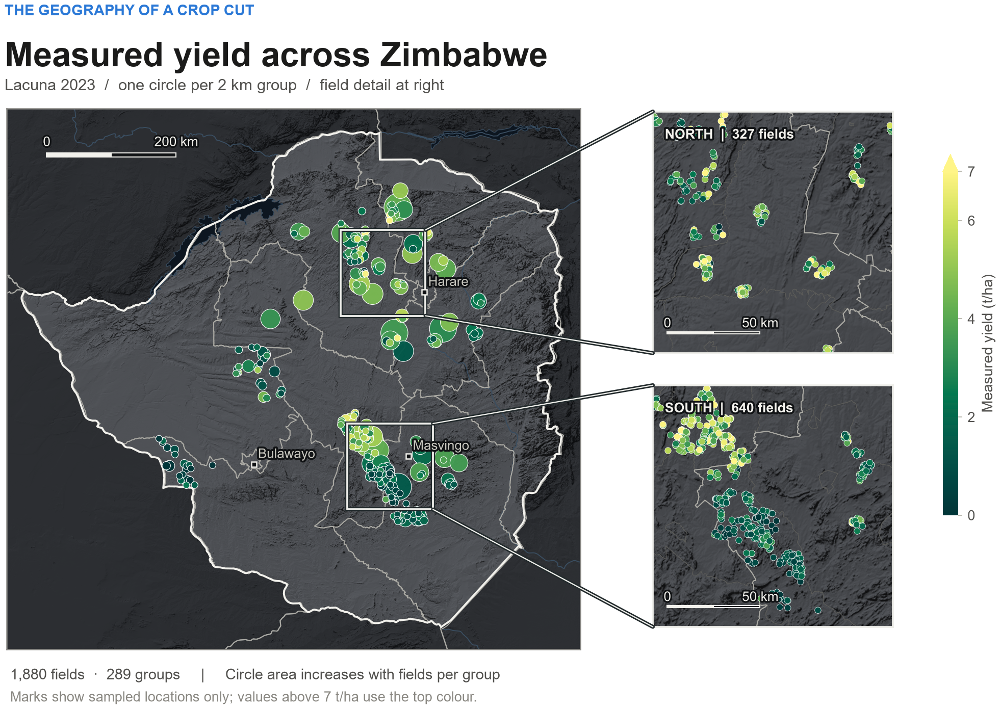

In [ ]:
# The marks are sampled groups, not a continuous yield surface.
map_fields = D[LACUNA]["fields"].assign(y=D[LACUNA]["y"])
map_groups = (map_fields.groupby("group_id")
              .agg(lon=("lon", "mean"), lat=("lat", "mean"), n=("y", "size"), y=("y", "mean"))
              .sort_values("n", ascending=False))
map_norm = Normalize(0, 7)
fig = plt.figure(figsize=(FULL, 4.85))
fig.text(.04, .965, "THE GEOGRAPHY OF A CROP CUT", color=BLUE, weight="bold", fontsize=7, va="top")
fig.text(.04, .915, "Measured yield across Zimbabwe", fontsize=16, weight="bold", va="top")
fig.text(.04, .865, "Lacuna 2023  /  one circle per 2 km group  /  field detail at right", fontsize=7.5, color=INK2, va="top")
zim_extent = (25.0, 33.3, -22.7, -15.3)
ax = inch_axes(fig, .30, .85, 3.75, map_height(zim_extent, 3.75))
basemap(ax, "zimbabwe", zim_extent, "dark", focus=["ZWE"], admin2=False, ticks=False)
ax.scatter(map_groups.lon, map_groups.lat, s=7 + 2.8*map_groups.n, c=map_groups.y, cmap=YIELD_DARK,
           norm=map_norm, edgecolors="white", linewidths=.28, alpha=.96, zorder=10)
cities(ax, {"Harare", "Bulawayo", "Masvingo"}, "dark")
scalebar(ax, 200, x=.07, y=.91, theme="dark")
for title, center, ytop in [("NORTH", (30.45, -17.55), .87), ("SOUTH", (30.55, -20.20), 2.66)]:
    ext = window(*center, 130)
    az = inch_axes(fig, 4.52, ytop, 1.58, 1.58)
    basemap(az, "zimbabwe", ext, "dark", focus=["ZWE"], admin2=True, ticks=False, relief_gain=.7)
    subset = map_fields[map_fields.lon.between(ext[0], ext[1]) & map_fields.lat.between(ext[2], ext[3])]
    az.scatter(subset.lon, subset.lat, c=subset.y, s=9, cmap=YIELD_DARK, norm=map_norm,
               edgecolors="white", linewidths=.17, zorder=10)
    map_label(az, ext[0] + .05*(ext[1]-ext[0]), ext[3] - .07*(ext[3]-ext[2]),
              f"{title}  |  {len(subset)} fields", "dark", size=6.4, weight="bold", ha="left", va="top")
    scalebar(az, 50, x=.06, y=.08, theme="dark")
    connect(fig, ax, ext, az, "right", color="#eeeeea", halo_color="#222a2c", width=.55)
cax = inch_axes(fig, 6.42, 1.15, .10, 2.36)
colorbar(fig, mpl.cm.ScalarMappable(map_norm, YIELD_DARK), cax=cax, ticks=[0, 2, 4, 6, 7],
         label="Measured yield (t/ha)", extend="max")
fig.text(.045, .055, f"{len(map_fields):,} fields  ·  {len(map_groups):,} groups     |     Circle area increases with fields per group", fontsize=7, color=INK2)
fig.text(.045, .025, "Marks show sampled locations only; values above 7 t/ha use the top colour.", fontsize=6.4, color=MUTED)
save(fig, "D15_sampled_yield_atlas")


### D16. One landscape, two scales of variation

**What it shows.** The same sampled fields in three panels: measured yield, the mean yield of their 2 km group, and the field yield minus its group mean. Group means use all available fields in the group; a singleton necessarily has zero deviation. Diverging colours saturate at ±3 t/ha. These are descriptive measurements, not out-of-fold model predictions.

**Source.** Data v2 Lacuna model rows and `s1_cc2km`; Natural Earth, geoBoundaries and Copernicus DEM.

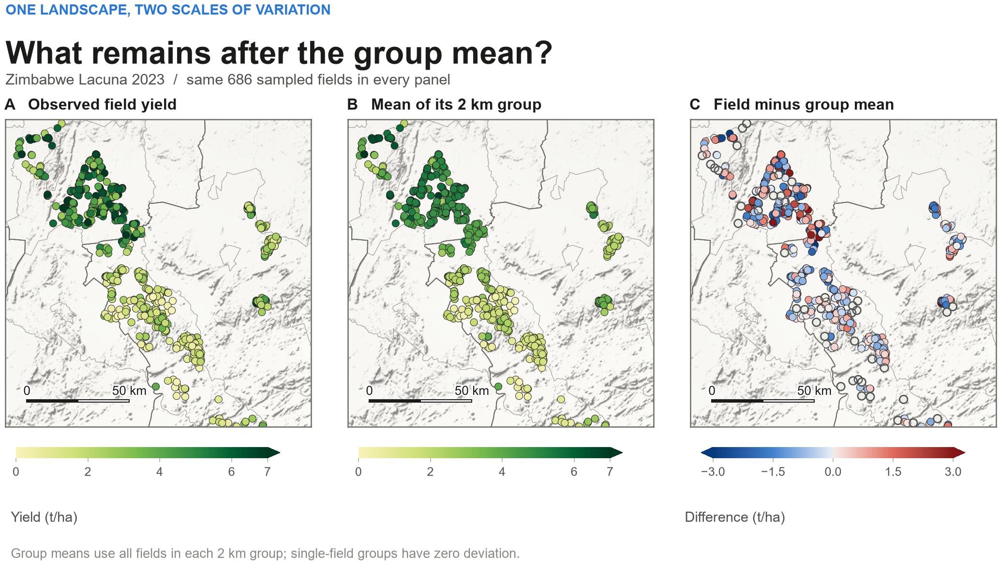

In [ ]:
# Every panel uses the same sampled fields and the same 150 km window.
map_fields = D[LACUNA]["fields"].assign(y=D[LACUNA]["y"]).copy()
map_fields["group_mean"] = map_fields.groupby("group_id").y.transform("mean")
map_fields["group_n"] = map_fields.groupby("group_id").y.transform("size")
map_fields["within"] = map_fields.y - map_fields.group_mean
map_ext = window(30.50, -20.15, 150)
sub = map_fields[map_fields.lon.between(map_ext[0], map_ext[1]) & map_fields.lat.between(map_ext[2], map_ext[3])].copy()
fig = plt.figure(figsize=(FULL, 4.15))
fig.text(.04, .96, "ONE LANDSCAPE, TWO SCALES OF VARIATION", color=BLUE, weight="bold", fontsize=7, va="top")
fig.text(.04, .90, "What remains after the group mean?", fontsize=15.5, weight="bold", va="top")
fig.text(.04, .845, f"Zimbabwe Lacuna 2023  /  same {len(sub)} sampled fields in every panel", color=INK2, fontsize=7.5, va="top")
specs = [("a", "Observed field yield", "y", YIELD, Normalize(0, 7)),
         ("b", "Mean of its 2 km group", "group_mean", YIELD, Normalize(0, 7)),
         ("c", "Field minus group mean", "within", DIVERGE, Normalize(-3, 3))]
for i, (letter, title, column, cmap, norm) in enumerate(specs):
    x = .28 + 2.36*i
    a = inch_axes(fig, x, .96, 2.12, 2.12)
    basemap(a, "zimbabwe", map_ext, "light", focus=["ZWE"], admin2=True, ticks=False, relief_gain=.65)
    a.scatter(sub.lon, sub.lat, c=sub[column], s=13, cmap=cmap, norm=norm,
              edgecolors="#222222", linewidths=.24, zorder=10)
    if column == "within":
        singles = sub[sub.group_n == 1]
        a.scatter(singles.lon, singles.lat, s=16, facecolors="none", edgecolors="#555555", linewidths=.6, zorder=11)
    scalebar(a, 50, x=.07, y=.08)
    fig.text(x/7.2, .785, f"{letter.upper()}   {title}", fontsize=7.7, weight="bold")
    cax = inch_axes(fig, x+.08, 3.22, 1.82, .075)
    cb = colorbar(fig, mpl.cm.ScalarMappable(norm, cmap), cax=cax, orientation="horizontal",
                  ticks=([0, 2, 4, 6, 7] if i < 2 else [-3, -1.5, 0, 1.5, 3]), extend="both" if i == 2 else "max")
    cb.ax.tick_params(labelsize=6)
fig.text(.045, .10, "Yield (t/ha)", fontsize=7, color=INK2)
fig.text(.69, .10, "Difference (t/ha)", fontsize=7, color=INK2)
fig.text(.045, .04, "Group means use all fields in each 2 km group; single-field groups have zero deviation.", fontsize=6.5, color=MUTED)
save(fig, "D16_between_within_maps")


### D17. The spatial split, made visible

**What it shows.** The national panel marks 2 km connected-group centroids, sized by the number of sampled fields; the detail shows the fields themselves. Colours identify folds. Fold 0 is held back; folds 1–4 form development cross-validation. The cell checks that no group is assigned to multiple folds.

**Source.** Data v2 Lacuna model rows and `s1_cc2km`; Natural Earth, geoBoundaries and Copernicus DEM.

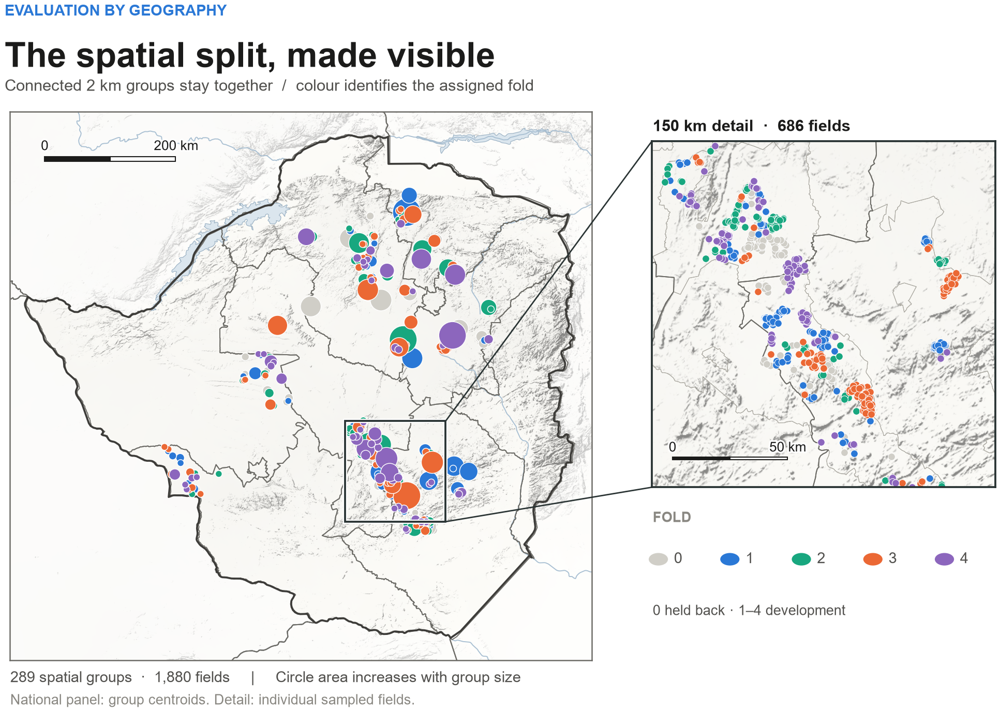

In [ ]:
# Fold 0 is held back; folds 1–4 form spatial development cross-validation.
map_fields = D[LACUNA]["fields"].assign(y=D[LACUNA]["y"]).copy()
map_fields["fold"] = map_fields["fold"].astype(str)
fold_colours = {"0": "#d0cec7", "1": "#2a78d6", "2": "#18a77f", "3": "#eb6834", "4": "#8c66bd"}
map_groups = (map_fields.groupby(["group_id", "fold"])
              .agg(lon=("lon", "mean"), lat=("lat", "mean"), n=("y", "size")).reset_index())
assert not map_groups.group_id.duplicated().any(), "A 2 km group must belong to exactly one fold"
fig = plt.figure(figsize=(FULL, 4.80))
fig.text(.04, .965, "EVALUATION BY GEOGRAPHY", color=BLUE, weight="bold", fontsize=7, va="top")
fig.text(.04, .915, "The spatial split, made visible", fontsize=16, weight="bold", va="top")
fig.text(.04, .865, "Connected 2 km groups stay together  /  colour identifies the assigned fold", fontsize=7.5, color=INK2, va="top")
zim_extent = (25.0, 33.3, -22.7, -15.3)
a = inch_axes(fig, .32, .86, 3.75, map_height(zim_extent, 3.75))
basemap(a, "zimbabwe", zim_extent, "light", focus=["ZWE"], admin2=False, ticks=False)
for fold, colour in fold_colours.items():
    g = map_groups[map_groups.fold == fold]
    a.scatter(g.lon, g.lat, s=7+2.8*g.n, color=colour, edgecolors="white", linewidths=.35, zorder=10, label=fold)
scalebar(a, 200, x=.06, y=.91)
ext = window(30.50, -20.15, 150)
b = inch_axes(fig, 4.45, 1.05, 2.23, 2.23)
basemap(b, "zimbabwe", ext, "light", focus=["ZWE"], admin2=True, ticks=False, relief_gain=.7)
near = map_fields[map_fields.lon.between(ext[0], ext[1]) & map_fields.lat.between(ext[2], ext[3])]
for fold, colour in fold_colours.items():
    f = near[near.fold == fold]
    b.scatter(f.lon, f.lat, s=11, color=colour, edgecolors="white", linewidths=.25, zorder=10)
scalebar(b, 50, x=.06, y=.08)
connect(fig, a, ext, b, "right", color="#293333", width=.65)
fig.text(.62, .795, f"150 km detail  ·  {len(near)} fields", fontsize=7.5, weight="bold")
fig.text(.62, .27, "FOLD", fontsize=6.5, color=MUTED, weight="bold")
for i, (fold, colour) in enumerate(fold_colours.items()):
    x = .625 + .064*i
    fig.add_artist(Circle((x, .22), .009, transform=fig.transFigure, facecolor=colour, edgecolor="white", linewidth=.4))
    fig.text(x+.014, .22, fold, fontsize=7, va="center", color=INK2)
fig.text(.62, .145, "0 held back · 1–4 development", fontsize=6.5, color=INK2)
fig.text(.045, .055, f"{len(map_groups):,} spatial groups  ·  {len(map_fields):,} fields     |     Circle area increases with group size", fontsize=7, color=INK2)
fig.text(.045, .025, "National panel: group centroids. Detail: individual sampled fields.", fontsize=6.4, color=MUTED)
save(fig, "D17_spatial_split_atlas")


### A09. One field, a season of light, one yield estimate

**What it shows.** Actual Sentinel-2 chips from the notebook's example field, its nine-month availability pattern, the two-block Presto encoder, and the P0/P1 yield heads. The barcode is the field's saved 128-value **P0 embedding**; it is not an attention map. P0 and P1 are alternative paths, not sequential heads. P1 fine-tunes its own encoder, so its representation is not the saved P0 embedding.

**Read it like this.** The surrounding 640 m imagery provides context; the model reads the white 10 m field pixel. Gold outlines help locate that pixel. Grey pixels failed the scene quality mask. Hollow monthly tiles indicate missing observations. Full-season inputs may include post-harvest observations, so these are yield estimates, not forecasts.

**Sources.** Data v2 `monthly` and Sentinel-2 chips; `experiments/presto_finetune/runs/zimbabwe_lacuna_2022_2023/p0_embeddings.npz`; `presto_lib.py` and the pinned Presto implementation. Original P0/P1 use real coordinates; no-location variants use constant coordinates. The diagram is 7.2 inches wide, with labels at least 6.9 pt, exported as PNG, PDF and editable SVG.

**Run it.** This cell contains the shared, scoped drawing functions for A09–A11; run it before the next two cells. It opens the database read-only and requires the local example-field imagery.

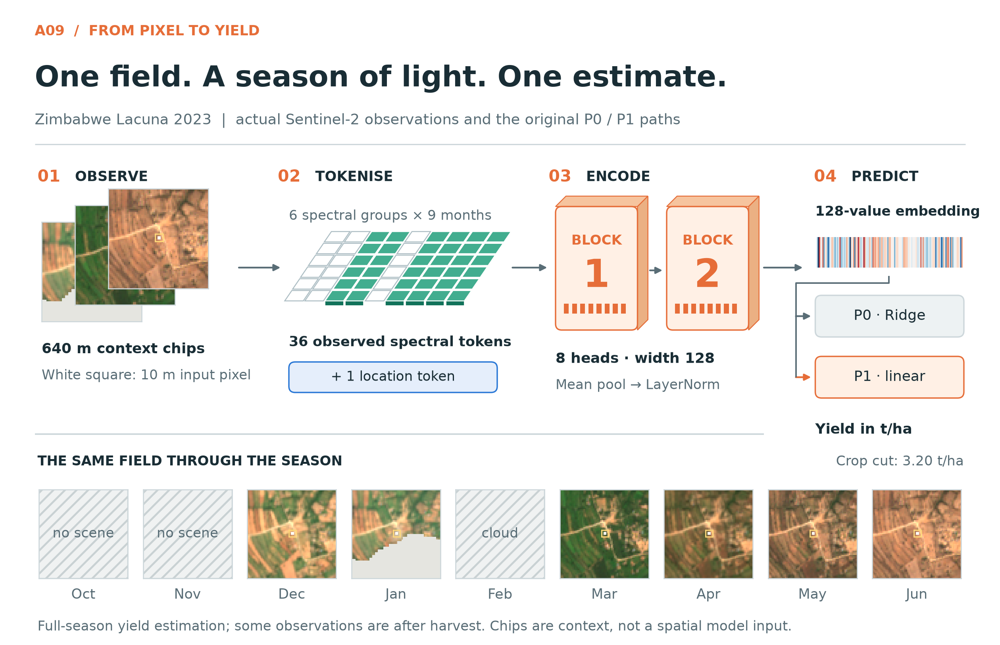

In [ ]:
"""Report-width, data-backed diagrams for the Lacuna Presto experiment."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon, FancyArrowPatch, FancyBboxPatch


def _midterm_inputs(repo):
    import duckdb
    import rasterio
    obs = 'zimbabwe:02455e59-78e3-4315-9c16-c2b635e2582d'
    cohort = 'zimbabwe_lacuna_2022_2023'
    with duckdb.connect(str(repo / 'data/v2/cropyield.duckdb'), read_only=True) as db:
        monthly = db.execute('SELECT * FROM monthly WHERE obs_id=? ORDER BY month', [obs]).df()
        folder = repo / db.execute('SELECT record_dir FROM downloads WHERE obs_id=?', [obs]).fetchone()[0]
    bands = ['b02','b03','b04','b05','b06','b07','b08','b8a','b11','b12']
    assert monthly.month.tolist() == ['2022-10','2022-11','2022-12','2023-01','2023-02','2023-03','2023-04','2023-05','2023-06']
    clear = monthly.coverage_state.eq('clear').to_numpy()
    assert np.array_equal(clear, [False,False,True,True,False,True,True,True,True])
    embedding_file = repo / 'experiments/presto_finetune/runs' / cohort / 'p0_embeddings.npz'
    with np.load(embedding_file, allow_pickle=True) as z:
        matches = np.flatnonzero(z['obs_id'].astype(str) == obs)
        assert len(matches) == 1
        embedding = z['P0'][matches[0]].copy()
    assert embedding.shape == (128,) and np.isfinite(embedding).all()
    # Windows extended paths also work for the longer Sentinel-2 scene names.
    longpath = lambda p: '\\\\?\\' + str(p.resolve()) if __import__('os').name == 'nt' else str(p)
    meta = json.loads(Path(longpath(folder / 'record.json')).read_text())
    with rasterio.open(longpath(folder / 'aoi_mask.tif')) as src:
        rr, cc = np.nonzero(src.read(1))
        nearest = np.argmin((rr-rr.mean())**2 + (cc-cc.mean())**2)
        pixel = int(rr[nearest]), int(cc[nearest])
    chips = {}
    for item in meta['accepted_item_ids']:
        date = item.split('_')[2][:8]
        month = date[:4] + '-' + date[4:6]
        with rasterio.open(longpath(folder / item / 'reflectance.tif')) as src:
            values = src.read().astype(float)
            values[values == src.nodata] = np.nan
        rgb = np.moveaxis(values[[2,1,0]], 0, -1)
        image = np.clip(rgb/.24, 0, 1)**.8
        image[~np.isfinite(rgb).all(axis=-1)] = (.9,.9,.88)
        chips[month] = image
    return dict(obs=obs, monthly=monthly, clear=clear, embedding=embedding,
                chips=chips, pixel=pixel, bands=bands,
                yield_value=float(monthly.yield_kg_ha.iloc[0])/1000)


def _midterm_architecture(repo, output_dir, number):
    """Render one figure with local style; geometry is in physical inches."""
    data = _midterm_inputs(Path(repo))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    C = dict(ink='#192d35', muted='#596d76', line='#cdd7db', light='#edf2f3',
             green='#199b77', palegreen='#dff1e9', orange='#e66d38', paleorange='#fff0e5',
             blue='#2a78d6', paleblue='#e5eefb')
    style = {'font.family':'DejaVu Sans', 'font.size':7.4, 'text.color':C['ink'],
             'pdf.fonttype':42,'svg.fonttype':'none','figure.facecolor':'white',
             'lines.solid_capstyle':'butt','savefig.facecolor':'white'}
    # Reset all drawing defaults locally so earlier notebook cells cannot affect exports.
    isolated_style = {k:v for k,v in mpl.rcParamsDefault.items() if k != 'backend'}
    isolated_style.update(style)
    with mpl.rc_context(isolated_style):
        h = {9:4.65, 10:4.9, 11:4.9}[number]
        fig = plt.figure(figsize=(7.2,h), dpi=160)
        ax = fig.add_axes([0,0,1,1]); ax.set(xlim=(0,7.2),ylim=(0,h)); ax.axis('off')

        def text(x,y,s,size=7.4,color=None,weight='normal',ha='left',va='center',**kw):
            return ax.text(x,y,s,fontsize=size,color=color or C['ink'],weight=weight,ha=ha,va=va,**kw)

        def line(points,color=None,lw=.8,ls='-'):
            ax.plot(*zip(*points),color=color or C['line'],lw=lw,ls=ls)

        def arrow(points,color=None,lw=.9,ls='-'):
            if len(points)>2: line(points[:-1],color,lw,ls)
            ax.add_patch(FancyArrowPatch(points[-2],points[-1],arrowstyle='-|>',mutation_scale=7,
                                        color=color or C['muted'],lw=lw,linestyle=ls,shrinkA=0,shrinkB=0))

        def box(x,y,w,hh,label='',fc='white',ec=None,size=7.4,weight='normal'):
            ax.add_patch(FancyBboxPatch((x,y),w,hh,boxstyle='round,pad=0,rounding_size=.045',
                                       facecolor=fc,edgecolor=ec or C['line'],lw=.7))
            if label: text(x+w/2,y+hh/2,label,size=size,weight=weight,ha='center')

        def header(kicker,title,subtitle):
            text(.25,h-.23,kicker,7.2,C['orange'],'bold')
            text(.25,h-.57,title,15.0,weight='bold')
            text(.25,h-.87,subtitle,7.6,C['muted'])
            line([(.25,h-1.04),(6.95,h-1.04)],lw=.65)

        def chip(x,y,w,month,label=True):
            a = fig.add_axes([x/7.2,y/h,w/7.2,w/h],zorder=3)
            if month in data['chips']:
                a.imshow(data['chips'][month],interpolation='nearest')
                r,c=data['pixel']
                a.add_patch(Rectangle((c-.5,r-.5),1,1,fill=False,edgecolor='white',lw=.8))
                a.add_patch(Rectangle((c-2.5,r-2.5),5,5,fill=False,edgecolor='#ffd87a',lw=.6))
            else:
                a.set(xlim=(0,1),ylim=(0,1),facecolor='#f0f2f2')
                a.add_patch(Rectangle((0,0),1,1,facecolor='#f0f2f2',edgecolor='#c9d1d3',hatch='////',lw=.5))
                state = data['monthly'].set_index('month').loc[month,'coverage_state']
                a.text(.5,.5,'cloud' if state=='cloudy' else 'no scene',size=6.9,ha='center',va='center',color=C['muted'])
            a.set_xticks([]);a.set_yticks([])
            for s in a.spines.values(): s.set_visible(True);s.set_linewidth(.55);s.set_edgecolor(C['line'])
            if label: text(x+w/2,y-.12,pd.Timestamp(month).strftime('%b'),7.2,C['muted'],ha='center')

        def iso_grid(x,y,cols=9,rows=6,cw=.12,dx=.055,dy=.07):
            # Six active channel groups, with exact example-field missing months.
            for row in range(rows-1,-1,-1):
                for col in range(cols):
                    xx=x+col*cw+row*dx; yy=y+row*dy
                    active=data['clear'][col]
                    face=mpl.colors.to_rgb(C['green']) if active else (1,1,1)
                    face=tuple(.18+v*.82 for v in face) if active else face
                    verts=[(xx,yy),(xx+cw*.92,yy),(xx+cw*.92+dx*.9,yy+dy*.88),(xx+dx*.9,yy+dy*.88)]
                    ax.add_patch(Polygon(verts,facecolor=face,edgecolor='white' if active else '#acbdc3',lw=.5,zorder=4+row*.01))
                    if row==0 and active:
                        ax.add_patch(Polygon([(xx,yy),(xx+cw*.92,yy),(xx+cw*.92,yy-.035),(xx,yy-.035)],
                                             facecolor='#11725a',edgecolor='white',lw=.35,zorder=3))

        def encoder(x,y,w=.61,hh=1.05,label='1',color=None):
            color=color or C['orange']; off=.075
            ax.add_patch(Polygon([(x,y+hh),(x+off,y+hh+off),(x+w+off,y+hh+off),(x+w,y+hh)],facecolor='#f6c49e',edgecolor=color,lw=.5))
            ax.add_patch(Polygon([(x+w,y),(x+w+off,y+off),(x+w+off,y+hh+off),(x+w,y+hh)],facecolor='#ebb083',edgecolor=color,lw=.5))
            box(x,y,w,hh,fc=C['paleorange'],ec=color)
            text(x+w/2,y+hh*.72,'BLOCK',6.9,color,'bold',ha='center')
            text(x+w/2,y+hh*.43,label,20,color,'bold',ha='center')
            for j in range(8):
                ax.add_patch(Rectangle((x+.06+j*(w-.12)/8,y+.12),(w-.12)/8*.6,.07,facecolor=color,edgecolor='none'))

        if number == 9:
            header('A09  /  FROM PIXEL TO YIELD','One field. A season of light. One estimate.',
                   'Zimbabwe Lacuna 2023  |  actual Sentinel-2 observations and the original P0 / P1 paths')
            for x,num,title in [(.27,'01','OBSERVE'),(2.0,'02','TOKENISE'),(3.95,'03','ENCODE'),(5.86,'04','PREDICT')]:
                text(x,3.37,num,8.4,C['orange'],'bold');text(x+.27,3.37,title,7.3,weight='bold')
            chip(.3,2.33,.72,'2023-01',False)
            chip(.54,2.45,.72,'2023-03',False)
            chip(.78,2.57,.72,'2023-06',False)
            text(.3,2.13,'640 m context chips',7.5,weight='bold')
            text(.3,1.94,'White square: 10 m input pixel',7.0,C['muted'])
            arrow([(1.72,2.72),(2.02,2.72)])
            iso_grid(2.05,2.48,cw=.145,dx=.057,dy=.085)
            text(2.08,3.09,'6 spectral groups × 9 months',7.0,C['muted'])
            text(2.08,2.18,'36 observed spectral tokens',7.2,weight='bold')
            box(2.08,1.82,1.5,.22,'+ 1 location token',fc=C['paleblue'],ec=C['blue'],size=7.1)
            arrow([(3.69,2.72),(3.94,2.72)])
            encoder(4.0,2.27,.59,.89,'1'); encoder(4.8,2.27,.59,.89,'2')
            arrow([(4.68,2.7),(4.77,2.7)])
            text(4.0,2.06,'8 heads · width 128',7.4,weight='bold')
            text(4.0,1.87,'Mean pool → LayerNorm',7.0,C['muted'])
            arrow([(5.5,2.72),(5.78,2.72)])
            bar=fig.add_axes([5.88/7.2,2.72/h,1.05/7.2,.22/h])
            bar.imshow(data['embedding'][None,:],cmap='RdBu_r',vmin=-3,vmax=3,aspect='auto');bar.axis('off')
            text(5.87,3.12,'128-value embedding',7.1,weight='bold')
            box(5.87,2.22,1.07,.3,'P0 · Ridge',fc=C['light'],size=7.4)
            box(5.87,1.78,1.07,.3,'P1 · linear',fc=C['paleorange'],ec=C['orange'],size=7.4)
            line([(6.4,2.66),(6.4,2.61),(5.73,2.61),(5.73,1.93)],C['muted'])
            arrow([(5.73,2.37),(5.84,2.37)])
            arrow([(5.73,1.93),(5.84,1.93)],color=C['orange'])
            text(5.87,1.55,'Yield in t/ha',7.4,weight='bold')
            line([(.25,1.52),(5.5,1.52)])
            text(.27,1.32,'THE SAME FIELD THROUGH THE SEASON',7.1,weight='bold')
            text(6.94,1.32,f"Crop cut: {data['yield_value']:.2f} t/ha",7.1,C['muted'],ha='right')
            for j,m in enumerate(data['monthly'].month): chip(.28+j*.75,.48,.64,m)
            text(.27,.13,'Full-season yield estimation; some observations are after harvest. Chips are context, not a spatial model input.',7.0,C['muted'])
            stem='A09_field_to_presto'

        elif number == 10:
            header('A10  /  THE MODEL INPUT CONTRACT','What enters the transformer?',
                   'Exact availability for the example field  |  colour denotes presence, not reflectance or attention')
            rows=[('Radar','VV, VH',False),('Weather','ERA5',False),('Land cover','class',False),
                  ('Visible','B2, B3, B4',True),('Red edge','B5, B6, B7',True),('NIR 10 m','B8',True),
                  ('NIR 20 m','B8A',True),('SWIR','B11, B12',True),('NDVI','B8, B4',True)]
            x0,cw,ystep=1.91,.30,.205
            for j,m in enumerate(data['monthly'].month):text(x0+(j+.5)*cw,3.61,pd.Timestamp(m).strftime('%b'),7.0,C['muted'],ha='center')
            for i,(name,detail,available) in enumerate(rows):
                y=3.35-i*ystep
                text(.27,y+.064,name,7.2,weight='bold' if available else 'normal')
                text(1.79,y+.064,detail,6.9,C['muted'],ha='right')
                for j in range(9):
                    have=available and data['clear'][j]
                    ax.add_patch(Rectangle((x0+j*cw,y),cw-.045,.13,
                        facecolor=C['green'] if have else 'white',edgecolor='white' if have else '#b4c0c5',lw=.6))
            line([(.27,1.56),(4.61,1.56)])
            text(.27,1.42,'Terrain',7.2);text(1.79,1.42,'elev., slope',6.9,C['muted'],ha='right')
            ax.add_patch(Rectangle((x0,1.35),.25,.13,facecolor='white',edgecolor='#b4c0c5',lw=.6))
            text(2.27,1.42,'One masked static token',7.0,C['muted'])
            text(.27,1.21,'Location',7.2,weight='bold');text(1.79,1.21,'lat., lon.',6.9,C['blue'],ha='right')
            ax.add_patch(Rectangle((x0,1.14),.25,.13,facecolor=C['blue'],edgecolor='white',lw=.6))
            text(2.27,1.21,'One retained static token',7.0,C['blue'])
            line([(4.84,1.14),(4.84,3.71)])
            text(5.05,3.35,'37',31,C['orange'],'bold');text(5.94,3.33,'of 83 tokens',8.0,weight='bold')
            text(5.05,2.97,'6 groups × 6 clear months',7.6)
            text(5.05,2.75,'+ 1 location token',7.6,C['blue'])
            text(5.05,2.37,'Unavailable inputs',7.6,weight='bold')
            text(5.05,2.08,'Radar, weather, land cover,\nterrain and missing months',7.3,C['muted'],linespacing=1.5)
            text(5.05,1.65,'No-location controls',7.6,weight='bold')
            text(5.05,1.34,'Use (0, 0); the location\ntoken is still present.',7.3,C['muted'],linespacing=1.5)
            line([(.27,.98),(6.94,.98)])
            box(.27,.38,1.62,.36,'Project values to 128',fc=C['palegreen'],ec=C['green'])
            arrow([(1.91,.56),(2.14,.56)])
            box(2.17,.38,1.75,.36,'+ month / group / position',fc=C['light'],size=7.0)
            arrow([(3.95,.56),(4.18,.56)])
            box(4.21,.38,1.3,.36,'Keep valid tokens',fc=C['light'])
            arrow([(5.54,.56),(5.77,.56)])
            box(5.8,.38,1.14,.36,'2 blocks → z',fc=C['paleorange'],ec=C['orange'])
            text(.27,.14,'Metadata widths: 32 + 32 + 64. Location is projected separately. Decoder is not used for yield estimation.',7.0,C['muted'])
            stem='A10_presto_tokens'

        else:
            header('A11  /  LEARNING AND CONTROL','What does pretraining actually change?',
                   'Same seasonal observations  |  each comparison changes the representation or how it is trained')
            # Column headers and four model lanes; no invented accuracy claims.
            for x,label in [(.27,'ARM'),(1.32,'REPRESENTATION'),(4.28,'YIELD HEAD'),(6.02,'LABEL UPDATES')]:text(x,3.59,label,7.0,C['muted'],'bold')
            lanes=[('P0',3.00,'Pretrained encoder','frozen',C['green'],'Ridge','Head only'),
                   ('P1',2.36,'Pretrained encoder','fine-tuned',C['orange'],'Linear','Encoder + head'),
                   ('P2',1.72,'Random encoder','trained from scratch','#7b8293','Linear','Encoder + head'),
                   ('X1†',1.08,'Raw monthly numbers','99 values + missing flags',C['blue'],'Ridge','Head only')]
            for label,y,rep,detail,color,head,update in lanes:
                text(.27,y+.22,label,13,color,'bold')
                arrow([(.88,y+.23),(1.23,y+.23)])
                box(1.31,y,2.49,.48,fc='white',ec=color)
                ax.add_patch(Rectangle((1.31,y),.055,.48,facecolor=color,edgecolor='none'))
                text(1.47,y+.31,rep,8.0,weight='bold');text(1.47,y+.13,detail,7.1,C['muted'])
                arrow([(3.83,y+.23),(4.16,y+.23)])
                box(4.25,y,.99,.48,head,fc=C['light'],size=8.0)
                arrow([(5.28,y+.23),(5.66,y+.23)])
                text(5.73,y+.24,'ŷ',12,weight='bold')
                text(6.04,y+.24,update,7.0,color)
            line([(.27,.86),(6.94,.86)])
            text(.27,.64,'SPATIAL EVALUATION',7.3,weight='bold')
            for j in range(5):
                fc='#e1e4e5' if j==0 else C['paleblue']
                box(1.91+j*.29,.52,.235,.235,str(j),fc=fc,size=7.0)
            text(3.51,.64,'0 held back; 1–4 development folds',7.3)
            text(.27,.39,'P1 / P2: five grouped inner models per selected learning rate; their predictions are averaged.',7.0,C['muted'])
            text(.27,.16,'† X1 is post hoc. Original P0 / P1 / P2 use location; the no-location variants supply constant coordinates.',7.0,C['muted'])
            stem='A11_presto_learning_paths'

        ax.set(xlim=(0,7.2),ylim=(0,h),aspect='auto')
        # All display text is at least 6.9 pt at the final 7.2-inch report width.
        for ext in ('png','pdf','svg'):
            fig.savefig(output_dir / f'{stem}.{ext}',dpi=350)
        plt.close(fig)
    return output_dir / f'{stem}.png'



from IPython.display import Image as _mtImage, display as _mtDisplay
_mt_path = _midterm_architecture(REPO, FIG, 9)
_mtDisplay(_mtImage(filename=str(_mt_path)))
del _mtImage, _mtDisplay, _mt_path


### A10. What enters the transformer?

**What it shows.** The example field's actual missing-data pattern, read from data v2, with six observed channel groups per clear month. The total is 37 retained tokens from 83 possible tokens: 36 spectral tokens plus one location token. Hollow cells are absent data, not zero reflectance. The six clear months and the 128-value embedding shape are checked when the figure runs.

**Architecture.** Each channel group is linearly projected to width 128. Month, group and position codes (32 + 32 + 64) are added before masking. Location is separately projected and appended after the masked input tokens are removed. Two transformer blocks feed mean pooling and LayerNorm. The decoder is not used for yield estimation. No-location controls feed (0, 0) to the still-present location token.

**Sources.** Data v2 `monthly`; `presto_lib.py`; `_parked/src/cropyield/models/presto_single_file.py`. Group rows are arranged for readability rather than internal token order. Run A09 first. Exports: PNG, PDF, SVG at report width.

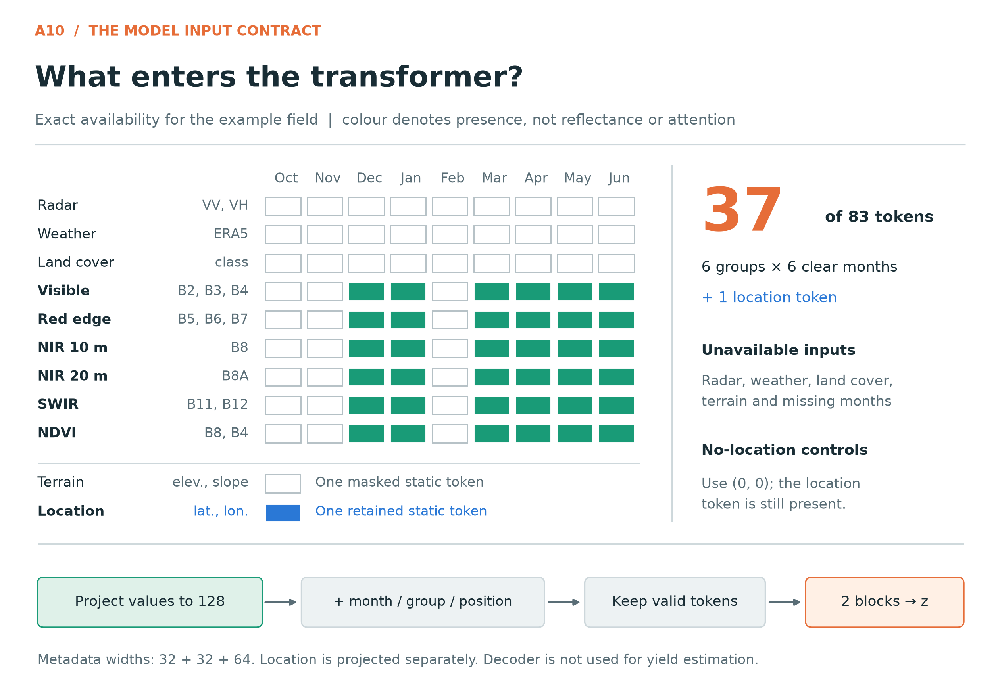

In [ ]:
from IPython.display import Image as _mtImage, display as _mtDisplay
_mt_path = _midterm_architecture(REPO, FIG, 10)
_mtDisplay(_mtImage(filename=str(_mt_path)))
del _mtImage, _mtDisplay, _mt_path


### A11. Learning paths and controls

**What it shows.** P0 freezes the pretrained encoder and fits Ridge; P1 fine-tunes the encoder and a linear head; P2 trains the same network from random initialization; post-hoc X1 gives 99 monthly band/NDVI values and missingness flags to Ridge. X1 fills missing values using training-set means. The diagram makes no claim that Presto beats the raw-input control.

**Evaluation.** Development uses spatial group folds 1–4, with fold 0 excluded from training. For P1/P2, the selected learning rate's five grouped inner models are averaged for each outer test fold. Fold 0 also has a separately logged look in the existing experiments; it is not represented as a new blind test. Original P0/P1/P2 use coordinates; the no-location arms use constant coordinates.

**Sources.** `experiments/presto_finetune/README.md`, `PLAN.md`, `presto_lib.py`, and `posthoc_controls.py`. Run A09 first. Exports: PNG, PDF, SVG at report width.

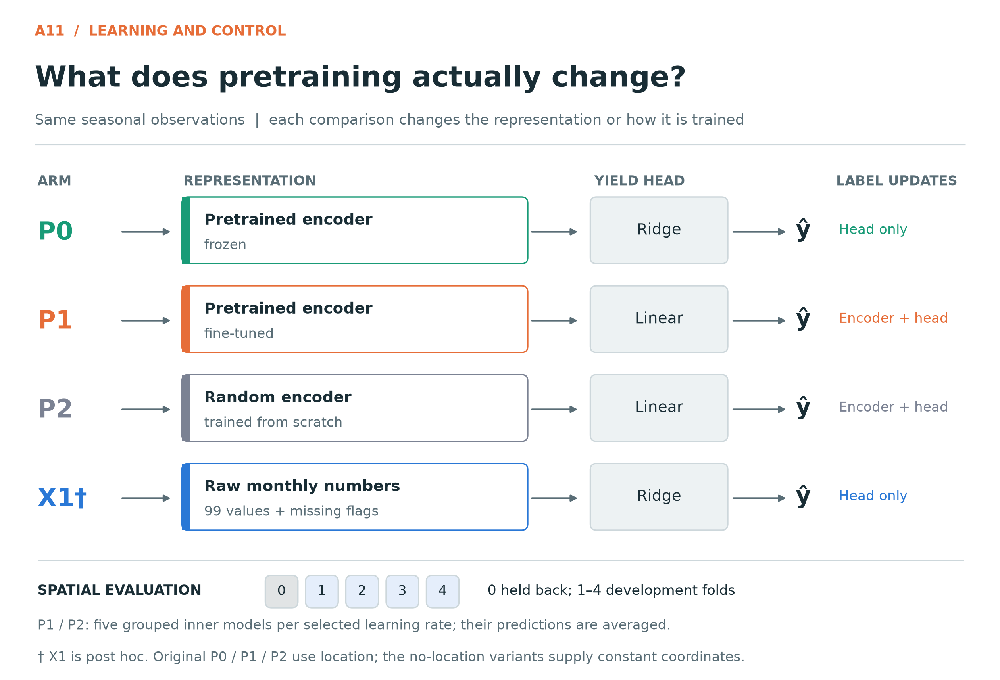

In [ ]:
from IPython.display import Image as _mtImage, display as _mtDisplay
_mt_path = _midterm_architecture(REPO, FIG, 11)
_mtDisplay(_mtImage(filename=str(_mt_path)))
del _mtImage, _mtDisplay, _mt_path
